<a href="https://colab.research.google.com/github/farahdinaariff/Data-Science-Project/blob/main/TropicalPV_Probabilistic_Solar_Forecasting_v11_VIVA_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **VIVA_Start**

### **Probabilistic Solar Power Forecasting Under Tropical Climate Uncertainty**
A Comparative Study of Deterministic vs Uncertainty-Quantifying Deep Learning Architectures on Tropical and Equatorial Datasets

**Farah Dina Bte Esa Mahmud Ariff**
* MSc Data Science
* University of Hertfordshire (PSB Academy)


---

**The talk in five moves (10 minutes)**

| | Move | What the panel should take away | Time |
|---|---|---|---|
| **1** | **** | A forecast is only useful if its "80% sure" is honest. One forecaster's was not. | 1:00 |
| **2** | **Problem** | Operators size reserve from one number, and tropical cloud makes that number fragile. | 1:15 |
| **3** | **Insight** | Accuracy and reliability are two separate questions. Earlier tropical work only asked the first. | 1:00 |
| **4** | **Solution** | How the notebook is built, how the models were tested fairly, and the three results. | 5:00 |
| **5** | **Conclusion** | What the evidence supports, what it does not, and why it matters. | 1:30 |

Backup material for questions sits at the end of this section.

<details>
<summary><b>How to run and read this section</b> (click to open)</summary>

**Presenting from the saved notebook.** Every figure and table here is already saved, so nothing needs to be run.

**After a fresh run.** Run the original research notebook first, in its original order (FULL mode needs a GPU runtime). Then come back and run the VIVA cells from top to bottom. They take a few seconds and train nothing.

**The label under every figure and table**

| Label | Meaning |
|---|---|
| **STATIC** | Text or values copied from the executed notebook or the report, with the stage or section named. Does not depend on any variable. |
| **SNAPSHOT** | A verified copy of a result table printed by the original run (FULL mode, 4 test periods × 5 seeds). Shown when the original cells have not been run in this session. |
| **LIVE** | The same table read from this session's variables (`R_LEADER`, `R_DM`, `SUBGROUP_R`, `ABLATION`, `HORIZON_R`, `RANK_STAB`, `INV_CMP3`, `INV_SUMMARY`) after the original notebook has been run. |

Run all reaches these cells before the results exist. That is safe: they show the snapshot, define only names beginning with `VIVA` or `_viva`, and leave `CFG`, the random seeds and all original variables untouched.

**Presenter cues** are folded away in grey boxes like this one. They stay closed on screen and can be opened when rehearsing.

</details>

In [ ]:
# @title VIVA Setup: Run This Cell First (It trains nothing and takes about a second.) {"display-mode":"form"}
# ------------------------------------------------------------------------------------------------
# ADDED FOR THE VIVA. This cell does not change anything in the original notebook.
#   * The VIVA cells only define names that start with `VIVA` or `_viva`. The original code uses none.
#   * It does not touch CFG, random seeds, global matplotlib settings, pandas options, files or the Drive.
#   * Every number is a copy of an executed output of the original notebook (the stage is named beside
#     each one). If the original cells have been run in this session, the result tables are read
#     from the live variables instead, and each table says so.
# ------------------------------------------------------------------------------------------------
def _viva_build(_g):
    import io, types
    import numpy as np
    import pandas as pd
    from IPython.display import display, HTML

    V = types.SimpleNamespace()
    V.np, V.pd, V.display, V.HTML = np, pd, display, HTML

    # ---- verified snapshot of the result tables printed by the original run --------------------
    V.SNAP_CSV = {
        'R_LEADER': (
            'model,family,RMSE_Wm2,CRPS_Wm2,skill_RMSE_%,skill_CI_lo,skill_CI_hi,skill_CRPS_%,skillCRPS_CI_lo,skillCRPS_CI_hi,RMSE_sd_between_seeds,RMSE_sd_between_folds,PICP80_raw,PICP80_conformal,PICP90_raw,MIW_raw_Wm2,MIW_conf_Wm2,Winkler_raw,Winkler_conf\n'
            'QR-GRU,probabilistic,87.237,35.606,12.077,10.618,13.583,42.686,41.557,43.799,1.200,26.066,0.805,0.813,0.911,175.421,178.842,251.900,253.160\n'
            'GRU,deterministic,88.015,56.690,11.294,9.276,13.152,8.748,6.443,10.955,1.682,25.277,,,,,,,\n'
            'LSTM,deterministic,88.325,57.715,10.981,8.966,12.967,7.098,4.613,9.529,1.256,24.954,,,,,,,\n'
            'MC-Dropout LSTM,probabilistic,91.035,46.597,8.250,5.590,10.812,24.995,22.615,27.241,2.082,23.823,0.621,0.806,0.697,136.454,252.450,340.990,344.905\n'
            'HMC-LSTM,probabilistic (extension),94.972,46.371,4.282,1.040,7.445,25.359,22.959,27.552,3.347,25.567,0.905,0.805,0.956,269.582,206.937,310.392,289.478\n'
            'Persistence,naive,99.221,62.125,0.000,0.000,0.000,0.000,0.000,0.000,,25.062,,,,,,,\n'
            'Climatology,naive,130.051,77.838,-31.073,-42.929,-19.764,-25.292,-34.556,-16.185,,38.834,,,,,,,\n'
            'Seasonal-naive,naive,148.664,88.395,-49.832,-59.183,-40.004,-42.286,-50.175,-33.676,,47.953,,,,,,,\n'
        ),
        'R_DM': (
            'model_A,model_B,loss,DM_stat,p,NW_lag,lower_loss,p_holm,significant_holm_5%\n'
            'LSTM,GRU,SE,1.1230,0.2615,9,GRU,0.2674,False\n'
            'LSTM,GRU,CRPS,5.2042,0.0000,9,GRU,0.0000,True\n'
            'LSTM,MC-Dropout LSTM,SE,-3.4283,0.0006,9,LSTM,0.0031,True\n'
            'LSTM,MC-Dropout LSTM,CRPS,22.1881,0.0000,9,MC-Dropout LSTM,0.0000,True\n'
            'LSTM,QR-GRU,SE,1.9238,0.0544,9,QR-GRU,0.1633,False\n'
            'LSTM,QR-GRU,CRPS,40.5561,0.0000,9,QR-GRU,0.0000,True\n'
            'LSTM,HMC-LSTM,SE,-6.8325,0.0000,9,LSTM,0.0000,True\n'
            'LSTM,HMC-LSTM,CRPS,18.1103,0.0000,9,HMC-LSTM,0.0000,True\n'
            'LSTM,Persistence,SE,-9.5091,0.0000,9,LSTM,0.0000,True\n'
            'LSTM,Persistence,CRPS,-5.6212,0.0000,9,LSTM,0.0000,True\n'
            'GRU,MC-Dropout LSTM,SE,-4.1081,0.0000,9,GRU,0.0002,True\n'
            'GRU,MC-Dropout LSTM,CRPS,20.3835,0.0000,9,MC-Dropout LSTM,0.0000,True\n'
            'GRU,QR-GRU,SE,1.5000,0.1337,9,QR-GRU,0.2674,False\n'
            'GRU,QR-GRU,CRPS,39.6756,0.0000,9,QR-GRU,0.0000,True\n'
            'GRU,HMC-LSTM,SE,-7.4539,0.0000,9,GRU,0.0000,True\n'
            'GRU,HMC-LSTM,CRPS,16.2420,0.0000,9,HMC-LSTM,0.0000,True\n'
            'GRU,Persistence,SE,-10.1274,0.0000,9,GRU,0.0000,True\n'
            'GRU,Persistence,CRPS,-7.4093,0.0000,9,GRU,0.0000,True\n'
            'MC-Dropout LSTM,QR-GRU,SE,4.4738,0.0000,9,QR-GRU,0.0001,True\n'
            'MC-Dropout LSTM,QR-GRU,CRPS,26.7055,0.0000,9,QR-GRU,0.0000,True\n'
            'MC-Dropout LSTM,HMC-LSTM,SE,-9.6300,0.0000,9,MC-Dropout LSTM,0.0000,True\n'
            'MC-Dropout LSTM,HMC-LSTM,CRPS,0.7720,0.4401,9,HMC-LSTM,0.4401,False\n'
            'MC-Dropout LSTM,Persistence,SE,-5.9571,0.0000,9,MC-Dropout LSTM,0.0000,True\n'
            'MC-Dropout LSTM,Persistence,CRPS,-16.8266,0.0000,9,MC-Dropout LSTM,0.0000,True\n'
            'QR-GRU,HMC-LSTM,SE,-7.0784,0.0000,9,QR-GRU,0.0000,True\n'
            'QR-GRU,HMC-LSTM,CRPS,-29.1757,0.0000,9,QR-GRU,0.0000,True\n'
            'QR-GRU,Persistence,SE,-14.2900,0.0000,9,QR-GRU,0.0000,True\n'
            'QR-GRU,Persistence,CRPS,-34.8002,0.0000,9,QR-GRU,0.0000,True\n'
            'HMC-LSTM,Persistence,SE,-2.6782,0.0074,9,HMC-LSTM,0.0297,True\n'
            'HMC-LSTM,Persistence,CRPS,-15.4598,0.0000,9,HMC-LSTM,0.0000,True\n'
        ),
        'RANK_STAB': (
            'model,mean_rank,share_first\n'
            'QR-GRU,1.6,65.0\n'
            'GRU,2.2,25.0\n'
            'LSTM,2.8,5.0\n'
            'MC-Dropout LSTM,3.4,5.0\n'
        ),
        'ABLATION': (
            'model,loss,contrast,subset,n_hours,improvement_%,CI_lo,CI_hi,DM_p,verdict\n'
            'LSTM,SE,all seasonal information (C vs A),all,4887,-1.339,-2.664,-0.022,0.033,hurts\n'
            'LSTM,SE,binary is_wet flag (C vs B),all,4887,-0.094,-0.552,0.345,0.661,not distinguishable\n'
            'LSTM,SE,calendar encoding (B vs A),all,4887,-1.244,-2.445,-0.098,0.032,hurts\n'
            'LSTM,CRPS,all seasonal information (C vs A),all,4887,-2.350,-3.768,-0.912,0.000,hurts\n'
            'LSTM,CRPS,binary is_wet flag (C vs B),all,4887,-0.683,-1.339,-0.042,0.019,hurts\n'
            'LSTM,CRPS,calendar encoding (B vs A),all,4887,-1.655,-2.822,-0.523,0.005,hurts\n'
            'GRU,SE,all seasonal information (C vs A),all,4887,-0.212,-1.361,0.963,0.710,not distinguishable\n'
            'GRU,SE,binary is_wet flag (C vs B),all,4887,0.438,-0.078,0.957,0.086,not distinguishable\n'
            'GRU,SE,calendar encoding (B vs A),all,4887,-0.653,-1.689,0.451,0.215,not distinguishable\n'
            'GRU,CRPS,all seasonal information (C vs A),all,4887,-1.322,-2.564,-0.111,0.027,hurts\n'
            'GRU,CRPS,binary is_wet flag (C vs B),all,4887,-0.083,-0.749,0.625,0.798,not distinguishable\n'
            'GRU,CRPS,calendar encoding (B vs A),all,4887,-1.238,-2.323,-0.176,0.018,hurts\n'
            'MC-Dropout LSTM,SE,all seasonal information (C vs A),all,4887,0.570,-0.399,1.503,0.223,not distinguishable\n'
            'MC-Dropout LSTM,SE,binary is_wet flag (C vs B),all,4887,1.703,1.094,2.323,0.000,helps\n'
            'MC-Dropout LSTM,SE,calendar encoding (B vs A),all,4887,-1.153,-2.194,-0.113,0.024,hurts\n'
            'MC-Dropout LSTM,CRPS,all seasonal information (C vs A),all,4887,1.622,0.640,2.551,0.001,helps\n'
            'MC-Dropout LSTM,CRPS,binary is_wet flag (C vs B),all,4887,2.299,1.701,2.906,0.000,helps\n'
            'MC-Dropout LSTM,CRPS,calendar encoding (B vs A),all,4887,-0.693,-1.727,0.310,0.156,not distinguishable\n'
            'QR-GRU,SE,all seasonal information (C vs A),all,4887,0.235,-0.544,0.977,0.526,not distinguishable\n'
            'QR-GRU,SE,binary is_wet flag (C vs B),all,4887,0.227,-0.076,0.527,0.186,not distinguishable\n'
            'QR-GRU,SE,calendar encoding (B vs A),all,4887,0.008,-0.734,0.754,0.982,not distinguishable\n'
            'QR-GRU,CRPS,all seasonal information (C vs A),all,4887,0.438,-0.162,1.008,0.139,not distinguishable\n'
            'QR-GRU,CRPS,binary is_wet flag (C vs B),all,4887,-0.226,-0.495,0.054,0.118,not distinguishable\n'
            'QR-GRU,CRPS,calendar encoding (B vs A),all,4887,0.663,0.082,1.198,0.026,helps\n'
            'LSTM,SE,all seasonal information (C vs A),wet season,1290,-1.207,-2.863,0.412,0.132,not distinguishable\n'
            'LSTM,SE,all seasonal information (C vs A),dry season,3597,-1.463,-3.646,0.483,0.122,not distinguishable\n'
            'LSTM,SE,binary is_wet flag (C vs B),wet season,1290,-0.397,-0.892,0.080,0.123,not distinguishable\n'
            'LSTM,SE,binary is_wet flag (C vs B),dry season,3597,0.186,-0.534,0.883,0.577,not distinguishable\n'
            'LSTM,SE,calendar encoding (B vs A),wet season,1290,-0.807,-2.431,0.763,0.316,not distinguishable\n'
            'LSTM,SE,calendar encoding (B vs A),dry season,3597,-1.652,-3.482,0.084,0.046,not distinguishable\n'
            'GRU,SE,all seasonal information (C vs A),wet season,1290,-0.157,-1.597,1.194,0.845,not distinguishable\n'
            'GRU,SE,all seasonal information (C vs A),dry season,3597,-0.264,-2.007,1.390,0.742,not distinguishable\n'
            'GRU,SE,binary is_wet flag (C vs B),wet season,1290,0.393,-0.402,1.153,0.336,not distinguishable\n'
            'GRU,SE,binary is_wet flag (C vs B),dry season,3597,0.480,-0.119,1.087,0.116,not distinguishable\n'
            'GRU,SE,calendar encoding (B vs A),wet season,1290,-0.552,-1.735,0.666,0.424,not distinguishable\n'
            'GRU,SE,calendar encoding (B vs A),dry season,3597,-0.747,-2.476,0.935,0.339,not distinguishable\n'
            'MC-Dropout LSTM,SE,all seasonal information (C vs A),wet season,1290,-0.066,-1.297,1.231,0.916,not distinguishable\n'
            'MC-Dropout LSTM,SE,all seasonal information (C vs A),dry season,3597,1.144,-0.260,2.448,0.091,not distinguishable\n'
            'MC-Dropout LSTM,SE,binary is_wet flag (C vs B),wet season,1290,1.842,0.829,2.891,0.002,helps\n'
            'MC-Dropout LSTM,SE,binary is_wet flag (C vs B),dry season,3597,1.574,0.923,2.192,0.000,helps\n'
            'MC-Dropout LSTM,SE,calendar encoding (B vs A),wet season,1290,-1.944,-3.599,-0.466,0.012,hurts\n'
            'MC-Dropout LSTM,SE,calendar encoding (B vs A),dry season,3597,-0.437,-1.748,0.756,0.494,not distinguishable\n'
            'QR-GRU,SE,all seasonal information (C vs A),wet season,1290,0.770,-0.169,1.709,0.119,not distinguishable\n'
            'QR-GRU,SE,all seasonal information (C vs A),dry season,3597,-0.274,-1.380,0.795,0.617,not distinguishable\n'
            'QR-GRU,SE,binary is_wet flag (C vs B),wet season,1290,0.208,-0.228,0.641,0.436,not distinguishable\n'
            'QR-GRU,SE,binary is_wet flag (C vs B),dry season,3597,0.245,-0.186,0.666,0.271,not distinguishable\n'
            'QR-GRU,SE,calendar encoding (B vs A),wet season,1290,0.563,-0.389,1.590,0.297,not distinguishable\n'
            'QR-GRU,SE,calendar encoding (B vs A),dry season,3597,-0.520,-1.670,0.538,0.324,not distinguishable\n'
        ),
        'HORIZON_R': (
            'horizon_h,model,RMSE_Wm2,best_naive,skill_vs_persistence_%,skill_vs_best_naive_%,vs_persistence_CI_lo,vs_persistence_CI_hi,vs_best_naive_CI_lo,vs_best_naive_CI_hi\n'
            '1,Climatology,130.05,Persistence,-31.07,-31.07,,,,\n'
            '1,GRU,87.35,Persistence,11.96,11.96,10.17,13.76,10.17,13.76\n'
            '1,MC-Dropout LSTM,91.24,Persistence,8.04,8.04,5.25,10.77,5.25,10.77\n'
            '1,Persistence,99.22,Persistence,0.00,0.00,,,,\n'
            '1,QR-GRU,87.64,Persistence,11.67,11.67,10.12,13.30,10.12,13.30\n'
            '1,Seasonal-naive,148.66,Persistence,-49.83,-49.83,,,,\n'
            '2,Climatology,130.08,Climatology,15.93,0.00,,,,\n'
            '2,GRU,105.60,Climatology,31.74,18.81,29.32,33.99,13.04,23.91\n'
            '2,MC-Dropout LSTM,108.31,Climatology,29.99,16.73,26.99,32.72,12.28,21.08\n'
            '2,Persistence,154.72,Climatology,0.00,-18.94,,,,\n'
            '2,QR-GRU,105.67,Climatology,31.70,18.76,29.29,34.16,13.75,23.31\n'
            '2,Seasonal-naive,148.66,Climatology,3.92,-14.28,,,,\n'
            '3,Climatology,130.02,Climatology,42.16,0.00,,,,\n'
            '3,GRU,113.33,Climatology,49.59,12.84,46.59,52.37,8.19,16.88\n'
            '3,MC-Dropout LSTM,114.60,Climatology,49.03,11.86,45.60,52.16,7.57,15.93\n'
            '3,Persistence,224.81,Climatology,0.00,-72.90,,,,\n'
            '3,QR-GRU,114.92,Climatology,48.88,11.61,45.44,52.37,7.42,15.60\n'
            '3,Seasonal-naive,148.66,Climatology,33.87,-14.34,,,,\n'
            '6,Climatology,130.07,Climatology,71.46,0.00,,,,\n'
            '6,GRU,118.78,Climatology,73.94,8.68,72.16,75.63,3.91,12.63\n'
            '6,MC-Dropout LSTM,119.33,Climatology,73.82,8.25,71.97,75.44,3.67,11.97\n'
            '6,Persistence,455.73,Climatology,0.00,-250.38,,,,\n'
            '6,QR-GRU,119.80,Climatology,73.71,7.89,71.49,75.78,3.90,11.55\n'
            '6,Seasonal-naive,148.71,Climatology,67.37,-14.33,,,,\n'
        ),
        'SUBGROUP_R': (
            'model,subgroup,n_hour_runs,RMSE_Wm2,PICP80_raw,PICP_CI_lo,PICP_CI_hi,PICP80_conformal\n'
            'LSTM,wet season,6450,118.989,,,,\n'
            'LSTM,dry season,17985,74.307,,,,\n'
            'LSTM,ramp hours,1450,188.640,,,,\n'
            'LSTM,non-ramp,22985,77.773,,,,\n'
            'GRU,wet season,6450,119.279,,,,\n'
            'GRU,dry season,17985,73.637,,,,\n'
            'GRU,ramp hours,1450,191.254,,,,\n'
            'GRU,non-ramp,22985,76.992,,,,\n'
            'MC-Dropout LSTM,wet season,6450,122.848,0.446,0.431,0.462,0.682\n'
            'MC-Dropout LSTM,dry season,17985,76.467,0.684,0.675,0.695,0.850\n'
            'MC-Dropout LSTM,ramp hours,1450,181.167,0.243,0.208,0.280,0.525\n'
            'MC-Dropout LSTM,non-ramp,22985,82.096,0.645,0.635,0.657,0.823\n'
            'QR-GRU,wet season,6450,118.494,0.795,0.784,0.806,0.792\n'
            'QR-GRU,dry season,17985,72.830,0.808,0.802,0.815,0.821\n'
            'QR-GRU,ramp hours,1450,202.315,0.459,0.423,0.496,0.469\n'
            'QR-GRU,non-ramp,22985,74.218,0.827,0.821,0.833,0.835\n'
            'HMC-LSTM,wet season,6450,127.934,0.868,0.859,0.875,0.710\n'
            'HMC-LSTM,dry season,17985,79.904,0.918,0.914,0.923,0.839\n'
            'HMC-LSTM,ramp hours,1450,175.368,0.663,0.638,0.687,0.548\n'
            'HMC-LSTM,non-ramp,22985,87.456,0.920,0.916,0.924,0.822\n'
        ),
    }
    V.WHERE = {
        "R_LEADER":    "Stage 14, R2 leaderboard",
        "R_DM":        "Stage 14, R2 pairwise Diebold-Mariano table",
        "RANK_STAB":   "Stage 14, R2 rank stability",
        "ABLATION":    "Stage 14, R3 seasonal-conditioning arms",
        "HORIZON_R":   "Stage 14, R4 horizon sweep",
        "SUBGROUP_R":  "Stage 14, R5(b,c) subgroups",
        "INV_CMP3":    "Stage 5.5, before/after table of the three timestamp readings",
        "INV_SUMMARY": "Stage 5.5, controlled model experiment",
    }

    def _snap(name):
        if name == "INV_CMP3":
            return pd.DataFrame(
                {"initial":   [717.0, 734.0, 4544.0, 0.920, 0.774, 0.146],
                 "partial":   [457.0, 535.0, 4582.0, 1.071, 0.844, 0.227],
                 "corrected": [80.0, 202.0, 4682.0, 0.973, 0.985, -0.011]},
                index=["non-physical removed (h)", "k_t interpolated (h)", "valid daylight k_t (h)",
                       "clear-day k_t morning (8-11h)", "clear-day k_t afternoon (13-16h)",
                       "morning − afternoon"])
        if name == "INV_SUMMARY":
            idx = pd.MultiIndex.from_product([["corrected", "initial", "partial"],
                                              ["Climatology", "GRU", "Persistence", "QR-GRU"]],
                                             names=["version", "model"])
            return pd.DataFrame(
                {"RMSE":  [215.946, 143.729, 95.736, 130.239, 190.730, 139.141, 146.662, 122.303,
                           205.902, 153.771, 129.312, 140.103],
                 "skill": [-125.564, -50.131, 0.000, -36.040, -30.047, 5.128, 0.000, 16.609,
                           -59.229, -18.915, 0.000, -8.345]}, index=idx)
        df = pd.read_csv(io.StringIO(V.SNAP_CSV[name]))
        return df.set_index("model") if name == "RANK_STAB" else df

    V.snapshot = _snap
    V.source = {}

    def _usable(name, live, snap):
        if not isinstance(live, pd.DataFrame) or len(live) == 0:
            return False
        if name == "INV_CMP3":
            return set(snap.index) <= set(live.index) and set(snap.columns) <= set(live.columns)
        if name == "INV_SUMMARY":
            return {"RMSE", "skill"} <= set(live.columns) and ("corrected", "QR-GRU") in live.index
        return set(snap.columns) <= set(live.columns)

    def frame(name):
        """Live result table if the original notebook has produced it in this session, else the snapshot."""
        snap = _snap(name)
        try:
            live = None if V.force_snapshot else _g.get(name)
            if _usable(name, live, snap):
                V.source[name] = "LIVE"
                return live.copy()
        except Exception:
            pass
        V.source[name] = "SNAPSHOT"
        return snap

    V.frame = frame
    V.force_snapshot = False

    def run(fn):
        """Run a summary cell. If a live table has an unexpected shape, fall back to the snapshot and say so."""
        try:
            fn(V)
        except Exception as err:
            V.force_snapshot = True
            try:
                display(HTML("<div style='border-left:6px solid #8a5a00; padding:8px 12px; font-size:14px'>"
                             f"A live result table could not be read here ({type(err).__name__}: {err}). "
                             "The verified snapshot is shown instead.</div>"))
                fn(V)
            finally:
                V.force_snapshot = False

    V.run = run

    def src(*names):
        bits = []
        for n in names:
            if V.source.get(n) == "LIVE":
                bits.append(f"<b>LIVE</b> variable <code>{n}</code> ({V.WHERE[n]})")
            else:
                bits.append(f"<b>SNAPSHOT</b> of the executed output ({V.WHERE[n]})")
        return "; ".join(bits)

    V.src = src

    # ---- verified values that exist only as printed output (STATIC; no stored variable is relied on) ----
    V.FACTS = dict(
        rows_1s=44940979, rows_excluded=52,                               # Stage 4 streaming log
        local_minus_utc_h=9.0, legal_offset_h=9.5,                        # Stage 4 offset table
        noon_local_min=-30.84, noon_acst_min=-0.84, noon_sd=0.82, noon_days=10,   # Stage 5.4
        gate_lag_min=-1.3, gate_limit_min=10,                             # Stage 6.6 / Stage 15 findings
        test_hours=4887, folds=4, seeds=5,                                # Stage 14 R1 / Stage 15
        windows=12216,                                                    # Stage 9.2
        lag1_autocorr=0.6684,                                             # Stage 8.1 domain-shift table
        is_wet_recoverable=0.9986,                                        # Stage 14.2
        dm_naive_p=0.0404, dm_nw_p=0.0544,                                # Stage 14.1 (LSTM vs QR-GRU)
        tune_within=(1.997, 7.877), tune_between=31.11,                   # Stage 11.2
        overlap_r2=0.9987, overlap_hours=4718,                            # Stage 6.5 Darwin record decision
        met_coverage_pct=50.9,                                            # Stage 14 R5(d)
        interp_targets_pct=3.06,                                          # Stage 9.2 leakage diagnostic
        thr_runs=20, thr_share_qr=50.0, thr_median_qr=608.4, thr_share_mc=0.0,     # Stage 14 R5(e)
        reserve_median_qr=-3.0, reserve_cheaper_qr=60.0,                           # Stage 14 R5(e)
        proxy_mean_pp=-8.02, proxy_plain_handicap=47.734,                 # Stage 13.3 / 13.4
        transfer_picp=(0.258, 0.890),                                     # Stage 13.5 / Stage 15
    )
    # Stage 14 R1 printed design table (STATIC)
    V.FOLDS = pd.DataFrame(
        {"fold": [1, 2, 3, 4], "n_train": [5175, 6036, 6898, 7762], "n_val": [1077, 1257, 1437, 1616],
         "n_cal": [1077, 1257, 1437, 1616], "n_test": [1221, 1222, 1222, 1222],
         "test_from": pd.to_datetime(["2024-04-08 13:00", "2024-07-28 12:00", "2025-02-15 13:00", "2025-06-01 13:00"]),
         "test_to": pd.to_datetime(["2024-07-28 11:00", "2025-02-15 12:00", "2025-06-01 12:00", "2025-09-20 13:00"]),
         "test_wet_pct": [20.3, 13.7, 71.6, 0.0]})

    # ---- colours: one colour per model, the same in every figure ---------------------------------
    V.C = dict(surface="#fcfcfb", ink="#0b0b0b", ink2="#52514e", muted="#8a8984", grid="#e4e3de",
               navy="#1f3a5f", qr="#2a78d6", mc="#eb6834", hmc="#1baf7a", det="#6f6e69", pale="#b9b8b1",
               good="#0b6e2e", bad="#b3261e", wash_bad="#fbeeee", wash_good="#ebf5ef", wash_navy="#e3edfb")
    V.COLOR = {"QR-GRU": V.C["qr"], "MC-Dropout LSTM": V.C["mc"], "HMC-LSTM": V.C["hmc"],
               "GRU": V.C["det"], "LSTM": V.C["det"]}
    V.PLAIN = {"QR-GRU": "QR-GRU (range, quantile method)", "MC-Dropout LSTM": "MC-Dropout LSTM (range, dropout method)",
               "GRU": "GRU (single value)", "LSTM": "LSTM (single value)",
               "HMC-LSTM": "HMC-LSTM (diagnostic only)", "Persistence": "Persistence (benchmark)"}
    V.RC = {"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False,
            "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
            "ytick.color": "#52514e", "axes.grid": False, "figure.facecolor": "#fcfcfb",
            "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb", "axes.titleweight": "bold"}

    def table(df, caption, source_html, highlight=None, note=None, widths=None):
        """Presentation table as plain HTML with fixed colours, so it reads the same in light and dark themes.
        `highlight` is a function(row) -> bool for the rows to emphasise. Cells are shown as given (strings)."""
        th = "".join(f"<th style='background:#1f3a5f; color:#ffffff; text-align:left; padding:9px 14px; "
                     f"font-size:14px; font-weight:600; border:none;{'width:' + widths[i] + ';' if widths else ''}'>{c}</th>"
                     for i, c in enumerate(df.columns))
        body = []
        for _, r in df.iterrows():
            hl = bool(highlight(r)) if highlight is not None else False
            bg, fw = ("#e3edfb", "700") if hl else ("#ffffff", "400")
            tds = "".join(f"<td style='padding:9px 14px; font-size:15px; text-align:left; color:#0b0b0b; "
                          f"background:{bg}; font-weight:{fw}; border:none; border-bottom:1px solid #d9d8d2; "
                          f"vertical-align:top'>{'–' if (v is None or (isinstance(v, float) and np.isnan(v))) else v}</td>"
                          for v in r.tolist())
            body.append(f"<tr>{tds}</tr>")
        html = ("<div style='margin:6px 0 2px 0; font-size:17px; font-weight:700'>" + caption + "</div>"
                "<table style='border-collapse:collapse; margin:4px 0 4px 0; min-width:60%'>"
                f"<thead><tr>{th}</tr></thead><tbody>{''.join(body)}</tbody></table>")
        if note:
            html += f"<div style='font-size:14px; margin:6px 0 2px 0; max-width:1100px; line-height:1.45'>{note}</div>"
        html += f"<div style='font-size:12px; opacity:.8; margin:4px 0 16px 0'>Source: {source_html}</div>"
        display(HTML(html))

    V.table = table

    def say(text):
        """The one sentence to say out loud for the figure or table above."""
        display(HTML("<div style='border-left:6px solid #1f3a5f; background:#eef3fa; color:#0b0b0b; padding:10px 14px; "
                     f"font-size:15.5px; line-height:1.5; max-width:1100px; margin:6px 0 18px 0'><b>What this shows.</b> {text}</div>"))

    V.say = say

    def status():
        names = list(V.WHERE)
        for n in names:
            frame(n)
        live = [n for n in names if V.source[n] == "LIVE"]
        if len(live) == len(names):
            msg, col = "LIVE: Every Result Table Below is Read From This Session's Variables.", "#0b6e2e"
        elif live:
            msg, col = (f"MIXED: {len(live)} of {len(names)} Result Tables are Live ({', '.join(live)}); "
                        "the rest are the verified snapshot. Run the remaining original cells, then run "
                        "this section again."), "#8a5a00"
        else:
            msg, col = ("SNAPSHOT: the original cells have not been run in this session, so the summary "
                        "shows the verified copy of the executed results (FULL mode, 4 test periods × 5 seeds). "
                        "Nothing needs to be run to present from it."), "#1f3a5f"
        display(HTML(f"<div style='border-left:6px solid {col}; padding:10px 14px; font-size:15px'>"
                     f"<b>VIVA summary ready.</b> {msg}</div>"))

    V.status = status
    return V


VIVA = _viva_build(globals())
VIVA.status()

---

# **VIVA Section#1**

## **The sun will rise tomorrow. But how much solar power will we actually get?**

We can calculate exactly where the sun will be at any minute of any day, years ahead.

What we cannot calculate is **whether a cloud will be in front of it**.

---

### **Darwin, northern Australia. Wet season. 1 p.m.**

The sun is high. Solar panels across the city are feeding the electricity grid.

The people running the grid must decide **now** how much **backup power** to keep ready for the next hour, in case the solar output drops.

In the tropics, a storm cloud can build and cover the sun **inside that hour**.

| Keep too little backup | Keep too much backup |
|---|---|
| Not enough power if the sun disappears | Paying for power stations that sit idle |

A solar forecast that gives **one number** cannot tell them how much backup is enough:

> *"Next hour: 600."*

A forecast that gives a **range** can:

> *"Next hour: between 512 and 688, and I'm 80% sure."*

But only if that **80% is honest**. Out of every 100 hours, the real sunlight should land inside the range about **80 times**. Not 60. Not 45.

<sub>An illustrative scenario, not a recorded event. The numbers (W/m² of sunlight) are for illustration and match Figure V0; the range width, 175 W/m², is the best model's average in this study. The one-hour decision and the fast-forming tropical cloud come from Report Section 1.</sub>

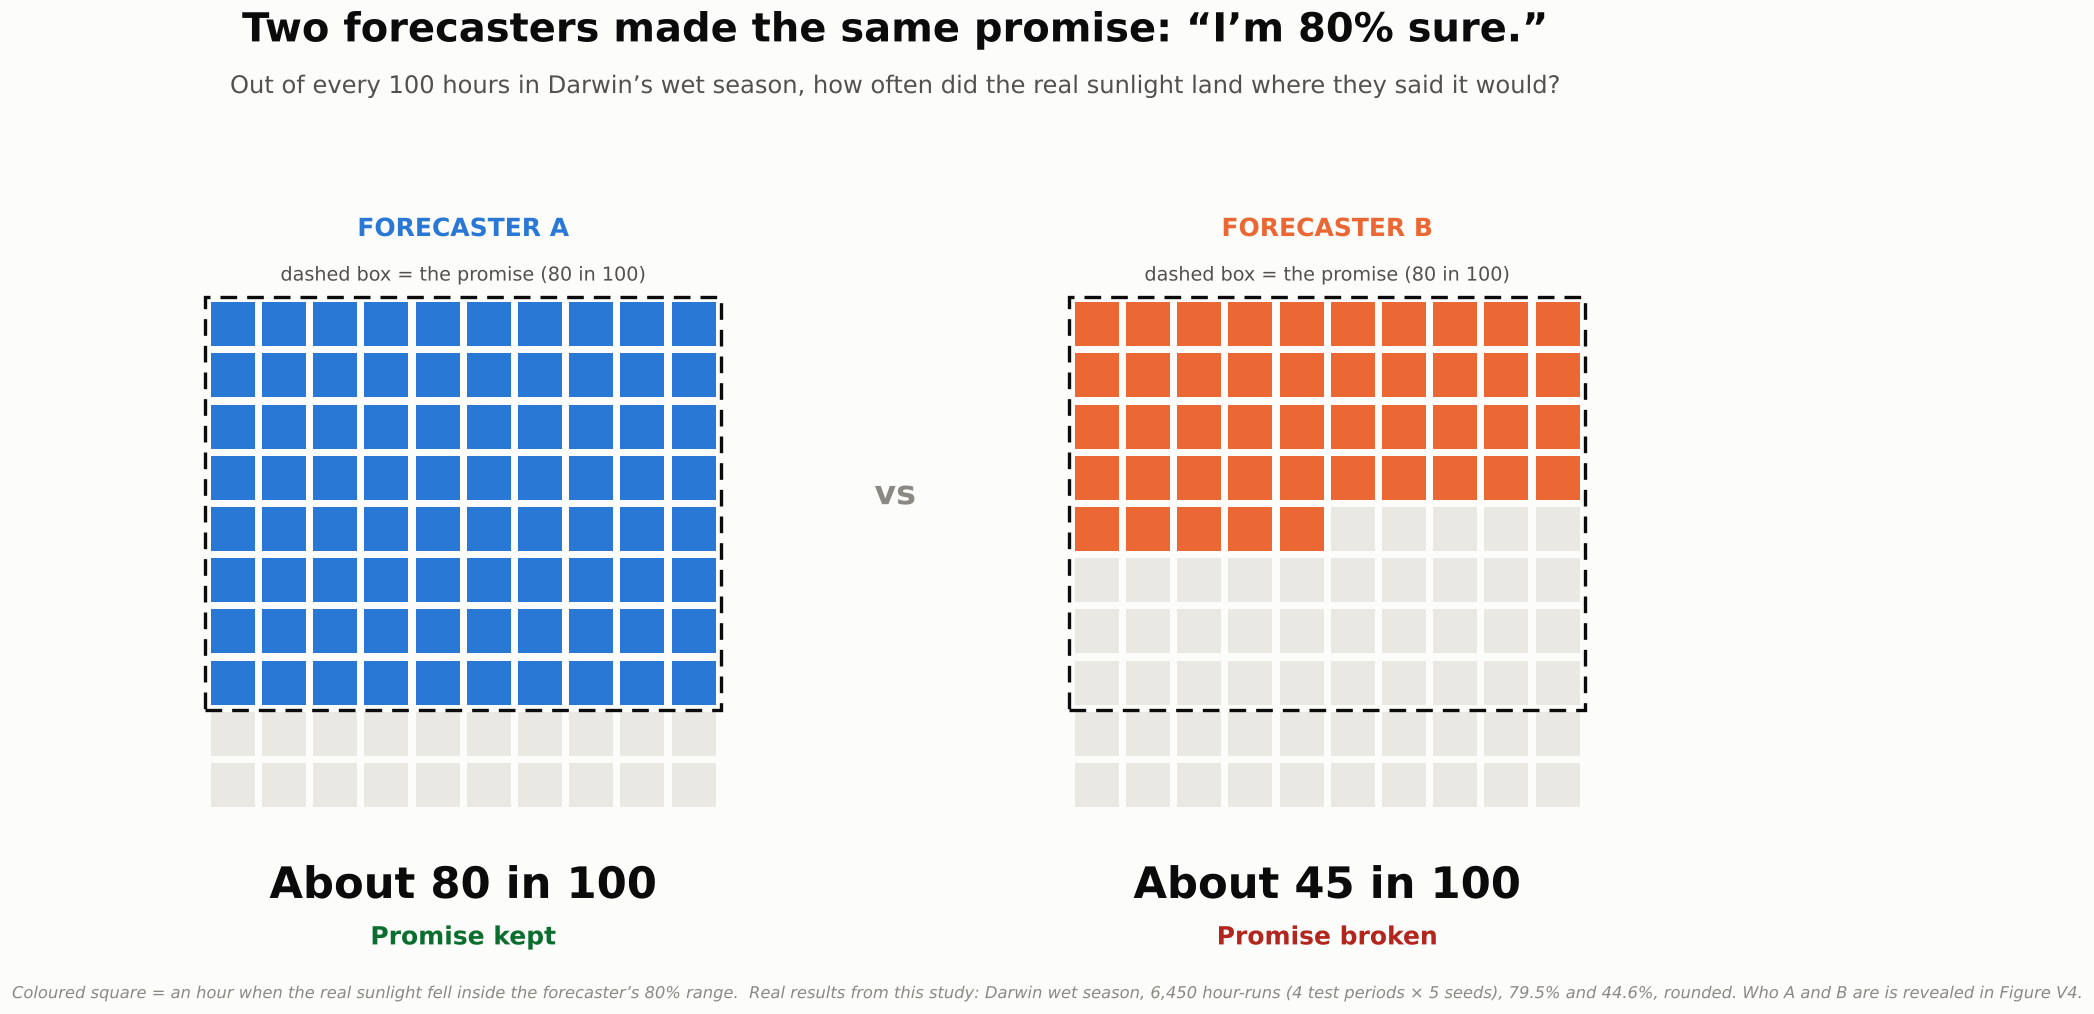

In [ ]:
# @title Figure H1: Same Promise, Same Wet Season {"display-mode":"form"}
# ------------------------------------------------------------------------------------------------
# ADDED FOR THE VIVA HOOK. A picture of two results from this study, drawn for a non-specialist audience.
# It reads no data and changes nothing. It defines only names that start with `_viva`.
# Values: coverage of the 80% range in the Darwin wet season (Stage 14 R5 subgroups, SNAPSHOT):
#   QR-GRU 0.795 and MC-Dropout LSTM 0.446, over 6,450 wet-season hour-runs (4 test periods x 5 seeds).
# Each grid shows the share out of 100, rounded to the nearest whole square (80 and 45).
# ------------------------------------------------------------------------------------------------
def _viva_fig_hook():
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle, FancyBboxPatch

    ink, ink2, muted, surface = "#0b0b0b", "#52514e", "#8a8984", "#fcfcfb"
    blue, orange, empty = "#2a78d6", "#eb6834", "#e9e8e3"
    panels = [("FORECASTER A", 0.795, blue, "Promise kept", "#0b6e2e"),
              ("FORECASTER B", 0.446, orange, "Promise broken", "#b3261e")]

    with plt.rc_context({"font.family": "DejaVu Sans", "figure.facecolor": surface, "savefig.facecolor": surface}):
        fig = plt.figure(figsize=(16, 8.6), dpi=120)
        fig.text(0.5, 0.945, "Two forecasters made the same promise: “I’m 80% sure.”",
                 ha="center", fontsize=24, fontweight="bold", color=ink)
        fig.text(0.5, 0.895, "Out of every 100 hours in Darwin’s wet season, how often did the real sunlight "
                 "land where they said it would?", ha="center", fontsize=14.5, color=ink2)

        for k, (name, share, col, verdict, vcol) in enumerate(panels):
            hits = int(round(100 * share))
            ax = fig.add_axes([0.10 + k * 0.45, 0.17, 0.35, 0.62])
            ax.set_xlim(-0.6, 10.6); ax.set_ylim(-0.6, 11.9); ax.set_aspect("equal"); ax.axis("off")
            for i in range(100):
                r, c = divmod(i, 10)
                x, y = c, 9 - r
                ax.add_patch(Rectangle((x + 0.07, y + 0.07), 0.86, 0.86, fc=col if i < hits else empty,
                                       ec="none"))
            # the promise: 80 of 100 squares
            ax.add_patch(Rectangle((-0.04, 1.96), 10.08, 8.08, fill=False, ec=ink, lw=2.0, ls=(0, (5, 3))))
            ax.text(5.0, 10.45, "dashed box = the promise (80 in 100)", ha="center", va="center",
                    fontsize=11.5, color=ink2)
            ax.text(5.0, 11.35, name, ha="center", va="center", fontsize=15, fontweight="bold", color=col)
            fig.text(0.275 + k * 0.45, 0.115, f"About {hits} in 100", ha="center", fontsize=26,
                     fontweight="bold", color=ink)
            fig.text(0.275 + k * 0.45, 0.07, verdict, ha="center", fontsize=15, fontweight="bold", color=vcol)

        fig.text(0.5, 0.505, "vs", ha="center", va="center", fontsize=20, color=muted, fontweight="bold")
        fig.text(0.04, 0.018, "Coloured square = an hour when the real sunlight fell inside the forecaster’s 80% range.  "
                 "Real results from this study: Darwin wet season, 6,450 hour-runs (4 test periods × 5 seeds), "
                 "79.5% and 44.6%, rounded. Who A and B are is revealed in Figure V4.",
                 fontsize=9.8, color=muted, style="italic")
    return fig


_viva_fig = _viva_fig_hook()
import matplotlib.pyplot as _viva_plt
_viva_plt.show()

### **So I put two computer forecasters to the test.**

Each one **learned from years of past sunlight readings** in Darwin, much like a local learns to read the sky after living somewhere for years. (That learning-from-past-examples is what *machine learning* means.)

Every hour, both made the same promise: *"I'm 80% sure."*

**One kept it. One didn't.** And it broke its promise in the wet season, exactly when the cloud is hardest to predict and the operator most needs to trust it.

> ### **Why would two forecasters, learning from the same data, be so different at admitting what they don't know?**
> ### **And can any forecaster be honest about uncertainty in tropical weather?**

That is the question this research set out to answer.

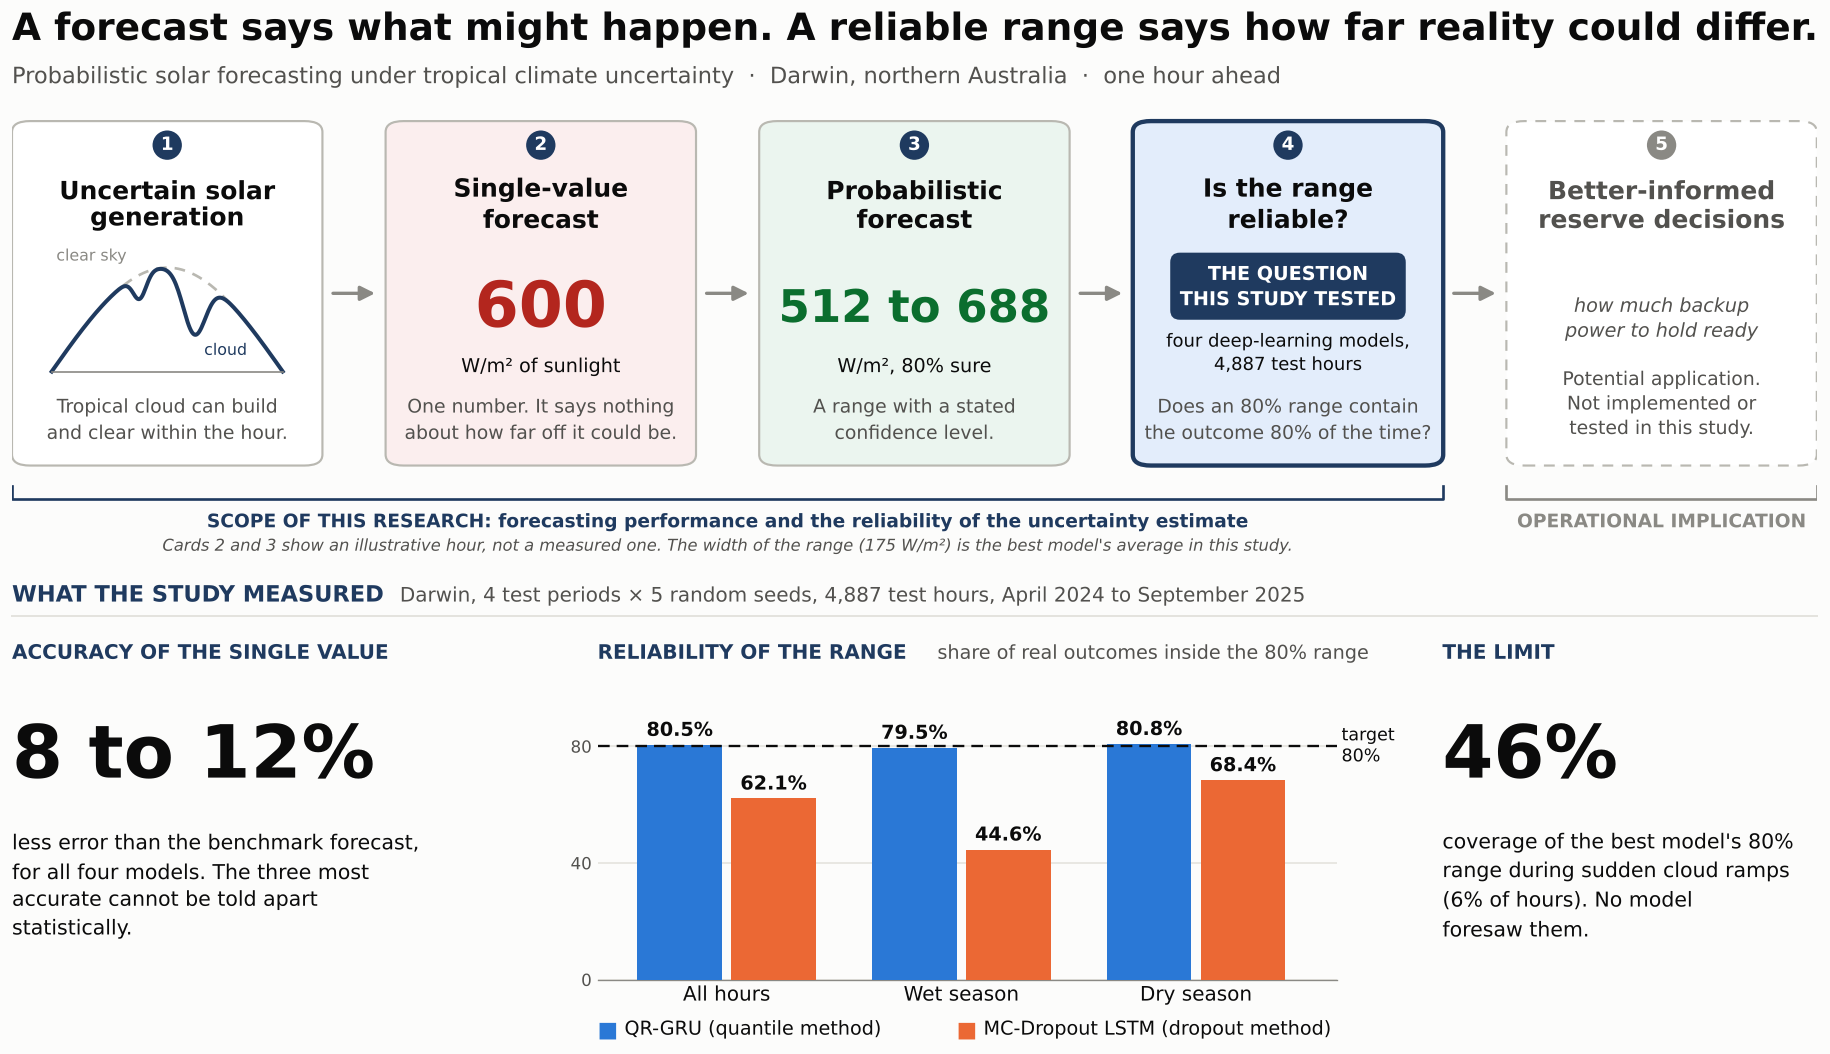

In [ ]:
# @title Figure V0: The Research in One Picture {"display-mode":"form"}
assert "VIVA" in globals(), "Run the 'VIVA setup' cell above first."


def _viva_fig_overview(V):
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch, Rectangle
    np, C = V.np, V.C
    lead = V.frame("R_LEADER").set_index("model")
    sub = V.frame("SUBGROUP_R").set_index(["model", "subgroup"])
    four = ["QR-GRU", "GRU", "LSTM", "MC-Dropout LSTM"]
    sk = lead.loc[four, "skill_RMSE_%"]
    width = float(lead.loc["QR-GRU", "MIW_raw_Wm2"])
    centre = 600.0                                   # illustrative hour, not a study result
    lo, hi = centre - width / 2, centre + width / 2
    ramp_share = 100 * sub.loc[("QR-GRU", "ramp hours"), "n_hour_runs"] / (
        sub.loc[("QR-GRU", "ramp hours"), "n_hour_runs"] + sub.loc[("QR-GRU", "non-ramp"), "n_hour_runs"])

    with plt.rc_context(V.RC):
        fig = plt.figure(figsize=(16, 9), dpi=120)
        fig.text(0.03, 0.945, "A forecast says what might happen. A reliable range says how far reality could differ.",
                 fontsize=22.5, fontweight="bold", color=C["ink"])
        fig.text(0.03, 0.905, "Probabilistic solar forecasting under tropical climate uncertainty  ·  Darwin, northern "
                 "Australia  ·  one hour ahead", fontsize=13.5, color=C["ink2"])

        # ------------------------------ the flow ------------------------------
        ax = fig.add_axes([0.03, 0.475, 0.94, 0.405]); ax.axis("off"); ax.set_xlim(0, 100); ax.set_ylim(0, 40)
        w, gap, y0, h = 17.2, 3.5, 7.5, 31.5
        xs = [i * (w + gap) for i in range(5)]
        heads = ["Uncertain solar\ngeneration", "Single-value\nforecast", "Probabilistic\nforecast",
                 "Is the range\nreliable?", "Better-informed\nreserve decisions"]
        fills = ["#ffffff", C["wash_bad"], C["wash_good"], C["wash_navy"], "#ffffff"]
        for i, x0 in enumerate(xs):
            last = i == 4
            ax.add_patch(FancyBboxPatch((x0, y0), w, h, boxstyle="round,pad=0,rounding_size=1.0", fc=fills[i],
                                        ec=C["navy"] if i == 3 else C["pale"], lw=2.6 if i == 3 else 1.3,
                                        ls=(0, (5, 4)) if last else "-"))
            ax.text(x0 + w / 2, y0 + h - 2.2, f"{i + 1}", fontsize=11, fontweight="bold", color="#ffffff", ha="center",
                    va="center", bbox=dict(boxstyle="circle,pad=0.3", fc=C["muted"] if last else C["navy"], ec="none"))
            ax.text(x0 + w / 2, y0 + h - 7.6, heads[i], fontsize=15, fontweight="bold", ha="center", va="center",
                    color=C["ink2"] if last else C["ink"], linespacing=1.15)
            if i < 4:
                ax.annotate("", xy=(x0 + w + gap - 0.4, y0 + h / 2), xytext=(x0 + w + 0.4, y0 + h / 2),
                            arrowprops=dict(arrowstyle="-|>", color=C["muted"], lw=2.0, mutation_scale=18))
        # card 1: a clear-sky curve with a cloud dip (sketch)
        t = np.linspace(0, 1, 200); clear = np.sin(np.pi * t)
        dip = clear * (1 - 0.62 * np.exp(-((t - 0.62) / 0.07) ** 2) - 0.25 * np.exp(-((t - 0.38) / 0.04) ** 2))
        bx, bw, by, bh = xs[0] + 2.2, w - 4.4, y0 + 8.6, 9.5
        ax.plot(bx + bw * t, by + bh * clear, color=C["pale"], lw=1.6, ls=(0, (4, 3)))
        ax.plot(bx + bw * t, by + bh * dip, color=C["navy"], lw=2.4)
        ax.plot([bx, bx + bw], [by, by], color=C["muted"], lw=1.0)
        ax.text(bx + bw * 0.02, by + bh + 0.3, "clear sky", fontsize=9.5, color=C["muted"], va="bottom")
        ax.text(bx + bw * 0.66, by + bh * 0.2, "cloud", fontsize=9.5, color=C["navy"], va="center", ha="left")
        caps = ["Tropical cloud can build\nand clear within the hour.", "One number. It says nothing\nabout how far off it could be.",
                "A range with a stated\nconfidence level.", "Does an 80% range contain\nthe outcome 80% of the time?",
                "Potential application.\nNot implemented or\ntested in this study."]
        for i, x0 in enumerate(xs):
            ax.text(x0 + w / 2, y0 + (5.6 if i == 4 else 4.2), caps[i], fontsize=11.3, ha="center", va="center",
                    color=C["ink2"], linespacing=1.3)
        ax.text(xs[1] + w / 2, y0 + 14.2, f"{centre:.0f}", fontsize=38, fontweight="bold", ha="center", va="center", color=C["bad"])
        ax.text(xs[1] + w / 2, y0 + 9.0, "W/m² of sunlight", fontsize=11.5, ha="center", va="center", color=C["ink"])
        ax.text(xs[2] + w / 2, y0 + 14.2, f"{lo:.0f} to {hi:.0f}", fontsize=27, fontweight="bold", ha="center", va="center", color=C["good"])
        ax.text(xs[2] + w / 2, y0 + 9.0, "W/m², 80% sure", fontsize=11.5, ha="center", va="center", color=C["ink"])
        ax.text(xs[3] + w / 2, y0 + 16.4, "THE QUESTION\nTHIS STUDY TESTED", fontsize=11.5, fontweight="bold", ha="center",
                va="center", color="#ffffff", linespacing=1.25,
                bbox=dict(boxstyle="round,pad=0.5", fc=C["navy"], ec="none"))
        ax.text(xs[3] + w / 2, y0 + 10.3, "four deep-learning models,\n4,887 test hours", fontsize=10.8, ha="center", va="center", color=C["ink"],
                linespacing=1.25)
        ax.text(xs[4] + w / 2, y0 + 13.4, "how much backup\npower to hold ready", fontsize=11.5, ha="center", va="center",
                color=C["ink2"], style="italic", linespacing=1.3)
        # scope brackets
        def bracket(xa, xb, label, col, ls="-"):
            ax.plot([xa, xa, xb, xb], [5.6, 4.4, 4.4, 5.6], color=col, lw=1.6, ls=ls)
            ax.text((xa + xb) / 2, 2.3, label, fontsize=11.2, ha="center", va="center", color=col, fontweight="bold")
        bracket(xs[0], xs[3] + w, "SCOPE OF THIS RESEARCH: forecasting performance and the reliability of the uncertainty estimate", C["navy"])
        bracket(xs[4], xs[4] + w, "OPERATIONAL IMPLICATION", C["muted"])
        ax.text((xs[1] + xs[2] + w) / 2, 0.1, f"Cards 2 and 3 show an illustrative hour, not a measured one. The width of the range ({width:.0f} W/m²) "
                "is the best model's average in this study.", fontsize=9.8, ha="center", va="center", color=C["ink2"], style="italic")

        # ------------------------------ what the study measured ------------------------------
        fig.text(0.03, 0.425, "WHAT THE STUDY MEASURED", fontsize=13.5, fontweight="bold", color=C["navy"])
        fig.text(0.232, 0.425, f"Darwin, {V.FACTS['folds']} test periods × {V.FACTS['seeds']} random seeds, "
                 f"{V.FACTS['test_hours']:,} test hours, April 2024 to September 2025", fontsize=12, color=C["ink2"])
        fig.add_artist(plt.Line2D([0.03, 0.97], [0.412, 0.412], color=C["grid"], lw=1.2))

        def hero(x, tag, number, body):
            fig.text(x, 0.372, tag, fontsize=12, fontweight="bold", color=C["navy"])
            fig.text(x, 0.262, number, fontsize=44, fontweight="bold", color=C["ink"])
            fig.text(x, 0.215, body, fontsize=12.3, color=C["ink"], va="top", linespacing=1.4)

        hero(0.03, "ACCURACY OF THE SINGLE VALUE", f"{sk.min():.0f} to {sk.max():.0f}%",
             "less error than the benchmark forecast,\nfor all four models. The three most\naccurate cannot be told apart\nstatistically.")
        hero(0.775, "THE LIMIT", f"{100 * sub.loc[('QR-GRU', 'ramp hours'), 'PICP80_raw']:.0f}%",
             f"coverage of the best model's 80%\nrange during sudden cloud ramps\n({ramp_share:.0f}% of hours). No model\nforesaw them.")

        b = fig.add_axes([0.335, 0.075, 0.385, 0.27])
        groups = [("All hours", None), ("Wet season", "wet season"), ("Dry season", "dry season")]
        bwid = 0.36
        for j, (m, col) in enumerate([("QR-GRU", C["qr"]), ("MC-Dropout LSTM", C["mc"])]):
            vals = [100 * (lead.loc[m, "PICP80_raw"] if g is None else sub.loc[(m, g), "PICP80_raw"]) for _, g in groups]
            xpos = np.arange(3) + (j - 0.5) * (bwid + 0.04)
            b.bar(xpos, vals, width=bwid, color=col, zorder=3)
            for xp, v in zip(xpos, vals):
                b.text(xp, v + 1.5, f"{v:.1f}%", ha="center", va="bottom", fontsize=11.5, fontweight="bold", color=C["ink"])
        b.axhline(80, color=C["ink"], lw=1.4, ls=(0, (5, 3)), zorder=4)
        b.text(2.62, 80, "target\n80%", fontsize=10.5, color=C["ink"], va="center", ha="left")
        b.set_xticks(range(3)); b.set_xticklabels([g for g, _ in groups], fontsize=12, color=C["ink"])
        b.set_ylim(0, 100); b.set_xlim(-0.55, 2.6); b.set_yticks([0, 40, 80]); b.set_yticklabels(["0", "40", "80"], fontsize=10)
        b.tick_params(axis="x", length=0); b.spines["left"].set_visible(False); b.tick_params(axis="y", length=0)
        b.yaxis.grid(True, color=C["grid"], lw=1); b.set_axisbelow(True)
        fig.text(0.335, 0.372, "RELIABILITY OF THE RANGE", fontsize=12, fontweight="bold", color=C["navy"])
        fig.text(0.512, 0.372, "share of real outcomes inside the 80% range", fontsize=11.5, color=C["ink2"])
        fig.text(0.335, 0.022, "■", fontsize=13, color=C["qr"]); fig.text(0.349, 0.024, "QR-GRU (quantile method)", fontsize=11.5, color=C["ink"])
        fig.text(0.522, 0.022, "■", fontsize=13, color=C["mc"]); fig.text(0.536, 0.024, "MC-Dropout LSTM (dropout method)", fontsize=11.5, color=C["ink"])
        plt.show()
    V.display(V.HTML(f"<div style='font-size:12px; opacity:.8; margin:2px 0 14px 0'>Figure V0. Cards 1 to 3 and 5 are a concept sketch (STATIC). "
                     f"The lower band is measured: {V.src('R_LEADER', 'SUBGROUP_R')}. Report: Table 6 and Sections 5.3 to 5.4.</div>"))


VIVA.run(_viva_fig_overview)

**Read the picture left to right.** Cloud makes solar output uncertain (1). A single-value forecast hides how far off it could be (2). A range states its own confidence (3). This study tested whether that stated confidence is true (4). Card 5 is where a reliable range would be used. It was **not** built or tested here.

<details>
<summary><b>Presenter cue</b> (click to open, closed while presenting)</summary>

* Point to: card 4, the dark box. That is the whole study in one question.
* Emphasise: card 5 is dashed on purpose. No reserve system was implemented.
* The lower band previews the three results. Do not read the numbers out yet.

</details>

---

# **VIVA Section#2 · PROBLEM**

## **Grids Plan an hour ahead on One Number**

**How it is done today.** Operators commit reserve about **one hour ahead**, usually from a single-value forecast plus a margin set by experience.

**Why the tropics make this hard**

| | What happens | Why it hurts the forecast |
|---|---|---|
| **High sun** | One passing cloud removes several hundred W/m² within minutes. | The same cloud causes a bigger absolute error than at higher latitudes. |
| **Fast convective cloud** | Cloud forms and clears inside the hour. | The last hour is a weaker guide to the next one. |
| **Two seasons** | Wet and dry seasons behave like two climates. | A model can look fine on average and fail in one season. |

**What earlier studies left open**

| What was established | What was left open |
|---|---|
| Tropical studies (Singapore) forecast a single value and report accuracy only. Gains over simple methods are modest. | Whether the *uncertainty* around a tropical forecast can be trusted. |
| Quantile regression gave reliable ranges at island and temperate sites, using linear models. | Whether a deep-learning model keeps a reliable range through a tropical wet season. |
| Deep-learning comparisons use mostly temperate and arid data, judged mostly on accuracy. | A like-for-like comparison of single-value and range-producing networks under one protocol. |
| Theory (Kendall and Gal, 2017) predicts that dropout-based uncertainty misses the randomness in the data. | A test of that prediction on solar data. |

> **The gap.** Grid operators size reserve from single-value solar forecasts, yet few studies have checked whether deep-learning forecasts give *reliable* uncertainty, and fewer still under tropical conditions.

<sub>STATIC. Report Sections 1, 2.3 and 2.4 (Table 2); notebook Section 0.</sub>

---

# **VIVA Section#3 · INSIGHT**

## **Accuracy and Reliability are Two Different Questions**

Most forecasting studies stop at one question: **how close is the single number?** An operator sizing reserve needs a second one answered too: **when the forecast says it is 80% sure, is it right 80% of the time?**

A model can do well on the first and badly on the second. The figure below shows that with invented numbers, so the idea is clear before any real result appears.

**Aim.** To find out whether probabilistic solar forecasting can give a reliable range of outcomes for a tropical site, not only a single predicted value.

**Research question.** *Which deep learning architecture, deterministic (LSTM, GRU) or probabilistic (MC-Dropout LSTM, Quantile Regression GRU), produces the most accurate and best-calibrated solar irradiance forecasts for tropical climates under wet/dry seasonal conditioning?*

| Objective | In plain words | Answered in |
|---|---|---|
| **O1** Accuracy | Does each model beat a simple benchmark? Is sunlight a fair stand-in for PV power? | Table V1, Figure V3, Table B3 |
| **O2** Calibration | Does the stated range hold, in the wet season as well as the dry, and does it cost accuracy? | Figure V4, Table V2 |
| **O3** Season and ramps | Does telling the model the season help? What happens when cloud changes suddenly? | Table V3 |
| **O4** Decision support | Can the width of the range serve as a simple operating rule? | Table V3 |
| **O5** Transfer | Do the Darwin models work, unchanged, in other climates? | Table B4 |

<sub>STATIC. Report Section 1.1 and Table 1; notebook Section 0.</sub>

Concept,The plain question,The academic meaning,Measured in this study by
Point forecast,What is the predicted solar output?,"The single best estimate, here the forecast one hour ahead","RMSE, skill"
Prediction interval,Within what range might the actual output fall?,"Lower and upper bounds with a stated confidence, here the central 80% range",—
Coverage,How often does the actual output fall within that range?,Share of test hours whose outcome lies inside the range. For an 80% range it should be close to 80%,PICP
Interval width,How wide is the predicted range?,"Average distance between the bounds in W/m². Narrower is more useful, provided coverage holds",MIW
Probabilistic reliability,Can we trust the uncertainty information being provided?,"Calibration: stated confidence matches observed frequency. Judged with coverage, then width and proper scores","PICP, Winkler, CRPS"


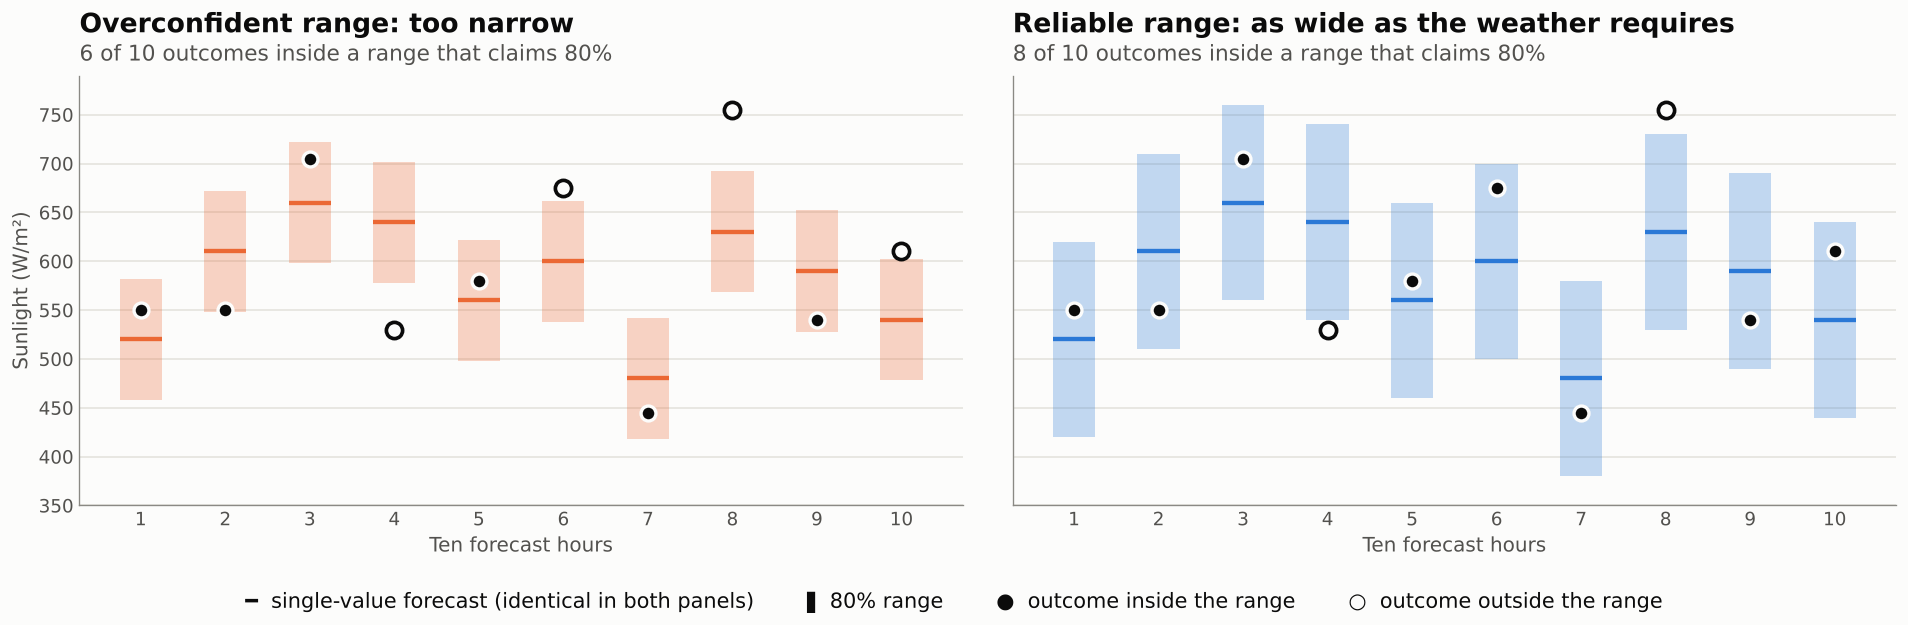

In [ ]:
# @title Figure V1: Accuracy and Reliability are Two Different Questions {"display-mode":"form"}
assert "VIVA" in globals(), "Run the 'VIVA setup' cell above first."


def _viva_fig_concept(V):
    import matplotlib.pyplot as plt
    np, pd, C = V.np, V.pd, V.C
    rows = [
        ("Point forecast", "What is the predicted solar output?", "The single best estimate, here the forecast one hour ahead", "RMSE, skill"),
        ("Prediction interval", "Within what range might the actual output fall?", "Lower and upper bounds with a stated confidence, here the central 80% range", "—"),
        ("Coverage", "How often does the actual output fall within that range?", "Share of test hours whose outcome lies inside the range. For an 80% range it should be close to 80%", "PICP"),
        ("Interval width", "How wide is the predicted range?", "Average distance between the bounds in W/m². Narrower is more useful, provided coverage holds", "MIW"),
        ("Probabilistic reliability", "Can we trust the uncertainty information being provided?", "Calibration: stated confidence matches observed frequency. Judged with coverage, then width and proper scores", "PICP, Winkler, CRPS"),
    ]
    V.table(pd.DataFrame(rows, columns=["Concept", "The plain question", "The academic meaning", "Measured in this study by"]),
            "Table V0. Five ideas the whole presentation rests on",
            "STATIC definitions. Report Section 4.5; notebook Stage 10.2.",
            highlight=lambda r: r["Concept"] == "Probabilistic reliability",
            widths=["16%", "30%", "40%", "14%"])

    # ---- concept sketch: same point forecasts, two different ranges (not data) ----
    centre = np.array([520, 610, 660, 640, 560, 600, 480, 630, 590, 540], float)
    actual = centre + np.array([30, -60, 45, -110, 20, 75, -35, 125, -50, 70], float)
    with plt.rc_context(V.RC):
        fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), dpi=120, sharey=True)
        for ax, half, col, title in ((axes[0], 62, C["mc"], "Overconfident range: too narrow"),
                                     (axes[1], 100, C["qr"], "Reliable range: as wide as the weather requires")):
            x = np.arange(1, 11)
            inside = np.abs(actual - centre) <= half
            ax.bar(x, 2 * half, bottom=centre - half, width=0.5, color=col, alpha=0.28, zorder=2)
            ax.hlines(centre, x - 0.25, x + 0.25, color=col, lw=2.6, zorder=3)
            ax.scatter(x[inside], actual[inside], s=80, color=C["ink"], zorder=5, edgecolor=C["surface"], linewidth=2)
            ax.scatter(x[~inside], actual[~inside], s=95, facecolor=C["surface"], edgecolor=C["ink"], linewidth=2.2, zorder=5)
            ax.set_title(title, fontsize=16, loc="left", color=C["ink"], pad=26)
            ax.text(0, 1.035, f"{int(inside.sum())} of 10 outcomes inside a range that claims 80%",
                    transform=ax.transAxes, fontsize=13, color=C["ink2"])
            ax.set_xticks(x); ax.set_xlabel("Ten forecast hours", fontsize=12); ax.set_ylim(350, 790)
            ax.yaxis.grid(True, color=C["grid"], lw=1); ax.set_axisbelow(True); ax.tick_params(length=0, labelsize=11)
        axes[0].set_ylabel("Sunlight (W/m²)", fontsize=12)
        fig.tight_layout(w_pad=3, rect=(0, 0.07, 1, 1))
        fig.text(0.5, 0.025, "━  single-value forecast (identical in both panels)        ▌ 80% range        ●  outcome inside the range        "
                 "○  outcome outside the range", fontsize=12.5, color=C["ink"], ha="center", va="center")
        plt.show()
    V.display(V.HTML("<div style='font-size:12px; opacity:.8; margin:2px 0 6px 0'>Figure V1. Concept sketch with invented values (STATIC). "
                     "It is not data from the study.</div>"))
    V.say("The single-value forecasts are identical in both panels, so the two models are equally accurate. Only the right-hand "
          "range keeps its promise. A model can be accurate and still give uncertainty information that cannot be trusted. "
          "That is the distinction this research tests.")


VIVA.run(_viva_fig_concept)

**What to notice.** In Figure V1 the two single-value forecasts are identical, so both models are equally accurate. Only the right-hand range keeps its promise. That is the distinction the rest of the talk measures with real data.

> **Takeaway.** Being accurate does not make a model trustworthy about its uncertainty. These have to be tested separately.

---

# **VIVA Section#4 · SOLUTION**

## **VIVA Section#4.1 How the Research Notebook is Built**

Before the results, a map. The research code below this VIVA section runs in **thirteen parts across five phases**, and each phase hands a checked output to the next. Figure V5 shows the whole route from raw files to findings.

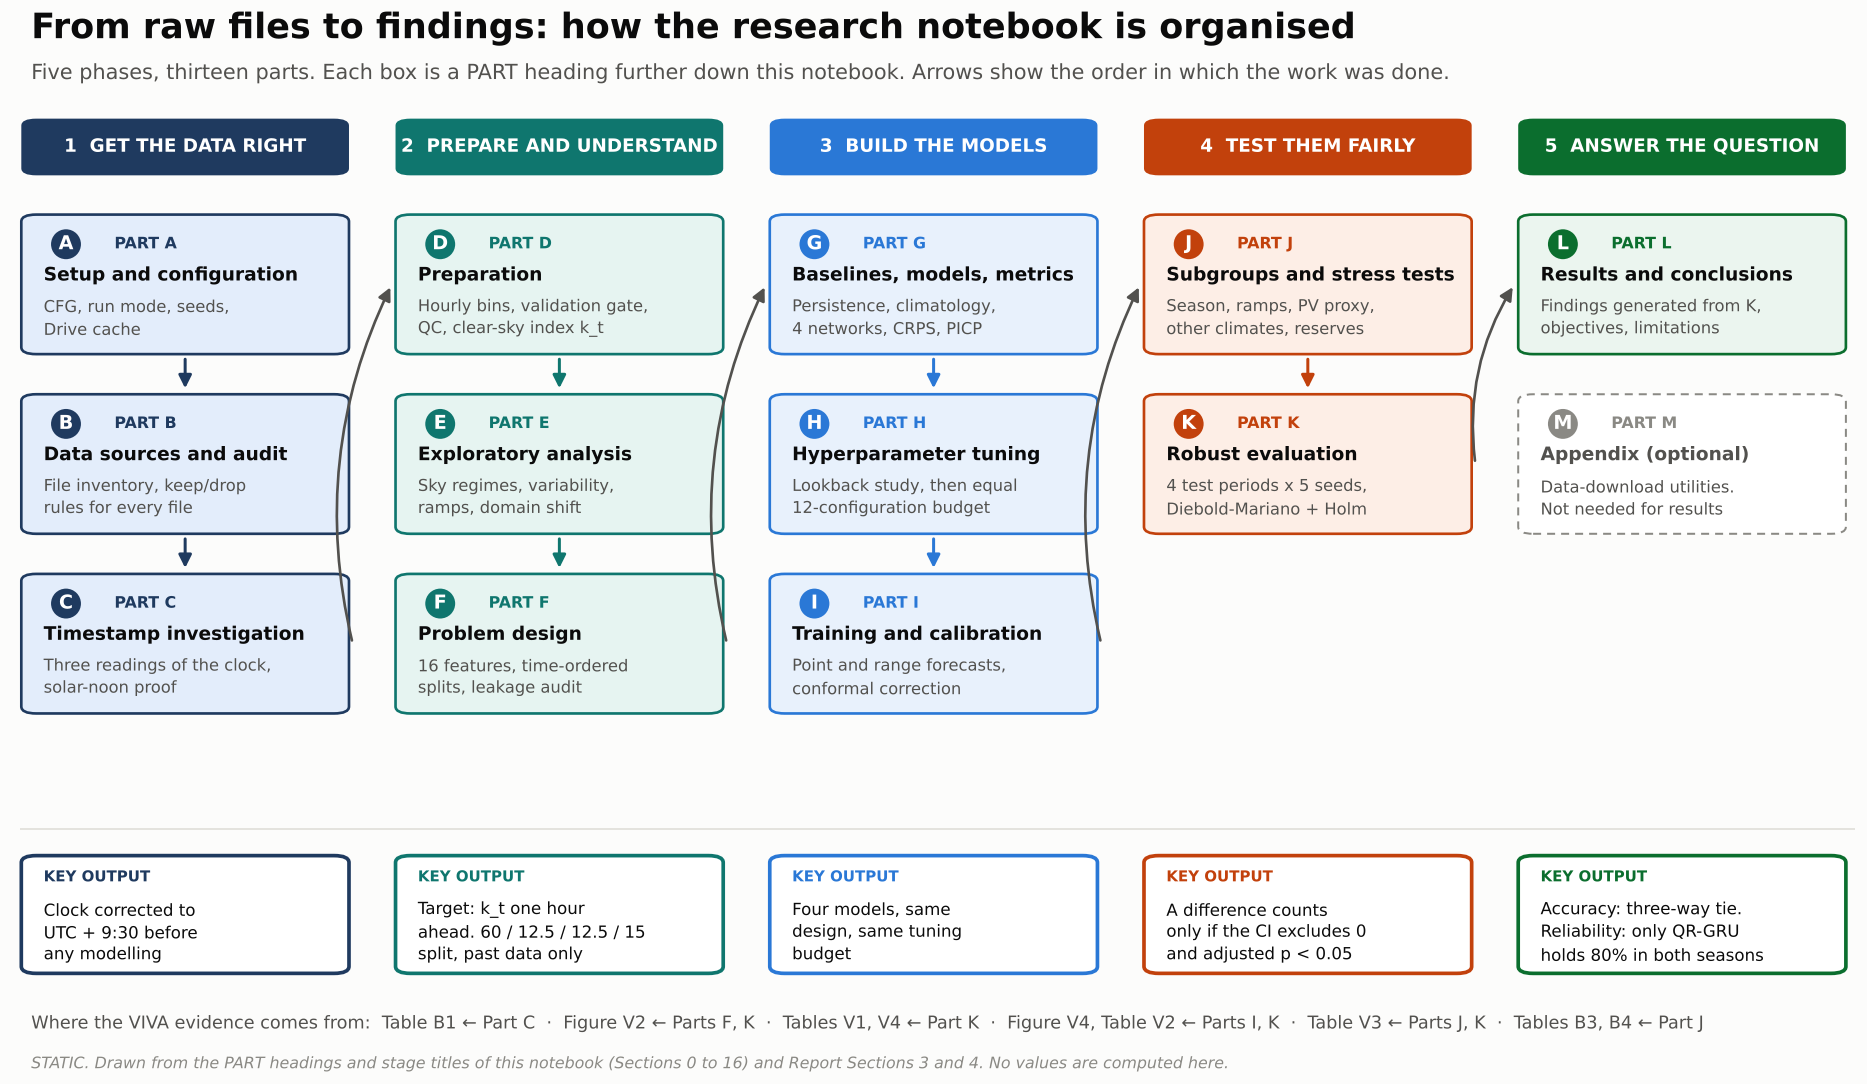

In [ ]:
# @title Figure V5: How the Research Notebook is Built, From Raw Files to Findings {"display-mode":"form"}
# ------------------------------------------------------------------------------------------------
# ADDED FOR THE VIVA. A drawing of the notebook's own structure. It reads no data and changes nothing.
# It defines only names that start with `_viva`, so it cannot collide with the original code.
# Every box is a PART heading that already exists further down in this notebook.
# ------------------------------------------------------------------------------------------------
def _viva_fig_workflow():
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

    ink, ink2, muted, surface = "#0b0b0b", "#52514e", "#8a8984", "#fcfcfb"
    phases = [
        ("1  GET THE DATA RIGHT", "#1f3a5f", "#e3edfb", [
            ("A", "Setup and configuration", "CFG, run mode, seeds,\nDrive cache"),
            ("B", "Data sources and audit", "File inventory, keep/drop\nrules for every file"),
            ("C", "Timestamp investigation", "Three readings of the clock,\nsolar-noon proof"),
        ], "Clock corrected to\nUTC + 9:30 before\nany modelling"),
        ("2  PREPARE AND UNDERSTAND", "#0f766e", "#e6f4f1", [
            ("D", "Preparation", "Hourly bins, validation gate,\nQC, clear-sky index k_t"),
            ("E", "Exploratory analysis", "Sky regimes, variability,\nramps, domain shift"),
            ("F", "Problem design", "16 features, time-ordered\nsplits, leakage audit"),
        ], "Target: k_t one hour\nahead. 60 / 12.5 / 12.5 / 15\nsplit, past data only"),
        ("3  BUILD THE MODELS", "#2a78d6", "#e8f1fc", [
            ("G", "Baselines, models, metrics", "Persistence, climatology,\n4 networks, CRPS, PICP"),
            ("H", "Hyperparameter tuning", "Lookback study, then equal\n12-configuration budget"),
            ("I", "Training and calibration", "Point and range forecasts,\nconformal correction"),
        ], "Four models, same\ndesign, same tuning\nbudget"),
        ("4  TEST THEM FAIRLY", "#c2410c", "#fdeee6", [
            ("J", "Subgroups and stress tests", "Season, ramps, PV proxy,\nother climates, reserves"),
            ("K", "Robust evaluation", "4 test periods x 5 seeds,\nDiebold-Mariano + Holm"),
        ], "A difference counts\nonly if the CI excludes 0\nand adjusted p < 0.05"),
        ("5  ANSWER THE QUESTION", "#0b6e2e", "#ebf5ef", [
            ("L", "Results and conclusions", "Findings generated from K,\nobjectives, limitations"),
            ("M", "Appendix (optional)", "Data-download utilities.\nNot needed for results"),
        ], "Accuracy: three-way tie.\nReliability: only QR-GRU\nholds 80% in both seasons"),
    ]

    with plt.rc_context({"font.family": "DejaVu Sans", "figure.facecolor": surface, "savefig.facecolor": surface}):
        fig = plt.figure(figsize=(16, 9.2), dpi=120)
        fig.text(0.03, 0.955, "From raw files to findings: how the research notebook is organised",
                 fontsize=21, fontweight="bold", color=ink)
        fig.text(0.03, 0.918, "Five phases, thirteen parts. Each box is a PART heading further down this notebook. "
                 "Arrows show the order in which the work was done.", fontsize=12.5, color=ink2)
        ax = fig.add_axes([0.02, 0.10, 0.96, 0.79]); ax.axis("off")
        ax.set_xlim(0, 100); ax.set_ylim(0, 100)

        col_w, gap = 17.6, 2.5
        box_h, box_gap, top = 16.0, 4.6, 88.0
        last_box = None
        for k, (title, dark, wash, boxes, output) in enumerate(phases):
            x0 = k * (col_w + gap)
            ax.add_patch(FancyBboxPatch((x0, 92.5), col_w, 6.5, boxstyle="round,pad=0,rounding_size=0.8",
                                        fc=dark, ec=dark, lw=0))
            ax.text(x0 + col_w / 2, 95.75, title, ha="center", va="center", fontsize=11, fontweight="bold", color="white")
            for j, (letter, head, body) in enumerate(boxes):
                y_top = top - j * (box_h + box_gap)
                y0 = y_top - box_h
                optional = letter == "M"
                ax.add_patch(FancyBboxPatch((x0, y0), col_w, box_h, boxstyle="round,pad=0,rounding_size=0.8",
                                            fc="#ffffff" if optional else wash, ec=muted if optional else dark,
                                            lw=1.2 if optional else 1.6, ls=(0, (4, 3)) if optional else "-"))
                ax.text(x0 + 2.4, y_top - 3.4, letter, ha="center", va="center", fontsize=11.5,
                        fontweight="bold", color="white", zorder=4,
                        bbox=dict(boxstyle="circle,pad=0.28", fc=muted if optional else dark, ec="none"))
                ax.text(x0 + 5.0, y_top - 3.4, f"PART {letter}", ha="left", va="center", fontsize=9.5,
                        fontweight="bold", color=muted if optional else dark)
                ax.text(x0 + 1.2, y_top - 7.0, head, ha="left", va="center", fontsize=11.2, fontweight="bold",
                        color=ink2 if optional else ink)
                ax.text(x0 + 1.2, y_top - 9.3, body, ha="left", va="top", fontsize=9.8, color=ink2, linespacing=1.35)
                if j > 0 and not optional:
                    ax.add_patch(FancyArrowPatch((x0 + col_w / 2, y_top + box_gap - 0.2), (x0 + col_w / 2, y_top + 0.3),
                                                 arrowstyle="-|>", mutation_scale=16, color=dark, lw=1.8))
                if j == 0 and last_box is not None:
                    lx, ly = last_box
                    ax.add_patch(FancyArrowPatch((lx, ly), (x0 - 0.2, y_top - box_h / 2),
                                                 connectionstyle="arc3,rad=-0.18", arrowstyle="-|>",
                                                 mutation_scale=16, color=ink2, lw=1.6))
                if not optional:
                    last_box = (x0 + col_w + 0.2, y0 + box_h / 2)
            # key output of the phase
            ax.add_patch(FancyBboxPatch((x0, 1.0), col_w, 13.5, boxstyle="round,pad=0,rounding_size=0.8",
                                        fc="#ffffff", ec=dark, lw=2.2))
            ax.text(x0 + 1.2, 12.0, "KEY OUTPUT", fontsize=9, fontweight="bold", color=dark, va="center")
            ax.text(x0 + 1.2, 9.6, output, fontsize=10, color=ink, va="top", linespacing=1.35)
        # where the key output band starts
        ax.plot([0, 100], [17.6, 17.6], color="#e4e3de", lw=1.2)

        fig.text(0.03, 0.058, "Where the VIVA evidence comes from:  Table B1 ← Part C  ·  Figure V2 ← Parts F, K  ·  "
                 "Tables V1, V4 ← Part K  ·  Figure V4, Table V2 ← Parts I, K  ·  Table V3 ← Parts J, K  ·  "
                 "Tables B3, B4 ← Part J", fontsize=10.6, color=ink2)
        fig.text(0.03, 0.022, "STATIC. Drawn from the PART headings and stage titles of this notebook (Sections 0 to 16) "
                 "and Report Sections 3 and 4. No values are computed here.", fontsize=9.5, color=muted, style="italic")
        ax.set_xlim(-0.5, 98.5)
    return fig


_viva_fig = _viva_fig_workflow()
import matplotlib.pyplot as _viva_plt
_viva_plt.show()

### **Notebook Navigation Guide**

Click a part name to jump to it. The **Table of contents** panel on the left of Colab shows the same PART headings. Use the browser's back button, or the first link in the list, to return here.

| Part | Go to | Notebook stages | What is there | Feeds the VIVA |
|---|---|---|---|---|
| **A** | [Setup and configuration](#scrollTo=viva_nav_A) | Sections 0 to 1 · Setup | Run mode, seeds, utilities | – |
| **B** | [Data sources, collection and initial audit](#scrollTo=viva_nav_B) | Stages 2 to 3 | Every file listed and kept or dropped by rule | – |
| **C** | [Data integrity: the timestamp investigation](#scrollTo=viva_nav_C) | Stages 4 to 5 (5.1 to 5.5) | Three clock readings, solar-noon test, effect on models | Table B1 |
| **D** | [Data preparation and preprocessing](#scrollTo=viva_nav_D) | Stages 6 to 7 | Validation gate, QC, k_t, engineered features | – |
| **E** | [Exploratory data analysis](#scrollTo=viva_nav_E) | Stage 8 | Sky regimes, variability, ramps, domain shift | – |
| **F** | [Forecasting problem design](#scrollTo=viva_nav_F) | Stage 9 | Feature screen, time-ordered splits, leakage audit | Figure V2 |
| **G** | [Baselines, architectures and metrics](#scrollTo=viva_nav_G) | Stage 10 | Four networks, pinball loss, CRPS, PICP | Table V0 |
| **H** | [Hyperparameter tuning](#scrollTo=viva_nav_H) | Stage 11 | Lookback study, equal-budget tuning | – |
| **I** | [Training, probabilistic forecasting, calibration](#scrollTo=viva_nav_I) | Stage 12 | Ranges, conformal correction, error structure | Table V2 |
| **J** | [Season, ramp, PV proxy, transfer, decision support](#scrollTo=viva_nav_J) | Stage 13 | Subgroups, proxy test, other climates, reserves | Tables V3, B3, B4 |
| **K** | [Robust evaluation and significance testing](#scrollTo=viva_nav_K) | Stage 14 (R1 to R6) | 4 periods × 5 seeds, Diebold-Mariano, Holm | Tables V1, V4, Figure V4 |
| **L** | [Results, discussion and conclusions](#scrollTo=viva_nav_L) | Stages 15 to 16 | Findings, objective matrix, limitations | Section 5 of this talk |
| **M** | [Appendix: data-acquisition utilities](#scrollTo=viva_nav_M) | Appendix | Optional downloads, not used for results | – |

<sub>STATIC. Part headings and stage numbers as they appear in this notebook.</sub>

## **VIVA Section#4.2 The Data, and the Check that came first**

| | |
|---|---|
| **Site** | Darwin, northern Australia. Tropical savanna. Wet season November to April. |
| **Source** | NT Solar Resource project, a Class A station, published openly by the DKA Solar Centre. |
| **Size** | 44.9 million one-second readings (2021 to 2023), extended to September 2025 with the station's five-minute export. The two agree on 4,718 overlapping hours (R² = 0.9987). |
| **What is forecast** | The **clear-sky index** one hour ahead: measured sunlight divided by what a cloudless sky would give. 1 is cloudless, lower is cloudier. This removes the daily rise and fall of the sun, so the model has to forecast cloud. |
| **Inputs** | The last 24 hours of the clear-sky index, sun position, time of day and year, and a wet-season flag. 16 features. |
| **Test hours** | 4,887 daylight hours, April 2024 to September 2025, about a quarter in the wet season. |

**Why I checked the clock against the sun.** Each file has two time columns, and the "local" one is UTC + 9:00. Darwin is UTC + 9:30. On the ten clearest days of July 2022, the measured curve peaked **31 minutes** before solar noon on the file's clock and **under a minute** before it on UTC + 9:30. Left uncorrected, the error made QR-GRU look **16.6% better** than the benchmark when on the correct clock it was **36% worse** in that early controlled test. Everything after Part C uses the corrected clock, and a gate stops the pipeline if a clear day drifts more than 10 minutes.

> **Takeaway.** The data were made trustworthy before any model was trained. Details are in Table B1 (backup) and Part C.

<sub>STATIC. Report Sections 3.1 to 3.3, 4.1 and 5.1 (Table 5); notebook Stages 4 to 6.5, 9.2 and 14 R1.</sub>

## **VIVA Section#4.3 Four Forecasters, One Question**

Four networks were given the same 24 hours of cloud history and asked the same thing: **how cloudy will the next hour be?** Two answer with one number. Two answer with a number and a range.

| Model | Answers with | In plain words | Why it is in the study |
|---|---|---|---|
| **LSTM** | One number | A recurrent network that reads the 24 hours in order and keeps a memory of what matters. | Standard baseline. |
| **GRU** | One number | A lighter recurrent network with fewer internal gates. | Does the choice of cell matter? |
| **MC-Dropout LSTM** | Number + range | The LSTM run 50 times with random parts switched off. The spread of answers is the uncertainty. | The cheapest way to add uncertainty to an existing network. |
| **QR-GRU** (quantile regression) | Number + range | The GRU trained to output the range directly, seven levels from the 5th to the 95th percentile. | Learns the spread of real outcomes with no assumption about its shape. |
| *Persistence* | Benchmark | "The next hour will be as cloudy as this hour." | A model only has skill if it beats this. |

A fifth network, **HMC-LSTM** (dropout plus a learned noise term), was used only as a diagnostic to test *why* dropout ranges fail. It does not compete.

**How a forecast was judged**

| Question | Metric | Simple meaning |
|---|---|---|
| How accurate is the single value? | RMSE, skill | Typical size of the miss, and how much of the benchmark's error was removed. |
| How often is the range right? | Coverage (PICP) | Out of 100 hours, how many landed inside the 80% range. It should be about 80. |
| How wide is the range? | Width (MIW) | Narrower is more useful, as long as coverage holds. |
| Width and misses together | Winkler score | Width plus a penalty each time the outcome falls outside. |
| The whole forecast | CRPS | One score that rewards ranges that are both narrow and right. |

<details>
<summary><b>The quantities in notation</b> (click to open)</summary>

Clear-sky index, the forecasting target:
* $k_t(t) = \frac{GHI(t)}{GHI_{cs}(t)}$

Persistence benchmark:
* $\hat{k}_t(t+1\,\mathrm{h}) = k_t(t)$

Skill against persistence:
* $\text{skill} = 100 \times \left(1 - \frac{RMSE_{model}}{RMSE_{persistence}}\right)$

Pinball loss that trains each quantile $\tau$ of QR-GRU:
* $L_\tau(y, \hat{q}_\tau) = \max\big(\tau\,(y - \hat{q}_\tau),\; (\tau - 1)\,(y - \hat{q}_\tau)\big)$

Coverage of the 80% range, with bounds $\hat{q}_{0.1}$ and $\hat{q}_{0.9}$:
* $PICP_{80} = \frac{1}{N}\sum_{i=1}^{N} \mathbf{1}\big[\hat{q}_{0.1,i} \le y_i \le \hat{q}_{0.9,i}\big]$

</details>

<sub>STATIC. Report Sections 2.1, 4.3 and 4.5; notebook Stage 10.</sub>

## **VIVA Section#4.4 Making the Comparison Fair**

A small gap between models can come from luck, extra tuning or one unusual stretch of weather. Each design choice below closes one of those doors.

| Design choice | The risk it removes |
|---|---|
| **Same network size, same 12-configuration tuning grid** for every model. | A model winning through extra tuning. Tuning moved scores by 2.0 to 7.9 W/m² within a model; the gap between model types was 31.1 W/m². |
| **Four test periods**, each trained only on earlier data. No shuffling. | The future leaking into training, and one period's weather deciding the ranking. |
| **Five random seeds** per model. | A lucky random start. |
| **Wet and dry season scored separately.** | A range that looks right on average but fails in one season. |
| **A separate calibration split.** | Correcting the range on data already used to choose the model. |
| **Leakage checks executed in code.** | Scalers or benchmarks fitted on test data. |

<sub>STATIC. Report Sections 4.2, 4.4 and 4.5; notebook Stages 9.3, 11.2 and 14.</sub>

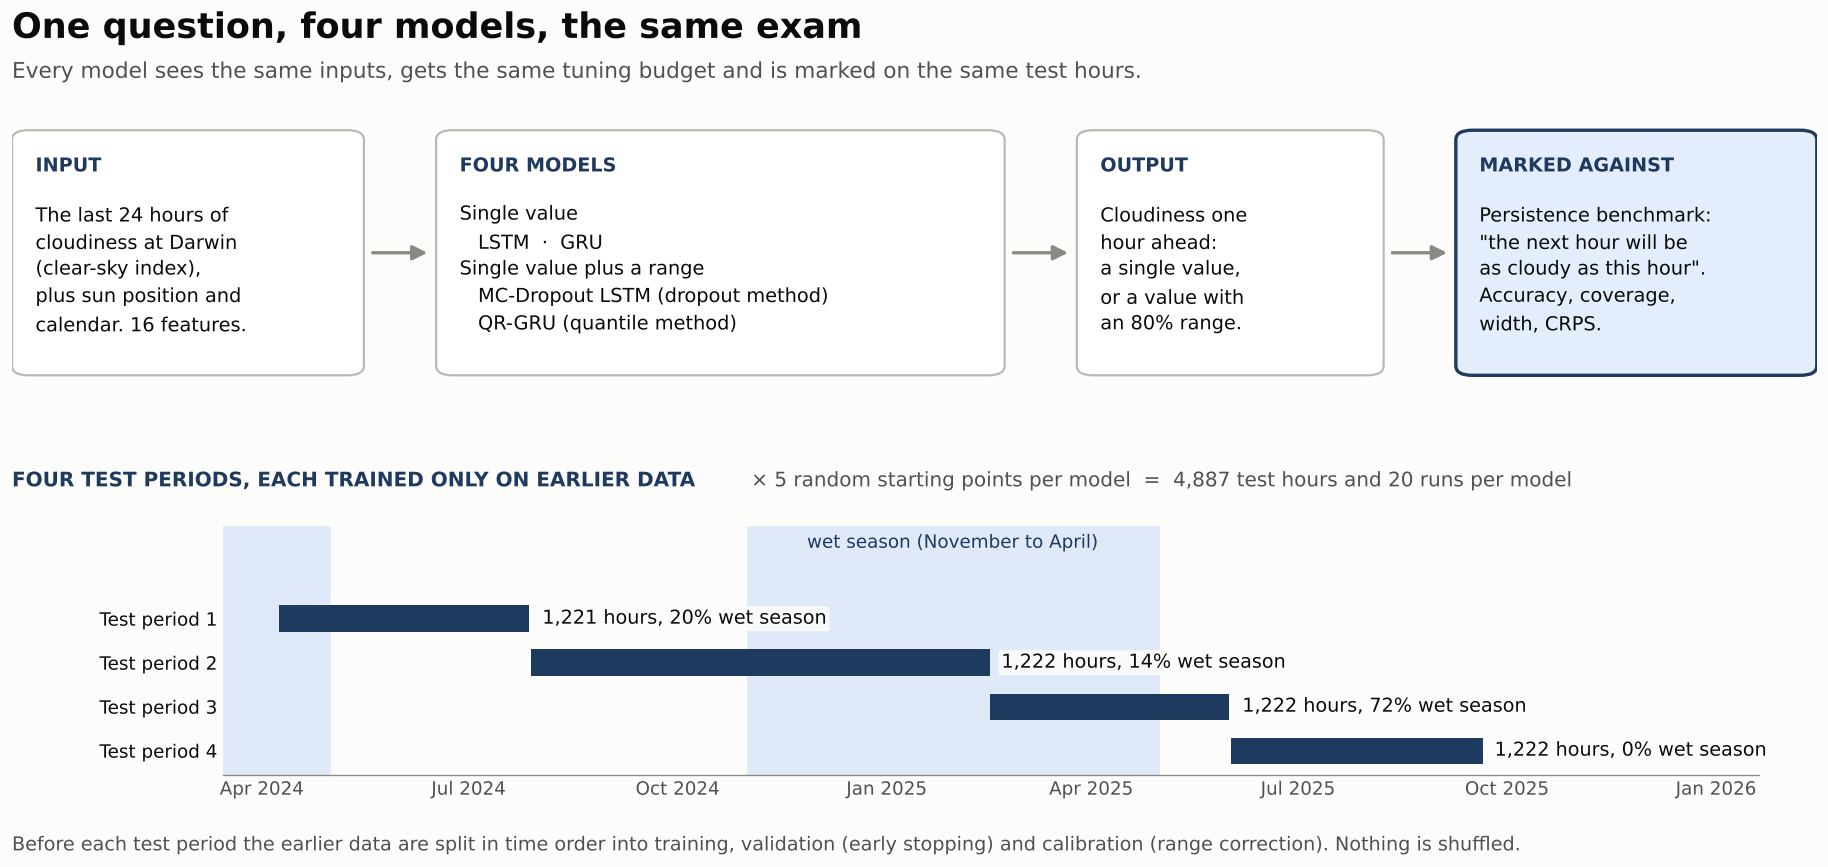

In [ ]:
# @title Figure V2: How the Four Models were Compared  {"display-mode":"form"}
assert "VIVA" in globals(), "Run the 'VIVA setup' cell above first."


def _viva_fig_design(V):
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib.patches import FancyBboxPatch
    np, pd, C, F = V.np, V.pd, V.C, V.FOLDS
    with plt.rc_context(V.RC):
        fig = plt.figure(figsize=(16, 7.4), dpi=120)
        fig.text(0.03, 0.94, "One question, four models, the same exam", fontsize=21, fontweight="bold", color=C["ink"])
        fig.text(0.03, 0.895, "Every model sees the same inputs, gets the same tuning budget and is marked on the same test hours.",
                 fontsize=13, color=C["ink2"])
        # ---- pipeline strip ----
        ax = fig.add_axes([0.03, 0.50, 0.94, 0.36]); ax.axis("off"); ax.set_xlim(0, 100); ax.set_ylim(0, 30)
        def card(x0, w, head, body, fc="#ffffff", ec=C["pale"], lw=1.3):
            ax.add_patch(FancyBboxPatch((x0, 5), w, 23, boxstyle="round,pad=0,rounding_size=0.9", fc=fc, ec=ec, lw=lw))
            ax.text(x0 + 1.3, 24.6, head, fontsize=11.5, fontweight="bold", color=C["navy"], va="center")
            ax.text(x0 + 1.3, 21.4, body, fontsize=11.6, color=C["ink"], va="top", linespacing=1.42)
        card(0, 19.5, "INPUT", "The last 24 hours of\ncloudiness at Darwin\n(clear-sky index),\nplus sun position and\ncalendar. 16 features.")
        card(23.5, 31.5, "FOUR MODELS", "Single value\n   LSTM  ·  GRU\nSingle value plus a range\n   MC-Dropout LSTM (dropout method)\n   QR-GRU (quantile method)")
        card(59, 17, "OUTPUT", "Cloudiness one\nhour ahead:\na single value,\nor a value with\nan 80% range.")
        card(80, 20, "MARKED AGAINST", "Persistence benchmark:\n\"the next hour will be\nas cloudy as this hour\".\nAccuracy, coverage,\nwidth, CRPS.", fc=C["wash_navy"], ec=C["navy"], lw=2)
        for xa, xb in ((19.5, 23.5), (55, 59), (76, 80)):
            ax.annotate("", xy=(xb - 0.3, 16.5), xytext=(xa + 0.3, 16.5),
                        arrowprops=dict(arrowstyle="-|>", color=C["muted"], lw=2, mutation_scale=18))
        # ---- timeline of the four test periods ----
        t = fig.add_axes([0.14, 0.11, 0.80, 0.28])
        t0, t1 = pd.Timestamp("2024-03-15"), pd.Timestamp("2026-01-20")
        for a, b_ in (("2024-03-15", "2024-05-01"), ("2024-11-01", "2025-05-01")):
            t.axvspan(pd.Timestamp(a), pd.Timestamp(b_), color="#dfe9f7", zorder=1)
        t.text(pd.Timestamp("2025-01-30"), 4.72, "wet season (November to April)", fontsize=11, color=C["navy"], ha="center", va="center")
        for _, r in F.iterrows():
            y = 4 - r.fold
            t.barh(y, (r.test_to - r.test_from).days, left=r.test_from, height=0.6, color=C["navy"], zorder=3)
            t.text(r.test_to + pd.Timedelta(days=5), y, f"{r.n_test:,} hours, {r.test_wet_pct:.0f}% wet season", fontsize=11.5,
                   va="center", color=C["ink"], zorder=4,
                   bbox=dict(boxstyle="round,pad=0.15", fc=C["surface"], ec="none", alpha=0.85))
        t.set_yticks([3, 2, 1, 0]); t.set_yticklabels([f"Test period {i}" for i in (1, 2, 3, 4)], fontsize=12, color=C["ink"])
        t.set_xlim(t0, t1); t.set_ylim(-0.55, 5.1)
        t.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10])); t.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        t.tick_params(length=0, labelsize=11); t.spines["left"].set_visible(False)
        fig.text(0.03, 0.435, "FOUR TEST PERIODS, EACH TRAINED ONLY ON EARLIER DATA", fontsize=12, fontweight="bold", color=C["navy"])
        fig.text(0.415, 0.435, f"× {V.FACTS['seeds']} random starting points per model  =  {V.FACTS['test_hours']:,} test hours and 20 runs per model",
                 fontsize=12, color=C["ink2"])
        fig.text(0.03, 0.025, "Before each test period the earlier data are split in time order into training, validation (early stopping) and "
                 "calibration (range correction). Nothing is shuffled.", fontsize=11.5, color=C["ink2"])
        plt.show()
    V.display(V.HTML("<div style='font-size:12px; opacity:.8; margin:2px 0 6px 0'>Figure V2. STATIC, copied from the design table printed by "
                     "Stage 14 R1 and from Stage 9.2 and Stage 10. Report Sections 4.2 to 4.5.</div>"))
    V.say("Weather differs between periods, so a single test period mostly measures that period's weather. Four periods and five random "
          "starts make the comparison a property of the models. The third period is 72% wet season and the fourth is entirely dry.")


VIVA.run(_viva_fig_design)

---

## **VIVA Section#4.5 What the Models Revealed: Three Results**

| | The question | The short answer |
|---|---|---|
| **Result 1** | Is any model more *accurate*? | All four beat the benchmark by 8 to 12%. The three best are statistically tied. |
| **Result 2** | Can any model's *range* be trusted? | Only QR-GRU's 80% range held near 80%, in both seasons. |
| **Result 3** | Where does the trusted range stop working? | During sudden cloud ramps, for every model. No simple operating rule emerged. |

### **Result 1 · Accuracy: a three-way tie**

**The question.** If one model were simply better, it should show here, in the typical size of its error.

**What to look at.** In Figure V3, each bar is a model's skill over persistence with its 95% confidence interval. Watch whether the bars overlap.

Model,"Typical error, RMSE (W/m²)",Error removed vs benchmark (skill),Ranked first in
"QR-GRU (range, quantile method)",87.2,+12.1% [10.6 to 13.6],65% of 20 runs
GRU (single value),88.0,+11.3% [9.3 to 13.2],25% of 20 runs
LSTM (single value),88.3,+11.0% [9.0 to 13.0],5% of 20 runs
"MC-Dropout LSTM (range, dropout method)",91.0,+8.2% [5.6 to 10.8],5% of 20 runs
Persistence (benchmark),99.2,0 (reference),–


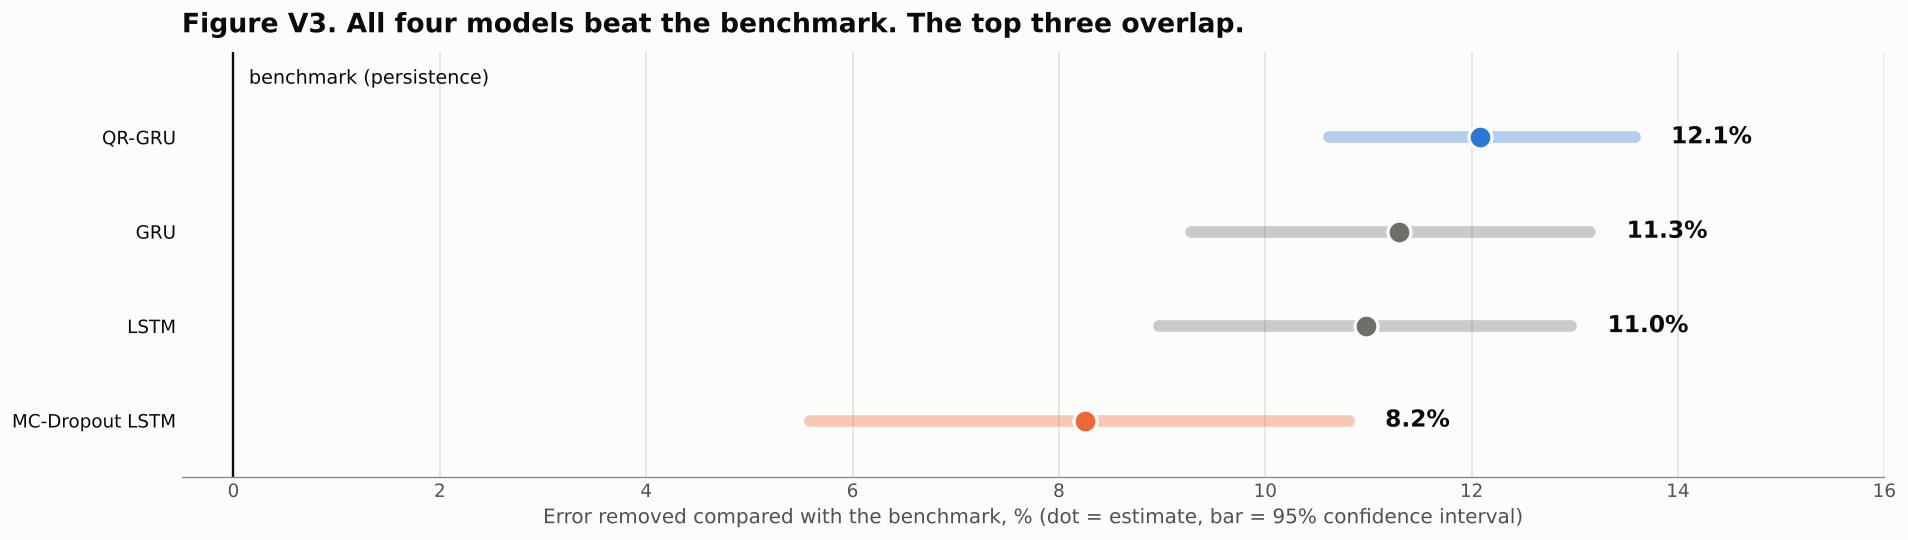

In [ ]:
# @title Result 1: Accuracy of the Single Value (Table V1, Figure V3) {"display-mode":"form"}
assert "VIVA" in globals(), "Run the 'VIVA setup' cell above first."


def _viva_res_accuracy(V):
    import matplotlib.pyplot as plt
    np, pd, C = V.np, V.pd, V.C
    lead = V.frame("R_LEADER").set_index("model")
    dm = V.frame("R_DM"); rank = V.frame("RANK_STAB")
    order = ["QR-GRU", "GRU", "LSTM", "MC-Dropout LSTM", "Persistence"]
    rows = []
    for m in order:
        r = lead.loc[m]
        rows.append({"Model": V.PLAIN[m], "Typical error, RMSE (W/m²)": f"{r['RMSE_Wm2']:.1f}",
                     "Error removed vs benchmark (skill)": "0 (reference)" if m == "Persistence" else
                     f"{r['skill_RMSE_%']:+.1f}%  [{r['skill_CI_lo']:.1f} to {r['skill_CI_hi']:.1f}]",
                     "Ranked first in": "–" if m == "Persistence" else f"{rank.loc[m, 'share_first']:.0f}% of 20 runs"})
    V.table(pd.DataFrame(rows), "Table V1. Accuracy one hour ahead at Darwin (95% confidence intervals in brackets)",
            V.src("R_LEADER", "RANK_STAB") + ". Report Table 6 and Section 5.2.",
            highlight=lambda r: r["Model"].startswith(("QR-GRU", "GRU", "LSTM")))

    four = order[:4]
    with plt.rc_context(V.RC):
        fig, ax = plt.subplots(figsize=(16, 4.6), dpi=120)
        y = np.arange(4)[::-1]
        for yi, m in zip(y, four):
            r = lead.loc[m]
            ax.plot([r["skill_CI_lo"], r["skill_CI_hi"]], [yi, yi], color=V.COLOR[m], lw=7, alpha=0.35, solid_capstyle="round", zorder=2)
            ax.scatter([r["skill_RMSE_%"]], [yi], s=190, color=V.COLOR[m], zorder=4, edgecolor=C["surface"], linewidth=2)
            ax.text(r["skill_CI_hi"] + 0.35, yi, f"{r['skill_RMSE_%']:.1f}%", va="center", fontsize=14, fontweight="bold", color=C["ink"])
        ax.axvline(0, color=C["ink"], lw=1.4)
        ax.text(0.15, 3.62, "benchmark (persistence)", fontsize=11.5, color=C["ink"], va="center")
        ax.set_yticks(y); ax.set_yticklabels(four, fontsize=13.5, color=C["ink"]); ax.set_ylim(-0.6, 3.9)
        ax.set_xlim(-0.5, 16); ax.set_xlabel("Error removed compared with the benchmark, % (dot = estimate, bar = 95% confidence interval)", fontsize=12)
        ax.xaxis.grid(True, color=C["grid"], lw=1); ax.set_axisbelow(True); ax.tick_params(length=0, labelsize=11)
        ax.spines["left"].set_visible(False)
        ax.set_title("Figure V3. All four models beat the benchmark. The top three overlap.", fontsize=16, loc="left", color=C["ink"], pad=12)
        fig.tight_layout(); plt.show()

    def hp(a, b):
        q = dm[(dm.loss == "SE") & (((dm.model_A == a) & (dm.model_B == b)) | ((dm.model_A == b) & (dm.model_B == a)))]
        return float(q.p_holm.iloc[0])
    V.display(V.HTML(f"<div style='font-size:12px; opacity:.8; margin:2px 0 6px 0'>Figure V3 source: {V.src('R_LEADER')}. Report Figure 7.</div>"))
    V.say(f"Every model removes between {lead.loc[four, 'skill_RMSE_%'].min():.0f}% and {lead.loc[four, 'skill_RMSE_%'].max():.0f}% of the benchmark's error, "
          "and every confidence interval sits above zero, so the gain is real. But QR-GRU, GRU and LSTM cannot be separated "
          f"(adjusted p = {hp('QR-GRU', 'GRU'):.2f}, {hp('QR-GRU', 'LSTM'):.2f} and {hp('GRU', 'LSTM'):.2f}). "
          "On accuracy alone there is no winner. The choice between LSTM and GRU made no measurable difference.")


VIVA.run(_viva_res_accuracy)

> **Takeaway from Result 1.** The single number is about equally good from three of the four models. If the study stopped here, it would say the architecture hardly matters.

### **Result 2 · Reliability: Only One Range Keeps its Promise**

**The question.** When a model says 80%, how often is the real outcome inside its range?

**What to look at.** In Figure V4 the dashed line is the 80% target. Blue is QR-GRU, orange is MC-Dropout. Read the wet-season pair first.

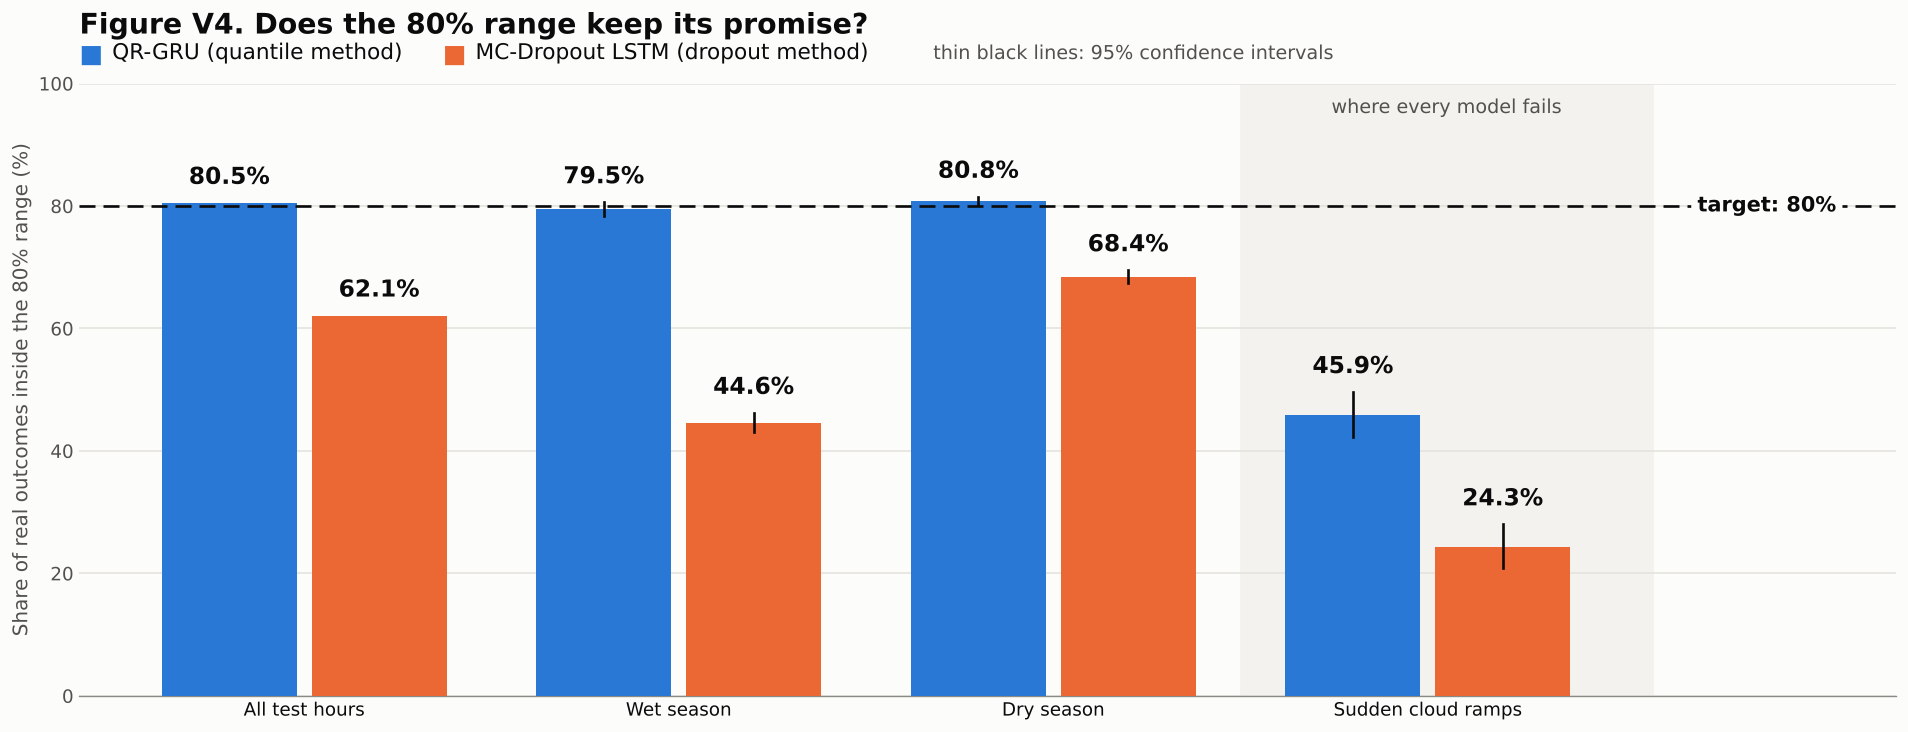

Model,Coverage of the 80% range,Average width (W/m²),After correction: coverage / width,Winkler score after correction (lower is better),"CRPS (W/m², lower is better)"
"QR-GRU (range, quantile method)",80.5%,175,81.3% / 179,253,35.6
"MC-Dropout LSTM (range, dropout method)",62.1%,136,80.6% / 252,345,46.6
HMC-LSTM (diagnostic only),90.5%,270,80.5% / 207,289,46.4
GRU (single value),no range,–,–,–,56.7
LSTM (single value),no range,–,–,–,57.7


In [ ]:
# @title Result 2: Reliability of the Range (Figure V4, Table V2) {"display-mode":"form"}
assert "VIVA" in globals(), "Run the 'VIVA setup' cell above first."


def _viva_res_reliability(V):
    import matplotlib.pyplot as plt
    np, pd, C = V.np, V.pd, V.C
    lead = V.frame("R_LEADER").set_index("model")
    sub = V.frame("SUBGROUP_R").set_index(["model", "subgroup"])
    groups = [("All test hours", None), ("Wet season", "wet season"), ("Dry season", "dry season"), ("Sudden cloud ramps", "ramp hours")]
    models = ["QR-GRU", "MC-Dropout LSTM"]
    with plt.rc_context(V.RC):
        fig, ax = plt.subplots(figsize=(16, 6.2), dpi=120)
        bw = 0.36
        for j, m in enumerate(models):
            xpos = np.arange(4) + (j - 0.5) * (bw + 0.04)
            for xp, (_, g) in zip(xpos, groups):
                v = 100 * (lead.loc[m, "PICP80_raw"] if g is None else sub.loc[(m, g), "PICP80_raw"])
                ax.bar(xp, v, width=bw, color=V.COLOR[m], zorder=3)
                top = v
                if g is not None:
                    lo, hi = 100 * sub.loc[(m, g), "PICP_CI_lo"], 100 * sub.loc[(m, g), "PICP_CI_hi"]
                    ax.plot([xp, xp], [lo, hi], color=C["ink"], lw=1.6, zorder=5); top = max(v, hi)
                ax.text(xp, top + 2.2, f"{v:.1f}%", ha="center", va="bottom", fontsize=14, fontweight="bold", color=C["ink"], zorder=6)
        ax.axhline(80, color=C["ink"], lw=1.6, ls=(0, (6, 3)), zorder=4)
        ax.text(3.72, 80, "target: 80%", fontsize=12.5, color=C["ink"], va="center", ha="left", fontweight="bold", zorder=7,
                bbox=dict(boxstyle="round,pad=0.3", fc=C["surface"], ec="none"))
        ax.axvspan(2.5, 3.6, color="#f3f2ee", zorder=0)
        ax.text(3.05, 96, "where every model fails", fontsize=11.5, color=C["ink2"], ha="center", va="center")
        ax.set_xticks(range(4)); ax.set_xticklabels([g for g, _ in groups], fontsize=14, color=C["ink"])
        ax.set_ylim(0, 100); ax.set_xlim(-0.6, 4.25); ax.set_yticks([0, 20, 40, 60, 80, 100])
        ax.set_ylabel("Share of real outcomes inside the 80% range (%)", fontsize=12)
        ax.yaxis.grid(True, color=C["grid"], lw=1); ax.set_axisbelow(True); ax.tick_params(length=0, labelsize=11)
        ax.spines["left"].set_visible(False)
        ax.set_title("Figure V4. Does the 80% range keep its promise?", fontsize=17, loc="left", color=C["ink"], pad=30)
        ax.text(0.0, 1.035, "■", transform=ax.transAxes, fontsize=15, color=C["qr"])
        ax.text(0.018, 1.04, "QR-GRU (quantile method)", transform=ax.transAxes, fontsize=13, color=C["ink"])
        ax.text(0.20, 1.035, "■", transform=ax.transAxes, fontsize=15, color=C["mc"])
        ax.text(0.218, 1.04, "MC-Dropout LSTM (dropout method)", transform=ax.transAxes, fontsize=13, color=C["ink"])
        ax.text(0.47, 1.04, "thin black lines: 95% confidence intervals", transform=ax.transAxes, fontsize=11.5, color=C["ink2"])
        fig.tight_layout(); plt.show()
    V.display(V.HTML(f"<div style='font-size:12px; opacity:.8; margin:2px 0 6px 0'>Figure V4 source: {V.src('R_LEADER', 'SUBGROUP_R')}. "
                     "Ranges as produced by each model, before any correction. Report Figures 8 and 9, Sections 5.3 and 5.4.</div>"))
    q, mc = lead.loc["QR-GRU"], lead.loc["MC-Dropout LSTM"]
    V.say(f"QR-GRU's 80% range contained the real outcome {100 * q['PICP80_raw']:.1f}% of the time overall, "
          f"{100 * sub.loc[('QR-GRU', 'wet season'), 'PICP80_raw']:.1f}% in the wet season and "
          f"{100 * sub.loc[('QR-GRU', 'dry season'), 'PICP80_raw']:.1f}% in the dry. MC-Dropout's range claimed 80% and delivered "
          f"{100 * mc['PICP80_raw']:.1f}%, falling to {100 * sub.loc[('MC-Dropout LSTM', 'wet season'), 'PICP80_raw']:.1f}% in the wet season, "
          "which is when an operator most needs it. The two models differ by about four percentage points in accuracy and by "
          "nearly twenty in reliability.")

    rows = []
    for m in ["QR-GRU", "MC-Dropout LSTM", "HMC-LSTM"]:
        r = lead.loc[m]
        rows.append({"Model": V.PLAIN[m], "Coverage of the 80% range": f"{100 * r['PICP80_raw']:.1f}%",
                     "Average width (W/m²)": f"{r['MIW_raw_Wm2']:.0f}",
                     "After correction: coverage / width": f"{100 * r['PICP80_conformal']:.1f}% / {r['MIW_conf_Wm2']:.0f}",
                     "Winkler score after correction (lower is better)": f"{r['Winkler_conf']:.0f}",
                     "CRPS (W/m², lower is better)": f"{r['CRPS_Wm2']:.1f}"})
    for m in ["GRU", "LSTM"]:
        rows.append({"Model": V.PLAIN[m], "Coverage of the 80% range": "no range", "Average width (W/m²)": "–",
                     "After correction: coverage / width": "–", "Winkler score after correction (lower is better)": "–",
                     "CRPS (W/m², lower is better)": f"{lead.loc[m, 'CRPS_Wm2']:.1f}"})
    V.table(pd.DataFrame(rows), "Table V2. Quality of the uncertainty estimate",
            V.src("R_LEADER") + ". Report Table 6 and Section 5.3.", highlight=lambda r: r["Model"].startswith("QR-GRU"),
            note=("<b>Reading the table.</b> MC-Dropout's range is narrow (" f"{mc['MIW_raw_Wm2']:.0f} W/m²) because it is overconfident. "
                  f"A statistical correction (conformal) can widen it until it covers 80%, but the width nearly doubles to {mc['MIW_conf_Wm2']:.0f} W/m², "
                  f"and its Winkler score ({mc['Winkler_conf']:.0f}) stays well behind QR-GRU's ({q['Winkler_conf']:.0f}). "
                  f"The diagnostic model adds a learned noise term to the same dropout network, and coverage moves from "
                  f"{100 * mc['PICP80_raw']:.0f}% to {100 * lead.loc['HMC-LSTM', 'PICP80_raw']:.0f}%. That points to the cause: dropout captures "
                  "doubt about the model, not the randomness of cloud."))


VIVA.run(_viva_res_reliability)

> **Takeaway from Result 2.** How uncertainty is modelled mattered far more than which recurrent cell was used. QR-GRU gave a trustworthy range at no cost in accuracy.

### **Result 3 · The Limits: Where the Range Stops Working**

**The question.** A finding is only useful if we know where it breaks. So the models were stress-tested on ramps, seasons, a seasonal input and a simple operating rule.

**What to look at.** Read Table V3 one row at a time. Each row is something an examiner might hope the models could do, and what they actually did.

In [ ]:
# @title Result 3: Where the Range Stops Working, and What was Not Found (Table V3) {"display-mode":"form"}
assert "VIVA" in globals(), "Run the 'VIVA setup' cell above first."


def _viva_res_limits(V):
    np, pd, F = V.np, V.pd, V.FACTS
    sub = V.frame("SUBGROUP_R").set_index(["model", "subgroup"])
    abl = V.frame("ABLATION")
    four = ["LSTM", "GRU", "MC-Dropout LSTM", "QR-GRU"]
    pen = {m: 100 * (sub.loc[(m, "ramp hours"), "RMSE_Wm2"] / sub.loc[(m, "non-ramp"), "RMSE_Wm2"] - 1) for m in four}
    n_r, n_n = sub.loc[("QR-GRU", "ramp hours"), "n_hour_runs"], sub.loc[("QR-GRU", "non-ramp"), "n_hour_runs"]
    flag = abl[(abl.loss == "SE") & (abl.subset == "all") & abl.contrast.str.startswith("binary")].set_index("model")
    none = [m for m in four if flag.loc[m, "verdict"] == "not distinguishable"]
    wet = [sub.loc[(m, "wet season"), "RMSE_Wm2"] for m in four]; dry = [sub.loc[(m, "dry season"), "RMSE_Wm2"] for m in four]
    rows = [
        ("Sudden cloud ramps", f"Hours where cloudiness changes sharply ({100 * n_r / (n_r + n_n):.0f}% of test hours)",
         f"Error rises by {min(pen.values()):.0f}% to {max(pen.values()):.0f}% in every model. QR-GRU's 80% range holds "
         f"{100 * sub.loc[('QR-GRU', 'ramp hours'), 'PICP80_raw']:.0f}% of the time, MC-Dropout's {100 * sub.loc[('MC-Dropout LSTM', 'ramp hours'), 'PICP80_raw']:.0f}%",
         "No model foresees a ramp. The range should not be relied on in these hours", V.src("SUBGROUP_R")),
        ("Wet season against dry season", "The same models, scored separately by season",
         f"Error is {min(wet):.0f} to {max(wet):.0f} W/m² in the wet season and {min(dry):.0f} to {max(dry):.0f} W/m² in the dry",
         "The weather, not the architecture, sets how good a one-hour forecast can be", V.src("SUBGROUP_R")),
        ("Telling the model the season", "A wet/dry input added to each model, tested with three matched versions",
         f"No measurable effect in {len(none)} of 4 models. MC-Dropout improves by {flag.loc['MC-Dropout LSTM', 'improvement_%']:.1f}%",
         "The recent hours already carry the season", V.src("ABLATION")),
        ("A simple operating rule", "Is there a range width below which the range can always be trusted?",
         f"A threshold appeared in {F['thr_share_qr']:.0f}% of the {F['thr_runs']} QR-GRU runs and in none of the MC-Dropout runs",
         "No stable width-based rule. A negative result", "STATIC, Stage 14 R5(e)"),
        ("Reserve sizing, on paper", "Reserve from the range against a fixed margin, at the same shortfall rate",
         f"QR-GRU needed {abs(F['reserve_median_qr']):.1f}% less in the median run, and was cheaper in {F['reserve_cheaper_qr']:.0f}% of runs",
         "A feasibility check only. Not operating guidance", "STATIC, Stage 14 R5(e)"),
    ]
    V.table(pd.DataFrame(rows, columns=["What was tested", "How", "Result", "What it means", "Source"]),
            "Table V3. The limits of the findings", "as listed in the last column. Report Sections 5.2, 5.4 and 5.5.",
            highlight=lambda r: r["What was tested"] == "Sudden cloud ramps", widths=["15%", "22%", "28%", "21%", "14%"])
    V.say("These are the results that keep the main finding honest. The reliable range is reliable on average and in both seasons, "
          "but not during sudden ramps, and the study did not find a rule or a consistent saving that an operator could apply directly.")


VIVA.run(_viva_res_limits)

What was tested,How,Result,What it means,Source
Sudden cloud ramps,Hours where cloudiness changes sharply (6% of test hours),"Error rises by 121% to 173% in every model. QR-GRU's 80% range holds 46% of the time, MC-Dropout's 24%",No model foresees a ramp. The range should not be relied on in these hours,"SNAPSHOT of the executed output (Stage 14, R5(b,c) subgroups)"
Wet season against dry season,"The same models, scored separately by season",Error is 118 to 123 W/m² in the wet season and 73 to 76 W/m² in the dry,"The weather, not the architecture, sets how good a one-hour forecast can be","SNAPSHOT of the executed output (Stage 14, R5(b,c) subgroups)"
Telling the model the season,"A wet/dry input added to each model, tested with three matched versions",No measurable effect in 3 of 4 models. MC-Dropout improves by 1.7%,The recent hours already carry the season,"SNAPSHOT of the executed output (Stage 14, R3 seasonal-conditioning arms)"
A simple operating rule,Is there a range width below which the range can always be trusted?,A threshold appeared in 50% of the 20 QR-GRU runs and in none of the MC-Dropout runs,No stable width-based rule. A negative result,"STATIC, Stage 14 R5(e)"
"Reserve sizing, on paper","Reserve from the range against a fixed margin, at the same shortfall rate","QR-GRU needed 3.0% less in the median run, and was cheaper in 60% of runs",A feasibility check only. Not operating guidance,"STATIC, Stage 14 R5(e)"


> **Takeaway from Result 3.** The reliable range is reliable on average and in both seasons, but not in the 6% of hours with sudden ramps, and no width-based operating rule was stable.

### **Checking the Differences are Real**

The best and third-best models differ by about 1 W/m² on an error of about 88. With weather this variable, a gap that small could be chance, so every claim had to pass two tests.

| Tool | Simple meaning | Detail |
|---|---|---|
| **Confidence intervals** | A gain is claimed only if the whole plausible range is above zero. | Moving-block bootstrap, 24-hour blocks, 2,000 resamples within each test period, on losses averaged over five seeds. |
| **Diebold-Mariano test** | Are one model's hourly errors consistently smaller than another's? | Paired test with Newey-West variance, because neighbouring hours are correlated. |
| **Holm correction** | Guards against finding a "winner" by chance across many pairs. | Step-down adjustment of p-values within each loss. |

In [ ]:
# @title Statistical Evaluation: Are the Differences Real? (Table V4) {"display-mode":"form"}
assert "VIVA" in globals(), "Run the 'VIVA setup' cell above first."


def _viva_res_stats(V):
    np, pd, F = V.np, V.pd, V.FACTS
    dm = V.frame("R_DM")
    four = ["QR-GRU", "GRU", "LSTM", "MC-Dropout LSTM"]
    def pf(p):
        return "< 0.001" if p < 0.0005 else f"{p:.3f}"
    rows = []
    for i, a in enumerate(four):
        for b in four[i + 1:]:
            out = {"Pair": f"{a}  vs  {b}"}
            for loss, lab in (("SE", "accuracy"), ("CRPS", "whole forecast")):
                q = dm[(dm.loss == loss) & (((dm.model_A == a) & (dm.model_B == b)) | ((dm.model_A == b) & (dm.model_B == a)))].iloc[0]
                sig = str(q["significant_holm_5%"]).strip().lower() == "true"
                out[f"Adjusted p, {lab}"] = pf(float(q.p_holm))
                out[f"Verdict, {lab}"] = f"{q.lower_loss} is better" if sig else "no real difference"
            rows.append(out)
    V.table(pd.DataFrame(rows), "Table V4. Model against model: Diebold-Mariano test, Newey-West variance, Holm-adjusted p",
            V.src("R_DM") + ". Report Section 5.2 and Appendix Table 8.",
            highlight=lambda r: r["Verdict, accuracy"] == "no real difference",
            note=("<b>Reading the table.</b> The accuracy columns test the single value (squared error). The whole-forecast columns test "
                  "CRPS, which also scores the range. Highlighted rows are the three-way tie on accuracy. On the whole forecast every "
                  "pair differs, and QR-GRU is better than each of the other three."))
    V.table(pd.DataFrame([("Without correction (errors in neighbouring hours treated as unrelated)", f"{F['dm_naive_p']:.3f}", "Looks significant at 5%"),
                          ("With Newey-West correction (the test used in this study)", f"{F['dm_nw_p']:.3f}", "Not significant")],
                         columns=["LSTM vs QR-GRU, accuracy", "p-value", "Conclusion"]),
            "Table V5. Why the choice of test mattered", "STATIC, Stage 14.1. Report Section 5.2 and Appendix Table 8.")
    V.say("A difference is reported as a finding only if its 95% confidence interval excludes zero and its adjusted p-value is below 0.05. "
          "Under that rule the three best models are tied on accuracy, MC-Dropout is less accurate than all three, and QR-GRU gives the "
          "best overall forecast. One comparison would have been a false positive had the simpler test been used.")


VIVA.run(_viva_res_stats)

Pair,"Adjusted p, accuracy","Verdict, accuracy","Adjusted p, whole forecast","Verdict, whole forecast"
QR-GRU vs GRU,0.267,no real difference,< 0.001,QR-GRU is better
QR-GRU vs LSTM,0.163,no real difference,< 0.001,QR-GRU is better
QR-GRU vs MC-Dropout LSTM,< 0.001,QR-GRU is better,< 0.001,QR-GRU is better
GRU vs LSTM,0.267,no real difference,< 0.001,GRU is better
GRU vs MC-Dropout LSTM,< 0.001,GRU is better,< 0.001,MC-Dropout LSTM is better
LSTM vs MC-Dropout LSTM,0.003,LSTM is better,< 0.001,MC-Dropout LSTM is better


"LSTM vs QR-GRU, accuracy",p-value,Conclusion
Without correction (errors in neighbouring hours treated as unrelated),0.040,Looks significant at 5%
With Newey-West correction (the test used in this study),0.054,Not significant


---

# **VIVA Section#5 · CONCLUSION**

## **Back to the 80%**

The talk opened with a model that said "80% sure" and was right 45% of the time in the wet season. That model was not badly tuned and not much less accurate than the others. It was measuring the wrong kind of uncertainty: its doubt about itself, not the randomness of tropical cloud. The quantile model learned that randomness directly, and its 80% meant 80%.

**What the evidence supports, and what it does not**

| The results show | The results do not show |
|---|---|
| At Darwin, one hour ahead, a deep-learning model can give an 80% range that holds in both seasons, at no cost in accuracy. | That this holds at other tropical sites. Applied elsewhere without recalibration, coverage ranged from 0.26 to 0.89. |
| The uncertainty method mattered far more than the choice between LSTM and GRU. | That QR-GRU is more *accurate* than GRU or LSTM. The three are tied. |
| Dropout-based ranges are too narrow in convective weather, and the missing part is the randomness of cloud. | That any model can foresee a sudden ramp. Coverage fell to 46% in those hours. |
| A reliable range is achievable as an input to reserve decisions. | That reserves were, or can be, reduced in operation. No reserve system was built, and Darwin's target was sunlight, not PV power. |

**Contributions**

| Type | Contribution |
|---|---|
| **Methodological** | One protocol for single-value and range-producing networks: equal tuning budget, 4 test periods × 5 seeds, confidence intervals and corrected significance tests on every comparison, timestamps verified against solar noon. |
| **Empirical** | Tropical evidence that the quantile model is reliable in both seasons and the dropout model is not, with a diagnostic model that points to the cause. A measured, not assumed, irradiance-to-PV relationship. |
| **Practical** | Outside ramp hours, a quantile-based range is a credible input for sizing reserve at this site, provided it is recalibrated at each new site. Users of the public Darwin files should check the clock against the sun. |

<sub>STATIC. Report Sections 6.1 to 6.5 and 7; notebook Stages 15 and 16.</sub>

## **Limitations and Next steps**

| Limitation | What it means | Next step |
|---|---|---|
| One training site, Darwin | The findings are Darwin-specific until repeated at other tropical ground sites. | Repeat at another tropical station. |
| Sunlight forecast, not power | PV skill at Darwin is inferred. The proxy test used an arid site, Alice Springs. | Validate against a real tropical PV plant. |
| Hourly resolution | Ramps inside the hour are averaged out, so the ramp problem is likely worse for a real plant. | Repeat sub-hourly with the one-second data. |
| Past sunlight only | No model can see cloud arriving, which is why all fail in ramps. | Add sky-camera or satellite inputs, and adaptive calibration. |
| Test periods use the five-minute export | The two sources agree closely, but a sensor change after 2023 cannot be ruled out. | Re-test when more one-second data are released. |
| Seasonal comparisons not corrected for multiple testing | The one positive seasonal effect (MC-Dropout, +1.7%) should be read with caution. | Pre-register the seasonal contrasts. |
| Planned Singapore monsoon test not done | No model was trained at an equatorial site. | Train at an equatorial ground site. |

<sub>STATIC. Report Sections 6.4 and 7; notebook Stage 16.2.</sub>

## **Final Takeaway**

1. **The question.** Can deep-learning solar forecasts for a tropical site come with an uncertainty range that can be trusted?
2. **Why it matters.** Reserve is committed an hour ahead, and tropical cloud makes a single number a weak basis for that decision.
3. **What I did.** Compared four networks on 4,887 test hours at Darwin, across four test periods and five seeds, scoring accuracy and reliability separately, after fixing a 30-minute clock error in the public data.
4. **What I found.** All four were similarly accurate. Only the quantile model's 80% range held, in the wet season and the dry. No model's range held during sudden ramps.
5. **What it means.** How uncertainty is modelled matters more than which recurrent network is used. A reliable range for the tropics is achievable, within limits that are now measured.

> ### **Three models forecast Darwin's sunlight equally well. Only one of them could be trusted when it said how wrong it might be.**

<sub>STATIC. Report Abstract and Section 7.</sub>

In [ ]:
# @title Backup Tables: Timestamps, Longer Horizons, PV Proxy, Other Climates {"display-mode":"form"}
assert "VIVA" in globals(), "Run the 'VIVA setup' cell above first."


def _viva_backup(V):
    np, pd, F = V.np, V.pd, V.FACTS
    cmp3, inv = V.frame("INV_CMP3"), V.frame("INV_SUMMARY")
    cols = [("initial", "Clock in the file, sun at start of hour"), ("partial", "Clock in the file, sun at mid-hour"),
            ("corrected", "UTC + 9:30, sun at mid-hour (used)")]
    rows = [["Hours removed as physically impossible"] + [f"{cmp3.loc['non-physical removed (h)', k]:.0f}" for k, _ in cols],
            ["Benchmark error, persistence RMSE (W/m²)"] + [f"{inv.loc[(k, 'Persistence'), 'RMSE']:.1f}" for k, _ in cols],
            ["QR-GRU skill against the benchmark"] + [f"{inv.loc[(k, 'QR-GRU'), 'skill']:+.1f}%" for k, _ in cols],
            ["GRU skill against the benchmark"] + [f"{inv.loc[(k, 'GRU'), 'skill']:+.1f}%" for k, _ in cols]]
    V.table(pd.DataFrame(rows, columns=["Measure"] + [c for _, c in cols]),
            "Table B1. Data integrity: the local clock in the Darwin files is 30 minutes behind Darwin time",
            V.src("INV_CMP3", "INV_SUMMARY") + ". Report Table 5 and Section 5.1.",
            note=(f"Physical check on the ten clearest days of July 2022: the measured curve peaks {abs(F['noon_local_min']):.0f} minutes before solar noon "
                  f"on the file's local clock and {abs(F['noon_acst_min']):.1f} minutes before it on UTC + 9:30 (STATIC, Stage 5.4). The controlled experiment "
                  "is small (two models, two seeds, an early untuned configuration) and is a demonstration, not a headline result."))

    hz = V.frame("HORIZON_R"); g = hz[hz.model == "GRU"].set_index("horizon_h")
    V.table(pd.DataFrame([{"Hours ahead": f"{h}", "Strongest simple benchmark": g.loc[h, "best_naive"],
                           "GRU skill against persistence": f"{g.loc[h, 'skill_vs_persistence_%']:.1f}%",
                           "GRU skill against the strongest benchmark": f"{g.loc[h, 'skill_vs_best_naive_%']:.1f}%"} for h in g.index]),
            "Table B2. Longer horizons: the benchmark decides how good a model looks",
            V.src("HORIZON_R") + ". Report Section 5.6.")

    V.table(pd.DataFrame([("LSTM", "46.0%", "52.4%", "6.4"), ("GRU", "45.5%", "53.4%", "7.8"), ("QR-GRU", "47.8%", "55.7%", "7.9"),
                          ("MC-Dropout LSTM", "38.5%", "48.4%", "9.9 (within seed noise)")],
                         columns=["Model", "Skill on sunlight (irradiance)", "Skill on measured PV output", "Gap (points)"]),
            "Table B3. Is sunlight a fair stand-in for PV power? Alice Springs, 936 matched test hours",
            "STATIC, Stage 13.4. Report Section 5.7 and Figure 11.",
            note="Measured PV was easier to forecast than sunlight at this arid site. PV skill at Darwin is inferred, not measured.")

    tr = [("Alice Springs (arid)", "22.1%", "23.5%", "0.52"), ("Tennant Creek (semi-arid)", "24.2%", "26.4%", "0.64"),
          ("Yulara (arid)", "19.2%", "19.4%", "0.26"), ("Petrolina, Brazil (semi-arid)", "18.6%", "20.9%", "0.80"),
          ("Gan, Maldives (equatorial)", "23.7%", "26.0%", "0.77"), ("South Florida (satellite-derived)", "32.0% (GRU)", "34.7%", "0.71"),
          ("Singapore (equatorial, satellite-derived)", "18.1%", "16.0%", "0.89"), ("Hong Kong (humid subtropical)", "29.3%", "28.9%", "0.47")]
    V.table(pd.DataFrame(tr, columns=["Site", "Darwin-trained model, normalised error", "Local persistence, normalised error",
                                      "QR-GRU coverage of the 80% range"]),
            "Table B4. The Darwin models applied unchanged to eight other sites",
            "STATIC, Stage 15 consolidated findings (cross-climate block) and Stage 13.5. Report Section 5.8.",
            highlight=lambda r: r["Site"].startswith(("Singapore", "Hong Kong")),
            note=("Accuracy carried over to six of eight sites (the two highlighted sites are the exceptions). Reliability did not: coverage ranged "
                  f"from {F['transfer_picp'][0]:.2f} to {F['transfer_picp'][1]:.2f}, so the range must be recalibrated at each new site."))


VIVA.run(_viva_backup)

Measure,"Clock in the file, sun at start of hour","Clock in the file, sun at mid-hour","UTC + 9:30, sun at mid-hour (used)"
Hours removed as physically impossible,717,457,80
"Benchmark error, persistence RMSE (W/m²)",146.7,129.3,95.7
QR-GRU skill against the benchmark,+16.6%,-8.3%,-36.0%
GRU skill against the benchmark,+5.1%,-18.9%,-50.1%


Hours ahead,Strongest simple benchmark,GRU skill against persistence,GRU skill against the strongest benchmark
1,Persistence,12.0%,12.0%
2,Climatology,31.7%,18.8%
3,Climatology,49.6%,12.8%
6,Climatology,73.9%,8.7%


Model,Skill on sunlight (irradiance),Skill on measured PV output,Gap (points)
LSTM,46.0%,52.4%,6.4
GRU,45.5%,53.4%,7.8
QR-GRU,47.8%,55.7%,7.9
MC-Dropout LSTM,38.5%,48.4%,9.9 (within seed noise)


Site,"Darwin-trained model, normalised error","Local persistence, normalised error",QR-GRU coverage of the 80% range
Alice Springs (arid),22.1%,23.5%,0.52
Tennant Creek (semi-arid),24.2%,26.4%,0.64
Yulara (arid),19.2%,19.4%,0.26
"Petrolina, Brazil (semi-arid)",18.6%,20.9%,0.80
"Gan, Maldives (equatorial)",23.7%,26.0%,0.77
South Florida (satellite-derived),32.0% (GRU),34.7%,0.71
"Singapore (equatorial, satellite-derived)",18.1%,16.0%,0.89
Hong Kong (humid subtropical),29.3%,28.9%,0.47


---

# **End of the VIVA Section**

**The research notebook starts below. Its cells, code and outputs are exactly as they were.** The headings that begin with "PART" were added only to help navigation; they contain no code.

# **START OF RESEARCH**
# **PART A · Research Background, Objectives and Notebook Setup**
> *Navigation header added for the VIVA. It covers the title cell, Section 0 (project overview), Section 1 (pipeline) and the setup cells below. No original cell was changed.*

# **Probabilistic Solar Power Forecasting Under Tropical Climate Uncertainty**
### A comparative study of deterministic vs uncertainty-quantifying deep learning, developed as an evidence-driven research investigation

**Farah Dina Bte Esa Mahmud Ariff**
* MSc Data Science
* University of Hertfordshire (PSB Academy)
* 7FTC2001

---

## **Research Stage#0. Project Overview**

**Research gap.** Deep-learning solar forecasting is still reported mostly with point metrics (RMSE, MAE) and is benchmarked mainly on temperate and arid data. Four gaps follow:

* **Methodological:** deterministic and uncertainty-quantifying architectures are rarely compared under one protocol with proper scoring rules and interval diagnostics.
* **Contextual:** tropical wet/dry regimes are largely untested.
* **Empirical:** the cost of using irradiance as a proxy for PV output is assumed rather than measured.
* **Practical:** probabilistic forecasts are seldom turned into operating rules.

**Research question.** _Which deep learning architecture — deterministic (LSTM, GRU) or probabilistic (MC-Dropout LSTM, Quantile Regression GRU) — produces the most accurate and best-calibrated solar irradiance forecasts for tropical climates under wet/dry seasonal conditioning?_

| Objective | What must be demonstrated |
|---|---|
| **O1** | Accuracy and skill against smart persistence; matched irradiance-vs-PV proxy test at Alice Springs |
| **O2** | Calibration (CRPS, pinball, PICP, MIW), and whether uncertainty quantification costs accuracy under wet-season variability |
| **O3** | Effect of wet/dry conditioning; behaviour during ramp events |
| **O4** | Decision-support thresholds: PICP at nominal and MIW ≤ X |
| **O5** | Cross-climate transfer (PDM Objective 8) |

**Data.**

* **Primary:** Darwin, NT Class A / DKASC 1-second reference cells (tropical savanna, Köppen Aw).
* **Proxy site:** Alice Springs, irradiance plus measured PV.
* **Zero-shot evaluation sites:** Tennant Creek, Yulara, Singapore (satellite), Gan (Maldives), Petrolina (BSRN), Hong Kong and South Florida (NSRDB).

**How to read this notebook.** It is a single, self-contained investigation. Every stage follows the same chain, and the **output of one stage is the evidence that decides the next**:

**Analysis → Finding → Problem / risk → Decision rule → Modification → Re-analysis → Before vs after → Research implication**

Where a methodological change was made during the project, both states are generated **from the same raw data inside this notebook**, so the effect of the change is visible rather than asserted.

## **Research Stage#1. Research-Oriented Data Pipeline and Decision Framework**

```text
Raw files ─► Stage 2 Inventory ─► Stage 3 Audit + decision rule ─► finding: two clocks in every DKASC file
   └─► Stage 4 Two-basis ingestion ─► Stage 5 Temporal integrity (initial reading → finding → rule 1 → re-test
       → finding → rule 2 → physical proof → before/after → effect on models)
   └─► Stage 6 Production ingestion + validation gate (corrected rules, all sites)
   └─► Stage 7 Cleaning, k_t, features ─► Stage 8 EDA ─► Stage 9 Screening, supervised design, leakage control
   └─► Stage 10 Models, metrics, baselines ─► Stage 11 Configuration evidence (lookback study → equal-budget tuning)
   └─► Stage 12 Last-origin modelling, calibration (initial vs corrected calibration rule), diagnostics
   └─► Stage 13 Subgroups, ramps, proxy (initial vs corrected target), transfer, decision support
   └─► Stage 14 Robust evaluation (rolling origin × seeds; naive vs HAC test; confounded vs valid ablation)
   └─► Stage 15 Findings: research question → evidence → answer ─► Stage 16 Gap, contribution, limits, conclusions
```

**Decision-Rule Template used Throughout.** Each rule states:

* **Trigger:** what output prompted it;
* **Evidence:** the table or figure;
* **Rule:** what is done;
* **Why it is appropriate;**
* **Effect:** what changed;
* **Validation:** how the change was checked.

**Runtime.** Use a Colab **GPU** runtime. `CFG.MODE` selects the scale:

| Mode | Purpose | Approximate runtime |
|---|---|---|
| `SMOKE` | pipeline check | minutes |
| `FAST` | 3 folds × 3 seeds | about 40% of FULL |
| `FULL` | 4 folds × 5 seeds | about 5 h |

Every expensive unit is cached on Drive as it finishes, so an interrupted run resumes where it stopped.

### **Setup — Configuration**

**What.** All settings live in one `CFG` object: paths, sites, the QC thresholds, the split fractions, the evaluation protocol and the tuning grid.
**Why.** Every later decision rule refers to a named setting, so a reader can audit a threshold without searching the code.

In [ ]:
import os, sys, re, gc, json, math, time, random, hashlib, zipfile, warnings, textwrap
from pathlib import Path
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

warnings.filterwarnings("ignore")
pd.set_option("display.width", 190)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 9,
    "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
    "axes.spines.right": False, "figure.autolayout": True,
})

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")


class CFG:
    # ---- environment -------------------------------------------------------
    # Environment variables exist only so the identical notebook can be executed
    # headless in a test harness; on Colab the defaults below apply.
    MODE = os.environ.get("TROPICALPV_MODE", "FULL")      # "SMOKE" | "FAST" | "FULL"
    SEED = 42

    # Root that CONTAINS the Data_* (or legacy Data-*) folders. If the folders are
    # not found here, Part 1 searches My Drive and reports where they actually are.
    DRIVE_ROOT = os.environ.get("TROPICALPV_ROOT", "/content/drive/MyDrive")
    ARTIFACT_DIRNAME = "_tropicalpv_artifacts"

    # ---- dataset scope (an intermediate pipeline) -------------------------------------------------
    # "CORE"     : the four roles of the original design only
    #              (Darwin target, Alice proxy, Singapore equatorial, NSRDB-Florida if present).
    # "EXTENDED" : CORE + the additional tropical/equatorial ground and satellite sites from
    #              the Tropical PV Dataset Assessment, used ONLY as zero-shot cross-climate
    #              evaluation sites (Part 12) and in EDA. Training is still Darwin-only.
    SITE_SET = "EXTENDED"

    # ---- Darwin record ------------------------------------------------------
    # "PROPOSAL"  : the 2021-2023 1-s files only (12,488 h, the sample stated in the proposal).
    # "EXTENDED"  : additionally fill hours NOT covered by the 1-s files from the Darwin 1-min
    #               export of the same station (NT Class A 7127), IF Part 3 shows the two streams
    #               agree on their overlapping hours (see DARWIN_CONSISTENCY). Otherwise the run
    #               falls back to "PROPOSAL" automatically and records why.
    DARWIN_RECORD = "EXTENDED"
    DARWIN_CONSISTENCY = dict(max_abs_bias_pct=2.0, min_r2=0.99, min_overlap_h=200)

    # ---- Singapore source priority (first available source with >= SG_MIN_DAYS is primary)
    SINGAPORE_PRIORITY = ["NSRDB Himawari PSM v3", "NASA POWER hourly", "Open-Meteo Himawari-9"]
    SG_MIN_DAYS = 365             # a source shorter than this cannot be the primary equatorial arm

    # ---- timing gate ---------------------------------------------------------
    # Clear-day diurnal lag (Part 3A) must be within this many minutes at the PRIMARY site,
    # otherwise the run stops: the initial pipeline->an intermediate pipeline showed a ~30 min shift changes the headline result.
    TIMING_GATE_MIN = 10.0
    TIMING_GATE_ENFORCE = True    # set False ONLY to inspect a failing run; results then invalid
    CLEAR_DAY_KT = 0.75           # daily sum(GHI)/sum(GHI_cs) defining a "clear day"
    PRIMARY_SITE = "DARWIN"       # the run stops if this site fails to load; never silently replaced
    DARWIN_YEARS = (2021, 2022, 2023)   # unchanged from the initial pipeline

    # ---- timing convention for solar geometry (an intermediate pipeline correctness fix) ------------
    # "sample_centre"  : geometry evaluated at the mean sample time inside each hourly bin
    #                    (the time the hourly mean actually represents).  Default.
    # "interval_start" : the initial pipeline behaviour — geometry at HH:00 although GHI is the HH:00-HH:59 mean.
    #                    Kept ONLY so the the initial pipeline numbers can be reproduced for comparison.
    GEOMETRY_TIMING = "sample_centre"
    TIMING_WARN_MIN, TIMING_FAIL_MIN = 45, 120   # diurnal-alignment thresholds (minutes)

    # ---- ingestion ---------------------------------------------------------
    CHUNK_ROWS = 400_000          # streaming chunk size; controls peak RAM
    TARGET_FREQ = "h"             # modelling resolution

    # ---- physics / QC ------------------------------------------------------
    GHI_MAX = 1400.0              # W/m^2 physical ceiling
    NEG_TOLERANCE = -10.0         # night-time sensor offset tolerated then zeroed
    KT_MAX = 1.30                 # clear-sky index ceiling (cloud enhancement)
    DAYLIGHT_CS_MIN = 20.0        # W/m^2 clear-sky threshold defining "daylight"
    MAX_INTERP_GAP_H = 3          # gaps <= this are interpolated; longer are left NaN

    # ---- supervised problem -------------------------------------------------
    LOOKBACK = 24                 # the MAXIMUM window. Every sample is built with 24 h so the
                                  # sample set is identical for every model; a model tuned to a
                                  # shorter lookback crops its input internally (Part 7).
    HORIZON = 1                   # hours ahead (t+1)
    RAMP_KT_THRESHOLD = 0.35      # |d(kt)/dt| defining a ramp event
    # four-way chronological split. VAL drives early stopping and model selection;
    # CAL is used ONLY for the conformal correction (an intermediate pipeline reused VAL, breaking the separation).
    TRAIN_FRAC, VAL_FRAC, CAL_FRAC = 0.60, 0.125, 0.125   # remainder (0.15) = TEST

    # ---- robust evaluation protocol (Part R) ----------------------------------
    N_FOLDS = 4                   # rolling-origin (expanding window) test blocks
    FOLD_SPAN = 0.40              # share of windows (the most recent) divided into test blocks
    SEEDS = [42, 7, 2024, 11, 99]
    HZ_SEEDS = 2                  # seeds per model in the horizon sweep (cost control)
    ABL_SEEDS = 3                 # seeds per model in the O3 ablation
    BOOT_B = 2000                 # block-bootstrap replicates
    BOOT_BLOCK_H = 24             # block length (hours) for the moving-block bootstrap
    HORIZONS = [1, 2, 3, 6]
    INCLUDE_HETERO = True         # heteroscedastic MC-Dropout arm (epistemic + aleatoric)
    EXOG_MIN_COVERAGE = 0.60      # Darwin met coverage needed to run the exogenous-covariate arm

    # ---- equal-budget hyper-parameter selection (Part 8C) -----------------------
    TUNE_GRID = dict(lookback=[6, 12, 24], units=[32, 64], lr=[1e-3, 3e-4])
    LR = 1e-3                     # default learning rate (overridden per model by Part 8C)

    # ---- models -------------------------------------------------------------
    UNITS = 64
    DROPOUT = 0.20
    EPOCHS = 60
    BATCH = 128
    PATIENCE = 8
    MC_PASSES = 50
    QUANTILES = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
    PI_LOW, PI_HIGH = 0.10, 0.90  # headline 80% prediction interval

    # ---- housekeeping --------------------------------------------------------
    FORCE_REBUILD = False         # True = ignore existing checkpoints
    MAX_ROWS_PER_FILE = None      # set by SMOKE


if CFG.MODE == "SMOKE":
    CFG.EPOCHS, CFG.PATIENCE, CFG.MC_PASSES = 3, 2, 10
    CFG.MAX_ROWS_PER_FILE = 300_000
    CFG.SEEDS, CFG.N_FOLDS, CFG.BOOT_B, CFG.HZ_SEEDS, CFG.ABL_SEEDS = [42, 7], 2, 200, 1, 1
    CFG.TUNE_GRID = dict(lookback=[12, 24], units=[32], lr=[1e-3])
    CFG.HORIZONS = [1, 3]
elif CFG.MODE == "FAST":          # same protocol, fewer replicates (~40% of FULL runtime)
    CFG.SEEDS, CFG.N_FOLDS, CFG.HZ_SEEDS, CFG.ABL_SEEDS = [42, 7, 2024], 3, 1, 2
    CFG.TUNE_GRID = dict(lookback=[6, 12, 24], units=[32, 64], lr=[1e-3])

# ---- seeds: every stochastic library, set once here --------------------------
os.environ["PYTHONHASHSEED"] = str(CFG.SEED)
random.seed(CFG.SEED)
np.random.seed(CFG.SEED)

# ---- Drive mount (silently skipped when not on Colab) -----------------------
if IN_COLAB:
    try:
        from google.colab import drive
        if not os.path.ismount("/content/drive"):
            drive.mount("/content/drive")
    except Exception as e:                                   # pragma: no cover
        print(f"[warn] Drive mount skipped: {e}")

DATA_PREFIXES = ("data_", "data-")          # an intermediate pipeline: new Drive layout uses "Data_", the initial pipeline used "Data-"


def is_data_dir(p: Path) -> bool:
    return p.is_dir() and p.name.lower().startswith(DATA_PREFIXES)


def find_data_root(declared: str) -> Path:
    """Locate the folder that CONTAINS the Data_* / Data-* directories.

    A wrong DRIVE_ROOT is the single most common first-run failure, and it
    surfaces later as a confusing 'no site loaded' error. This resolves it up
    front: the declared root is used if it holds any Data folder, otherwise the
    usual Drive locations are searched (shallowly) for one.
    """
    def holds_data(r: Path) -> bool:
        try:
            return r.exists() and any(is_data_dir(c) for c in r.iterdir())
        except (PermissionError, OSError):
            return False

    p = Path(declared)
    if holds_data(p):
        return p
    for r in [Path("/content/drive/MyDrive"), Path("/content/drive/My Drive"),
              Path("/content"), Path.cwd()]:
        if holds_data(r):
            print(f"[warn] data root auto-detected: {r}")
            return r
        try:
            for depth1 in sorted(c for c in r.iterdir() if c.is_dir())[:200]:
                if holds_data(depth1):
                    print(f"[warn] data root auto-detected: {depth1}")
                    return depth1
        except (PermissionError, OSError, FileNotFoundError):
            continue
    return p


ROOT = Path(CFG.DRIVE_ROOT)
ART = ROOT / CFG.ARTIFACT_DIRNAME
FIGDIR = ART / "figures"

# NOTE: directories are deliberately NOT created here. Creating them before the
# data root is verified would write real folders onto the local VM disk at
# /content/drive/... whenever Drive is not mounted, and Colab then refuses to
# mount Drive at all ("Mountpoint must not already contain files"). Creation is
# deferred to Part 1, after the root has been confirmed to hold the data.

DRIVE_MOUNTED = (not IN_COLAB) or os.path.ismount("/content/drive") \
    or Path("/content/drive/MyDrive").exists()
if not DRIVE_MOUNTED:
    print("\n  !! Google Drive is NOT mounted. Run drive.mount('/content/drive'),\n"
          "     complete the authorisation prompt, then re-run this cell.\n"
          "     Nothing has been written to disk.\n")

print(f"Mode        : {CFG.MODE}")
print(f"Site set    : {CFG.SITE_SET}   primary site: {CFG.PRIMARY_SITE}")
print(f"Geometry    : {CFG.GEOMETRY_TIMING}   timing gate: ±{CFG.TIMING_GATE_MIN:g} min (clear days)")
print(f"Darwin rec. : {CFG.DARWIN_RECORD}   Singapore priority: {CFG.SINGAPORE_PRIORITY}")
print(f"Protocol    : {CFG.N_FOLDS} rolling-origin folds x {len(CFG.SEEDS)} seeds; "
      f"split train/val/cal/test = {CFG.TRAIN_FRAC}/{CFG.VAL_FRAC}/{CFG.CAL_FRAC}/"
      f"{1-CFG.TRAIN_FRAC-CFG.VAL_FRAC-CFG.CAL_FRAC:.3f}")
print(f"Data root   : {ROOT}   exists={ROOT.exists()}")
print(f"Artifacts   : {ART}")

# ---- environment record (reproducibility) -----------------------------------
import platform
ENV_VERSIONS = {"python": platform.python_version(), "numpy": np.__version__,
                "pandas": pd.__version__, "matplotlib": matplotlib.__version__}
for _m in ("scipy", "pyarrow", "tensorflow"):
    try:
        ENV_VERSIONS[_m] = __import__(_m).__version__
    except Exception:
        ENV_VERSIONS[_m] = "not installed"
print("Versions    :", ", ".join(f"{k} {v}" for k, v in ENV_VERSIONS.items()))

Mounted at /content/drive
Mode        : FULL
Site set    : EXTENDED   primary site: DARWIN
Geometry    : sample_centre   timing gate: ±10 min (clear days)
Darwin rec. : EXTENDED   Singapore priority: ['NSRDB Himawari PSM v3', 'NASA POWER hourly', 'Open-Meteo Himawari-9']
Protocol    : 4 rolling-origin folds x 5 seeds; split train/val/cal/test = 0.6/0.125/0.125/0.150
Data root   : /content/drive/MyDrive   exists=True
Artifacts   : /content/drive/MyDrive/_tropicalpv_artifacts
Versions    : python 3.13.15, numpy 2.1.3, pandas 2.2.3, matplotlib 3.10.0, scipy 1.16.3, pyarrow 23.0.1, tensorflow 2.20.0


### **Setup — Utilities**

Memory and progress logging, checkpointing keyed by a fingerprint of the input files, and a results registry. Every headline number is registered once, with its provenance, so the findings at the end are generated rather than typed in.

In [ ]:
def mem_mb() -> float:
    """Resident set size in MB. Works with or without psutil."""
    try:
        import psutil
        return psutil.Process(os.getpid()).memory_info().rss / 1e6
    except Exception:
        try:
            with open("/proc/self/statm") as f:
                return int(f.read().split()[1]) * os.sysconf("SC_PAGE_SIZE") / 1e6
        except Exception:
            return float("nan")


_T0 = time.time()


def log(msg: str, level: str = "info") -> None:
    tag = {"info": "   ", "ok": " ok", "warn": "  !", "err": " XX", "step": "==>"}[level]
    print(f"[{time.time()-_T0:7.1f}s |{mem_mb():7.0f}MB] {tag} {msg}")


def _pq_ok() -> bool:
    try:
        import pyarrow  # noqa: F401
        return True
    except Exception:
        return False


HAS_PARQUET = _pq_ok()


def save_table(df: pd.DataFrame, name: str) -> Path:
    """Persist a dataframe artifact. Parquet when available, else compressed CSV."""
    if HAS_PARQUET:
        p = ART / f"{name}.parquet"
        df.to_parquet(p, index=False)
    else:
        p = ART / f"{name}.csv.gz"
        df.to_csv(p, index=False, compression="gzip")
    return p


def load_table(name: str):
    for p, rd in ((ART / f"{name}.parquet", pd.read_parquet),
                  (ART / f"{name}.csv.gz", pd.read_csv)):
        if p.exists():
            df = rd(p)
            for c in df.columns:
                if c in ("ts",) or c.endswith("_ts"):
                    df[c] = pd.to_datetime(df[c])
            return df
    return None


DATA_FP = "unset"        # data fingerprint; set in Part 1 once the manifest is resolved


def ckd(name: str) -> str:
    """Checkpoint key for DATA-derived artifacts (an intermediate pipeline).

    Tagged with a fingerprint of the exact input files (path, size, mtime), the
    site set and the geometry timing convention. In the initial pipeline 'hourly_raw' and
    'features_hourly' had fixed names, so after the Drive data changed the old
    artifacts were silently reloaded and the new files never read.
    """
    return f"{name}_v7_{DATA_FP}_{CFG.SITE_SET[:3]}_{CFG.GEOMETRY_TIMING[:6]}_{CFG.DARWIN_RECORD[:3]}"


def ck(name: str) -> str:
    """Checkpoint key tagged with the data fingerprint AND the window geometry.

    Without this, artifacts cached at one LOOKBACK/HORIZON (or on different input
    data) would be silently reloaded, corrupting every downstream result.
    """
    return f"{ckd(name)}_L{CFG.LOOKBACK}H{CFG.HORIZON}"


def checkpoint(name: str, builder, force: bool = None):
    """Return artifact `name`, building (and persisting) it only if absent."""
    force = CFG.FORCE_REBUILD if force is None else force
    if not force:
        cached = load_table(name)
        if cached is not None:
            log(f"checkpoint hit  '{name}'  ({len(cached):,} rows)", "ok")
            return cached
    log(f"checkpoint build '{name}' ...", "step")
    df = builder()
    save_table(df, name)
    log(f"checkpoint saved '{name}'  ({len(df):,} rows)", "ok")
    return df


def savefig(fig, name: str):
    fig.savefig(FIGDIR / f"{name}.png", bbox_inches="tight")

# ---- incremental result cache ------------------------------------------------------------
# Part R trains hundreds of models. Each finished unit of work (one fold x seed x model) is
# appended to a small table on Drive immediately, so an interrupted run resumes at the next
# unfinished unit instead of restarting the section.
def cached_units(name: str, units, run_unit, key_cols):
    """`units`: list of dicts (the keys). `run_unit(unit) -> list[dict]` rows for that unit."""
    done = load_table(name)
    have = set()
    if done is not None and len(done):
        have = set(map(tuple, done[key_cols].astype(str).to_numpy()))
    rows = [] if done is None else [done]
    todo = [u for u in units if tuple(str(u[k]) for k in key_cols) not in have]
    if not todo:
        log(f"cache complete '{name}' ({len(done):,} rows)", "ok")
        return done
    log(f"cache '{name}': {len(units) - len(todo)} of {len(units)} units done, {len(todo)} to run",
        "step")
    for i, u in enumerate(todo, 1):
        new = pd.DataFrame(run_unit(u))
        if len(new):
            for k in key_cols:
                new[k] = u[k]
            rows.append(new)
            save_table(pd.concat(rows, ignore_index=True), name)
        if i % 10 == 0 or i == len(todo):
            log(f"  {name}: {i}/{len(todo)} units finished", "ok")
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()


# ---- machine-readable results registry (read by the report generator) ---------------------
RESULTS_REGISTRY = {}


def register(key: str, value, note: str = ""):
    """Record a headline number/statement exactly once, with provenance, for the write-up."""
    if isinstance(value, (np.floating, np.integer)):
        value = value.item()
    RESULTS_REGISTRY[key] = {"value": value, "note": note}
    return value

# **PART B · Data Sources, Collection and Initial Audit**

> *Navigation header added for the VIVA. It covers Stages 2 and 3 below. No original cell was changed.*

---
# **Research Stage#2 — Dataset Discovery and Raw Inventory**

**Analysis.** List every file under every `Data_*` folder: size, separator, header row and first columns. Archives and workbooks are mirrored locally so their contents are visible too.
**Why first.** Nothing can be audited until it is known to exist. Inspecting the headers is also where the first data-quality evidence appears: which files carry which time columns.

In [ ]:
DATA_EXTS = {".csv", ".txt", ".tab", ".tsv", ".dat", ".gz"}
SHEET_EXTS = {".xlsx", ".xls"}
EXTRACT_DIR = Path(os.environ.get(
    "TROPICALPV_EXTRACT",
    "/content/tropicalpv_extracted" if IN_COLAB else str(Path(CFG.DRIVE_ROOT) / "_tropicalpv_extracted")))


def _scan_for_data_dirs(bases, max_depth=4):
    """Shallow search for Data_* / Data-* folders, to tell the user where the data actually is."""
    found = []
    for b in bases:
        b = Path(b)
        if not b.exists():
            continue
        stack = [(b, 0)]
        while stack:
            d, depth = stack.pop()
            if depth > max_depth:
                continue
            try:
                for child in d.iterdir():
                    if not child.is_dir():
                        continue
                    if is_data_dir(child):
                        found.append(child)
                    elif depth < max_depth and not child.name.startswith("."):
                        stack.append((child, depth + 1))
            except (PermissionError, OSError):
                continue
    return sorted(set(found))


def verify_root(root: Path):
    """Stop immediately, with an actionable message, if the data is not where we think."""
    if not DRIVE_MOUNTED:
        raise RuntimeError(
            "Google Drive is not mounted, so no data can be read.\n"
            "  Fix: run  from google.colab import drive; drive.mount('/content/drive')\n"
            "  complete the authorisation prompt, then re-run from Part 0.\n"
            "  If Colab refuses with 'Mountpoint must not already contain files', run\n"
            "  !rm -rf /content/drive  first, then mount again.")

    have = [p.name for p in root.iterdir() if p.is_dir()] if root.exists() else []
    data_dirs = [d for d in have if d.lower().startswith(DATA_PREFIXES)]
    if data_dirs:
        return data_dirs

    found = _scan_for_data_dirs(["/content/drive/MyDrive", "/content"], max_depth=4)
    msg = [f"No Data_* / Data-* folders found under the resolved root: {root}"]
    if root.exists():
        msg.append(f"  That folder does exist and contains: {sorted(have)[:25] or '(no subfolders)'}")
    else:
        msg.append("  That folder does not exist.")
    if found:
        parents = sorted({str(p.parent) for p in found})
        msg.append("\n  Data folders WERE found here:")
        for p in found[:12]:
            msg.append(f"    {p}")
        msg.append("\n  Set CFG.DRIVE_ROOT in Part 0 to one of these PARENT folders:")
        for p in parents[:5]:
            msg.append(f"    CFG.DRIVE_ROOT = \"{p}\"")
    else:
        msg.append("\n  No Data folders were found anywhere under /content/drive/MyDrive.")
        msg.append("  Check that Drive finished syncing and that the folders are in My Drive,")
        msg.append("  not in 'Shared with me' (which is not visible at this path).")
    msg.append("\n  Nothing has been written to disk. Fix CFG.DRIVE_ROOT and re-run from Part 0.")
    raise RuntimeError("\n".join(msg))


ROOT = find_data_root(CFG.DRIVE_ROOT)
_found_dirs = verify_root(ROOT)
ART = ROOT / CFG.ARTIFACT_DIRNAME
FIGDIR = ART / "figures"
ART.mkdir(parents=True, exist_ok=True)
FIGDIR.mkdir(exist_ok=True)
print(f"Resolved data root : {ROOT}")
print(f"Data folders found : {len(_found_dirs)}")
for _d in sorted(_found_dirs):
    print(f"    {_d}")
print(f"Artifacts          : {ART}")


# ---- archives and spreadsheets are mirrored to LOCAL disk, never to Drive -----------------
def expand_archives(data_dirs):
    """Extract .zip members and convert .xlsx sheets to CSV under EXTRACT_DIR (idempotent).

    Downloads from Dryad / PANGAEA / energydata.info often arrive zipped or as workbooks.
    The loaders read plain text only, so this makes those files visible to them without
    touching the originals. Nothing is written to Drive.
    """
    made = []
    for d in data_dirs:
        for p in sorted(Path(ROOT / d).rglob("*")):
            if not p.is_file():
                continue
            ext = p.suffix.lower()
            dest = EXTRACT_DIR / d / p.stem
            if ext == ".zip":
                marker = dest / ".done"
                if not marker.exists():
                    dest.mkdir(parents=True, exist_ok=True)
                    try:
                        with zipfile.ZipFile(p) as z:
                            for m in z.namelist():
                                if Path(m).suffix.lower() in DATA_EXTS | SHEET_EXTS and not m.endswith("/"):
                                    z.extract(m, dest)
                        marker.touch()
                        made.append(f"unzipped  {p.name}")
                    except zipfile.BadZipFile:
                        made.append(f"BAD ZIP   {p.name} (skipped)")
            elif ext in SHEET_EXTS and p.stat().st_size < 150e6:
                marker = dest / ".done"
                if not marker.exists():
                    dest.mkdir(parents=True, exist_ok=True)
                    try:
                        for sh, df in pd.read_excel(p, sheet_name=None, header=None).items():
                            df.to_csv(dest / f"{p.stem}__{re.sub(r'[^A-Za-z0-9]+', '_', sh)}.csv",
                                      index=False, header=False)
                        marker.touch()
                        made.append(f"sheet->csv {p.name}")
                    except Exception as e:
                        made.append(f"SHEET FAIL {p.name}: {type(e).__name__}")
    # second pass: xlsx that came out of a zip
    for p in sorted(EXTRACT_DIR.rglob("*")) if EXTRACT_DIR.exists() else []:
        if p.suffix.lower() in SHEET_EXTS and not (p.parent / f"{p.stem}__done").exists():
            try:
                for sh, df in pd.read_excel(p, sheet_name=None, header=None).items():
                    df.to_csv(p.parent / f"{p.stem}__{re.sub(r'[^A-Za-z0-9]+', '_', sh)}.csv",
                              index=False, header=False)
                (p.parent / f"{p.stem}__done").touch()
                made.append(f"sheet->csv {p.name} (from zip)")
            except Exception as e:
                made.append(f"SHEET FAIL {p.name}: {type(e).__name__}")
    return made


_made = expand_archives(sorted(_found_dirs))
for m in _made:
    log(m, "info")


def peek_lines(path, n=60):
    """First n lines of a (possibly gzipped) text file, decoded leniently."""
    opener = (lambda q: __import__("gzip").open(q, "rt", errors="replace")) \
        if str(path).lower().endswith(".gz") else (lambda q: open(q, "r", errors="replace"))
    out = []
    try:
        with opener(path) as f:
            for _ in range(n):
                line = f.readline()
                if not line:
                    break
                out.append(line.rstrip("\n\r"))
    except Exception:
        pass
    return out


def guess_sep(lines):
    body = [l for l in lines if l and not l.startswith(("#", "/*", "*/"))][-15:]
    score = {sep: sum(l.count(sep) for l in body) for sep in (",", "\t", ";")}
    return max(score, key=score.get) if any(score.values()) else ","


def build_file_index():
    rows = []
    # new "Data_" folders first, so a file copied from a legacy "Data-" folder is used once
    bases = [(d, ROOT / d) for d in sorted(_found_dirs, key=lambda x: (not x.startswith("Data_"), x))]
    bases += [(d.name, d) for d in sorted(EXTRACT_DIR.iterdir())] if EXTRACT_DIR.exists() else []
    for folder, base in bases:
        for p in sorted(base.rglob("*")):
            if not p.is_file() or p.name.startswith("."):
                continue
            ext = "".join(p.suffixes[-2:]).lower() if p.suffix.lower() == ".gz" else p.suffix.lower()
            st = p.stat()
            rows.append({"folder": folder, "path": str(p), "name": p.name,
                         "relpath": str(p.relative_to(base)).replace(os.sep, "/"),
                         "stem": p.name[: -len(ext)] if ext and p.name.lower().endswith(ext) else p.stem,
                         "ext": ext, "size_mb": round(st.st_size / 1e6, 2), "mtime": int(st.st_mtime),
                         "extracted": str(p).startswith(str(EXTRACT_DIR)),
                         "tabular": (p.suffix.lower() in DATA_EXTS)})
    df = pd.DataFrame(rows)
    if len(df):
        # the same file (name + byte size) in two folders is read once; the copy is reported
        key = df["name"].str.lower() + "|" + (df["size_mb"] * 1e6).round().astype(int).astype(str)
        df["duplicate_of"] = np.where(key.duplicated(), key.map(
            dict(zip(key[~key.duplicated()], df.loc[~key.duplicated(), "folder"]))), "")
    return df


FILE_INDEX = build_file_index()
_dups = FILE_INDEX[FILE_INDEX.duplicate_of != ""]
if len(_dups):
    print(f"\n{len(_dups)} file(s) exist in more than one Data folder; each is read once "
          f"(from the first folder listed):")
    for _, r in _dups.head(20).iterrows():
        print(f"    {r['name'][:70]:<70} [{r.folder}] = copy of [{r.duplicate_of}]")

inv = []
for _, r in FILE_INDEX.iterrows():
    row = {"folder": r.folder, "file": r["name"], "size_mb": r.size_mb, "ext": r.ext,
           "tabular": r.tabular, "sep": "", "header_row": "", "n_cols": "", "first_columns": ""}
    if r.tabular:
        lines = peek_lines(r.path)
        sep = guess_sep(lines)
        cand = [(i, l) for i, l in enumerate(lines) if l.count(sep) >= 1
                and not l.startswith(("#", "/*"))]
        if cand:
            # header = first line whose field count matches the modal field count of the body
            counts = pd.Series([l.count(sep) for _, l in cand])
            modal = counts.mode().iloc[0]
            hi, hl = next((i, l) for i, l in cand if l.count(sep) == modal)
            cols = [c.strip().strip('"') for c in hl.split(sep)]
            row.update(sep={",": "comma", "\t": "tab", ";": "semicolon"}[sep], header_row=hi,
                       n_cols=len(cols), first_columns=" | ".join(cols[:7])[:110])
    inv.append(row)
RAW_INVENTORY = pd.DataFrame(inv)

print("\n" + "=" * 118)
print("RAW FILE INVENTORY — every file under every Data folder (archives/sheets mirrored locally)")
print("=" * 118)
for folder, g in RAW_INVENTORY.groupby("folder", sort=True):
    print(f"\n[{folder}]  {len(g)} file(s), {g.size_mb.sum():,.1f} MB, "
          f"types: {dict(g.ext.value_counts())}")
    for _, r in g.head(12).iterrows():
        extra = (f"  sep={r.sep:<9} hdr@{r.header_row:<3} cols={r.n_cols:<3} {r.first_columns}"
                 if r.tabular and r.sep else ("  (non-tabular: not read)" if not r.tabular else ""))
        print(f"   {r.size_mb:>9,.2f} MB  {r.file[:58]:<58}{extra}")
    if len(g) > 12:
        print(f"   ... {len(g) - 12} more file(s)")
save_table(RAW_INVENTORY.astype(str), "raw_inventory")

Resolved data root : /content/drive/MyDrive
Data folders found : 15
    Data-DKASC Darwin
    Data-DataGovSG
    Data-NSRDB US Soutwest
    Data-Nasa Power Singapore
    Data-Solar Power Generation Data
    Data_Australia DKASC Alice Springs
    Data_Australia Tropical Class A irradiance-Darwin-Katherine
    Data_Australia Tropical Class A irradiance-Tennant Creek
    Data_Australia Tropical_Solar_OpenElectricity
    Data_Australia Yulara Solar System
    Data_HKUST Hong Kong
    Data_NSRDB Himawari PSM v3
    Data_Petrolina BSRN via PANGAEA
    Data_Singapore Open-Meteo Satellite Radiation
    Data_World Bank-ESMAP
Artifacts          : /content/drive/MyDrive/_tropicalpv_artifacts
[   53.7s |    951MB]     sheet->csv WaterTemperatureandWeatherDataMarineEnvironmentalSensingNetworkMESN.xlsx
[   53.7s |    951MB]     sheet->csv Rainfall_2021.xlsx
[   53.7s |    951MB]     sheet->csv ghana-navrongo_header_fr_en.xlsx
[   53.7s |    951MB]     sheet->csv ghana-sunyani_header_fr_en.xlsx

24 f

PosixPath('/content/drive/MyDrive/_tropicalpv_artifacts/raw_inventory.parquet')

---
# **Research Stage#3 — Initial Data Audit and the File Decision Rule**

**Decision rule (file level).** Every file is assigned exactly one decision:

* **KEEP**, with a role;
* **HOLD**, with a reason;
* **DROP**, with a reason;
* **UNCLASSIFIED**, which is shown, never silently used.

Each file is judged against four criteria: does it answer the research question, is it ground or satellite data, is it at sub-hourly resolution, and is it co-located with a target. The rule's output (`PATHS`, the role → files map) is what every later stage reads.

In [ ]:
# Row = (folder regex, filename-stem regex, decision, role, scope, reason)
#   * the initial pipeline rows are unchanged in decision, role and reason; only the folder is now a regex so that
#     the same files are found under either the old "Data-*" or the new "Data_*" folder names.
#   * scope "CORE" = original four-role design; "EXT" = added in an intermediate pipeline from the dataset assessment.
#   * First matching row claims a file. Anything no row claims is listed as UNCLASSIFIED.
_DY = "|".join(str(y) for y in CFG.DARWIN_YEARS)

MANIFEST = [
    # ---------------------------------------------------------------- KEEP (the initial pipeline, CORE) ---
    (r"DKASC Darwin|Darwin", rf"fsm1m_7127.*darwin.*irradiancedata_1sec_({_DY})|darwin.*irradiance.*({_DY})",
     "KEEP", "DARWIN:irradiance", "CORE",
     "Primary target. Confirmed Darwin-sourced irradiance (reference cells MB0/MB1). "
     "Streamed to hourly; never loaded whole."),

    # same-station (NT Class A 7127) 1-min irradiance export. Used ONLY to fill hours that the
    # 1-s files do not cover, and only if both streams agree on their overlap (CFG.DARWIN_RECORD).
    (r"DKASC Darwin|Darwin", r"fsm1m_7127.*darwin.*irradiancedata$",
     "KEEP", "DARWIN:irradiance_1min", "CORE",
     "Darwin 1-min irradiance export of the SAME station and reference cells as the 1-s files. "
     "an intermediate pipeline held it back as 'outside the study period'. It is read so its coverage can be reported, and "
     "it extends the Darwin record only when CFG.DARWIN_RECORD='EXTENDED' and the 1-s/1-min overlap "
     "passes the consistency check in Part 3. This directly addresses the small-test-set problem."),

    # Darwin on-site meteorology. an intermediate pipeline left these UNCLASSIFIED and then stated in Part 15 that
    # Darwin has no meteorology. They are now loaded, their coverage is reported, and they enter an
    # explicit exogenous-covariate experiment (Part R5) — NOT the transfer feature vector.
    (r"DKASC Darwin|Darwin", r"fsm1m_7127.*darwin.*metdata",
     "KEEP", "DARWIN:met", "CORE",
     "Darwin air temperature / relative humidity (1-min). Coverage audited in Part 3A; used in the "
     "Part R5 exogenous-covariate experiment only, so the zero-shot feature vector is unchanged."),

    (r"DKASC Darwin|Darwin", r"fsm1m_7127.*darwin.*windvectordata",
     "KEEP", "DARWIN:wind", "CORE",
     "Darwin wind speed (1-min). Same role as DARWIN:met."),

    (r"DKASC Darwin|Darwin", r"darwin.*irradiance",
     "HOLD", "-", "CORE",
     "Darwin irradiance OUTSIDE the study period CFG.DARWIN_YEARS. Not read, so the Darwin record "
     "is identical to the initial pipeline. Add the year to CFG.DARWIN_YEARS to include it (a methodological change)."),

    (r"DKASC", r"fsm1m_7111.*alice-springs.*irradiancedata",
     "KEEP", "ALICE:irradiance", "CORE",
     "Co-located irradiance at the arid validation site. Required to quantify the "
     "irradiance-as-PV-proxy delta (Objective 1, secondary)."),

    (r"DKASC", r"fsm1m_7111.*alice-springs.*metdata",
     "KEEP", "ALICE:met", "CORE",
     "Air temperature / RH / rainfall for Alice. Only source of met predictors at that site."),

    (r"DKASC", r"fsm1m_7111.*alice-springs.*windvectordata",
     "KEEP", "ALICE:wind", "CORE",
     "Wind speed / direction for Alice. Completes the predictor set to match other sites."),

    (r"DKASC", r"^241-Site_DKA_Totals-PV",
     "KEEP", "ALICE:pv", "CORE",
     "Measured site PV output (Active_Power) with co-located GHI. This single file is the "
     "entire empirical basis for the proxy-validation objective."),

    # Singapore: three possible sources, ONE is used (priority order in Part 3.2).
    # Singapore: three possible sources, ONE is primary (CFG.SINGAPORE_PRIORITY, Part 3.2).
    (r"Himawari", r".",
     "KEEP", "SINGAPORE:nsrdb_himawari", "CORE",
     "NSRDB Himawari PSM v3 (10-min, 2 km, 2016-2020) for Singapore: the source the Dataset "
     "Assessment recommends. Priority 1 when present. (the final pipeline erratum: an intermediate pipeline's change log said this source "
     "was used; in the an intermediate pipeline run it was ABSENT from Drive and Open-Meteo was used instead.)"),

    (r"Open-?Meteo", r"availability",
     "DROP", "-", "CORE",
     "API availability probe written by the acquisition notebook. Metadata, not a time series."),

    (r"Open-?Meteo", r"singapore",
     "KEEP", "SINGAPORE:openmeteo", "CORE",
     "Himawari-9 satellite GHI for Singapore via Open-Meteo (10-min, no met). never the primary "
     "arm unless it spans >= CFG.SG_MIN_DAYS; otherwise loaded as a separate SECONDARY check site "
     "(SG_OPENMETEO), reported but excluded from all equatorial conclusions."),

    (r"Nasa Power Singapore|NASA", r"^POWER_Point_Hourly_.*_LST",
     "KEEP", "SINGAPORE:nasa_power", "CORE",
     "NASA POWER hourly, 2010-2023, 1.35 N 103.82 E. priority 2 (an intermediate pipeline ranked it below a one-month "
     "Open-Meteo file, cutting the Singapore test set from 8,572 to 51 hours). Timestamps are Local "
     "SOLAR Time and are converted to local standard time in Part 3.2."),

    (r"NSRDB", r"^2526694_26\.06_-80\.33_20\d\d",
     "KEEP", "NSRDB:all", "CORE",
     "Fourth climate in the the initial pipeline gradient (South Florida). GHI + clear-sky GHI + met. Loaded only "
     "if these files are still on Drive."),

    # ---------------------------------------------------------------- KEEP (an intermediate pipeline, EXT) ----
    (r"Katherine", r"katherine",
     "KEEP", "KATHERINE:irradiance", "EXT",
     "Second tropical-savanna (Aw) ground station from the same NT Class A network as Darwin. "
     "Zero-shot evaluation only: tests transfer within the Darwin climate class."),

    (r"Tennant", r".",
     "KEEP", "TENNANT:irradiance", "EXT",
     "Tropical semi-arid (BSh) ground station, NT Class A network. Zero-shot evaluation only; "
     "fills the gap between Darwin (Aw) and Alice Springs (BWh) in the aridity gradient."),

    (r"Yulara", r".",
     "KEEP", "YULARA:site", "EXT",
     "DKASC Yulara site pyranometer (arid, BWh). Zero-shot evaluation only. PV channels are not "
     "used: the proxy objective remains Alice-only as in the initial pipeline."),

    (r"Petrolina|BSRN", r".",
     "KEEP", "PETROLINA:bsrn", "EXT",
     "BSRN reference-grade radiometry, Brazilian semi-arid tropics (~9 S). Zero-shot evaluation "
     "only; the highest-quality ground truth in the set."),

    (r"HKUST|Hong ?Kong", r"path:(meteorological|irradiance)",
     "KEEP", "HONGKONG:weather", "EXT",
     "HKUST co-located weather station (Dryad 'Meteorological dataset'). Humid subtropical Cwa, just "
     "inside the Tropic of Cancer. Only files carrying a GHI column are read."),

    (r"HKUST|Hong ?Kong", r"path:pv generation",
     "HOLD", "-", "EXT",
     "HKUST inverter-level PV output. The Dataset Assessment makes this the PRIMARY dataset for the "
     "architecture comparison (its E1). Entering it changes the prediction target from irradiance to "
     "PV power and the training site from Darwin to Hong Kong; held until that design change is "
     "confirmed. the decision is recorded in Part 1.D (retain the proposal design; HKUST PV is "
     "future work)."),

    (r"ESMAP", r"path:gan",
     "KEEP", "ESMAP:ground", "EXT",
     "World Bank ESMAP Maldives, Gan station (0.69 S, Köppen Af): the equatorial anchor named in the "
     "Dataset Assessment. Zero-shot evaluation only."),

    (r"ESMAP", r"path:.",
     "HOLD", "-", "EXT",
     "Other ESMAP stations (Male, Hanimaadhoo, Kadhdhoo) and countries (Ghana, Malawi, Zambia). Not "
     "part of the assessed design; one station per site keeps the zero-shot comparison unambiguous."),

    (r"DKASC Alice", r"^Alice_Springs_20\d\d",
     "HOLD", "-", "CORE",
     "DKASC Alice Springs site-level exports 2019-2026 (wide format; includes 241_Active_Power). The "
     "the initial pipeline Alice files in Data-DKASC Darwin still supply the proxy pair, so the Alice record is unchanged. "
     "Switching to these would lengthen it (a methodological change)."),

    (r"OpenElectricity", r".",
     "DROP", "-", "EXT",
     "FAILS THE DECISION RULE. Utility-farm AC power with NO co-located irradiance, so it cannot be "
     "a kt target, a kt predictor, or a proxy-validation pair. The acquisition run also covered "
     "only 1-15 Jan 2025. Retained on Drive for context; see Part 15 for how it could enter a "
     "future power-forecasting extension."),

    # ---------------------------------------------------------------- DROP (the initial pipeline, CORE) ---
    (r"DataGovSG", r"^Historical (Air Temperature|Rainfall|Relative Humidity|Wind Direction|Wind Speed) across Singapore",
     "DROP", "-", "CORE",
     "REDUNDANT + PRIMARY INSTABILITY SOURCE. ~46 GB / 45 files of per-station long-format "
     "readings at ~1-minute cadence, containing no irradiance at all. The equatorial arm needs "
     "GHI plus met on one time axis; a gridded satellite product already supplies exactly that. "
     "Reconstructing an equivalent from these files requires a 45-file spatial average across a "
     "changing station roster — the dominant cause of the RAM exhaustion."),

    (r"DataGovSG", r"^WaterTemperatureandWeatherData",
     "DROP", "-", "CORE",
     "WRONG RESOLUTION. Its 'Solar irradiance / W/m2' column is a MONTHLY mean, and the series "
     "has an Oct–Dec 2024 buoy-refurbishment hole. A t+1-hour forecasting task cannot use a "
     "monthly series."),

    (r"DataGovSG", r"^ElectricityGenerationMonthly",
     "DROP", "-", "CORE",
     "OFF-OBJECTIVE. Monthly national generation. Cite in the report's context section instead."),

    (r"DataGovSG", r"^AnnualFuelMix",
     "DROP", "-", "CORE",
     "OFF-OBJECTIVE. Annual fuel-mix percentages — one row per year. No time-series content."),

    (r"DataGovSG", r"^(InstalledCapacityofGridConnected|SolarPVInstallationsbyURA)",
     "DROP", "-", "CORE",
     "OFF-OBJECTIVE. Annual installed-capacity statistics. Report motivation only."),

    (r"Solar Power Generation Data", r"^Plant_[12]_(Generation|Weather_Sensor)_Data",
     "DROP", "-", "CORE",
     "FALLBACK NOT TRIGGERED. The Kaggle India set is the proposal's contingency 'if DKASC fails'. "
     "DKASC did not fail."),

    (r"DKASC", r"^(239-Site_DKA_Totals-BESS|240-Site_DKA_Totals-Site_Demand|242-Site_DKA_Totals-Grid)",
     "DROP", "-", "CORE",
     "WRONG SIGNAL. Battery, site load and grid import/export — not a solar generation signal. "
     "241 (Totals-PV) is the correct and sufficient PV channel."),

    (r"DKASC", r"^(96-Site_DKA-MasterMeter1|101-Site_DKA-WeatherStation)",
     "DROP", "-", "CORE",
     "REDUNDANT. Revenue meter and a weather station whose columns are already embedded in 241."),

    (r"DKASC", r"^(3050-Site_Total_Site-PV_Generation|3052-Site_Environment-DG_Weather_Station)",
     "DROP", "-", "CORE",
     "PROVENANCE CONFLICT. Site-level PV and pyranometer channels that the August 2026 dataset "
     "verification concluded are not attributable to Darwin. Excluded to keep the written claim "
     "and the code consistent."),
]


def run_audit(index: pd.DataFrame) -> pd.DataFrame:
    """Assign every tabular file to the first manifest row that matches it."""
    claimed = {}
    tab = index[index.tabular & (index.duplicate_of == "")]
    for k, (frx, prx, decision, role, scope, reason) in enumerate(MANIFEST):
        on_path = prx.startswith("path:")
        fre, pre = re.compile(frx, re.I), re.compile(prx[5:] if on_path else prx, re.I)
        for _, f in tab.iterrows():
            if f.path in claimed:
                continue
            if fre.search(f.folder) and pre.search(f.relpath if on_path else f.stem):
                claimed[f.path] = k
    rows = []
    for k, (frx, prx, decision, role, scope, reason) in enumerate(MANIFEST):
        paths = sorted(p for p, kk in claimed.items() if kk == k)
        folders = sorted(set(tab.set_index("path").loc[paths, "folder"])) if paths else []
        eff = decision
        if decision == "KEEP" and scope == "EXT" and CFG.SITE_SET != "EXTENDED":
            eff = "HOLD"
            reason = "[not loaded: CFG.SITE_SET='CORE'] " + reason
        size = float(tab.set_index("path").loc[paths, "size_mb"].sum()) if paths else 0.0
        rows.append({"folder": "; ".join(folders) or f"(no match: {frx})", "pattern": prx,
                     "decision": eff, "role": role, "scope": scope, "n_files": len(paths),
                     "size_mb": round(size, 1), "reason": reason, "_paths": paths})
    unclaimed = tab[~tab.path.isin(claimed)]
    return pd.DataFrame(rows), unclaimed


AUDIT, UNCLASSIFIED = run_audit(FILE_INDEX)

kept = AUDIT[(AUDIT.decision == "KEEP") & (AUDIT.n_files > 0)]
dropped = AUDIT[AUDIT.decision.isin(["DROP", "HOLD"]) & (AUDIT.n_files > 0)]
absent = AUDIT[(AUDIT.decision == "KEEP") & (AUDIT.n_files == 0)]

print("=" * 108)
print("DATA AUDIT — FILES ENTERING THE PIPELINE")
print("=" * 108)
for _, r in kept.iterrows():
    print(f"\n  KEEP  {r.role:<26} {r.n_files:>3} file(s)  {r.size_mb:>9,.1f} MB   [{r.folder}]")
    print(textwrap.fill(r.reason, 100, initial_indent="        ", subsequent_indent="        "))

print("\n" + "=" * 108)
print("DATA AUDIT — FILES REMOVED OR HELD BACK")
print("=" * 108)
for _, r in dropped.iterrows():
    print(f"\n  {r.decision:<4}  {r.n_files:>3} file(s)  {r.size_mb:>9,.1f} MB   [{r.folder}]  {r.pattern}")
    print(textwrap.fill(r.reason, 100, initial_indent="        ", subsequent_indent="        "))

if len(absent):
    print("\n  Roles with no file on Drive (their site/source is simply skipped): "
          f"{list(absent.role)}")
if len(UNCLASSIFIED):
    print(f"\n  UNCLASSIFIED — {len(UNCLASSIFIED)} tabular file(s) matched no manifest row and are NOT used:")
    for _, f in UNCLASSIFIED.head(15).iterrows():
        print(f"      [{f.folder}] {f['name']}")

print("\n" + "-" * 108)
print(f"  RETAINED : {kept.n_files.sum():>4} files   {kept.size_mb.sum():>10,.1f} MB")
print(f"  REMOVED  : {dropped.n_files.sum():>4} files   {dropped.size_mb.sum():>10,.1f} MB")
print("-" * 108)

save_table(AUDIT.drop(columns=["_paths"]), "audit_manifest")

PATHS = {}
for _, r in kept.iterrows():
    PATHS.setdefault(r.role, []).extend(r._paths)

if kept.n_files.sum() == 0:
    raise RuntimeError(
        f"No file under {ROOT} matched any KEEP row in the manifest.\n"
        f"  Folders present: {sorted(_found_dirs)}\n"
        "  Edit the folder/filename regexes in MANIFEST above to match, then re-run.")

# ---- data fingerprint: every data-derived checkpoint is keyed on this ----------------------
_fp_src = "|".join(f"{Path(p).name}:{int(FILE_INDEX.set_index('path').loc[p, 'size_mb']*1e6)}:"
                   f"{FILE_INDEX.set_index('path').loc[p, 'mtime']}"
                   for p in sorted(sum(PATHS.values(), [])))
DATA_FP = hashlib.sha1((_fp_src + CFG.SITE_SET + str(CFG.DARWIN_YEARS)).encode()).hexdigest()[:10]
print(f"\nData fingerprint (keys every data checkpoint): {DATA_FP}")

DATA AUDIT — FILES ENTERING THE PIPELINE

  KEEP  DARWIN:irradiance            3 file(s)    3,439.0 MB   [Data-DKASC Darwin; Data_Australia Tropical Class A irradiance-Darwin-Katherine]
        Primary target. Confirmed Darwin-sourced irradiance (reference cells MB0/MB1). Streamed to
        hourly; never loaded whole.

  KEEP  DARWIN:irradiance_1min       1 file(s)       35.9 MB   [Data_Australia Tropical Class A irradiance-Darwin-Katherine]
        Darwin 1-min irradiance export of the SAME station and reference cells as the 1-s files. an
        intermediate pipeline held it back as 'outside the study period'. It is read so its coverage
        can be reported, and it extends the Darwin record only when CFG.DARWIN_RECORD='EXTENDED' and
        the 1-s/1-min overlap passes the consistency check in Part 3. This directly addresses the
        small-test-set problem.

  KEEP  DARWIN:met                   1 file(s)       30.3 MB   [Data_Australia Tropical Class A irradiance-Darwin-Kather

---
### Finding From the Audit: Every DKASC File Carries **Two** Clocks
* **Analysis.** The audit establishes *which* files to use. It does not establish *how their timestamps should be read*. The cell below inspects the first rows of each kept DKASC file.
* **Why it Matters.** The target, the clear-sky index k_t = GHI / GHI_clear-sky, is only meaningful if the measurement and the computed sun refer to the same instant. Two clocks in one file means one of them has to be chosen, and that choice has to be justified with evidence.

In [ ]:
rows = []
for role in [r for r in PATHS if r.split(":")[0] in ("DARWIN", "ALICE", "TENNANT", "KATHERINE")]:
    for p in PATHS[role][:3]:
        try:
            with open(p, "r", encoding="utf-8-sig", errors="replace") as f:
                lines = [next(f) for _ in range(60)]
            h = next(i for i, l in enumerate(lines) if "timestamp" in l.lower())
            df0 = pd.read_csv(p, skiprows=h, nrows=3, dtype=str)
            tcols = [c for c in df0.columns if c.lower().startswith("timestamp")]
            rows.append({"role": role, "file": Path(p).name, "timestamp columns": " | ".join(tcols),
                         "first row": " | ".join(str(df0.iloc[0][c]) for c in tcols)})
        except Exception as e:
            rows.append({"role": role, "file": Path(p).name, "timestamp columns": f"unreadable: {type(e).__name__}",
                         "first row": ""})
CLOCKS = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 80):
    display(CLOCKS)
two = CLOCKS["timestamp columns"].str.count(r"\|") >= 1
print(f"Files with two timestamp columns: {int(two.sum())} of {len(CLOCKS)}")

,role,file,timestamp columns,first row
0,DARWIN:irradiance,fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2021.csv,Timestamp_UTC [DD/MM/YYYY hh:mm:ss] | Timestamp_Local [DD/MM/YYYY hh:mm:ss] ...,23/11/2021 00:00:00 | 23/11/2021 09:00:00 | nan
1,DARWIN:irradiance,fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2022.csv,Timestamp_UTC [DD/MM/YYYY hh:mm:ss] | Timestamp_Local [DD/MM/YYYY hh:mm:ss] ...,01/01/2022 00:00:00 | 01/01/2022 09:00:00 | nan
2,DARWIN:irradiance,fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2023.csv,Timestamp_UTC [DD/MM/YYYY hh:mm:ss] | Timestamp_Local [DD/MM/YYYY hh:mm:ss] ...,01/01/2023 00:00:01 | 01/01/2023 09:00:01 | 1672531201
3,DARWIN:irradiance_1min,fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata.csv,Timestamp_UTC [DD/MM/YYYY hh:mm] | Timestamp_Local [DD/MM/YYYY hh:mm] | Time...,23/11/2021 00:00 | 23/11/2021 09:00 | nan
4,DARWIN:met,fsm1m_7127_ekistica-darwin-ekistica-darwin_metdata.csv,Timestamp_UTC [DD/MM/YYYY hh:mm] | Timestamp_Local [DD/MM/YYYY hh:mm] | Time...,23/11/2021 00:00 | 23/11/2021 09:00 | nan
5,DARWIN:wind,fsm1m_7127_ekistica-darwin-ekistica-darwin_windvectordata.csv,Timestamp_UTC [DD/MM/YYYY hh:mm] | Timestamp_Local [DD/MM/YYYY hh:mm] | Time...,23/11/2021 00:00 | 23/11/2021 09:00 | nan
6,ALICE:irradiance,fsm1m_7111_ekistica-alice-springs-ekistica-alice-springs_irradiancedata.csv,Timestamp_UTC [DD/MM/YYYY hh:mm] | Timestamp_Local [DD/MM/YYYY hh:mm] | Time...,02/06/2021 00:00 | 02/06/2021 09:00 | nan
7,ALICE:met,fsm1m_7111_ekistica-alice-springs-ekistica-alice-springs_metdata.csv,Timestamp_UTC [DD/MM/YYYY hh:mm] | Timestamp_Local [DD/MM/YYYY hh:mm] | Time...,02/06/2021 00:00 | 02/06/2021 09:00 | nan
8,ALICE:wind,fsm1m_7111_ekistica-alice-springs-ekistica-alice-springs_windvectordata.csv,Timestamp_UTC [DD/MM/YYYY hh:mm] | Timestamp_Local [DD/MM/YYYY hh:mm] | Time...,02/06/2021 00:00 | 02/06/2021 09:00 | nan
9,ALICE:pv,241-Site_DKA_Totals-PV.csv,timestamp,2023-12-07 13:15:00


Files with two timestamp columns: 11 of 13


**Finding.** The DKASC files carry both `Timestamp_UTC` and `Timestamp_Local`. The obvious reading is to use the local column as Darwin time, ACST (UTC+9:30). That is an **assumption**, and nothing in the files verifies it.

**Decision.** Before building the production pipeline, investigate how the timestamp choice affects the data. Ingest the Darwin 1-second record under **both** clocks at once, and test each reading against the physical position of the sun.

# **PART C · Data Integrity: the Timestamp Investigation**

> *Navigation header added for the VIVA. It covers Stages 4 and 5 below. No original cell was changed.*

---
# **Research Stage#4 — Evidence-Driven Investigation: Ingesting Under Both Clocks**

**Analysis.** The three Darwin 1-second files that the audit kept (2021–2023, the proposal's sample) are streamed **once**. Every sample is accumulated into hourly bins under two time bases at the same time:

* the **local basis**, from `Timestamp_Local` read at face value;
* the **ACST basis**, from `Timestamp_UTC` + 9 h 30 min.

The pass also records row-level facts: unparseable timestamps, duplicates, gaps, logger fill values, and the measured offset between the two columns. It keeps the raw 1-second rows of July 2022 for the physical test in Stage 5.

**Decision rule.** A row is used only if **both** of its timestamps parse. Otherwise it would be counted under one clock and missing from the other, and the comparison would no longer be like-for-like. Excluded rows are reported.

The helpers in this stage are prefixed `inv_`. They are independent of the production pipeline built in Stage 6, so the investigation cannot be influenced by the decisions it is testing.

In [ ]:
# ---- investigation settings: taken from CFG so the investigation and production use identical thresholds ----
INV_FILES = PATHS.get("DARWIN:irradiance", [])
INV_FILES_1MIN = PATHS.get("DARWIN:irradiance_1min", [])
INV_CACHE = str(ART)
INV_YEARS = [str(y) for y in getattr(CFG, "DARWIN_YEARS", [2021, 2022, 2023])]
INV_DARWIN = dict(lat=-12.4256, lon=130.8916, tz=9.5, wet_months=[11, 12, 1, 2, 3, 4])   # = SITES["DARWIN"] (Stage 6)
INV_ALICE = dict(lat=-23.7615, lon=133.8747, tz=9.5, wet_months=[12, 1, 2])
INV_KT_MAX, INV_GHI_MAX, INV_NEG_TOL, INV_CS_MIN = CFG.KT_MAX, CFG.GHI_MAX, CFG.NEG_TOLERANCE, CFG.DAYLIGHT_CS_MIN
INV_MAX_GAP, INV_RAMP, INV_ELEV = CFG.MAX_INTERP_GAP_H, CFG.RAMP_KT_THRESHOLD, 15.0
INV_LOOKBACK, INV_HORIZON, INV_UNITS, INV_LR = CFG.LOOKBACK, CFG.HORIZON, CFG.UNITS, 1e-3
INV_EPOCHS, INV_PATIENCE, INV_BATCH, INV_SEED = CFG.EPOCHS, CFG.PATIENCE, CFG.BATCH, CFG.SEED
INV_Q = list(CFG.QUANTILES); INV_I_LO, INV_I_HI = INV_Q.index(0.10), INV_Q.index(0.90)
print(f"Darwin 1-s files selected by the audit: {[Path(p).name for p in INV_FILES]}")
assert INV_FILES, "The audit kept no Darwin 1-second files — check Stage 3."

Darwin 1-s files selected by the audit: ['fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2021.csv', 'fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2022.csv', 'fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2023.csv']


In [ ]:
import hashlib
CACHE_KEY = hashlib.md5("|".join(f"{os.path.basename(p)}-{os.path.getsize(p)}" for p in INV_FILES).encode()).hexdigest()[:10]
P_LOCAL, P_ACST = f"{INV_CACHE}/darwin_hourly_local_v2_{CACHE_KEY}.parquet", f"{INV_CACHE}/darwin_hourly_acst_v2_{CACHE_KEY}.parquet"
P_JULY, P_FACTS = f"{INV_CACHE}/darwin_1s_july2022_v2_{CACHE_KEY}.parquet", f"{INV_CACHE}/darwin_ingest_facts_v2_{CACHE_KEY}.json"
INV_CHUNK = 1_000_000
INV_JULY = (pd.Timestamp("2022-07-01"), pd.Timestamp("2022-08-01"))          # UTC window kept at 1-s resolution

def inv_header_row(path):
    with open(path, "r", encoding="utf-8-sig", errors="replace") as f:
        for i, line in enumerate(f):
            if "timestamp_utc" in line.lower():
                return i
            if i > 50:
                raise ValueError(f"no Timestamp_UTC header in {path}")

def inv_fmt(sample):
    for f in ("%d/%m/%Y %H:%M:%S", "%d/%m/%Y %H:%M"):
        if pd.to_datetime(pd.Series(sample), format=f, errors="coerce").notna().mean() > 0.9:
            return f
    raise ValueError("unknown timestamp format")

def ingest_darwin_1s(files):
    acc_local, acc_acst, july, facts = [], [], [], []
    for path in files:
        t0 = time.time()
        hdr = inv_header_row(path)
        cols = pd.read_csv(path, skiprows=hdr, nrows=0).columns.tolist()
        cu = next(c for c in cols if c.lower().startswith("timestamp_utc"))
        cl = next(c for c in cols if c.lower().startswith("timestamp_local"))
        irr = [c for c in cols if c.lower().startswith("irradiance_mb")]
        tmp = [c for c in cols if c.lower().startswith("unittemp_mb")]
        fmt = inv_fmt(pd.read_csv(path, skiprows=hdr, usecols=[cu], nrows=200, dtype=str)[cu])
        rows = bad_ts = nonmono = gaps = sent = utc_nat = local_nat = dropped = 0
        offsets, last_t = {}, None
        for ch in pd.read_csv(path, skiprows=hdr, usecols=[cu, cl] + irr + tmp, dtype=str, chunksize=INV_CHUNK):
            rows += len(ch)
            tu = pd.to_datetime(ch[cu], format=fmt, errors="coerce")
            tl = pd.to_datetime(ch[cl], format=fmt, errors="coerce")
            # A row can only be compared across time bases if BOTH timestamps parse. Rows where only one
            # parses would be counted in one basis and silently dropped from the other.
            ok = (tu.notna() & tl.notna()).to_numpy()
            utc_nat += int(tu.isna().sum()); local_nat += int(tl.isna().sum()); dropped += int((~ok).sum())
            ch, tu, tl = ch[ok], tu[ok].reset_index(drop=True), tl[ok].reset_index(drop=True)
            ch = ch.reset_index(drop=True)
            bad_ts += int((~ok).sum())
            vals = ch[irr].apply(pd.to_numeric, errors="coerce")
            s_mask = (vals >= 9000) | (vals <= -999)                       # logger fill codes
            sent += int(s_mask.to_numpy().sum())
            g = vals.mask(s_mask).mean(axis=1)
            tc = ch[tmp].apply(pd.to_numeric, errors="coerce").mean(axis=1) if tmp else pd.Series(np.nan, index=ch.index)
            off = ((tl - tu).dt.total_seconds() / 3600).round(4).value_counts()
            for k, v in off.items():
                offsets[k] = offsets.get(k, 0) + int(v)
            d = tu.diff().dt.total_seconds().to_numpy(copy=True)
            if last_t is not None and len(tu):
                d[0] = (tu.iloc[0] - last_t).total_seconds()      # step across the chunk boundary
            if len(d):
                med = np.nanmedian(d) if np.isfinite(d).any() else 1.0
                nonmono += int(np.sum(d <= 0)); gaps += int(np.sum(d > 1.5 * med))
            last_t = tu.iloc[-1] if len(tu) else last_t
            for tt, acc, extra in ((tl, acc_local, tc), (tu + pd.Timedelta(hours=9.5), acc_acst, None)):
                hb = tt.dt.floor("h")
                f = pd.DataFrame({"ts": hb, "g": g, "o": (tt - hb).dt.total_seconds()})
                if extra is not None:
                    f["tc"] = extra
                agg = f.groupby("ts").agg(g_sum=("g", "sum"), g_n=("g", "count"), o_sum=("o", "sum"), n=("o", "count"),
                                          **({"tc_sum": ("tc", "sum"), "tc_n": ("tc", "count")} if extra is not None else {}))
                acc.append(agg)
            m = (tu >= INV_JULY[0]) & (tu < INV_JULY[1])
            if m.any():
                july.append(pd.DataFrame({"raw_utc": ch.loc[m, cu].values, "raw_local": ch.loc[m, cl].values,
                                          "ghi": g[m].values}))
        facts.append({"file": os.path.basename(path), "rows": rows, "timestamp_format": fmt,
                      "utc_unparseable": utc_nat, "local_unparseable": local_nat,
                      "rows_excluded_(either_ts_unparseable)": dropped, "unparseable_ts": bad_ts, "non_monotonic_or_duplicate": nonmono, "gaps_>1.5x_step": gaps,
                      "sentinels_masked": sent, "local_minus_utc_h": offsets,
                      "seconds": round(time.time() - t0)})
        print(f"  {os.path.basename(path)}: {rows:,} rows in {time.time()-t0:.0f}s")
    def fin(acc):
        a = pd.concat(acc).groupby(level=0).sum()
        out = pd.DataFrame({"ts": a.index, "ghi_raw": a.g_sum / a.g_n.replace(0, np.nan),
                            "n_obs": a.g_n.astype(int), "ts_off_min": a.o_sum / a.n / 60.0})
        if "tc_sum" in a:
            out["unit_temp_c"] = (a.tc_sum / a.tc_n.replace(0, np.nan)).values
        return out.reset_index(drop=True)
    return fin(acc_local), fin(acc_acst), (pd.concat(july, ignore_index=True) if july else pd.DataFrame()), facts

if all(os.path.exists(p) for p in (P_LOCAL, P_ACST, P_FACTS)):
    H_LOCAL, H_ACST = pd.read_parquet(P_LOCAL), pd.read_parquet(P_ACST)
    JULY_1S = pd.read_parquet(P_JULY) if os.path.exists(P_JULY) else pd.DataFrame()
    INGEST_FACTS = json.load(open(P_FACTS))
    print("loaded cached hourly aggregates (delete files in INV_CACHE to recompute)")
else:
    print("streaming Darwin 1-s files (first run only) ...")
    H_LOCAL, H_ACST, JULY_1S, INGEST_FACTS = ingest_darwin_1s(INV_FILES)
    H_LOCAL.to_parquet(P_LOCAL); H_ACST.to_parquet(P_ACST)
    if len(JULY_1S): JULY_1S.to_parquet(P_JULY)
    json.dump(INGEST_FACTS, open(P_FACTS, "w"), default=str)
print(f"hourly bins — local basis: {len(H_LOCAL):,}   ACST basis: {len(H_ACST):,}   July-2022 1-s rows kept: {len(JULY_1S):,}")
n_loc, n_acst = int(H_LOCAL.n_obs.sum()), int(H_ACST.n_obs.sum())
excl = sum(f.get("rows_excluded_(either_ts_unparseable)", 0) for f in INGEST_FACTS)
print(f"rows excluded because one of the two timestamps did not parse: {excl:,} "
      f"(of {sum(f['rows'] for f in INGEST_FACTS):,})")
if n_loc != n_acst:
    raise RuntimeError(f"Valid samples differ between bases (local {n_loc:,} vs ACST {n_acst:,}). "
                       "Delete the *_v2_* files in INV_CACHE and re-run this cell.")
print(f"✔ both time bases aggregate exactly the same {n_loc:,} valid samples")
print(f"Hourly bins differ ({len(H_LOCAL):,} local vs {len(H_ACST):,} ACST) — expected: shifting the clock by 30 min "
      "splits every contiguous block of data across one extra hour at its edges, so each gap-separated block can add "
      "a partial bin. Same samples, different grouping.")

streaming Darwin 1-s files (first run only) ...
  fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2021.csv: 3,369,600 rows in 36s
  fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2022.csv: 31,536,000 rows in 356s
  fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2023.csv: 10,035,379 rows in 120s
hourly bins — local basis: 12,488   ACST basis: 12,545   July-2022 1-s rows kept: 2,678,400
rows excluded because one of the two timestamps did not parse: 52 (of 44,940,979)
✔ both time bases aggregate exactly the same 34,449,810 valid samples
Hourly bins differ (12,488 local vs 12,545 ACST) — expected: shifting the clock by 30 min splits every contiguous block of data across one extra hour at its edges, so each gap-separated block can add a partial bin. Same samples, different grouping.


### **Row-Level Facts of the Raw Record**

In [ ]:
facts_df = pd.DataFrame(INGEST_FACTS)
facts_df["local_minus_utc_h"] = facts_df["local_minus_utc_h"].map(lambda d: {float(k): v for k, v in d.items()})
display(facts_df)
off_all = {}
for d in facts_df.local_minus_utc_h:
    for k, v in d.items():
        off_all[k] = off_all.get(k, 0) + v
OFFSET_TABLE = pd.Series(off_all, name="rows").rename_axis("Timestamp_Local − Timestamp_UTC (h)").to_frame()
OFFSET_TABLE["share_%"] = 100 * OFFSET_TABLE.rows / OFFSET_TABLE.rows.sum()
display(OFFSET_TABLE)
print("Darwin (Northern Territory) legal time: ACST = UTC+9.5 h all year (no daylight saving).")
for name, H in (("local basis", H_LOCAL), ("ACST basis", H_ACST)):
    full = pd.date_range(H.ts.min(), H.ts.max(), freq="h")
    print(f"{name:<12}: {H.ts.min()} → {H.ts.max()} | hours with data {len(H):,} of {len(full):,} "
          f"({100*len(H)/len(full):.1f}%) | median samples/hour {H.n_obs.median():,.0f}")

,file,rows,timestamp_format,utc_unparseable,local_unparseable,rows_excluded_(either_ts_unparseable),unparseable_ts,non_monotonic_or_duplicate,gaps_>1.5x_step,sentinels_masked,local_minus_utc_h,seconds
0,fsm1m_7127_ekistica-darwin-ekistica-darwin_irr...,3369600,%d/%m/%Y %H:%M:%S,0,0,0,0,0,0,0,{9.0: 3369600},36
1,fsm1m_7127_ekistica-darwin-ekistica-darwin_irr...,31536000,%d/%m/%Y %H:%M:%S,0,0,0,0,0,0,0,{9.0: 31536000},356
2,fsm1m_7127_ekistica-darwin-ekistica-darwin_irr...,10035379,%d/%m/%Y %H:%M:%S,51,52,52,52,0,120,0,{9.0: 10035327},120


,rows,share_%
Timestamp_Local − Timestamp_UTC (h),,
9.0,44940927,100.0


Darwin (Northern Territory) legal time: ACST = UTC+9.5 h all year (no daylight saving).
local basis : 2021-11-23 09:00:00 → 2024-11-03 08:00:00 | hours with data 12,488 of 25,824 (48.4%) | median samples/hour 3,600
ACST basis  : 2021-11-23 09:00:00 → 2024-11-03 09:00:00 | hours with data 12,545 of 25,825 (48.6%) | median samples/hour 3,600


**Finding.** Read the offset table: `Timestamp_Local − Timestamp_UTC` across every row. If the local column were ACST, the value would be **+9.5 h on every row**, because the Northern Territory does not observe daylight saving. Any other constant value means the local column is on a different clock.

The two bases aggregate the same valid samples (verified above). They produce slightly different numbers of hourly bins, because shifting the clock splits each gap-separated block of data across one extra hour at its edges. The samples are the same; only the grouping differs.

---
# **Research Stage#5 — Temporal-Integrity Investigation**

The same physics is used for every reading: NOAA solar position and the Haurwitz clear-sky model. The only things that change below are (a) which clock defines the hourly bins and (b) which instant inside the bin the sun is evaluated at.

In [ ]:
def inv_solar_geometry(ts_local, lat, lon, tz):
    utc = pd.DatetimeIndex(ts_local) - pd.Timedelta(hours=tz)
    doy = np.asarray(utc.dayofyear, float)
    hod = np.asarray(utc.hour, float) + np.asarray(utc.minute, float) / 60 + np.asarray(utc.second, float) / 3600
    g = 2 * np.pi * (doy - 1 + (hod - 12) / 24) / 365
    eqt = 229.18 * (0.000075 + 0.001868*np.cos(g) - 0.032077*np.sin(g) - 0.014615*np.cos(2*g) - 0.040849*np.sin(2*g))
    decl = (0.006918 - 0.399912*np.cos(g) + 0.070257*np.sin(g) - 0.006758*np.cos(2*g)
            + 0.000907*np.sin(2*g) - 0.002697*np.cos(3*g) + 0.001480*np.sin(3*g))
    ha = np.radians((hod * 60 + eqt + 4 * lon) / 4 - 180)
    la = np.radians(lat)
    return np.clip(np.sin(la)*np.sin(decl) + np.cos(la)*np.cos(decl)*np.cos(ha), -1, 1)

def inv_clearsky(cosz):
    c = np.where(cosz > 0, cosz, np.nan)
    with np.errstate(all="ignore"):
        return np.nan_to_num(1098.0 * c * np.exp(-0.059 / c))

In [ ]:
def inv_build_version(H, site, geometry, label):
    # H: hourly aggregates; geometry: "bin_start" (initial) or "sample_centre" (after the first modification)
    d = H.set_index("ts").reindex(pd.date_range(H.ts.min(), H.ts.max(), freq="h")).rename_axis("ts").reset_index()
    off = d["ts_off_min"].fillna(d["ts_off_min"].median() if d["ts_off_min"].notna().any() else 30.0)
    gt = pd.DatetimeIndex(d["ts"]) + (pd.to_timedelta(off, unit="m") if geometry == "sample_centre" else pd.Timedelta(0))
    cosz = inv_solar_geometry(gt, site["lat"], site["lon"], site["tz"])
    d["cos_zenith"], d["solar_elev_deg"] = cosz, 90 - np.degrees(np.arccos(cosz))
    d["ghi_cs"] = inv_clearsky(cosz)
    d["is_daylight"] = d["ghi_cs"] > INV_CS_MIN
    g = d["ghi_raw"]
    d["qc_raw_missing"] = g.isna()
    g = g.where(g >= INV_NEG_TOL).clip(lower=0).where(lambda x: x <= INV_GHI_MAX)
    d["qc_nonphysical"] = ((g > INV_KT_MAX * d["ghi_cs"]) & d["is_daylight"]).fillna(False)
    g = g.where(~d["qc_nonphysical"]).where(d["is_daylight"], 0.0)
    with np.errstate(all="ignore"):
        kt = np.where(d["is_daylight"], g / d["ghi_cs"].replace(0, np.nan), 0.0)
    kt = pd.Series(np.clip(kt, 0, INV_KT_MAX)).where(g.notna().to_numpy())
    miss = kt.isna() & d["is_daylight"]
    run_id = (miss != miss.shift()).cumsum()
    run_len = miss.groupby(run_id).transform("sum")
    short = miss & (run_len <= INV_MAX_GAP)
    kt_i = kt.interpolate(limit=INV_MAX_GAP, limit_area="inside")
    d["kt"] = np.where(short, kt_i, kt)
    d["kt_imputed"] = short & pd.Series(d["kt"]).notna()
    d["kt_unrecoverable"] = miss & ~short
    d["ghi_wm2"] = np.where(pd.Series(d["kt"]).notna(), d["kt"] * d["ghi_cs"], np.nan)
    d["version"] = label
    return d

def inv_engineer(d, site):
    # identical to pipeline inv_engineer() — every rolling statistic is shifted so it uses only the past
    d = d.copy(); ts = d["ts"]
    d["hour_sin"], d["hour_cos"] = np.sin(2*np.pi*ts.dt.hour/24), np.cos(2*np.pi*ts.dt.hour/24)
    d["doy_sin"], d["doy_cos"] = np.sin(2*np.pi*ts.dt.dayofyear/365.25), np.cos(2*np.pi*ts.dt.dayofyear/365.25)
    d["is_wet"] = ts.dt.month.isin(site["wet_months"]).astype(float)
    for L in (1, 2, 3, 24):
        d[f"kt_lag{L}"] = d["kt"].shift(L)
    for W in (3, 24):
        r = d["kt"].rolling(W, min_periods=max(2, W // 3))
        d[f"kt_roll{W}_mean"], d[f"kt_roll{W}_std"] = r.mean().shift(1), r.std().shift(1)
    d["ghi_cs_norm"] = d["ghi_cs"] / 1100.0
    d["dkt"] = d["kt"].diff()
    d["is_ramp_raw"] = (d["dkt"].abs() > INV_RAMP) & d["is_daylight"]                       # initial ramp definition (any daylight hour)
    d["is_ramp_kt"] = d["is_ramp_raw"] & (d["solar_elev_deg"] > INV_ELEV)                # elevation-floored definition (after the dawn/dusk artefact was found)
    return d

INV_FEATURES = ["kt", "kt_lag1", "kt_lag2", "kt_lag3", "kt_lag24", "kt_roll3_mean", "kt_roll3_std",
            "kt_roll24_mean", "kt_roll24_std", "cos_zenith", "ghi_cs_norm",
            "hour_sin", "hour_cos", "doy_sin", "doy_cos", "is_wet"]          # final 16-feature vector

## **Research Stage#5.1 Initial reading: `Timestamp_Local` taken at face value, sun evaluated at the bin label (HH:00)**

This is the natural first implementation. The hourly bin labelled HH:00 is treated as Darwin time, and the sun is computed at HH:00.

In [ ]:
# ---------- INITIAL interpretation: Timestamp_Local taken at face value, sun at bin start (HH:00) ----------
df_initial = inv_engineer(inv_build_version(H_LOCAL, INV_DARWIN, "bin_start", "initial"), INV_DARWIN)
df_initial["temp_c"] = H_LOCAL.set_index("ts")["unit_temp_c"].reindex(df_initial.ts).to_numpy()   # initial choice: reference-CELL temperature
print(f"df_initial: {len(df_initial):,} hourly rows, {int(df_initial.is_daylight.sum()):,} daylight hours")
display(df_initial[["ts", "ghi_raw", "n_obs", "ghi_cs", "kt", "qc_nonphysical", "kt_imputed", "temp_c"]]
        .loc[df_initial.is_daylight].head(8))

df_initial: 25,824 hourly rows, 12,363 daylight hours


,ts,ghi_raw,n_obs,ghi_cs,kt,qc_nonphysical,kt_imputed,temp_c
0,2021-11-23 09:00:00,NaN,0.0,621.873364,NaN,False,False,NaN
1,2021-11-23 10:00:00,NaN,0.0,809.521046,NaN,False,False,NaN
2,2021-11-23 11:00:00,NaN,0.0,943.599476,NaN,False,False,NaN
3,2021-11-23 12:00:00,NaN,0.0,1014.817930,NaN,False,False,NaN
4,2021-11-23 13:00:00,NaN,0.0,1018.277781,NaN,False,False,NaN
5,2021-11-23 14:00:00,NaN,0.0,953.751146,NaN,False,False,NaN
6,2021-11-23 15:00:00,NaN,0.0,825.693902,NaN,False,False,NaN
7,2021-11-23 16:00:00,NaN,0.0,642.988178,NaN,False,False,NaN


In [ ]:
inv_qc_summary = lambda d: pd.Series({
    "hourly rows": len(d), "daylight hours": int(d.is_daylight.sum()),
    "raw missing (daylight) %": 100 * (d.qc_raw_missing & d.is_daylight).sum() / d.is_daylight.sum(),
    "non-physical removed (h)": int(d.qc_nonphysical.sum()),
    "k_t interpolated (h)": int(d.kt_imputed.sum()),
    "k_t unrecoverable (h)": int(d.kt_unrecoverable.sum()),
    "valid daylight k_t (h)": int((pd.Series(d.kt).notna() & d.is_daylight).sum())})
print("QC LEDGER — initial reading (Darwin, 2021-2023)")
display(inv_qc_summary(df_initial).round(2).to_frame("initial"))

QC LEDGER — initial reading (Darwin, 2021-2023)


,initial
hourly rows,25824.00
daylight hours,12363.00
raw missing (daylight) %,63.38
non-physical removed (h),717.00
k_t interpolated (h),734.00
k_t unrecoverable (h),7817.00
valid daylight k_t (h),4544.00


### **Observation: What Clear-Sky Hours Look Like Under the Initial Reading**

**Analysis.** On clear days, measured GHI should track the clear-sky model along **one** line. Systematic disagreement in opposite directions in the morning and afternoon is the signature of a timing error.

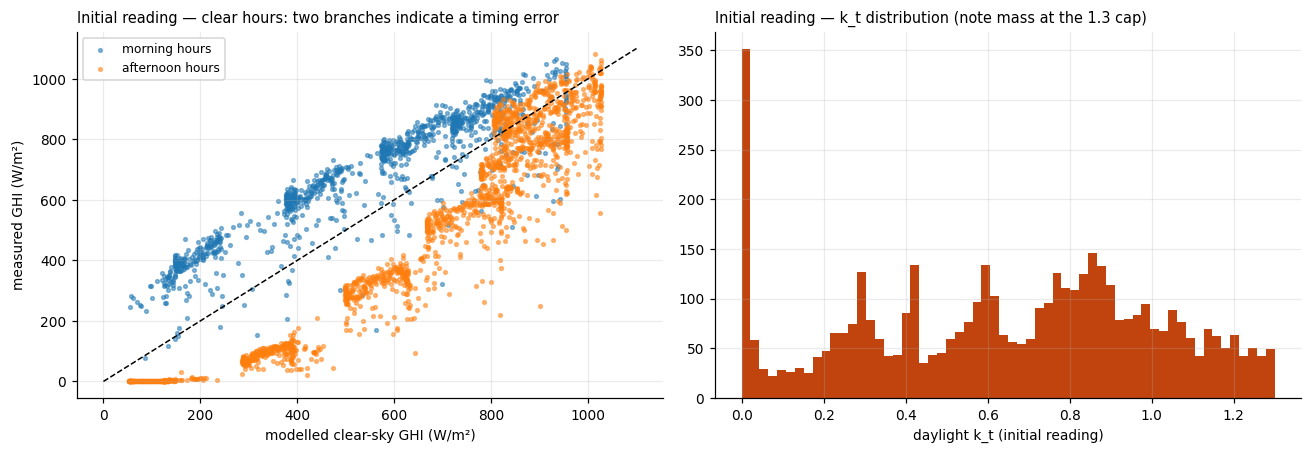

clear days found: 258;  initial-reading clear-hour measured/model ratio: morning nan, afternoon 0.72


In [ ]:
def inv_clear_hours(d):
    daily = d[d.is_daylight].groupby(d.ts.dt.floor("D")).agg(g=("ghi_wm2", "sum"), cs=("ghi_cs", "sum"),
                                                             n=("ghi_wm2", "count"))
    clear_days = daily[(daily.n >= 8) & (daily.g / daily.cs >= 0.75)].index
    return d[d.ts.dt.floor("D").isin(clear_days) & d.is_daylight & (d.ghi_cs > 50)]

c5 = inv_clear_hours(df_initial)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
am = c5.ts.dt.hour < 12
ax[0].scatter(c5.ghi_cs[am], c5.ghi_raw[am], s=6, alpha=.5, label="morning hours")
ax[0].scatter(c5.ghi_cs[~am], c5.ghi_raw[~am], s=6, alpha=.5, label="afternoon hours")
ax[0].plot([0, 1100], [0, 1100], "k--", lw=1); ax[0].set_xlabel("modelled clear-sky GHI (W/m²)"); ax[0].set_ylabel("measured GHI (W/m²)")
ax[0].set_title("Initial reading — clear hours: two branches indicate a timing error", fontsize=9.5, loc="left"); ax[0].legend(fontsize=8)
ax[1].hist(pd.Series(df_initial.kt)[df_initial.is_daylight].dropna(), bins=60, color="#c1440e")
ax[1].set_xlabel("daylight k_t (initial reading)"); ax[1].set_title("Initial reading — k_t distribution (note mass at the 1.3 cap)", fontsize=9.5, loc="left")
plt.tight_layout(); plt.show()
print(f"clear days found: {c5.ts.dt.floor('D').nunique()};  initial-reading clear-hour measured/model ratio: "
      f"morning {np.median(c5.ghi_raw[am]/c5.ghi_cs[am]):.2f}, afternoon {np.median(c5.ghi_raw[~am]/c5.ghi_cs[~am]):.2f}")

* **Finding.** If morning hours sit **above** the 1:1 line and afternoon hours **below** it (ratios printed above), the computed sun is lagging the measurement.
* **Risk.** The forecasting target k_t is then biased high every morning and low every afternoon. Hours pushed above the 1.3 physical ceiling are deleted by QC as "non-physical", so data are lost in a pattern tied to time of day.
* **Hypothesis 1, testable from the data.** An hourly mean of 1-second samples describes the **middle** of its hour, not its start.

In [ ]:
print("Mean within-bin sample offset (minutes after the HH:00 label), local basis:")
print(H_LOCAL.ts_off_min.describe()[["mean", "50%", "min", "max"]].round(2).to_string())

Mean within-bin sample offset (minutes after the HH:00 label), local basis:
mean    29.99
50%     29.99
min      0.75
max     59.92


**Evidence.** The mean sample in each bin sits about 30 minutes after its label.

**Decision rule 1.** Evaluate the sun at each bin's **mean sample time**.
* **Trigger:** two branches in the clear-sky plot.
* **Why appropriate:** the hourly value *is* the mean of those samples.
* **Validation:** re-test the clear-day profile.

## **Research Stage#5.2 First Modification: Sun at the Bin's Mean Sample Time (bins still from `Timestamp_Local`)**

In [ ]:
# ---------- FIRST MODIFICATION: sun evaluated at each bin's mean sample time (bins still from Timestamp_Local) ----------
df_partial = inv_engineer(inv_build_version(H_LOCAL, INV_DARWIN, "sample_centre", "partial"), INV_DARWIN)
df_partial["temp_c"] = df_initial["temp_c"].values
same_ghi = np.allclose(df_initial.ghi_raw, df_partial.ghi_raw, equal_nan=True)
print(f"df_partial: {len(df_partial):,} rows.  Hourly GHI values identical to the initial reading: {same_ghi}  (the first modification changes geometry only)")
assert same_ghi

df_partial: 25,824 rows.  Hourly GHI values identical to the initial reading: True  (the first modification changes geometry only)


### **Re-Analysis and Before vs After (Identical Measurements)**

In [ ]:
def inv_kt_tilt(d):
    c = inv_clear_hours(d); k = pd.Series(c.kt.values, index=c.ts.dt.hour)
    return pd.Series({"clear-day k_t morning (8-11h)": k[k.index.isin(range(8, 12))].median(),
                      "clear-day k_t afternoon (13-16h)": k[k.index.isin(range(13, 17))].median()})
INV_CMP2 = pd.concat({"initial": pd.concat([inv_qc_summary(df_initial), inv_kt_tilt(df_initial)]),
                   "partial": pd.concat([inv_qc_summary(df_partial), inv_kt_tilt(df_partial)])}, axis=1).round(3)
INV_CMP2.loc["morning − afternoon"] = INV_CMP2.loc["clear-day k_t morning (8-11h)"] - INV_CMP2.loc["clear-day k_t afternoon (13-16h)"]
display(INV_CMP2)

,initial,partial
hourly rows,25824.000,25824.000
daylight hours,12363.000,12359.000
raw missing (daylight) %,63.383,63.557
non-physical removed (h),717.000,457.000
k_t interpolated (h),734.000,535.000
k_t unrecoverable (h),7817.000,7777.000
valid daylight k_t (h),4544.000,4582.000
clear-day k_t morning (8-11h),0.920,1.071
clear-day k_t afternoon (13-16h),0.774,0.844
morning − afternoon,0.146,0.227


**Finding.** A correctly timed clear day has a **flat** k_t, so morning ≈ afternoon. Compare the `morning − afternoon` row across the two readings:

* If the tilt **shrinks but does not disappear**, rule 1 was necessary but not sufficient.
* If it vanishes, the timing problem is solved.

The hourly GHI values are identical in both readings (asserted above). Only k_t, and everything derived from it, changed.

## **Research Stage#5.3 Does the Timing Change Alone Move the Forecasting Results?**
**Analysis.** A controlled experiment. The measurements, the 70/15/15 chronological split, the models (GRU, QR-GRU) and the seeds (42, 7) are identical. Only the timing treatment differs.

In [ ]:
from numpy.lib.stride_tricks import sliding_window_view
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(INV_SEED)

def inv_build_supervised(d, feats=INV_FEATURES, target="kt", lookback=INV_LOOKBACK, horizon=INV_HORIZON):
    X_all = d[feats].to_numpy(dtype="float32")
    y_all = pd.to_numeric(d[target], errors="coerce").to_numpy(dtype="float32")
    n = len(d) - lookback - horizon + 1
    if n <= 0: return None
    W = sliding_window_view(X_all, (lookback, len(feats)))[:n, 0]
    tgt = np.arange(n) + lookback - 1 + horizon
    ok = np.isfinite(W).all(axis=(1, 2)) & np.isfinite(y_all[tgt]) & d["is_daylight"].to_numpy()[tgt]
    meta = d.iloc[tgt[ok]][["ts", "ghi_cs", "is_wet", "is_ramp_kt", "kt_imputed"]].reset_index(drop=True)
    return W[ok], y_all[tgt[ok]], meta

def inv_split(X, y, meta, fracs=(0.70, 0.15)):
    n = len(y); edges = np.cumsum([0] + [int(n * f) for f in fracs] + [n])
    edges[-1] = n
    names = ["train", "val", "cal", "test"][:len(fracs)] + ["test"]
    names = ["train", "val", "test"] if len(fracs) == 2 else ["train", "val", "cal", "test"]
    return {k: (X[a:b], y[a:b], meta.iloc[a:b].reset_index(drop=True)) for k, a, b in zip(names, edges[:-1], edges[1:])}

class InvStandardiser:
    def fit(self, X):
        f = X.reshape(-1, X.shape[-1]); self.m, self.s = f.mean(0), f.std(0) + 1e-6; return self
    def __call__(self, X): return (X - self.m) / self.s

def inv_pinball_loss(q):
    q = tf.constant(q, tf.float32)
    def loss(y, p):
        e = tf.cast(y, tf.float32)[:, None] - p
        return tf.reduce_mean(tf.maximum(q * e, (q - 1) * e))
    return loss

def inv_gaussian_nll(y, p):
    y = tf.reshape(tf.cast(y, tf.float32), [-1]); mu, lv = p[:, 0], tf.clip_by_value(p[:, 1], -12., 6.)
    return tf.reduce_mean(0.5 * (lv + tf.square(y - mu) * tf.exp(-lv)))

def inv_make_model(kind, nf, lookback=INV_LOOKBACK, units=INV_UNITS):
    inp = keras.Input((lookback, nf))
    if kind == "GRU":
        x = layers.Dense(32, activation="relu")(layers.GRU(units)(inp)); out, loss = layers.Dense(1)(x), "mse"
    elif kind == "QR-GRU":
        x = layers.Dense(32, activation="relu")(layers.GRU(units)(inp)); out, loss = layers.Dense(len(INV_Q))(x), inv_pinball_loss(INV_Q)
    elif kind in ("MC-Dropout LSTM", "HMC-LSTM"):
        x = layers.Dropout(0.2)(layers.LSTM(units, dropout=0.2)(inp), training=True)
        x = layers.Dropout(0.2)(layers.Dense(32, activation="relu")(x), training=True)
        out, loss = (layers.Dense(1)(x), "mse") if kind == "MC-Dropout LSTM" else (layers.Dense(2)(x), inv_gaussian_nll)
    m = keras.Model(inp, out); m.compile(keras.optimizers.Adam(INV_LR), loss=loss); return m

def inv_fit_predict(kind, sp, seed=INV_SEED, passes=50):
    tf.keras.utils.set_random_seed(seed)
    sc = InvStandardiser().fit(sp["train"][0])
    m = inv_make_model(kind, sp["train"][0].shape[-1])
    h = m.fit(sc(sp["train"][0]), sp["train"][1], validation_data=(sc(sp["val"][0]), sp["val"][1]), epochs=INV_EPOCHS,
              batch_size=INV_BATCH, verbose=0, callbacks=[keras.callbacks.EarlyStopping(patience=INV_PATIENCE, restore_best_weights=True)])
    def pred(X):
        if kind in ("MC-Dropout LSTM", "HMC-LSTM"):
            outs = [m(sc(X), training=True).numpy() for _ in range(passes)]
            if kind == "MC-Dropout LSTM":
                S = np.stack([o.ravel() for o in outs], 1)
            else:
                rng = np.random.default_rng(seed)
                mu = np.stack([o[:, 0] for o in outs], 1); sd = np.exp(0.5 * np.clip(np.stack([o[:, 1] for o in outs], 1), -12, 6))
                S = mu + sd * rng.standard_normal(mu.shape)
            return S.mean(1), np.quantile(S, INV_Q, axis=1).T
        if kind == "QR-GRU":
            Q = np.sort(m.predict(sc(X), verbose=0), 1); return Q[:, INV_Q.index(0.5)], Q
        return m.predict(sc(X), verbose=0).ravel(), None
    out = {k: pred(sp[k][0]) for k in sp if k != "train"}
    tf.keras.backend.clear_session()
    return out, len(h.history["loss"])

def inv_climatology(sp):
    _, ytr, mtr = sp["train"]
    tab = pd.DataFrame({"kt": ytr, "m": mtr.ts.dt.month, "h": mtr.ts.dt.hour}).groupby(["m", "h"]).kt.median()
    g = float(np.median(ytr))
    return lambda meta: tab.reindex(pd.MultiIndex.from_arrays([meta.ts.dt.month, meta.ts.dt.hour])).fillna(g).to_numpy()

def inv_score(p_kt, y_kt, meta, Q=None, delta=0.0):
    cs = meta.ghi_cs.to_numpy(); yt, yh = y_kt * cs, np.clip(p_kt * cs, 0, None)
    r = {"n": len(yt), "RMSE": float(np.sqrt(np.mean((yh - yt) ** 2))), "MAE": float(np.mean(np.abs(yh - yt)))}
    if Q is not None:
        lo, hi = np.clip((Q[:, INV_I_LO] - delta) * cs, 0, None), np.clip((Q[:, INV_I_HI] + delta) * cs, 0, None)
        r["PICP80"], r["MIW"] = float(((yt >= lo) & (yt <= hi)).mean()), float((hi - lo).mean())
        Qw = np.clip(Q * cs[:, None], 0, None)
        pl = np.stack([np.maximum(t * (yt - Qw[:, j]), (t - 1) * (yt - Qw[:, j])) for j, t in enumerate(INV_Q)], 1)
        r["CRPS_q"] = float(np.mean(2 * np.trapezoid(pl, INV_Q, axis=1)) if hasattr(np, "trapezoid") else np.mean(2 * np.trapz(pl, INV_Q, axis=1)))
    return r

def inv_cqr_delta(Q, y, alpha=0.2):
    E = np.maximum(Q[:, INV_I_LO] - y, y - Q[:, INV_I_HI]); k = min(len(E), int(np.ceil((len(E) + 1) * (1 - alpha))))
    return float(np.sort(E)[k - 1])
print("modelling functions ready; TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

modelling functions ready; TensorFlow 2.20.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
INV_SPLITS = {}
def inv_run_version(name, d, seeds=(42, 7)):
    X, y, meta = inv_build_supervised(d)
    sp = inv_split(X, y, meta)
    Xte, yte, mte = sp["test"]
    rows = [{"version": name, "model": "Persistence", "seed": "-", **inv_score(Xte[:, -1, 0], yte, mte)},
            {"version": name, "model": "Climatology", "seed": "-", **inv_score(inv_climatology(sp)(mte), yte, mte)}]
    for kind in ("GRU", "QR-GRU"):
        for s in seeds:
            out, ep = inv_fit_predict(kind, sp, seed=s)
            p, Q = out["test"]
            rows.append({"version": name, "model": kind, "seed": s, "epochs": ep, **inv_score(p, yte, mte, Q)})
    INV_SPLITS[name] = sp
    return pd.DataFrame(rows)

t0 = time.time()
INV_RESULTS = pd.concat([inv_run_version("initial", df_initial), inv_run_version("partial", df_partial)], ignore_index=True)
pers = INV_RESULTS[INV_RESULTS.model == "Persistence"].set_index("version").RMSE
INV_RESULTS["skill_%"] = 100 * (1 - INV_RESULTS.RMSE / INV_RESULTS.version.map(pers))
print(f"controlled experiment (initial vs first modification) in {time.time()-t0:.0f}s")
display(INV_RESULTS.round(3))

controlled experiment (initial vs first modification) in 113s


,version,model,seed,n,RMSE,MAE,epochs,PICP80,MIW,CRPS_q,skill_%
0,initial,Persistence,-,533,146.662,114.143,NaN,NaN,NaN,NaN,0.000
1,initial,Climatology,-,533,190.730,120.377,NaN,NaN,NaN,NaN,-30.047
2,initial,GRU,42,533,117.475,77.341,36.0,NaN,NaN,NaN,19.901
3,initial,GRU,7,533,160.807,97.358,41.0,NaN,NaN,NaN,-9.644
4,initial,QR-GRU,42,533,124.938,75.624,51.0,0.749,213.656,50.315,14.812
5,initial,QR-GRU,7,533,119.668,76.287,43.0,0.707,231.764,53.760,18.405
6,partial,Persistence,-,535,129.312,96.283,NaN,NaN,NaN,NaN,0.000
7,partial,Climatology,-,535,205.902,123.838,NaN,NaN,NaN,NaN,-59.229
8,partial,GRU,42,535,145.193,91.307,45.0,NaN,NaN,NaN,-12.281
9,partial,GRU,7,535,162.349,97.889,48.0,NaN,NaN,NaN,-25.549


* **Finding.** Compare persistence RMSE and model skill between the two readings. Any difference is caused by the timing treatment alone, because nothing else differs.
* **Implication.** Results built on k_t are sensitive to timing. A residual timing error therefore cannot be dismissed as cosmetic.

## **Research Stage#5.4 Deeper Investigation: is `Timestamp_Local` Really Darwin Time?**

**Trigger.** The remaining tilt after rule 1, together with the offset table from Stage 4.
**Hypothesis 2.** `Timestamp_Local` is not ACST.
**Test.** Physics. On a clear day irradiance is symmetric about **solar noon**, which is fixed by longitude and the equation of time. The centre of the measured 1-second curve must therefore fall on solar noon **in the correct clock**. This test uses no binning and no clear-sky model.

native sampling of the July rows: 1 s


,day,"Timestamp_Local reading − noon, min","UTC+9:30 reading − noon, min"
0,2022-07-14,-30.83,-0.83
1,2022-07-06,-30.43,-0.43
2,2022-07-11,-30.21,-0.21
3,2022-07-07,-30.55,-0.55
4,2022-07-15,-32.58,-2.58
5,2022-07-05,-29.84,0.16
6,2022-07-09,-30.62,-0.62
7,2022-07-24,-31.30,-1.30
8,2022-07-08,-30.32,-0.32
9,2022-07-20,-31.73,-1.73


,"Timestamp_Local reading − noon, min","UTC+9:30 reading − noon, min"
mean,-30.84,-0.84
std,0.82,0.82


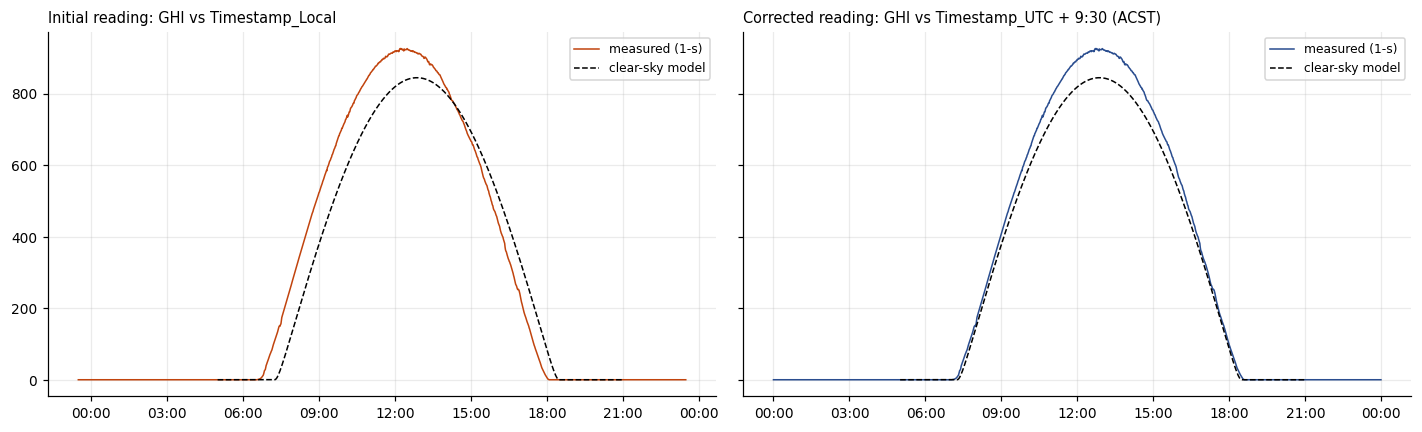

In [ ]:
if len(JULY_1S):
    fmtj = inv_fmt(JULY_1S.raw_utc.head(200))
    tu = pd.to_datetime(JULY_1S.raw_utc, format=fmtj); tl = pd.to_datetime(JULY_1S.raw_local, format=fmtj)
    timestamp_initial = tl; timestamp_corrected = tu + pd.Timedelta(hours=9.5)
    g = JULY_1S.ghi.to_numpy()
    def eot(doy):
        b = 2 * np.pi * (np.asarray(doy, float) - 1) / 365
        return 229.18 * (0.000075 + 0.001868*np.cos(b) - 0.032077*np.sin(b) - 0.014615*np.cos(2*b) - 0.040849*np.sin(2*b))
    dayk = timestamp_corrected.dt.normalize()
    STEP_S = float(tu.diff().dt.total_seconds().median())
    STEP_1MIN = max(1, int(round(60 / STEP_S)))                 # samples per minute (1 for 1-min data, 60 for 1-s)
    print(f"native sampling of the July rows: {STEP_S:.0f} s")
    stats_ = []
    for dday, idx in pd.Series(np.arange(len(g))).groupby(dayk.values):
        gi = g[idx.values]
        if np.nanmax(gi) < 500: continue
        stats_.append({"day": dday, "rough": np.nanmean(np.abs(np.diff(gi[::STEP_1MIN]))) / np.nanmax(gi)})
    clear = pd.DataFrame(stats_).nsmallest(10, "rough").day
    rows = []
    for dday in clear:
        sel = (dayk == dday).to_numpy()
        noon = (720 - 4 * INV_DARWIN["lon"] - eot(pd.DatetimeIndex([dday]).dayofyear)[0] + 60 * 9.5) / 60
        w = np.clip(np.nan_to_num(g[sel]), 0, None)
        c = lambda t: float(((t.dt.hour + t.dt.minute / 60 + t.dt.second / 3600) * w).sum() / w.sum())
        rows.append({"day": dday.date(), "Timestamp_Local reading − noon, min": 60 * (c(timestamp_initial[sel]) - noon),
                     "UTC+9:30 reading − noon, min": 60 * (c(timestamp_corrected[sel]) - noon)})
    NOON = pd.DataFrame(rows); display(NOON.round(2)); display(NOON.iloc[:, 1:].agg(["mean", "std"]).round(2))
    sel = (dayk == clear.iloc[0]).to_numpy()
    grid = pd.date_range(clear.iloc[0] + pd.Timedelta(hours=5), clear.iloc[0] + pd.Timedelta(hours=21), freq="1min")
    fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
    for a, t, ttl, col in ((ax[0], timestamp_initial, "Initial reading: GHI vs Timestamp_Local", "#c1440e"), (ax[1], timestamp_corrected, "Corrected reading: GHI vs Timestamp_UTC + 9:30 (ACST)", "#2a4d8f")):
        a.plot(t[sel].iloc[::STEP_1MIN], g[sel][::STEP_1MIN], color=col, lw=1, label="measured (1-s)")
        a.plot(grid, inv_clearsky(inv_solar_geometry(grid, INV_DARWIN["lat"], INV_DARWIN["lon"], 9.5)), "k--", lw=1, label="clear-sky model")
        a.set_title(ttl, fontsize=9.5, loc="left"); a.legend(fontsize=8)
        a.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%H:%M"))
    plt.tight_layout(); plt.show()
else:
    print("No July-2022 1-second rows were found in the Darwin files, so the physical solar-noon test cannot run.")

**Finding.** The table shows how far each reading's observed noon falls from astronomical noon. The reading whose observed noon coincides with astronomical noon, within a few minutes, is the correct clock. A constant offset of about 30 minutes in the other reading matches the column offset measured in Stage 4.

**Decision rule 2.**
* **Rule:** build hourly bins from `Timestamp_UTC` + 9 h 30 min (ACST) and keep rule 1.
* **Trigger:** the residual tilt, the column offset, and the solar-noon test.
* **Why appropriate:** UTC is unambiguous, ACST is the legal time of the Northern Territory all year, and the physical test confirms it.
* **Validation:** re-test the clear-day profile, and gate the production pipeline on a clear-day timing statistic (Stage 6).

## **Research Stage#5.5 Second Modification: ACST bins from the UTC Column**

In [ ]:
# ---------- SECOND MODIFICATION: bins from Timestamp_UTC + 9:30 (ACST), sun at bin centre ----------
df_corrected = inv_engineer(inv_build_version(H_ACST, INV_DARWIN, "sample_centre", "corrected"), INV_DARWIN)
print(f"df_corrected: {len(df_corrected):,} rows | samples aggregated equal to the Timestamp_Local readings: {H_ACST.n_obs.sum() == H_LOCAL.n_obs.sum()}")
INV_CMP3 = pd.concat({v: pd.concat([inv_qc_summary(d), inv_kt_tilt(d)]) for v, d in (("initial", df_initial), ("partial", df_partial), ("corrected", df_corrected))}, axis=1)
INV_CMP3.loc["morning − afternoon"] = INV_CMP3.loc["clear-day k_t morning (8-11h)"] - INV_CMP3.loc["clear-day k_t afternoon (13-16h)"]
display(INV_CMP3.round(3))

df_corrected: 25,825 rows | samples aggregated equal to the Timestamp_Local readings: True


,initial,partial,corrected
hourly rows,25824.000,25824.000,25825.000
daylight hours,12363.000,12359.000,12360.000
raw missing (daylight) %,63.383,63.557,63.107
non-physical removed (h),717.000,457.000,80.000
k_t interpolated (h),734.000,535.000,202.000
k_t unrecoverable (h),7817.000,7777.000,7678.000
valid daylight k_t (h),4544.000,4582.000,4682.000
clear-day k_t morning (8-11h),0.920,1.071,0.973
clear-day k_t afternoon (13-16h),0.774,0.844,0.985
morning − afternoon,0.146,0.227,-0.011


### **Before vs After Across All Three Readings, with Model Results**

In [ ]:
INV_RESULTS = pd.concat([INV_RESULTS, inv_run_version("corrected", df_corrected)], ignore_index=True)
pers = INV_RESULTS[INV_RESULTS.model == "Persistence"].groupby("version").RMSE.first()
INV_RESULTS["skill_%"] = 100 * (1 - INV_RESULTS.RMSE / INV_RESULTS.version.map(pers))
INV_SUMMARY = INV_RESULTS.groupby(["version", "model"]).agg(RMSE=("RMSE", "mean"), skill=("skill_%", "mean"),
                                                   PICP80=("PICP80", "mean"), n=("n", "first")).round(3)
display(INV_SUMMARY)
print("Note: the corrected reading is scored on its own (correctly binned) hourly GHI, so it is comparable in skill, "
      "not in absolute W/m², to the two Timestamp_Local readings.")

RMSE    skill  PICP80    n
version   model                                     
corrected Climatology  215.946 -125.564     NaN  542
          GRU          143.729  -50.131     NaN  542
          Persistence   95.736    0.000     NaN  542
          QR-GRU       130.239  -36.040   0.732  542
initial   Climatology  190.730  -30.047     NaN  533
          GRU          139.141    5.128     NaN  533
          Persistence  146.662    0.000     NaN  533
          QR-GRU       122.303   16.609   0.728  533
partial   Climatology  205.902  -59.229     NaN  535
          GRU          153.771  -18.915     NaN  535
          Persistence  129.312    0.000     NaN  535
          QR-GRU       140.103   -8.345   0.709  535

Note: the corrected reading is scored on its own (correctly binned) hourly GHI, so it is comparable in skill, not in absolute W/m², to the two Timestamp_Local readings.


**Before vs After: What Changed and Why it Matters.**

* **Values.** The UTC-based bins average a *different* half hour of physical time than the local-column bins. The hourly GHI values themselves change, not only their labels. The raw 1-second measurements are the same in every reading.
* **Target.** The clear-day k_t becomes flat, and fewer hours are deleted as "non-physical".
* **Results.** Persistence and model skill change. Results computed on the initial reading would have overstated how much better the models are than persistence, because persistence carries forward a bias that changes direction through the day.

**What is Not Affected.** Every Darwin feature shifts together, so lags and target stay mutually aligned. The bias is against the **sun**. Train/validation/test boundaries are not moved materially by a 30-minute relabelling. No daylight observation changes calendar date.

**Research Implication.** All modelling below uses the corrected rules. The production pipeline (Stage 6) also enforces a **clear-day timing gate**: if the primary site is more than ±10 minutes out of step with the sun, the run stops, so a timing error cannot pass silently into the results.

### **Releasing Investigation Memory**

Stage 5's conclusions are now encoded as decision rules and as the small summary tables `INV_SUMMARY` and `INV_CMP3`, which Stage 15 uses. The raw 1-second rows and the intermediate hourly frames are released, so the production pipeline starts with the full memory budget.

In [ ]:
import gc
for _n in ("JULY_1S", "H_LOCAL", "H_ACST", "df_initial", "df_partial", "df_corrected", "tu", "tl", "g",
           "timestamp_initial", "timestamp_corrected", "INV_SPLITS", "c5", "dayk"):
    globals().pop(_n, None)
try:
    tf.keras.backend.clear_session()
except Exception:
    pass
gc.collect()
print(f"memory after release: {mem_mb():,.0f} MB")

memory after release: 2,242 MB


# **PART D · Data Preparation and Preprocessing**

> *Navigation header added for the VIVA. It covers Stage 6 (ingestion and validation, all sites) and Stage 7 (cleaning, clear-sky index, features) below. No original cell was changed.*

---
# **Research Stage#6 — Production Ingestion and Validation with the Corrected Rules (All Sites)**

Stage 5's decisions now govern ingestion for every site:

* DKASC files are read from the UTC column with the site offset, and the file's own Local−UTC offset is measured and reported;
* geometry is evaluated at the mean sample time;
* logger fill values are masked before averaging;
* sources whose clock cannot be read from the file are aligned empirically on clear days, with a limit;
* the primary site must pass the clear-day gate.

**Methodological development.** Two data-design decisions are taken at run time and logged, each with its evidence:

1. **Darwin record extension.** The same station's 1-minute export fills hours outside the 1-second files, but only if the two agree on their overlap.
2. **Singapore primary source.** Chosen by a priority rule with a 365-day minimum, so a short record cannot stand in for the equatorial arm.

### **Research Stage#6.1 Site Registry, Solar Geometry and Clear-Sky Model (Production)**

In [ ]:
SITES = {
    "DARWIN": dict(lat=-12.4256, lon=130.8916, tz=9.5, hemi="S",
                   climate="Tropical savanna (Köppen Aw)",
                   wet_months=[11, 12, 1, 2, 3, 4],
                   season_names=("Dry", "Wet"), role="Primary — tropical target"),
    "ALICE": dict(lat=-23.7615, lon=133.8747, tz=9.5, hemi="S",
                  climate="Hot arid (Köppen BWh)",
                  wet_months=[11, 12, 1, 2, 3],
                  season_names=("Dry", "Wet"), role="Proxy validation — measured PV ground truth"),
    "SINGAPORE": dict(lat=1.3521, lon=103.8198, tz=8.0, hemi="N",
                      climate="Equatorial rainforest (Köppen Af)",
                      wet_months=[11, 12, 1, 2, 3],
                      season_names=("Inter/SW monsoon", "NE monsoon"),
                      role="Cross-climate — equatorial"),
    "NSRDB": dict(lat=26.06, lon=-80.33, tz=-5.0, hemi="N",
                  climate="Humid subtropical / tropical monsoon margin",
                  wet_months=[5, 6, 7, 8, 9, 10],
                  season_names=("Dry", "Wet"), role="Cross-climate — subtropical"),
}

# ---- an intermediate pipeline EXTENDED sites: zero-shot evaluation only, never trained on -----------------------
# Coordinates are nominal station locations; the loaders overwrite them with values read from
# file metadata where the source provides it (NSRDB, PANGAEA, ESMAP preambles). Wet-season
# months follow each site's own climatology, by the same rule the initial pipeline used for Singapore/NSRDB.
# They are a methodological input: confirm them against the climatology you cite.
EXT_SITES = {
    "KATHERINE": dict(lat=-14.4700, lon=132.2600, tz=9.5, hemi="S",
                      climate="Tropical savanna (Köppen Aw)", wet_months=[11, 12, 1, 2, 3, 4],
                      season_names=("Dry", "Wet"), role="Zero-shot — tropical (same class as Darwin)"),
    "TENNANT": dict(lat=-19.6500, lon=134.1900, tz=9.5, hemi="S",
                    climate="Hot semi-arid (Köppen BSh)", wet_months=[11, 12, 1, 2, 3],
                    season_names=("Dry", "Wet"), role="Zero-shot — tropical semi-arid"),
    "YULARA": dict(lat=-25.2400, lon=130.9900, tz=9.5, hemi="S",
                   climate="Hot arid (Köppen BWh)", wet_months=[11, 12, 1, 2, 3],
                   season_names=("Dry", "Wet"), role="Zero-shot — arid"),
    "PETROLINA": dict(lat=-9.0681, lon=-40.3194, tz=-3.0, hemi="S",
                      climate="Hot semi-arid (Köppen BSh)", wet_months=[12, 1, 2, 3, 4],
                      season_names=("Dry", "Wet"), role="Zero-shot — tropical semi-arid (BSRN)"),
    "HONGKONG": dict(lat=22.3364, lon=114.2654, tz=8.0, hemi="N",
                     climate="Humid subtropical (Köppen Cwa)", wet_months=[5, 6, 7, 8, 9],
                     season_names=("Dry", "Wet"), role="Zero-shot — subtropical monsoon"),
    "ESMAP": dict(lat=-0.6936, lon=73.1566, tz=5.0, hemi="S",
                  climate="Equatorial maritime (Köppen Af)", wet_months=[5, 6, 7, 8, 9, 10, 11],
                  season_names=("NE monsoon", "SW monsoon"), role="Zero-shot — equatorial maritime"),
}
if CFG.SITE_SET == "EXTENDED":
    SITES.update(EXT_SITES)

# a short satellite series is never allowed to stand in for the equatorial arm. When the
# primary Singapore source is something else, Open-Meteo is kept as a clearly labelled SECONDARY
# check (same pixel, different retrieval), reported but excluded from equatorial conclusions.
SITES["SG_OPENMETEO"] = dict(lat=1.3521, lon=103.8198, tz=8.0, hemi="N",
                             climate="Equatorial rainforest (Köppen Af) — satellite, short record",
                             wet_months=[11, 12, 1, 2, 3],
                             season_names=("Inter/SW monsoon", "NE monsoon"),
                             role="Secondary check only — not used for conclusions")
SECONDARY_SITES = {"SG_OPENMETEO"}

SOLAR_CONSTANT = 1367.0


def solar_geometry(ts_local: pd.DatetimeIndex, lat: float, lon: float, tz: float):
    """Cosine of solar zenith and extraterrestrial horizontal irradiance.

    ts_local is timezone-naive LOCAL standard time; tz is its UTC offset in hours.
    Spencer (1971) declination + equation of time; standard NOAA hour-angle construction.
    """
    utc = pd.DatetimeIndex(ts_local) - pd.Timedelta(hours=tz)
    doy = np.asarray(utc.dayofyear, dtype=float)
    hod = (np.asarray(utc.hour, float)
           + np.asarray(utc.minute, float) / 60.0
           + np.asarray(utc.second, float) / 3600.0)

    g = 2.0 * np.pi * (doy - 1.0 + (hod - 12.0) / 24.0) / 365.0
    eqtime = 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g)
                       - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))
    decl = (0.006918 - 0.399912 * np.cos(g) + 0.070257 * np.sin(g)
            - 0.006758 * np.cos(2 * g) + 0.000907 * np.sin(2 * g)
            - 0.002697 * np.cos(3 * g) + 0.001480 * np.sin(3 * g))

    true_solar_min = hod * 60.0 + eqtime + 4.0 * lon
    ha = np.radians(true_solar_min / 4.0 - 180.0)
    la = np.radians(lat)
    cosz = np.sin(la) * np.sin(decl) + np.cos(la) * np.cos(decl) * np.cos(ha)
    cosz = np.clip(cosz, -1.0, 1.0)

    e0 = 1.0 + 0.033 * np.cos(2.0 * np.pi * doy / 365.0)
    ghi_toa = np.clip(SOLAR_CONSTANT * e0 * cosz, 0.0, None)
    return cosz, ghi_toa


def clearsky_haurwitz(cosz: np.ndarray) -> np.ndarray:
    """Haurwitz (1945) clear-sky GHI. Single-parameter, no aerosol inputs required."""
    c = np.where(cosz > 0.0, cosz, np.nan)
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        ghi = 1098.0 * c * np.exp(-0.059 / c)
    return np.nan_to_num(ghi, nan=0.0, posinf=0.0, neginf=0.0)


def geometry_times(df: pd.DataFrame, site: str) -> pd.DatetimeIndex:
    """The instant each hourly row actually represents (an intermediate pipeline).

    Every loader labels an hourly row with the START of its hour (HH:00), but the value is
    the mean of the samples inside that hour, whose centre is ~HH:30 for 1-s/1-min data,
    ~HH:25 for 10-min instantaneous data, and so on. the initial pipeline evaluated the sun at HH:00, i.e.
    up to 30 minutes early, which biases kt high in the morning and low in the afternoon
    and pushes early-morning hours over the KT_MAX ceiling (visible in the initial pipeline Figure 8 as two
    separate branches). The loaders now record the mean sample offset of every bin in
    `ts_off_min`; this function applies it.
    """
    ts = pd.DatetimeIndex(df["ts"])
    if CFG.GEOMETRY_TIMING != "sample_centre" or "ts_off_min" not in df.columns:
        return ts
    off = pd.to_numeric(df["ts_off_min"], errors="coerce")
    fill = off.median() if off.notna().any() else 0.0
    off = off.fillna(fill).clip(0, 60).to_numpy()
    return ts + pd.to_timedelta(off, unit="m")


def attach_solar(df: pd.DataFrame, site: str) -> pd.DataFrame:
    m = SITES[site]
    cosz, toa = solar_geometry(geometry_times(df, site), m["lat"], m["lon"], m["tz"])
    out = df.copy()
    out["cos_zenith"] = cosz
    out["ghi_toa"] = toa
    out["ghi_cs"] = clearsky_haurwitz(cosz)
    out["is_daylight"] = out["ghi_cs"] > CFG.DAYLIGHT_CS_MIN
    return out

### **Research Stage#6.2 Robust Readers: Header Sniffing and Unit-Aware Column Normalisation**

In [ ]:
def sniff_header(path, expect_tokens, max_scan=60, sep=",") -> int:
    """Index of the row that is actually the CSV header.

    an intermediate pipeline: `sep` is a parameter (PANGAEA/BSRN files are tab-separated), and a PANGAEA
    '/* ... */' description block is skipped explicitly rather than scored.
    """
    lines = peek_lines(path, max_scan)
    if lines and lines[0].lstrip().startswith("/*"):
        for i, l in enumerate(peek_lines(path, 2000)):
            if l.strip().startswith("*/"):
                return i + 1
    exp = [t.lower() for t in expect_tokens]
    best, best_hits = 0, 0
    for i, line in enumerate(lines):
        toks = [t.strip().strip('"').lower() for t in line.split(sep)]
        hits = sum(any(e in t for t in toks) for e in exp)
        if hits > best_hits:
            best, best_hits = i, hits
        if hits >= max(2, len(exp) - 1):
            return i
    return best


def canon_cols(cols):
    """`Irradiance_MB0 [W/m-2]` -> `irradiance_mb0`;  `Clearsky GHI` -> `clearsky_ghi`."""
    out = []
    for c in cols:
        c = re.sub(r"\[[^\]]*\]", " ", str(c))          # drop bracketed units
        c = re.sub(r"[^\w]+", "_", c.strip()).strip("_").lower()
        out.append(c)
    return out


def read_csv_smart(path, expect_tokens, usecols=None, nrows=None, chunksize=None, sep=","):
    """read_csv with the header row detected, columns canonicalised, -999 -> NaN."""
    hdr = sniff_header(path, expect_tokens, sep=sep)
    probe = pd.read_csv(path, skiprows=hdr, nrows=0, sep=sep)
    canon = canon_cols(probe.columns)
    ren = dict(zip(probe.columns, canon))
    keep = None
    if usecols is not None:
        want = set(usecols)
        keep = [orig for orig, cn in ren.items() if cn in want]
        missing = want - {ren[k] for k in keep}
        if missing:
            raise KeyError(f"{Path(path).name}: missing required columns {sorted(missing)}")
    kw = dict(skiprows=hdr, usecols=keep, na_values=[-999, -999.0, "-999", ""],
              low_memory=False, sep=sep)
    if chunksize:
        def gen():
            for ch in pd.read_csv(path, chunksize=chunksize, **kw):
                yield ch.rename(columns=ren)
        return gen()
    return pd.read_csv(path, nrows=nrows, **kw).rename(columns=ren)


def read_nsrdb_metadata(path) -> dict:
    """NSRDB stores its geo and time-zone metadata in a 2-row preamble, not the filename.

    an intermediate pipeline correction: NSRDB has TWO time-zone fields. 'Time Zone' is the offset of the
    timestamps IN THE FILE (0 when downloaded with utc=true, the API default for
    Himawari requests); 'Local Time Zone' is the site's local standard offset. the initial pipeline read
    'Local Time Zone' only and assumed the timestamps were local, which is correct only
    when both fields agree (as they did for the South Florida download).
    """
    head = pd.read_csv(path, nrows=1)
    row = head.iloc[0]
    get = lambda k, d: (row[k] if k in head.columns and pd.notna(row[k]) else d)
    local_tz = float(get("Local Time Zone", get("Time Zone", np.nan)))
    file_tz = float(get("Time Zone", local_tz))
    return {"lat": float(get("Latitude", np.nan)), "lon": float(get("Longitude", np.nan)),
            "tz": local_tz, "file_tz": file_tz,
            "state": str(get("State", "?")), "city": str(get("City", "?")),
            "source": str(get("Source", "?"))}


# ---------------------------------------------------------------------------------------
# an intermediate pipeline generic readers — used only for the EXTENDED sources, whose layouts were not seen in the initial pipeline.
# Each decision (separator, header row, timestamp column and format, GHI column, time basis)
# is made from the file itself and written to the ingestion ledger, so nothing is guessed
# silently.
# ---------------------------------------------------------------------------------------
TS_FORMATS = ["%Y-%m-%dT%H:%M", "%Y-%m-%dT%H:%M:%S", "%Y-%m-%d %H:%M:%S", "%Y-%m-%d %H:%M",
              "%d/%m/%Y %H:%M:%S", "%d/%m/%Y %H:%M", "%m/%d/%Y %H:%M:%S", "%m/%d/%Y %H:%M",
              "%Y/%m/%d %H:%M:%S", "%Y/%m/%d %H:%M", "%d-%m-%Y %H:%M:%S", "%d-%m-%Y %H:%M",
              "%d.%m.%Y %H:%M", "%Y%m%d%H%M", "%Y-%m-%dT%H:%M:%SZ", "%Y-%m-%d %H:%M:%S%z"]

GHI_PATTERNS = [   # priority order: explicit pyranometer GHI first, reference cells last
    r"^(ghi|swd|global_horizontal(_radiation|_irradiance)?|shortwave_radiation|"
    r"global_radiation|globalradiation|gh|global)($|_)",
    r"^irradiance_mb\d",
    r"irradiance|radiation",
]
GHI_EXCLUDE = r"clear|cs_|_cs$|tilt|poa|diffuse|direct|dni|dhi|dif$|dir$|lwd|longwave|reflect|uv|par"
MET_PATTERNS = {
    # anchored names first, then unanchored fall-backs (HKUST weather files were read as
    # GHI-only in an intermediate pipeline because their met columns did not start with these tokens).
    "temp_c": r"^(t2|t2m|temp|temperature|air_?temp|airtemperature|tair|ta|tamb|weather_temperature)"
              r"|air_?temp|temp_?air|ambient_?temp|dry_?bulb",
    "rh_pct": r"^(rh|rh2m|relative_humidity|relativehumidity|humidity|weather_relative_humidity)"
              r"|rel_?hum|humidity",
    "wind_ms": r"^(ws|ws10m|wind_speed|windspeed|wind_spd|ws_avg)(?!.*dir)|wind_?speed|wspd",
}
MET_EXCLUDE = r"dir|dew|soil|module|panel|cell|max|min|std|gust|flag|qc"


def detect_columns(cols):
    """Return (ts_spec, ghi_cols, met_map) from canonical column names."""
    cols = list(cols)
    parts = {k: next((c for c in cols if c == k), None) for k in ("year", "month", "day", "hour")}
    if all(parts.values()):
        ts_spec = {"kind": "parts", "cols": [c for c in ("year", "month", "day", "hour", "minute")
                                             if c in cols]}
    else:
        order = [r"^timestamp", r"^date_?time", r"^datetime", r"^time_?utc", r"^time_local|^local_time",
                 r"^time$", r"^date$", r"time", r"date"]
        tcol = next((c for rx in order for c in cols if re.search(rx, c)), None)
        ts_spec = {"kind": "single", "col": tcol} if tcol else None
    ghi = []
    for rx in GHI_PATTERNS:
        ghi = [c for c in cols if re.search(rx, c) and not re.search(GHI_EXCLUDE, c)]
        if ghi:
            break
    if ghi and not re.match(r"^irradiance_mb", ghi[0]):
        ghi = ghi[:1]                  # one pyranometer channel; reference cells are averaged
    met = {}
    for canon, rx in MET_PATTERNS.items():
        c = next((c for c in cols if re.search(rx, c) and not re.search(MET_EXCLUDE, c)
                  and c not in ghi), None)
        if c:
            met[canon] = c
    return ts_spec, ghi, met


def detect_ts_format(samples):
    """Pick the explicit format that parses the sample; day-first wins ties (the initial pipeline convention).

    Ambiguous DD/MM vs MM/DD strings silently corrupt a series, which is why the initial pipeline used
    explicit formats per source. Here the candidate list is tried in order and the first
    format parsing >= 98% of the sample is chosen; day-first formats precede month-first.
    Returns (format or None, parse_rate, tz_aware).
    """
    s = pd.Series([str(x).strip() for x in samples if pd.notna(x)])
    if not len(s):
        return None, 0.0, False
    if s.str.contains(r"(\+|-)\d\d:?\d\d$|Z$").mean() > 0.9:
        ok = pd.to_datetime(s, errors="coerce", utc=True).notna().mean()
        return None, float(ok), True
    for fmt in TS_FORMATS:
        ok = pd.to_datetime(s, format=fmt, errors="coerce").notna().mean()
        if ok >= 0.98:
            return fmt, float(ok), False
    ok = pd.to_datetime(s, errors="coerce", dayfirst=True).notna().mean()
    return None, float(ok), False


def read_preamble_geo(path):
    """Latitude/longitude/UTC-offset hints from a file's free-text preamble, if any."""
    txt = " ".join(peek_lines(path, 40))
    num = r"(-?\d{1,3}(?:\.\d+)?)"
    lat = re.search(r"\blat(?:itude)?[\s:=]{0,3}" + num, txt, re.I)
    lon = re.search(r"\blon(?:gitude)?[\s:=]{0,3}" + num, txt, re.I)
    tz = re.search(r"(?:time ?zone|utc|gmt)\s*[:=]?\s*([+-]\d{1,2}(?:[.:]\d{1,2})?)", txt, re.I)
    out = {}
    if lat and lon:
        out.update(lat=float(lat.group(1)), lon=float(lon.group(1)))
    if tz:
        out["tz_hint"] = float(tz.group(1).replace(":", "."))
    return out


def probe_table(path):
    """Everything needed to stream an unfamiliar file, decided from its own content."""
    lines = peek_lines(path, 400)
    sep = guess_sep(lines)
    tokens = ["time", "date", "ghi", "swd", "irradiance", "radiation", "global"]
    hdr = sniff_header(path, tokens, sep=sep)
    head = pd.read_csv(path, skiprows=hdr, nrows=400, sep=sep, low_memory=False)
    cols = canon_cols(head.columns)
    head.columns = cols
    ts_spec, ghi, met = detect_columns(cols)
    info = {"sep": sep, "header_row": hdr, "columns": cols, "ts_spec": ts_spec,
            "ghi_cols": ghi, "met": met, "fmt": None, "tz_aware": False, "parse_rate": np.nan,
            "geo": read_preamble_geo(path)}
    if ts_spec and ts_spec["kind"] == "single":
        fmt, rate, aware = detect_ts_format(head[ts_spec["col"]].head(400))
        info.update(fmt=fmt, parse_rate=rate, tz_aware=aware)
    elif ts_spec:
        info["parse_rate"] = 1.0
    raw_ts_name = ""
    if ts_spec and ts_spec["kind"] == "single":
        raw_ts_name = ts_spec["col"]
    info["basis_hint"] = ("utc" if re.search(r"utc|gmt|_z$", raw_ts_name) or info["tz_aware"]
                          else "local" if "local" in raw_ts_name else None)
    return info

### **Research Stage#6.3 Streaming Hourly Aggregation (Fill Values Masked Before Averaging)**

In [ ]:
STREAM_INFO = {}     # per-file raw-level facts, consumed by the Part 3A validation report
SENTINEL_HI, SENTINEL_LO = 9000.0, -999.0   # logger fill codes (e.g. Yulara 99999.9, -9999)


def _mask_sentinels(num: pd.DataFrame):
    """logger missing-value codes become NaN BEFORE averaging.

    an intermediate pipeline averaged them into the hour (Yulara's GHI 99.9th percentile was 99,999.9 W/m2 and the site
    was excluded). Masking must happen on the raw samples: one 99,999.9 inside an hour of 1-min data
    shifts that hour's mean by ~1,700 W/m2.
    """
    cols = [c for c in num.columns if not re.search(r"power|energy|_kw|kwh|pressure", str(c), re.I)]
    if not cols:
        return num, 0
    sub = num[cols]
    bad = (sub >= SENTINEL_HI) | (sub <= SENTINEL_LO)
    num = num.copy()
    num[cols] = sub.mask(bad)
    return num, int(bad.to_numpy().sum())


def _chunk_reduce(ts, num, shift_h=0.0, label_shift_min=0.0):
    """Reduce one chunk to per-hour sums/counts plus the mean in-hour sample offset.

    `shift_h` converts the file's time basis to LOCAL STANDARD time before flooring
    (e.g. +8 for a UTC Singapore file), so hour-of-day features mean the same thing at
    every site. `label_shift_min` moves end-of-interval labels to the interval centre.
    """
    t = ts + pd.Timedelta(hours=shift_h) + pd.Timedelta(minutes=label_shift_min)
    hour = t.dt.floor(CFG.TARGET_FREQ)
    num = num.copy()
    num["_off"] = (t - hour).dt.total_seconds().to_numpy() / 60.0
    num["ts"] = hour.to_numpy()
    s = num.groupby("ts", sort=False).sum(min_count=1)
    n = num.groupby("ts", sort=False).count()
    s.columns = [f"{c}__sum" for c in s.columns]
    n.columns = [f"{c}__n" for c in n.columns]
    return pd.concat([s, n], axis=1)


def _finalise(parts, value_cols):
    agg = pd.concat(parts).groupby(level=0).sum(min_count=1)
    out = pd.DataFrame(index=agg.index)
    for c in value_cols:
        cnt = agg[f"{c}__n"].replace(0, np.nan)
        out[c] = agg[f"{c}__sum"] / cnt
    out["n_obs"] = agg[[f"{c}__n" for c in value_cols]].max(axis=1)
    out["ts_off_min"] = agg["_off__sum"] / agg["_off__n"].replace(0, np.nan)
    out = out.reset_index().rename(columns={"index": "ts"})
    out["ts"] = pd.to_datetime(out["ts"])
    return out.sort_values("ts").reset_index(drop=True)


def _record_raw(path, ts_all_first, stats):
    d = ts_all_first.dropna()
    step = d.diff().dt.total_seconds()
    STREAM_INFO[str(path)] = {
        "file": Path(path).name,
        "native_step_s": float(step[step > 0].median()) if (step > 0).any() else np.nan,
        **stats}


def stream_to_hourly(path, ts_col, ts_format, value_cols, expect_tokens,
                     chunk_rows=None, max_rows=None, dayfirst=True,
                     sep=",", shift_h=0.0, label="start", utc_aware=False):
    """Reduce an arbitrarily large CSV to hourly means with bounded memory.

    Values are unchanged from the initial pipeline (hourly mean = sum / count of the raw samples).
    an intermediate pipeline adds: separator, time-basis shift to local standard time, label convention,
    the mean in-hour sample offset (`ts_off_min`) and raw-level validation counters.
    """
    chunk_rows = chunk_rows or CFG.CHUNK_ROWS
    parts, seen, bad_ts, dup_ts, non_mono, sentinels = [], 0, 0, 0, 0, 0
    first_ts, ts0, ts1, label_shift = None, None, None, 0.0

    gen = read_csv_smart(path, expect_tokens,
                         usecols=[ts_col] + value_cols, chunksize=chunk_rows, sep=sep)
    for ch in gen:
        raw = ch[ts_col]
        if utc_aware:
            ts = pd.to_datetime(raw, errors="coerce", utc=True).dt.tz_localize(None)
        elif ts_format:
            ts = pd.to_datetime(raw, format=ts_format, errors="coerce")
        else:
            ts = pd.to_datetime(raw, errors="coerce")
        if ts.isna().all():
            # fall back once, explicitly day-first, rather than silently mis-parsing
            ts = pd.to_datetime(raw, dayfirst=dayfirst, errors="coerce")
        bad_ts += int(ts.isna().sum())
        good = ts.notna()
        if first_ts is None:
            first_ts = ts[good].head(5000)
            if label == "end":
                st = first_ts.diff().dt.total_seconds()
                step = float(st[st > 0].median()) if (st > 0).any() else 0.0
                label_shift = -step / 120.0            # minus half a native step, in minutes
        tg = ts[good]
        dup_ts += int(tg.duplicated().sum())
        non_mono += int((tg.diff().dt.total_seconds() < 0).sum())
        if len(tg):
            ts0 = tg.min() if ts0 is None else min(ts0, tg.min())
            ts1 = tg.max() if ts1 is None else max(ts1, tg.max())

        num = ch.loc[good, value_cols].apply(pd.to_numeric, errors="coerce")
        num, n_sent = _mask_sentinels(num)
        sentinels += n_sent
        parts.append(_chunk_reduce(tg, num, shift_h, label_shift))
        seen += int(good.sum())
        del ch, num
        if max_rows and seen >= max_rows:
            log(f"    SMOKE cap reached at {seen:,} rows of {Path(path).name}", "warn")
            break

    if not parts:
        raise ValueError(f"{Path(path).name}: no parseable rows")
    out = _finalise(parts, value_cols)
    del parts
    gc.collect()
    _record_raw(path, first_ts if first_ts is not None else pd.Series(dtype="datetime64[ns]"),
                {"rows_read": seen, "bad_ts_n": bad_ts, "dup_ts_within_chunk": dup_ts,
                 "non_monotonic_steps": non_mono, "first": ts0, "last": ts1,
                 "time_shift_h": shift_h, "label": label, "sentinels_masked": sentinels})
    if sentinels:
        log(f"    {sentinels:,} logger fill values (>= {SENTINEL_HI:g} or <= {SENTINEL_LO:g}) masked "
            f"in {Path(path).name}", "warn")
    if bad_ts:
        log(f"    {bad_ts:,} unparseable timestamps dropped from {Path(path).name}", "warn")
    return out


def frame_to_hourly(ts, values: pd.DataFrame, path, shift_h=0.0, label="start"):
    """Same reduction for sources that are small enough to read whole (NSRDB, Open-Meteo)."""
    ts = pd.to_datetime(ts, errors="coerce").reset_index(drop=True)
    values = values.reset_index(drop=True).apply(pd.to_numeric, errors="coerce")
    values, n_sent = _mask_sentinels(values)
    good = ts.notna()
    tg = ts[good]
    st = tg.diff().dt.total_seconds()
    step = float(st[st > 0].median()) if (st > 0).any() else 0.0
    lsh = -step / 120.0 if label == "end" else 0.0
    out = _finalise([_chunk_reduce(tg, values[good], shift_h, lsh)], list(values.columns))
    _record_raw(path, tg.head(5000),
                {"rows_read": int(good.sum()), "bad_ts_n": int((~good).sum()),
                 "dup_ts_within_chunk": int(tg.duplicated().sum()),
                 "non_monotonic_steps": int((st < 0).sum()),
                 "first": tg.min(), "last": tg.max(), "time_shift_h": shift_h, "label": label,
                 "sentinels_masked": n_sent})
    return out

### **Research Stage#6.4 Canonical Schema and Unit Registry**

In [ ]:
CANON_UNITS = {
    "ghi_wm2": "W/m^2", "ghi_cs_src": "W/m^2", "temp_c": "degC",
    "rh_pct": "%", "wind_ms": "m/s", "pv_kw": "kW",
}

UNIT_REGISTRY = pd.DataFrame([
    # source, source column, source unit, canonical, factor, note
    ("DKASC Darwin",  "Irradiance_MB0 [W/m-2]",  "W·m^-2", "ghi_wm2", 1.0,
     "'[W/m-2]' is W·m^-2, NOT W per m^-2. Read as W/m^2 — no conversion."),
    ("DKASC Darwin",  "UnitTemp_MB0 [deg C]",    "degC",   "— not used —", 1.0,
     "reference-cell BODY temperature is not air temperature, so it no longer enters temp_c "
     "(every other site's temp_c is air temperature). Darwin temp_c now comes from the met file."),
    ("DKASC Darwin",  "AirTemperatureC_M90 / RelativeHumidity_M90 / WS_Avg_M51", "degC / % / m/s",
     "temp_c / rh_pct / wind_ms", 1.0,
     "Darwin on-site meteorology (unused in an intermediate pipeline). Exogenous-covariate experiment only (Part R5)."),
    ("DKASC (all fsm1m)", "Timestamp_UTC [DD/MM/YYYY hh:mm(:ss)]", "UTC", "ts (local standard)", 1.0,
     "timestamps are read from the UTC column and shifted by the site's standard offset "
     "(ACST = UTC+9:30). an intermediate pipeline read Timestamp_Local and retained a ~-31 min diurnal lag at Darwin and "
     "~-38 min at Alice, while Tennant Creek (read from UTC) showed ~-1 min. Part 3.2 also measures "
     "the file's own Local-minus-UTC offset and reports it."),
    ("DKASC Alice",   "AirTemperatureC_M90",     "degC",   "temp_c", 1.0, "Direct."),
    ("DKASC Alice",   "RelativeHumidity_M90",    "%",      "rh_pct", 1.0, "Clipped to [0,100]."),
    ("DKASC Alice",   "WS_Avg_M51",              "m/s",    "wind_ms", 1.0, "Direct."),
    ("DKASC Alice",   "Active_Power (241)",      "kW",     "pv_kw",  1.0,
     "Site PV real power. Negative values are metering artefacts and are clipped to 0."),
    ("NASA POWER SG", "ALLSKY_SFC_SW_DWN",       "Wh/m^2/h", "ghi_wm2", 1.0,
     "CRITICAL: energy over a 1-hour step is numerically identical to mean power in W/m^2. "
     "Dividing by 1000 or by 3600 here is the classic error — factor is exactly 1."),
    ("NASA POWER SG", "YEAR/MO/DY/HR (file suffix _LST)", "Local SOLAR time", "ts (local standard)", 1.0,
     "POWER 'LST' is local SOLAR time. It is converted to SGT (UTC+8) using the longitude "
     "correction 4*(lon - 15*tz) min and the equation of time. the initial pipeline read it as clock time, which at "
     "103.8 E is roughly an hour off."),
    ("NASA POWER SG", "CLRSKY_SFC_SW_DWN",       "Wh/m^2/h", "ghi_cs_src", 1.0,
     "Kept only to cross-check the notebook's own Haurwitz clear-sky curve."),
    ("NASA POWER SG", "T2M / RH2M / WS10M",      "degC / % / m/s", "temp_c / rh_pct / wind_ms", 1.0,
     "Already SI. WS10M is at 10 m; DKASC masts differ in height — noted as a limitation."),
    ("NSRDB",         "GHI",                     "W/m^2",  "ghi_wm2", 1.0, "Direct."),
    ("NSRDB",         "Clearsky GHI",            "W/m^2",  "ghi_cs_src", 1.0, "Cross-check only."),
    ("NSRDB",         "Temperature / Relative Humidity / Wind Speed", "degC / % / m/s",
     "temp_c / rh_pct / wind_ms", 1.0, "Direct; 30-min steps averaged to hourly."),
    # ---- an intermediate pipeline sources -------------------------------------------------------------
    ("NSRDB Himawari", "GHI / Clearsky GHI",     "W/m^2",  "ghi_wm2 / ghi_cs_src", 1.0,
     "Direct. Timestamps are shifted from the file's 'Time Zone' to the site's 'Local Time Zone' "
     "(UTC -> SGT = +8 h) before hourly binning."),
    ("Open-Meteo SG", "shortwave_radiation",     "W/m^2",  "ghi_wm2", 1.0,
     "Preceding-interval mean labelled at interval END; moved to interval centre, UTC -> SGT."),
    ("BSRN Petrolina", "SWD [W/m**2]",           "W/m^2",  "ghi_wm2", 1.0,
     "SWD = short-wave downward = GHI. UTC -> local (UTC-3). T2 / RH mapped to temp_c / rh_pct."),
    ("NT Class A / DKASC / HKUST / ESMAP", "GHI-like column (auto-detected)", "W/m^2",
     "ghi_wm2", 1.0,
     "Column chosen by name (pyranometer GHI first, reference cells last) and written to the "
     "ingestion ledger. Unit plausibility is checked in Part 3A; nothing is rescaled silently."),
    ("(all sites)",   "rainfall columns",        "mm (mixed)", "— EXCLUDED —", np.nan,
     "Semantics are irreconcilable: DKASC 'Weather_Daily_Rainfall' and 'RainAccumMM_M90' are "
     "running accumulators, DataGovSG is per-interval, NASA POWER has no precipitation field at "
     "all. A predictor absent at Singapore cannot appear in a zero-shot cross-climate feature "
     "vector, so rainfall is excluded everywhere rather than imputed at one site."),
], columns=["source", "source_column", "source_unit", "canonical", "factor", "note"])

print("UNIT & NAMING REGISTRY")
print("=" * 108)
for _, r in UNIT_REGISTRY.iterrows():
    print(f"\n  {r.source:<15} {str(r.source_column):<42} {r.source_unit:>16}  ->  {r.canonical}")
    print(textwrap.fill(r.note, 100, initial_indent="      ", subsequent_indent="      "))
save_table(UNIT_REGISTRY, "unit_registry")

CANON_COLS = ["ts", "ghi_wm2", "ghi_cs_src", "temp_c", "rh_pct", "wind_ms", "pv_kw", "n_obs",
              "ts_off_min"]
CANON_EVENTS = []     # what to_canonical had to do, per site — reported in Part 3A


def to_canonical(df: pd.DataFrame, site: str = "?") -> pd.DataFrame:
    """Guarantee the canonical column set and ordering; absent variables become NaN.

    an intermediate pipeline: +/-inf is converted to NaN explicitly (the initial pipeline let an infinite RH be clipped to 100 %),
    and the number of duplicate hourly timestamps removed is recorded instead of being
    dropped silently. The keep-first rule itself is unchanged.
    """
    out = pd.DataFrame({"ts": pd.to_datetime(df["ts"])})
    n_inf = 0
    for c in CANON_COLS[1:]:
        if c in df.columns:
            v = pd.to_numeric(df[c], errors="coerce")
            inf = np.isinf(v.to_numpy(dtype=float))
            n_inf += int(inf.sum())
            out[c] = v.mask(inf)
        else:
            out[c] = np.nan
    out = out.sort_values("ts", kind="stable")
    n_dup = int(out["ts"].duplicated().sum())
    CANON_EVENTS.append({"site": site, "duplicate_hours_removed": n_dup, "inf_to_nan": n_inf})
    return out.drop_duplicates("ts").reset_index(drop=True)


LOAD_LEDGER = []


def _ledger(site, source, path, rows, note=""):
    LOAD_LEDGER.append({"site": site, "source": source, "file": Path(path).name,
                        "hourly_rows": rows, "note": note})

UNIT & NAMING REGISTRY

  DKASC Darwin    Irradiance_MB0 [W/m-2]                               W·m^-2  ->  ghi_wm2
      '[W/m-2]' is W·m^-2, NOT W per m^-2. Read as W/m^2 — no conversion.

  DKASC Darwin    UnitTemp_MB0 [deg C]                                   degC  ->  — not used —
      reference-cell BODY temperature is not air temperature, so it no longer enters temp_c (every
      other site's temp_c is air temperature). Darwin temp_c now comes from the met file.

  DKASC Darwin    AirTemperatureC_M90 / RelativeHumidity_M90 / WS_Avg_M51   degC / % / m/s  ->  temp_c / rh_pct / wind_ms
      Darwin on-site meteorology (unused in an intermediate pipeline). Exogenous-covariate
      experiment only (Part R5).

  DKASC (all fsm1m) Timestamp_UTC [DD/MM/YYYY hh:mm(:ss)]                   UTC  ->  ts (local standard)
      timestamps are read from the UTC column and shifted by the site's standard offset (ACST =
      UTC+9:30). an intermediate pipeline read Timestamp_Local and retained 

### **Research Stage#6.5 Site Loaders: Corrected Clocks, Darwin Record Decision, Singapore Source Decision**

In [ ]:
SOURCE_USED = {}      # site -> exact source actually used (traceability; printed in Part 14)
TZ_CHECK = []         # measured Local-minus-UTC offset of every DKASC file (Part 3A evidence)
ALIGN_LOG = []        # every empirical timing re-alignment, with its evidence
DESIGN_LOG = []       # data-design decisions taken at run time (Darwin record, Singapore source)

DKASC_IRR_TOKENS = ["timestamp_utc", "timestamp_local", "irradiance"]
AUTO_ALIGN_MAX_MIN = 75.0     # sub-hour label conventions only; whole-hour errors are FAILs, not fixes


# ---------------------------------------------------------------------------------------
# the final pipeline timing tools
# ---------------------------------------------------------------------------------------
def clear_day_lag(d: pd.DataFrame, site: str, min_days: int = 20):
    """Diurnal lag (minutes) of observed GHI vs the clear-sky model on CLEAR days only.

    an intermediate pipeline measured the lag on all days. Afternoon convection makes the observed mean profile
    morning-heavy on cloudy days, which mimics a timing error; restricting to clear days removes
    that physical asymmetry, so what remains is timing. Clear days: daily sum(GHI)/sum(GHI_cs)
    >= CFG.CLEAR_DAY_KT with at least 8 valid daylight hours; if fewer than `min_days` qualify
    (e.g. Singapore), the clearest 10% of days are used and the fallback is reported.
    Sign: negative = observed curve early against the model, i.e. the true sampling instant is
    LATER than assumed by -lag minutes.
    """
    m = SITES[site]
    gt = geometry_times(d, site)
    cosz, _ = solar_geometry(gt, m["lat"], m["lon"], m["tz"])
    cs = clearsky_haurwitz(cosz)
    g = pd.to_numeric(d["ghi_wm2"], errors="coerce").clip(lower=0).to_numpy()
    f = pd.DataFrame({"day": pd.DatetimeIndex(d["ts"]).floor("D"), "g": g, "cs": cs,
                      "h": (gt.hour + gt.minute / 60.0 + gt.second / 3600.0).to_numpy()})
    f = f[(f.cs > CFG.DAYLIGHT_CS_MIN)]
    daily = f.groupby("day").agg(n=("g", lambda s: int(s.notna().sum())),
                                 gs=("g", "sum"), css=("cs", "sum"))
    daily = daily[daily.n >= 8]
    if not len(daily):
        return np.nan, 0, "no complete days"
    daily["kd"] = daily.gs / daily.css
    clear = daily[daily.kd >= CFG.CLEAR_DAY_KT]
    how = f"daily k >= {CFG.CLEAR_DAY_KT}"
    if len(clear) < min_days:
        clear = daily[daily.kd >= daily.kd.quantile(0.90)]
        how = f"clearest 10% of days (only {int((daily.kd >= CFG.CLEAR_DAY_KT).sum())} met k >= {CFG.CLEAR_DAY_KT})"
    f = f[f.day.isin(clear.index) & f.g.notna()]
    if len(f) < 50:
        return np.nan, len(clear), how
    grp = f.assign(hb=np.floor(f.h * 4) / 4).groupby("hb")
    prof = grp[["g", "cs"]].mean()
    th = 2 * np.pi * prof.index.to_numpy() / 24.0

    def cen(w):
        w = np.clip(np.nan_to_num(w), 0, None)
        return (np.degrees(np.arctan2((w * np.sin(th)).sum(), (w * np.cos(th)).sum())) / 15.0) % 24
    lag = ((cen(prof["g"].to_numpy()) - cen(prof["cs"].to_numpy()) + 12) % 24 - 12) * 60
    return float(lag), int(len(clear)), how


def auto_align(d: pd.DataFrame, site: str, reason: str) -> pd.DataFrame:
    """Correct a SUB-HOUR label-convention offset for a non-primary source, with evidence.

    Used only for sources whose time convention cannot be read from the file (site exports,
    NASA POWER solar-time labels, assumed-local files). The correction moves the instant each
    hourly mean represents (`ts_off_min`) by -lag, so k_t = GHI/GHI_cs compares like with like.
    Offsets larger than AUTO_ALIGN_MAX_MIN are NOT corrected — they indicate a wrong time basis
    and the site fails validation instead. Never applied to the primary site.
    """
    if site == CFG.PRIMARY_SITE:
        return d
    lag, n_days, how = clear_day_lag(d, site)
    rec = {"site": site, "reason": reason, "lag_before_min": lag, "clear_days": n_days,
           "clear_day_rule": how, "applied_shift_min": 0.0}
    if np.isfinite(lag) and CFG.TIMING_GATE_MIN < abs(lag) <= AUTO_ALIGN_MAX_MIN:
        d = d.copy()
        base = pd.to_numeric(d.get("ts_off_min"), errors="coerce") if "ts_off_min" in d else None
        base = base.fillna(base.median() if base is not None and base.notna().any() else 30.0) \
            if base is not None else pd.Series(30.0, index=d.index)
        d["ts_off_min"] = base - lag
        rec["applied_shift_min"] = -lag
        rec["lag_after_min"] = clear_day_lag(d, site)[0]
        log(f"{site}: clear-day lag {lag:+.1f} min ({n_days} days) -> sampling instant moved by "
            f"{-lag:+.1f} min; lag now {rec['lag_after_min']:+.1f} min", "warn")
    ALIGN_LOG.append(rec)
    return d


def dkasc_offset_check(path, site):
    """Measure the file's own Timestamp_Local - Timestamp_UTC (hours) on its first rows."""
    try:
        df = read_csv_smart(path, DKASC_IRR_TOKENS, nrows=5000)
        if not {"timestamp_utc", "timestamp_local"} <= set(df.columns):
            return np.nan
        u = pd.to_datetime(df["timestamp_utc"], dayfirst=True, errors="coerce")
        l = pd.to_datetime(df["timestamp_local"], dayfirst=True, errors="coerce")
        off = float(((l - u).dt.total_seconds() / 3600).median())
        TZ_CHECK.append({"site": site, "file": Path(path).name, "local_minus_utc_h": off,
                         "site_standard_h": SITES[site]["tz"],
                         "agrees": bool(np.isfinite(off) and abs(off - SITES[site]["tz"]) < 1e-6)})
        return off
    except Exception as e:                                          # pragma: no cover
        TZ_CHECK.append({"site": site, "file": Path(path).name, "local_minus_utc_h": np.nan,
                         "site_standard_h": SITES[site]["tz"], "agrees": False,
                         "error": f"{type(e).__name__}: {e}"})
        return np.nan


def _fsm_format(path, col):
    probe = read_csv_smart(path, DKASC_IRR_TOKENS, nrows=400)
    fmt, rate, _ = detect_ts_format(probe[col].head(400))
    return fmt, probe


def stream_fsm1m(path, site, value_rx, tokens=DKASC_IRR_TOKENS):
    """DKASC / NT Class A 'fsm1m' export -> hourly LOCAL STANDARD time via the UTC column ."""
    dkasc_offset_check(path, site)
    fmt, probe = _fsm_format(path, "timestamp_utc")
    cols = [c for c in probe.columns if re.search(value_rx, c)]
    if not cols:
        raise LookupError(f"{Path(path).name}: no column matching {value_rx}")
    h = stream_to_hourly(path, "timestamp_utc", fmt, cols, tokens,
                         max_rows=CFG.MAX_ROWS_PER_FILE, shift_h=SITES[site]["tz"])
    return h, cols


# ---------------------------------------------------------------------------------------
# Darwin (primary site)
# ---------------------------------------------------------------------------------------
def load_darwin():
    """1-s annual files (+ optional same-station 1-min fill) + on-site met, all via UTC ."""
    frames = []
    for p in PATHS.get("DARWIN:irradiance", []):
        h, irr = stream_fsm1m(p, "DARWIN", r"^irradiance_mb\d")
        h["ghi_wm2"] = h[irr].mean(axis=1)
        frames.append(h[["ts", "ghi_wm2", "n_obs", "ts_off_min"]])
        _ledger("DARWIN", "irradiance(1s) via Timestamp_UTC", p, len(h), f"cells={len(irr)}")
    if not frames:
        raise FileNotFoundError("no Darwin irradiance files")
    d1s = pd.concat(frames, ignore_index=True).sort_values("ts").drop_duplicates("ts")
    record = "PROPOSAL"

    # ---- optional extension from the 1-min export of the same station -----------------------
    ext = PATHS.get("DARWIN:irradiance_1min", [])
    if ext:
        m1 = []
        for p in ext:
            h, irr = stream_fsm1m(p, "DARWIN", r"^irradiance_mb\d")
            h["ghi_wm2"] = h[irr].mean(axis=1)
            m1.append(h[["ts", "ghi_wm2", "n_obs", "ts_off_min"]])
            _ledger("DARWIN", "irradiance(1min) via Timestamp_UTC — candidate extension", p, len(h))
        d1m = pd.concat(m1, ignore_index=True).sort_values("ts").drop_duplicates("ts")
        ov = d1s.merge(d1m, on="ts", suffixes=("_1s", "_1m")).dropna(subset=["ghi_wm2_1s", "ghi_wm2_1m"])
        ov = ov[ov.ghi_wm2_1s > 20]
        n_ov = len(ov)
        bias = 100 * (ov.ghi_wm2_1m.mean() - ov.ghi_wm2_1s.mean()) / ov.ghi_wm2_1s.mean() if n_ov else np.nan
        r2 = float(np.corrcoef(ov.ghi_wm2_1s, ov.ghi_wm2_1m)[0, 1] ** 2) if n_ov > 2 else np.nan
        new_h = d1m[~d1m.ts.isin(d1s.ts) & d1m.ghi_wm2.notna()]
        cc = CFG.DARWIN_CONSISTENCY
        ok = (n_ov >= cc["min_overlap_h"] and abs(bias) <= cc["max_abs_bias_pct"]
              and r2 >= cc["min_r2"])
        decision = ("EXTENDED" if (CFG.DARWIN_RECORD == "EXTENDED" and ok) else "PROPOSAL")
        why = (f"1-min vs 1-s on {n_ov:,} overlapping daylight hours: bias {bias:+.2f}%, R² {r2:.4f}; "
               f"1-min adds {len(new_h):,} hours outside the 1-s coverage "
               f"[{new_h.ts.min() if len(new_h) else '-'} .. {new_h.ts.max() if len(new_h) else '-'}]")
        if decision == "EXTENDED":
            d1s = pd.concat([d1s, new_h], ignore_index=True).sort_values("ts")
            record = "EXTENDED"
        elif CFG.DARWIN_RECORD == "EXTENDED":
            why += " — consistency check FAILED, record kept at the proposal sample"
        DESIGN_LOG.append({"decision": "Darwin record", "value": record, "evidence": why})
        log(f"DARWIN record = {record}: {why}", "ok" if record == "EXTENDED" else "warn")
    else:
        DESIGN_LOG.append({"decision": "Darwin record", "value": record,
                           "evidence": "no 1-min export on Drive; proposal sample only"})

    # ---- on-site meteorology (unused in an intermediate pipeline) --------------------------------------------------
    d = d1s
    for role, rx, ren in (("DARWIN:met", r"^airtemperature|^relativehumidity",
                           {"airtemperaturec_m90": "temp_c", "relativehumidity_m90": "rh_pct"}),
                          ("DARWIN:wind", r"^ws_avg", {"ws_avg_m51": "wind_ms"})):
        for p in PATHS.get(role, []):
            try:
                h, cols = stream_fsm1m(p, "DARWIN", rx,
                                       tokens=["timestamp_utc", "timestamp_local"] + list(ren)[:1])
                ren2 = {c: v for c, v in ren.items() if c in h.columns}
                for c in cols:                                       # tolerate other suffixes
                    if c not in ren2:
                        ren2[c] = "temp_c" if c.startswith("airtemp") else \
                                  "rh_pct" if c.startswith("relativehum") else "wind_ms"
                h = h.rename(columns=ren2)[["ts"] + sorted(set(ren2.values()))]
                d = d.merge(h, on="ts", how="left")
                _ledger("DARWIN", f"{role.split(':')[1]}(1m) via Timestamp_UTC", p,
                        int(h.iloc[:, 1].notna().sum()))
            except Exception as e:
                _ledger("DARWIN", f"{role} — unreadable", p, 0, f"{type(e).__name__}: {e}")
    SOURCE_USED["DARWIN"] = (f"DKASC NT Class A 7127, 1-s reference cells MB0/MB1 "
                             f"{'+ 1-min fill ' if record == 'EXTENDED' else ''}"
                             f"+ on-site met; timestamps from UTC column -> ACST")
    return to_canonical(d, "DARWIN")


# ---------------------------------------------------------------------------------------
# Alice Springs (proxy site)
# ---------------------------------------------------------------------------------------
def load_alice():
    """Irradiance + met + wind via UTC; measured PV (241) empirically aligned ."""
    parts = {}
    for p in PATHS.get("ALICE:irradiance", []):
        h, irr = stream_fsm1m(p, "ALICE", r"^irradiance_mb\d")
        h["ghi_wm2"] = h[irr].mean(axis=1)
        parts["irr"] = h[["ts", "ghi_wm2", "n_obs", "ts_off_min"]]
        _ledger("ALICE", "irradiance(1m) via Timestamp_UTC", p, len(h), f"cells={len(irr)}")
    for p in PATHS.get("ALICE:met", []):
        h, cols = stream_fsm1m(p, "ALICE", r"^airtemperature|^relativehumidity",
                               tokens=["timestamp_utc", "timestamp_local", "airtemperature"])
        h = h.rename(columns={c: ("temp_c" if c.startswith("airtemp") else "rh_pct") for c in cols})
        parts["met"] = h[["ts"] + [c for c in ("temp_c", "rh_pct") if c in h.columns]]
        _ledger("ALICE", "met(1m) via Timestamp_UTC", p, len(h))
    for p in PATHS.get("ALICE:wind", []):
        h, cols = stream_fsm1m(p, "ALICE", r"^ws_avg", tokens=["timestamp_utc", "timestamp_local", "ws_avg"])
        parts["wind"] = h.rename(columns={cols[0]: "wind_ms"})[["ts", "wind_ms"]]
        _ledger("ALICE", "wind(1m) via Timestamp_UTC", p, len(h))

    for p in PATHS.get("ALICE:pv", []):
        tok = ["timestamp", "active_power", "global_horizontal_radiation"]
        want = ["active_power", "global_horizontal_radiation",
                "weather_temperature_celsius", "weather_relative_humidity", "wind_speed"]
        probe = read_csv_smart(p, tok, nrows=5)
        want = [c for c in want if c in probe.columns]
        h = stream_to_hourly(p, "timestamp", None, want, tok, max_rows=CFG.MAX_ROWS_PER_FILE)
        # the site export has no UTC column. Its alignment is measured from its OWN co-located
        # pyranometer on clear days; a sub-hour offset is corrected by re-binning with a shift,
        # so PV hours line up with the UTC-derived irradiance hours used for the proxy test.
        if "global_horizontal_radiation" in h.columns:
            probe_d = h.rename(columns={"global_horizontal_radiation": "ghi_wm2"})
            lag, nd, how = clear_day_lag(probe_d, "ALICE")
            rec = {"site": "ALICE (241 PV export)", "reason": "site export, no UTC column",
                   "lag_before_min": lag, "clear_days": nd, "clear_day_rule": how,
                   "applied_shift_min": 0.0}
            if np.isfinite(lag) and CFG.TIMING_GATE_MIN < abs(lag) <= AUTO_ALIGN_MAX_MIN:
                h = stream_to_hourly(p, "timestamp", None, want, tok,
                                     max_rows=CFG.MAX_ROWS_PER_FILE, shift_h=-lag / 60.0)
                rec["applied_shift_min"] = -lag
                rec["lag_after_min"] = clear_day_lag(
                    h.rename(columns={"global_horizontal_radiation": "ghi_wm2"}), "ALICE")[0]
                log(f"ALICE 241 export re-binned by {-lag:+.1f} min (clear-day lag {lag:+.1f})", "warn")
            ALIGN_LOG.append(rec)
        h = h.rename(columns={"active_power": "pv_kw", "global_horizontal_radiation": "ghi_site",
                              "weather_temperature_celsius": "temp_site",
                              "weather_relative_humidity": "rh_site", "wind_speed": "wind_site"})
        parts["pv"] = h
        _ledger("ALICE", "site PV (241), empirically aligned", p, len(h))

    if not parts:
        raise FileNotFoundError("no Alice Springs files")
    base = parts.get("irr")
    if base is None:
        base = parts["pv"][["ts", "ghi_site", "n_obs", "ts_off_min"]].rename(columns={"ghi_site": "ghi_wm2"})
    if "pv" in parts:
        parts["pv"] = parts["pv"].drop(columns=["n_obs", "ts_off_min"], errors="ignore")
    d = base
    for k in ("met", "wind", "pv"):
        if k in parts:
            d = d.merge(parts[k], on="ts", how="outer")
    for canon, alt in (("temp_c", "temp_site"), ("rh_pct", "rh_site"), ("wind_ms", "wind_site")):
        if alt in d.columns:
            d[canon] = d[canon].fillna(d[alt]) if canon in d.columns else d[alt]
    if "ghi_wm2" in d.columns and "ghi_site" in d.columns:
        d["ghi_wm2"] = d["ghi_wm2"].fillna(d["ghi_site"])
    if "pv_kw" in d.columns:
        d["pv_kw"] = d["pv_kw"].clip(lower=0)
    SOURCE_USED["ALICE"] = "DKASC Alice Springs irradiance + met + wind (UTC -> ACST) + site PV (241, aligned)"
    return to_canonical(d, "ALICE")


def load_fsm1m_site(site, role, desc):
    """NT Class A stations (Katherine, Tennant Creek) with the Darwin reader; generic fallback."""
    paths = PATHS.get(role, [])
    if not paths:
        raise FileNotFoundError(f"no files for role {role}")
    frames, errs = [], []
    for p in paths:
        try:
            h, irr = stream_fsm1m(p, site, r"^irradiance_mb\d|^ghi|global")
            h["ghi_wm2"] = h[irr].mean(axis=1)
            frames.append(h[["ts", "ghi_wm2", "n_obs", "ts_off_min"]])
            _ledger(site, f"{desc} via Timestamp_UTC", p, len(h), f"cols={irr}")
        except Exception as e:
            errs.append(f"{Path(p).name}: {type(e).__name__}: {e}")
            _ledger(site, "fsm1m reader failed — trying generic", p, 0, f"{type(e).__name__}: {e}")
    if not frames:
        log(f"{site}: fsm1m reader failed ({'; '.join(errs)[:200]}); generic loader", "warn")
        return load_generic(site)
    SOURCE_USED[site] = f"{desc} ({len(frames)} file(s); UTC column -> local standard)"
    return to_canonical(pd.concat(frames, ignore_index=True), site)


# ---------------------------------------------------------------------------------------
# NSRDB family (South Florida PSM3 in the initial pipeline; Himawari PSM v3 for Singapore in an intermediate pipeline)
# ---------------------------------------------------------------------------------------
def load_nsrdb_family(paths, site, check_near=None):
    """NSRDB CSVs -> canonical hourly frame at LOCAL standard time.

    an intermediate pipeline fixes two the initial pipeline defects in this reader:
      1. Time basis: timestamps are shifted by (Local Time Zone - Time Zone). For the South
         Florida files both were -5, so the initial pipeline numbers are unchanged; Himawari downloads are UTC.
      2. Missing variables: the initial pipeline filled an absent Clearsky/Temperature/RH/Wind column with the
         GHI sample COUNT (the ("ghi", "size") fallback), creating a fake covariate. Absent
         variables are now simply NaN.
    """
    meta = read_nsrdb_metadata(paths[0])
    if check_near is not None and np.isfinite(meta["lat"]):
        lat0, lon0 = check_near
        if abs(meta["lat"] - lat0) > 1.5 or abs(meta["lon"] - lon0) > 1.5:
            raise ValueError(f"NSRDB file is at ({meta['lat']}, {meta['lon']}), not near {site} "
                             f"{check_near}; not used for this site")
    if np.isfinite(meta.get("lat", np.nan)):
        SITES[site].update(lat=meta["lat"], lon=meta["lon"], tz=meta["tz"])
        SITES[site]["resolved_from_metadata"] = f"{meta['city']}, {meta['state']}"
        log(f"{site} geo resolved from file metadata: ({meta['lat']}, {meta['lon']}), "
            f"local UTC{meta['tz']:+g}, file timestamps UTC{meta['file_tz']:+g}", "ok")
    frames = []
    tok = ["year", "month", "day", "hour", "ghi"]
    for p in paths:
        m = read_nsrdb_metadata(p)
        shift = float(m["tz"] - m["file_tz"]) if np.isfinite(m["tz"]) and np.isfinite(m["file_tz"]) else 0.0
        want = ["year", "month", "day", "hour", "minute", "ghi",
                "clearsky_ghi", "temperature", "relative_humidity", "wind_speed"]
        probe = read_csv_smart(p, tok, nrows=5)
        want = [c for c in want if c in probe.columns]
        df = read_csv_smart(p, tok, usecols=want)
        parts = {k: pd.to_numeric(df[k], errors="coerce").astype("Int64")
                 for k in ("year", "month", "day", "hour")}
        parts["minute"] = (pd.to_numeric(df["minute"], errors="coerce").astype("Int64")
                           if "minute" in df.columns else 0)
        ts = pd.to_datetime(pd.DataFrame(parts).astype(float), errors="coerce")
        vals = df[[c for c in ("ghi", "clearsky_ghi", "temperature", "relative_humidity",
                               "wind_speed") if c in df.columns]]
        h = frame_to_hourly(ts, vals, p, shift_h=shift, label="start")
        h = h.rename(columns={"ghi": "ghi_wm2", "clearsky_ghi": "ghi_cs_src", "temperature": "temp_c",
                              "relative_humidity": "rh_pct", "wind_speed": "wind_ms"})
        frames.append(h)
        _ledger(site, f"NSRDB ({m['source']})", p, len(h),
                f"file UTC{m['file_tz']:+g} -> local UTC{m['tz']:+g} (shift {shift:+g} h)")
    return to_canonical(pd.concat(frames, ignore_index=True), site)


def load_nsrdb():
    ps = PATHS.get("NSRDB:all", [])
    if not ps:
        raise FileNotFoundError("no NSRDB (South Florida) files on Drive")
    SOURCE_USED["NSRDB"] = "NSRDB PSM3 South Florida (the initial pipeline source)"
    return load_nsrdb_family(ps, "NSRDB")


def load_openmeteo_sg(paths, site="SINGAPORE"):
    frames = []
    for p in paths:
        df = pd.read_csv(p, low_memory=False)
        tcol = "time_utc" if "time_utc" in df.columns else "time"
        # The acquisition notebook requests timezone=GMT, so both column names are UTC.
        h = frame_to_hourly(df[tcol], df[["shortwave_radiation"]], p,
                            shift_h=SITES[site]["tz"], label="end")
        frames.append(h.rename(columns={"shortwave_radiation": "ghi_wm2"}))
        _ledger(site, "Open-Meteo satellite (10-min)", p, len(h),
                "UTC -> SGT; end-of-interval labels moved to interval centre")
    return to_canonical(pd.concat(frames, ignore_index=True), site)


def _eot_minutes(ts: pd.DatetimeIndex) -> np.ndarray:
    doy = np.asarray(ts.dayofyear, float)
    g = 2.0 * np.pi * (doy - 1.0) / 365.0
    return 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g)
                     - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))


def load_nasa_power_sg(p):
    """NASA POWER hourly, Local SOLAR Time labels -> SGT ."""
    tok = ["year", "mo", "dy", "hr", "allsky_sfc_sw_dwn"]
    df = read_csv_smart(p, tok, usecols=["year", "mo", "dy", "hr", "allsky_sfc_sw_dwn",
                                         "t2m", "rh2m", "ws10m", "clrsky_sfc_sw_dwn"])
    for c in ("year", "mo", "dy", "hr"):
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.dropna(subset=["year", "mo", "dy", "hr"])
    t_lst = pd.to_datetime(dict(year=df["year"].astype(int), month=df["mo"].astype(int),
                                day=df["dy"].astype(int), hour=df["hr"].astype(int)), errors="coerce")
    m = SITES["SINGAPORE"]
    # solar time = standard time + 4*(lon - 15*tz) + EoT  ->  standard = solar - that correction.
    corr_min = 4.0 * (m["lon"] - 15.0 * m["tz"]) + _eot_minutes(pd.DatetimeIndex(t_lst))
    centre = pd.DatetimeIndex(t_lst) + pd.Timedelta(minutes=30) - pd.to_timedelta(corr_min, unit="m")
    df["ts"] = centre.floor("h")
    df["ts_off_min"] = (centre - centre.floor("h")).total_seconds() / 60.0
    df = df.rename(columns={"allsky_sfc_sw_dwn": "ghi_wm2", "clrsky_sfc_sw_dwn": "ghi_cs_src",
                            "t2m": "temp_c", "rh2m": "rh_pct", "ws10m": "wind_ms"})
    df["n_obs"] = 1
    _ledger("SINGAPORE", "NASA POWER hourly (solar time -> SGT)", p, len(df),
            f"mean LST->SGT correction {np.mean(-corr_min):+.1f} min; interval-start label assumed, "
            "then checked on clear days")
    return to_canonical(df, "SINGAPORE")


def _span_days(d):
    return float((d["ts"].max() - d["ts"].min()) / pd.Timedelta(days=1)) if len(d) else 0.0


def load_singapore():
    """Primary equatorial arm by CFG.SINGAPORE_PRIORITY, subject to CFG.SG_MIN_DAYS ."""
    him, om, nasa = (PATHS.get("SINGAPORE:nsrdb_himawari", []), PATHS.get("SINGAPORE:openmeteo", []),
                     PATHS.get("SINGAPORE:nasa_power", []))
    near = []
    for q in him:
        try:
            mm = read_nsrdb_metadata(q)
            if abs(mm["lat"] - 1.35) <= 1.5 and abs(mm["lon"] - 103.82) <= 1.5:
                near.append(q)
            else:
                _ledger("SINGAPORE", "NSRDB Himawari file for another site — not used here", q, 0,
                        f"metadata at ({mm['lat']}, {mm['lon']})")
        except Exception as e:
            _ledger("SINGAPORE", "NSRDB Himawari — unreadable metadata", q, 0, f"{type(e).__name__}")
    cands = {"NSRDB Himawari PSM v3": (near, lambda ps: load_nsrdb_family(ps, "SINGAPORE",
                                                                          check_near=(1.35, 103.82))),
             "NASA POWER hourly": (nasa, lambda ps: load_nasa_power_sg(ps[0])),
             "Open-Meteo Himawari-9": (om, load_openmeteo_sg)}
    loaded, errors = {}, []
    for name in CFG.SINGAPORE_PRIORITY:
        paths, fn = cands[name]
        if not paths:
            continue
        try:
            loaded[name] = fn(paths)
        except Exception as e:
            errors.append(f"{name}: {type(e).__name__}: {e}")
            log(f"SINGAPORE source '{name}' failed ({e})", "warn")
    if not loaded:
        raise FileNotFoundError("no usable Singapore source. " + " | ".join(errors))
    spans = {k: _span_days(v) for k, v in loaded.items()}
    primary = next((k for k in CFG.SINGAPORE_PRIORITY if k in loaded and spans[k] >= CFG.SG_MIN_DAYS),
                   None)
    if primary is None:
        primary = max(spans, key=spans.get)
        note = (f"NO source reaches {CFG.SG_MIN_DAYS} days; longest ({primary}, {spans[primary]:.0f} d) "
                "used and flagged — equatorial conclusions must not be drawn from it")
        log(note, "err")
    else:
        note = f"{primary} ({spans[primary]:.0f} days) — first in priority with >= {CFG.SG_MIN_DAYS} days"
    DESIGN_LOG.append({"decision": "Singapore primary source", "value": primary,
                       "evidence": note + "; spans: " + ", ".join(f"{k} {v:.0f} d" for k, v in spans.items())})
    SOURCE_USED["SINGAPORE"] = primary
    SITES["SINGAPORE"]["short_record"] = spans[primary] < CFG.SG_MIN_DAYS
    for k in loaded:
        if k != primary and not k.startswith("Open-Meteo"):
            _ledger("SINGAPORE", f"{k} — available, NOT primary", "-", 0, f"span {spans[k]:.0f} d")
    d = loaded[primary]
    if primary == "NASA POWER hourly":
        d = auto_align(d, "SINGAPORE", "NASA POWER hourly label convention (start/end) not stated")
    return d


def load_sg_openmeteo_secondary():
    """Open-Meteo as a SECONDARY Singapore check, only when it is not the primary source."""
    om = PATHS.get("SINGAPORE:openmeteo", [])
    if not om:
        raise FileNotFoundError("no Open-Meteo file")
    if SOURCE_USED.get("SINGAPORE", "").startswith("Open-Meteo"):
        raise FileNotFoundError("Open-Meteo is the primary Singapore source; no separate check site")
    d = load_openmeteo_sg(om, site="SG_OPENMETEO")
    SOURCE_USED["SG_OPENMETEO"] = f"Open-Meteo Himawari-9 ({_span_days(d):.0f} days) — secondary check"
    return d


# ---------------------------------------------------------------------------------------
# Generic loader for the an intermediate pipeline EXTENDED sites
# ---------------------------------------------------------------------------------------
# basis: time basis to ASSUME when the file does not state one; label: sample-label convention.
SOURCE_DEFAULTS = {
    "KATHERINE": dict(role="KATHERINE:irradiance", basis="local", label="start",
                      desc="NT Class A irradiance, Katherine"),
    "TENNANT": dict(role="TENNANT:irradiance", basis="local", label="start",
                    desc="NT Class A irradiance, Tennant Creek"),
    "YULARA": dict(role="YULARA:site", basis="local", label="start", desc="DKASC Yulara pyranometer",
                   basis_doc="DKASC site exports are local standard time (as the initial pipeline read the Alice 241 file)"),
    "PETROLINA": dict(role="PETROLINA:bsrn", basis="utc", label="start",
                      desc="BSRN Petrolina (PTR) via PANGAEA",
                      basis_doc="BSRN archives are UTC by network convention"),
    "HONGKONG": dict(role="HONGKONG:weather", basis="local", label="start",
                     desc="HKUST co-located weather station"),
    "ESMAP": dict(role="ESMAP:ground", basis="local", label="start",
                  desc="World Bank ESMAP ground station"),
}
# ESMAP Gan is read as UTC. Evidence: under the "local" assumption an intermediate pipeline measured a diurnal lag of
# -301 min, against -300 min expected for a UTC file read as local time at UTC+5. The QC files'
# header sheet states the logger time reference; confirm it and keep this override documented.
TIME_BASIS_OVERRIDE = {"ESMAP": "utc"}


def _load_generic_file(site, p, spec):
    info = probe_table(p)
    if not info["ghi_cols"]:
        raise LookupError("no GHI-like column (e.g. a PV-only file)")
    if not info["ts_spec"]:
        raise LookupError("no timestamp column recognised")
    if info["parse_rate"] < 0.9:
        raise ValueError(f"timestamp parse rate {info['parse_rate']:.0%} — format not recognised")
    basis = TIME_BASIS_OVERRIDE.get(site) or info["basis_hint"] or spec["basis"]
    how = ("override" if site in TIME_BASIS_OVERRIDE else
           "stated in file" if info["basis_hint"] else
           f"source convention: {spec['basis_doc']}" if spec.get("basis_doc") else
           "ASSUMED — verify in Part 3A")
    geo = info["geo"]
    if "lat" in geo and abs(geo["lat"]) <= 90 and abs(geo["lon"]) <= 180:
        if abs(geo["lat"] - SITES[site]["lat"]) > 0.05 or abs(geo["lon"] - SITES[site]["lon"]) > 0.05:
            log(f"{site} coordinates taken from file preamble: ({geo['lat']}, {geo['lon']})", "ok")
        SITES[site].update(lat=geo["lat"], lon=geo["lon"])
        SITES[site]["resolved_from_metadata"] = Path(p).name
    shift = SITES[site]["tz"] if basis == "utc" else 0.0
    vcols = info["ghi_cols"] + list(info["met"].values())
    tokens = ["time", "date", "ghi", "swd", "irradiance", "radiation", "global"]
    if info["ts_spec"]["kind"] == "single":
        h = stream_to_hourly(p, info["ts_spec"]["col"], info["fmt"], vcols, tokens,
                             max_rows=CFG.MAX_ROWS_PER_FILE, sep=info["sep"], shift_h=shift,
                             label=spec["label"], utc_aware=info["tz_aware"])
    else:
        df = read_csv_smart(p, tokens, sep=info["sep"])
        tsp = {k: pd.to_numeric(df[k], errors="coerce") for k in info["ts_spec"]["cols"]}
        ts = pd.to_datetime(pd.DataFrame(tsp), errors="coerce")
        h = frame_to_hourly(ts, df[vcols], p, shift_h=shift, label=spec["label"])
    h["ghi_wm2"] = h[info["ghi_cols"]].mean(axis=1)
    for canon, src in info["met"].items():
        h[canon] = h[src]
    note = (f"GHI={'+'.join(info['ghi_cols'])}; met={info['met'] or '-'}; ts={info['ts_spec'].get('col', 'parts')}"
            f" fmt={info['fmt'] or 'auto'}; basis={basis} ({how}); sep={repr(info['sep'])}")
    return h, note, basis, how


def load_generic(site):
    spec = SOURCE_DEFAULTS[site]
    paths = PATHS.get(spec["role"], [])
    if not paths:
        raise FileNotFoundError(f"no files for role {spec['role']}")
    groups, skipped = {}, 0
    for p in paths:
        try:
            h, note, basis, how = _load_generic_file(site, p, spec)
        except Exception as e:
            _ledger(site, "skipped", p, 0, f"{type(e).__name__}: {e}")
            skipped += 1
            continue
        key = re.sub(r"\d+", "#", Path(p).stem.lower())      # per-year/month files form one stream
        groups.setdefault(key, []).append((p, h, note, basis, how))
    if not groups:
        raise FileNotFoundError(f"none of {len(paths)} file(s) carried usable GHI + timestamps")
    scored = {k: sum(int(h["ghi_wm2"].notna().sum()) for _, h, *_ in v) for k, v in groups.items()}
    best = max(scored, key=scored.get)
    for k, v in groups.items():
        for p, h, note, basis, how in v:
            used = k == best
            _ledger(site, spec["desc"] if used else f"{spec['desc']} — redundant stream, NOT used",
                    p, len(h) if used else 0, note)
    d = pd.concat([h for _, h, *_ in groups[best]], ignore_index=True)
    b = groups[best][0]
    SOURCE_USED[site] = f"{spec['desc']} ({len(groups[best])} file(s); time basis {b[3]}, {b[4]})"
    SITES[site]["time_basis_assumed"] = b[4].startswith("ASSUMED")
    return to_canonical(d, site)


def _generic_aligned(site):
    d = load_generic(site)
    if SITES[site].get("time_basis_assumed"):
        d = auto_align(d, site, "time basis assumed (not stated in file)")
    return d


LOADERS = {"DARWIN": load_darwin, "ALICE": load_alice,
           "SINGAPORE": load_singapore, "NSRDB": load_nsrdb,
           "SG_OPENMETEO": load_sg_openmeteo_secondary}
for _s in EXT_SITES:
    if _s in SITES:
        LOADERS[_s] = (lambda s=_s: _generic_aligned(s))
if "KATHERINE" in SITES:
    LOADERS["KATHERINE"] = lambda: load_fsm1m_site("KATHERINE", "KATHERINE:irradiance",
                                                   "NT Class A irradiance, Katherine")
if "TENNANT" in SITES:
    LOADERS["TENNANT"] = lambda: load_fsm1m_site("TENNANT", "TENNANT:irradiance",
                                                 "NT Class A irradiance, Tennant Creek")


def build_raw_hourly() -> pd.DataFrame:
    out = []
    for site, fn in LOADERS.items():
        try:
            d = fn()
            d.insert(0, "site", site)
            out.append(d)
            log(f"{site:<10} -> {len(d):>8,} hourly rows  "
                f"[{d.ts.min():%Y-%m-%d} .. {d.ts.max():%Y-%m-%d}]", "ok")
        except Exception as e:
            log(f"{site:<10} -> SKIPPED ({type(e).__name__}: {e})", "err")
            _ledger(site, "SITE SKIPPED", "-", 0, f"{type(e).__name__}: {e}")
        gc.collect()
    if not out:
        raise RuntimeError("No site loaded. Check CFG.DRIVE_ROOT points at the folder "
                           "CONTAINING the Data folders.")
    return pd.concat(out, ignore_index=True)


def _build_raw_with_meta():
    raw = build_raw_hourly()
    # site geometry / provenance resolved during loading must survive a checkpoint reload
    meta = [{"site": s, "lat": SITES[s]["lat"], "lon": SITES[s]["lon"], "tz": SITES[s]["tz"],
             "source_used": SOURCE_USED.get(s, ""),
             "time_basis_assumed": bool(SITES[s].get("time_basis_assumed", False))}
            for s in SITES if s in set(raw["site"])]
    save_table(pd.DataFrame(meta), ckd("site_meta"))
    save_table(pd.DataFrame(LOAD_LEDGER), ckd("ingestion_ledger"))
    si = pd.DataFrame([{"path": k, **v} for k, v in STREAM_INFO.items()])
    for c in ("first", "last"):
        if c in si.columns:
            si[c] = pd.to_datetime(si[c], errors="coerce")
    save_table(si, ckd("raw_stream_info"))
    save_table(pd.DataFrame(CANON_EVENTS), ckd("canonical_events"))
    for nm, rows in (("tz_check", TZ_CHECK), ("align_log", ALIGN_LOG), ("design_log", DESIGN_LOG)):
        save_table(pd.DataFrame(rows if rows else [{"_empty": True}]).astype(str), ckd(nm))
    return raw


RAW = checkpoint(ckd("hourly_raw"), _build_raw_with_meta)

# restore what loading resolved (coordinates from metadata, source provenance) on a reload
_meta = load_table(ckd("site_meta"))
if _meta is not None:
    for _, r in _meta.iterrows():
        if r.site in SITES:
            SITES[r.site].update(lat=float(r.lat), lon=float(r.lon), tz=float(r.tz),
                                 time_basis_assumed=bool(r.time_basis_assumed))
            SOURCE_USED[r.site] = r.source_used
LEDGER = load_table(ckd("ingestion_ledger"))
LEDGER = LEDGER if LEDGER is not None else pd.DataFrame(LOAD_LEDGER)
RAW_STREAM = load_table(ckd("raw_stream_info"))
CANON_EV = load_table(ckd("canonical_events"))
TZ_CHECK_T, ALIGN_T, DESIGN_T = (load_table(ckd(n)) for n in ("tz_check", "align_log", "design_log"))
if SOURCE_USED.get("SINGAPORE"):
    SITES["SINGAPORE"]["short_record"] = False
for _t in (DESIGN_T,):
    if _t is not None and "decision" in _t and (_t.decision == "Singapore primary source").any():
        _ev = _t[_t.decision == "Singapore primary source"].evidence.iloc[0]
        SITES["SINGAPORE"]["short_record"] = _ev.startswith("NO source")

SITES_OK = [s for s in SITES if s in set(RAW["site"])]
if len(LEDGER):
    print("\nINGESTION LEDGER")
    with pd.option_context("display.max_colwidth", 90):
        print(LEDGER.to_string(index=False))
print("\nSOURCE ACTUALLY USED PER SITE")
for s in SITES_OK:
    print(f"  {s:<10} {SOURCE_USED.get(s, '?')}")
for _nm, _t in (("MEASURED TIMESTAMP OFFSETS (DKASC files: Local minus UTC, hours)", TZ_CHECK_T),
                 ("EMPIRICAL TIMING RE-ALIGNMENTS (non-primary sources only)", ALIGN_T),
                 ("RUN-TIME DATA-DESIGN DECISIONS", DESIGN_T)):
    if _t is not None and "_empty" not in _t.columns and len(_t):
        print(f"\n{_nm}")
        with pd.option_context("display.max_colwidth", 140):
            print(_t.to_string(index=False))
print(f"\nSites available downstream: {SITES_OK}")

if CFG.PRIMARY_SITE not in SITES_OK:
    raise RuntimeError(
        f"The primary modelling site {CFG.PRIMARY_SITE} did not load, so the experiment cannot "
        f"run as designed. the initial pipeline would silently have trained on '{SITES_OK[0]}' instead, which "
        f"changes the research question. Check the {CFG.PRIMARY_SITE} rows of the ledger above "
        f"and the DARWIN rows of the Part 1 audit.")

[ 4828.3s |   2281MB]  ok checkpoint hit  'hourly_raw_v7_8be37a7834_EXT_sample_EXT'  (478,838 rows)

INGESTION LEDGER
        site                                                        source                                                                                  file  hourly_rows                                                                                                                                                                                                                                                                                             note
      DARWIN                              irradiance(1s) via Timestamp_UTC               fsm1m_7127_ekistica-darwin-ekistica-darwin_irradiancedata_1sec_2021.csv          937                                                                                                                                                                                                                                                      

### **Research Stage#6.6 Validation Before Analysis: Coverage, Ranges, Units and the Clear-Day Timing Gate**

**Decision rule.**
* **FAIL** sites leave the pipeline.
* **WARN** sites stay, with the reason shown.
* If the **primary** site fails the clear-day gate, the run stops.

The `lag_min_clear_days` column is the statistic that Stage 5 justified.

DATA VALIDATION — raw hourly frames, BEFORE any cleaning (nothing is removed here)
        site  hourly_rows               first                last  coverage_%  n_gaps>1h  longest_gap_h  native_step_min  bad_timestamps  raw_dup_timestamps  dup_hours_removed  ghi_min  ghi_p99  ghi_max  ghi_negative_n  ghi_wm2_out_of_range  lag_min_interval_start  lag_min_all_days  lag_min_clear_days  clear_days status
      DARWIN        28793 2021-11-23 09:00:00 2025-09-20 13:00:00       77.18          3         2175.0             2.51              51                   0                  0     0.00   983.29  1163.07               0                     0                  -32.11             -3.16               -1.29         771   WARN
       ALICE        44127 2021-06-02 09:00:00 2026-06-14 23:00:00       99.03          0            0.0             5.00               0                   0                  0     0.00  1042.67  1106.44               0                     0                  -35.58         

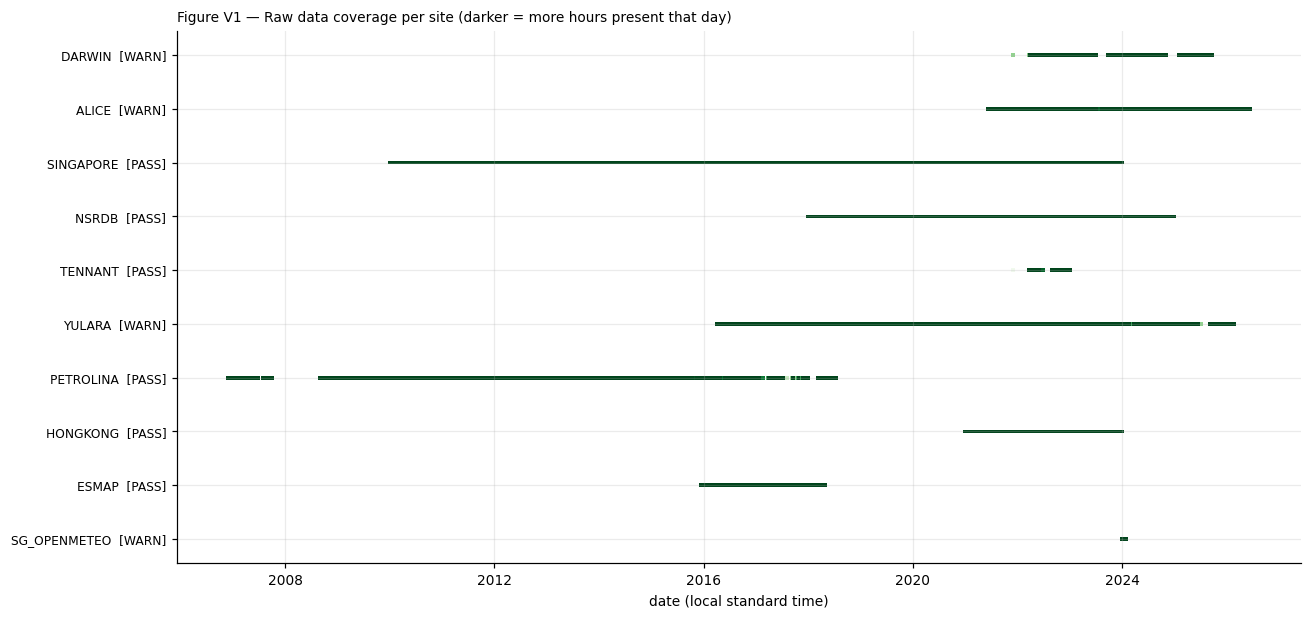

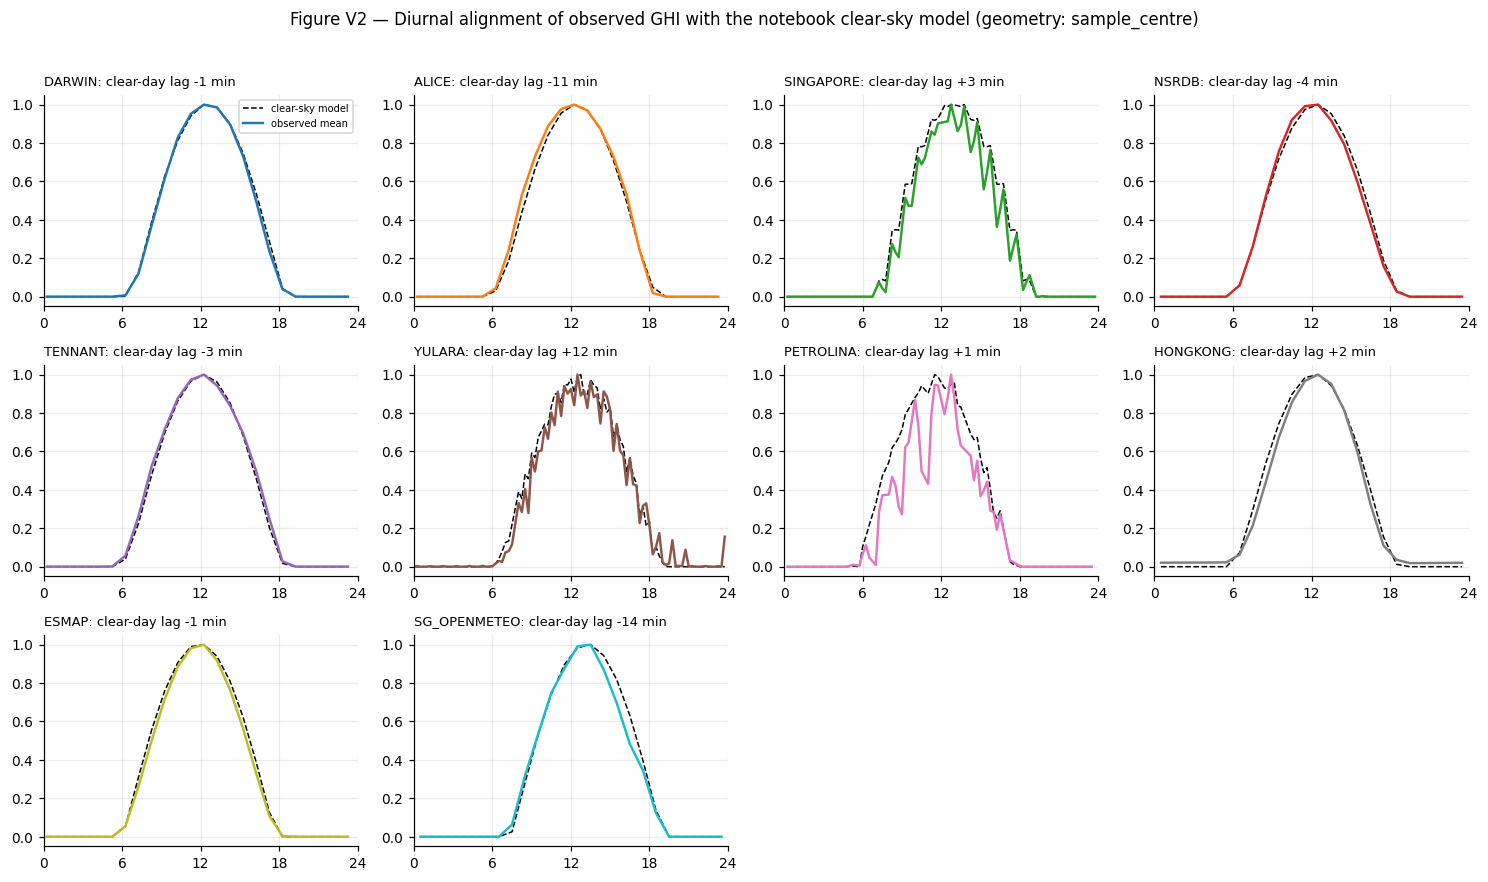

In [ ]:
VAR_RANGES = {"ghi_wm2": (CFG.NEG_TOLERANCE, CFG.GHI_MAX), "temp_c": (-30, 60),
              "rh_pct": (0, 100), "wind_ms": (0, 60), "pv_kw": (0, np.inf)}


def _circ_centroid_h(t_h, w):
    th = 2 * np.pi * np.asarray(t_h) / 24.0
    w = np.clip(np.nan_to_num(np.asarray(w, float)), 0, None)
    if w.sum() <= 0:
        return np.nan
    return (np.degrees(np.arctan2((w * np.sin(th)).sum(), (w * np.cos(th)).sum())) / 15.0) % 24


def diurnal_alignment(d, site, timing):
    """Minutes by which the observed diurnal GHI centroid lags the clear-sky centroid.

    Both profiles are built on the same rows and the same clock, so a correctly timed
    source gives |lag| of a few minutes (cloud asymmetry, e.g. afternoon convection, adds a
    little). A UTC file read as local time gives a lag of ~tz hours; NASA POWER local SOLAR
    time read as standard time gives tens of minutes. Circular statistics make the test
    valid even when a large error pushes daylight across midnight.
    """
    m = SITES[site]
    old = CFG.GEOMETRY_TIMING
    try:
        CFG.GEOMETRY_TIMING = timing
        gt = geometry_times(d, site)
    finally:
        CFG.GEOMETRY_TIMING = old
    cosz, _ = solar_geometry(gt, m["lat"], m["lon"], m["tz"])
    cs = clearsky_haurwitz(cosz)
    g = d["ghi_wm2"].clip(lower=0).to_numpy()
    ok = np.isfinite(g)
    t_h = (gt.hour + gt.minute / 60.0 + gt.second / 3600.0).to_numpy()[ok]
    grp = pd.DataFrame({"h": np.floor(t_h * 4) / 4, "g": g[ok], "cs": cs[ok]}).groupby("h")
    prof, cnt = grp.mean(), grp.size()
    prof = prof[cnt >= 0.2 * cnt.median()]          # drop sparsely populated quarter-hour bins
    c_obs = _circ_centroid_h(prof.index, prof["g"])
    c_cs = _circ_centroid_h(prof.index, prof["cs"])
    lag = ((c_obs - c_cs + 12) % 24 - 12) * 60 if np.isfinite(c_obs) and np.isfinite(c_cs) else np.nan
    night = (cs[ok] <= 0) & (g[ok] > 50)
    return float(lag), float(100 * night.sum() / max((g[ok] > 50).sum(), 1)), prof


VALID_ROWS, PROFILES = [], {}
for site in SITES_OK:
    d = RAW[RAW.site == site].sort_values("ts").reset_index(drop=True)
    ts = d["ts"]
    span_h = (ts.max() - ts.min()) / pd.Timedelta(hours=1) + 1
    step_h = ts.diff().dt.total_seconds().div(3600)
    gaps = step_h[step_h > 1]
    daymask = d["ghi_wm2"] > 20
    r = {"site": site, "source": SOURCE_USED.get(site, "?")[:48], "hourly_rows": len(d),
         "first": ts.min(), "last": ts.max(), "coverage_%": 100 * d["ghi_wm2"].notna().sum() / span_h,
         "n_gaps>1h": int(len(gaps)), "longest_gap_h": float(gaps.max()) if len(gaps) else 0.0,
         "chronological": bool(ts.is_monotonic_increasing)}
    if RAW_STREAM is not None and len(RAW_STREAM):
        used = set(LEDGER[(LEDGER.site == site) & (LEDGER.hourly_rows > 0)].file)
        rs = RAW_STREAM[RAW_STREAM.file.isin(used)]
        r.update({"native_step_min": float(rs.native_step_s.median() / 60) if len(rs) else np.nan,
                  "raw_rows": int(rs.rows_read.sum()) if len(rs) else np.nan,
                  "bad_timestamps": int(rs.bad_ts_n.sum()) if len(rs) else 0,
                  "raw_dup_timestamps": int(rs.dup_ts_within_chunk.sum()) if len(rs) else 0,
                  "raw_non_monotonic": int(rs.non_monotonic_steps.sum()) if len(rs) else 0})
    if CANON_EV is not None and len(CANON_EV):
        ce = CANON_EV[CANON_EV.site == site]
        r.update({"dup_hours_removed": int(ce.duplicate_hours_removed.sum()),
                  "inf_to_nan": int(ce.inf_to_nan.sum())})
    for v, (lo, hi) in VAR_RANGES.items():
        x = d[v]
        r[f"{v}_missing_%"] = 100 * x.isna().mean()
        r[f"{v}_out_of_range"] = int(((x < lo) | (x > hi)).sum())
    g = d["ghi_wm2"]
    r.update({"ghi_min": g.min(), "ghi_p50_day": g[daymask].median(), "ghi_p99": g.quantile(.99),
              "ghi_max": g.max(), "ghi_negative_n": int((g < 0).sum()),
              "dtypes_numeric": bool(all(pd.api.types.is_numeric_dtype(d[c]) for c in VAR_RANGES))})
    lag_v5, _, _ = diurnal_alignment(d, site, "interval_start")
    lag_v6, night_pct, prof = diurnal_alignment(d, site, CFG.GEOMETRY_TIMING)
    lag_clr, n_clr, clr_how = clear_day_lag(d, site)          # the gate statistic
    PROFILES[site] = (prof, lag_clr if np.isfinite(lag_clr) else lag_v6)
    r.update({"lag_min_interval_start": lag_v5, "lag_min_all_days": lag_v6,
              "lag_min_clear_days": lag_clr, "clear_days": n_clr, "clear_day_rule": clr_how,
              "daylight_ghi_at_night_%": night_pct})
    lag_use = lag_clr if np.isfinite(lag_clr) else lag_v6

    status, why = "PASS", []
    p999 = g.quantile(.999)
    if not np.isfinite(p999) or p999 < 5:
        status, why = "FAIL", why + [f"GHI 99.9th pct {p999:.2f}: units look like kW/m2 or no daylight"]
    elif p999 > 2000:
        status, why = "FAIL", why + [f"GHI 99.9th pct {p999:.0f} W/m2: scaling/units error"]
    if np.isfinite(lag_use) and abs(lag_use) > CFG.TIMING_FAIL_MIN:
        status = "FAIL"
        why.append(f"clear-day diurnal lag {lag_use:+.0f} min: time basis wrong "
                   f"(UTC read as local would give ~{-SITES[site]['tz']*60:+.0f} min)")
    elif np.isfinite(lag_use) and abs(lag_use) > CFG.TIMING_GATE_MIN:
        status = "WARN" if status == "PASS" else status
        why.append(f"clear-day diurnal lag {lag_use:+.1f} min exceeds ±{CFG.TIMING_GATE_MIN:g} min")
    if SITES[site].get("time_basis_assumed"):
        if np.isfinite(lag_use) and abs(lag_use) <= CFG.TIMING_GATE_MIN:
            why.append(f"time basis assumed but empirically consistent (clear-day lag {lag_use:+.1f} min)")
        else:
            status = "WARN" if status == "PASS" else status
            why.append("time basis assumed, not stated in file")
    if SITES[site].get("short_record") or site in SECONDARY_SITES:
        status = "WARN" if status == "PASS" else status
        why.append("short record / secondary check — excluded from equatorial conclusions")
    if r["coverage_%"] < 50:
        status = "WARN" if status == "PASS" else status
        why.append(f"coverage {r['coverage_%']:.0f}%")
    if r.get("bad_timestamps", 0) or r.get("raw_non_monotonic", 0):
        status = "WARN" if status == "PASS" else status
        why.append("unparseable or out-of-order raw timestamps")
    r["status"], r["issues"] = status, "; ".join(why)
    VALID_ROWS.append(r)

VALIDATION = pd.DataFrame(VALID_ROWS)
save_table(VALIDATION.assign(first=VALIDATION["first"].astype(str), last=VALIDATION["last"].astype(str)),
           ckd("data_validation"))

show_cols = ["site", "hourly_rows", "first", "last", "coverage_%", "n_gaps>1h", "longest_gap_h",
             "native_step_min", "bad_timestamps", "raw_dup_timestamps", "dup_hours_removed",
             "ghi_min", "ghi_p99", "ghi_max", "ghi_negative_n", "ghi_wm2_out_of_range",
             "lag_min_interval_start", "lag_min_all_days", "lag_min_clear_days", "clear_days",
             "status"]
show_cols = [c for c in show_cols if c in VALIDATION.columns]
print("DATA VALIDATION — raw hourly frames, BEFORE any cleaning (nothing is removed here)")
print("=" * 118)
print(VALIDATION[show_cols].round(2).to_string(index=False))
print("\nMissing % by variable (absent variable = 100%):")
print(VALIDATION[["site"] + [f"{v}_missing_%" for v in VAR_RANGES]].round(1).to_string(index=False))
print("\nOut-of-range counts by variable (flagged here, treated in Part 4 QC):")
print(VALIDATION[["site"] + [f"{v}_out_of_range" for v in VAR_RANGES]].to_string(index=False))
for _, r in VALIDATION.iterrows():
    if r.status != "PASS":
        print(f"  {r.status:<4} {r.site:<10} {r.issues}")
print(textwrap.fill(
    "Reading the lag columns : 'lag_min_clear_days' is the gate statistic — it is measured on "
    "clear days only, so afternoon convection cannot masquerade as a timing error. "
    "Reading the two older lag columns: 'interval_start' is where the initial pipeline evaluated the sun (HH:00) for an "
    "hourly mean centred near HH:30, so a correctly timed 1-s or 1-min source shows a lag of about "
    "-30 min there (the observed curve appears early against the model); 'active' is the "
    "convention used in this run. A lag of whole hours means the "
    "file's time basis (UTC vs local) was read wrongly and that site is excluded below.", 100))

# ---- the final pipeline timing gate on the primary site ----------------------------------------------------------
_pv = VALIDATION.set_index("site").loc[CFG.PRIMARY_SITE]
PRIMARY_LAG = float(_pv["lag_min_clear_days"]) if np.isfinite(_pv["lag_min_clear_days"]) \
    else float(_pv["lag_min_all_days"])
register("timing.primary_clear_day_lag_min", round(PRIMARY_LAG, 2),
         f"{CFG.PRIMARY_SITE}, {int(_pv['clear_days'])} clear days ({_pv['clear_day_rule']})")
register("timing.primary_all_day_lag_min", round(float(_pv["lag_min_all_days"]), 2))
register("timing.primary_lag_v5_convention_min", round(float(_pv["lag_min_interval_start"]), 2))
if abs(PRIMARY_LAG) > CFG.TIMING_GATE_MIN:
    msg = (f"TIMING GATE: {CFG.PRIMARY_SITE} clear-day diurnal lag is {PRIMARY_LAG:+.1f} min "
           f"(gate ±{CFG.TIMING_GATE_MIN:g} min). Headline results were shown to move materially under a "
           f"~30 min shift (the initial pipeline -> an intermediate pipeline), so modelling on this record would not be defensible. Check the "
           f"MEASURED TIMESTAMP OFFSETS table in Part 3.2 (Local minus UTC must equal "
           f"{SITES[CFG.PRIMARY_SITE]['tz']:+g} h) and the label convention of the source.")
    if CFG.TIMING_GATE_ENFORCE:
        raise RuntimeError(msg)
    log(msg + "  [gate NOT enforced — results are provisional]", "err")
    register("timing.gate_passed", False)
else:
    log(f"TIMING GATE passed: {CFG.PRIMARY_SITE} clear-day lag {PRIMARY_LAG:+.1f} min "
        f"(±{CFG.TIMING_GATE_MIN:g})", "ok")
    register("timing.gate_passed", True)

# ---- exclusion: FAIL sites leave the pipeline; the primary site may not fail silently --------
FAILED = VALIDATION[VALIDATION.status == "FAIL"]
if CFG.PRIMARY_SITE in set(FAILED.site):
    raise RuntimeError(f"Primary site {CFG.PRIMARY_SITE} failed validation: "
                       f"{FAILED.set_index('site').loc[CFG.PRIMARY_SITE, 'issues']}")
for _, r in FAILED.iterrows():
    log(f"{r.site} EXCLUDED from all analysis: {r.issues}. If the file's time basis is documented "
        f"as UTC, set TIME_BASIS_OVERRIDE['{r.site}'] = 'utc' in Part 3.2 and re-run.", "err")
register("validation.excluded_sites", {r.site: r.issues for _, r in FAILED.iterrows()})
SITES_OK = [s for s in SITES_OK if s not in set(FAILED.site)]
print(f"\nSites passing validation and continuing: {SITES_OK}")
register("validation.sites_continuing", list(SITES_OK))

# ---- Figure V1: coverage timeline -------------------------------------------------------------
_pal = plt.get_cmap("tab10")
fig, ax = plt.subplots(figsize=(12, 0.45 * len(VALIDATION) + 1.2))
for i, site in enumerate(VALIDATION.site):
    d = RAW[RAW.site == site]
    daily = d.set_index("ts")["ghi_wm2"].notna().resample("D").mean()
    ok = daily[daily > 0]
    ax.scatter(ok.index, np.full(len(ok), i), c=ok.values, cmap="Greens", vmin=0, vmax=1,
               s=6, marker="s", linewidths=0)
ax.set_yticks(range(len(VALIDATION)))
ax.set_yticklabels([f"{s}  [{st}]" for s, st in zip(VALIDATION.site, VALIDATION.status)], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("date (local standard time)")
ax.set_title("Figure V1 — Raw data coverage per site (darker = more hours present that day)",
             loc="left", fontsize=9)
savefig(fig, "figV1_coverage"); plt.show()

# ---- Figure V2: diurnal timing alignment --------------------------------------------------------
n = len(PROFILES)
ncol = min(n, 4); nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 2.6 * nrow), squeeze=False)
for ax, (site, (prof, lag)) in zip(axes.ravel(), PROFILES.items()):
    ax.plot(prof.index, prof["cs"] / max(prof["cs"].max(), 1e-9), "k--", lw=1, label="clear-sky model")
    ax.plot(prof.index, prof["g"] / max(prof["g"].max(), 1e-9), color=_pal(list(PROFILES).index(site) % 10),
            lw=1.6, label="observed mean")
    ax.set_title(f"{site}: clear-day lag {lag:+.0f} min", fontsize=8.5, loc="left")
    ax.set_xticks([0, 6, 12, 18, 24]); ax.set_xlim(0, 24)
for ax in axes.ravel()[n:]:
    ax.set_visible(False)
axes[0, 0].legend(fontsize=6.5)
fig.suptitle("Figure V2 — Diurnal alignment of observed GHI with the notebook clear-sky model "
             f"(geometry: {CFG.GEOMETRY_TIMING})", y=1.02)
savefig(fig, "figV2_timing"); plt.show()

---
# **Research Stage#7 — Cleaning, Clear-Sky index and Feature Construction**

**Cleaning rules** (evidence and effect are shown in the QC and imputation ledgers):

* hard negatives and values above 1,400 W/m² → missing;
* GHI above 1.3 × clear-sky → flagged non-physical and removed;
* night → structural zero;
* k_t capped at 1.3;
* daylight gaps of ≤ 3 h interpolated **in k_t space**, with longer gaps left missing, so no weather is invented.

**Covariates.** Short gaps are bridged. An observed-only copy (`*_obs`) is kept with **no** whole-record climatology fill, because such a fill would draw on test-period values.

In [ ]:
def qc_and_kt(df: pd.DataFrame, site: str) -> pd.DataFrame:
    d = attach_solar(df.copy(), site)

    # ---- reindex onto a complete hourly grid: this is what EXPOSES the gaps -----
    full = pd.date_range(d["ts"].min(), d["ts"].max(), freq=CFG.TARGET_FREQ)
    d = (d.set_index("ts").reindex(full).rename_axis("ts").reset_index())
    d = attach_solar(d.drop(columns=["cos_zenith", "ghi_toa", "ghi_cs", "is_daylight"]), site)
    d.insert(0, "site", site)

    g = d["ghi_wm2"]
    d["qc_raw_missing"] = g.isna()

    g = g.where(g >= CFG.NEG_TOLERANCE)              # hard negatives -> NaN
    g = g.clip(lower=0.0)                            # small offsets -> 0
    g = g.where(g <= CFG.GHI_MAX)                    # absurd values -> NaN
    over = (g > CFG.KT_MAX * d["ghi_cs"]) & (d["ghi_cs"] > CFG.DAYLIGHT_CS_MIN)
    d["qc_nonphysical"] = over.fillna(False)
    g = g.where(~d["qc_nonphysical"])
    g = g.where(d["is_daylight"], 0.0)               # night is a structural zero
    d["ghi_wm2"] = g

    # ---- clear-sky index --------------------------------------------------------
    with np.errstate(divide="ignore", invalid="ignore"):
        kt = np.where(d["is_daylight"], d["ghi_wm2"] / d["ghi_cs"].replace(0, np.nan), 0.0)
    d["kt"] = np.clip(kt, 0.0, CFG.KT_MAX)
    d.loc[d["ghi_wm2"].isna(), "kt"] = np.nan

    # ---- covariate QC -----------------------------------------------------------
    d["temp_c"] = d["temp_c"].where(d["temp_c"].between(-30, 60))
    d["rh_pct"] = d["rh_pct"].clip(0, 100)
    d["wind_ms"] = d["wind_ms"].where(d["wind_ms"].between(0, 60))
    if "pv_kw" in d:
        d["pv_kw"] = d["pv_kw"].clip(lower=0)
    return d


def _gap_lengths(mask: pd.Series) -> pd.Series:
    """For each NaN position, the length of the contiguous NaN run containing it."""
    grp = (mask != mask.shift()).cumsum()
    return mask.groupby(grp).transform("size").where(mask, 0)


def impute(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()
    day = d["is_daylight"].to_numpy()

    # --- target: gap-aware interpolation in kt space -----------------------------
    kt = d["kt"]
    miss = kt.isna() & day
    runs = _gap_lengths(miss)
    short = miss & (runs <= CFG.MAX_INTERP_GAP_H)

    kt_i = kt.interpolate(method="linear", limit=CFG.MAX_INTERP_GAP_H,
                          limit_area="inside")
    d["kt"] = np.where(short, kt_i, kt)
    d["kt_imputed"] = short
    d["kt_unrecoverable"] = miss & ~short

    d["ghi_wm2"] = np.where(d["kt"].notna(), d["kt"] * d["ghi_cs"], np.nan)
    d.loc[~day, "ghi_wm2"] = 0.0

    # --- covariates: interpolate then fall back to site-hour climatology ---------
    for c in ("temp_c", "rh_pct", "wind_ms"):
        s = d[c]
        d[f"{c}_imputed"] = s.isna()
        s = s.interpolate(method="linear", limit=6, limit_area="inside")
        # an observed-only copy (short gaps bridged, NO climatology fill). The climatology below
        # is computed over the whole record, i.e. partly from the test period; that is harmless for
        # a covariate that the screen removes, but not for one a model actually uses. Part R5 uses
        # the *_obs columns and drops windows where they are missing.
        d[f"{c}_obs"] = s
        clim = s.groupby([d["ts"].dt.month, d["ts"].dt.hour]).transform("median")
        s = s.fillna(clim).fillna(s.median())
        d[c] = s
    return d

### **Research Stage#7.1 Engineered features (All Strictly Past-Looking)**

* **k_t history:** level; lags of 1, 2, 3 and 24 h; 3 h and 24 h rolling mean and SD, each shifted so it uses only earlier hours.
* **Solar geometry:** cos zenith, clear-sky level.
* **Calendar:** hour and day-of-year sine/cosine.
* **Season:** `is_wet`.

In [ ]:
BASE_FEATURES = [
    "kt", "kt_lag1", "kt_lag2", "kt_lag3", "kt_lag24",
    "kt_roll3_mean", "kt_roll3_std", "kt_roll24_mean", "kt_roll24_std",
    "cos_zenith", "ghi_cs_norm",
    "temp_c", "rh_pct", "wind_ms",
    "hour_sin", "hour_cos", "doy_sin", "doy_cos",
]
SEASON_FEATURE = "is_wet"
ALL_FEATURES = BASE_FEATURES + [SEASON_FEATURE]


def engineer(d: pd.DataFrame, site: str) -> pd.DataFrame:
    d = d.copy()
    ts = d["ts"]

    d["hour_sin"] = np.sin(2 * np.pi * ts.dt.hour / 24)
    d["hour_cos"] = np.cos(2 * np.pi * ts.dt.hour / 24)
    d["doy_sin"] = np.sin(2 * np.pi * ts.dt.dayofyear / 365.25)
    d["doy_cos"] = np.cos(2 * np.pi * ts.dt.dayofyear / 365.25)

    d["is_wet"] = ts.dt.month.isin(SITES[site]["wet_months"]).astype(float)
    d["season"] = np.where(d["is_wet"] > 0, SITES[site]["season_names"][1],
                           SITES[site]["season_names"][0])

    for L in (1, 2, 3, 24):
        d[f"kt_lag{L}"] = d["kt"].shift(L)
    for W in (3, 24):
        r = d["kt"].rolling(W, min_periods=max(2, W // 3))
        d[f"kt_roll{W}_mean"] = r.mean().shift(1)
        d[f"kt_roll{W}_std"] = r.std().shift(1)

    d["ghi_cs_norm"] = d["ghi_cs"] / 1100.0
    d["dkt"] = d["kt"].diff()
    d["is_ramp"] = (d["dkt"].abs() > CFG.RAMP_KT_THRESHOLD) & d["is_daylight"]
    return d


def build_features() -> pd.DataFrame:
    out = []
    for site in SITES_OK:
        d = RAW[RAW.site == site].drop(columns=["site"]).reset_index(drop=True)
        d = qc_and_kt(d, site)
        d = impute(d)
        d = engineer(d, site)
        out.append(d)
        log(f"{site:<10} features built: {len(d):,} rows, "
            f"{d['is_daylight'].sum():,} daylight hours", "ok")
    return pd.concat(out, ignore_index=True)


FEAT = checkpoint(ckd("features_hourly"), build_features)
FEAT = FEAT[FEAT.site.isin(SITES_OK)].reset_index(drop=True)


# ---- imputation ledger: report exactly what was filled and what was surrendered ----
rows = []
for site in SITES_OK:
    d = FEAT[FEAT.site == site]
    day = d[d.is_daylight]
    rows.append({
        "site": site,
        "hours_total": len(d),
        "daylight_hours": len(day),
        "raw_missing_%": 100 * d.qc_raw_missing.mean(),
        "nonphysical_%": 100 * d.qc_nonphysical.mean(),
        "kt_interpolated_%": 100 * d.kt_imputed.mean(),
        "kt_unrecoverable_%": 100 * d.kt_unrecoverable.mean(),
        "temp_imputed_%": 100 * d.temp_c_imputed.mean(),
        "rh_imputed_%": 100 * d.rh_pct_imputed.mean(),
        "wind_imputed_%": 100 * d.wind_ms_imputed.mean(),
        "ramp_hours_%": 100 * d.is_ramp.sum() / max(len(day), 1),
    })
IMPUTE_LEDGER = pd.DataFrame(rows).round(2)
print("\nIMPUTATION & QC LEDGER  (all figures are % of hours unless stated)")
print(IMPUTE_LEDGER.to_string(index=False))
save_table(IMPUTE_LEDGER, "impute_ledger")

[ 5185.6s |   2516MB]  ok checkpoint hit  'features_hourly_v7_8be37a7834_EXT_sample_EXT'  (507,928 rows)

IMPUTATION & QC LEDGER  (all figures are % of hours unless stated)
        site  hours_total  daylight_hours  raw_missing_%  nonphysical_%  kt_interpolated_%  kt_unrecoverable_%  temp_imputed_%  rh_imputed_%  wind_imputed_%  ramp_hours_%
      DARWIN        33533           16045          22.82           0.58               0.59               11.12           22.88         22.80           48.64         11.65
       ALICE        44127           21197           0.97          10.39               8.36                2.45            1.13          0.97           36.16         18.47
   SINGAPORE       122712           61356           0.00           0.06               0.06                0.00            0.00          0.00            0.00          5.13
       NSRDB        61368           29686           0.00           0.44               0.44                0.00            0.00          0.00   

PosixPath('/content/drive/MyDrive/_tropicalpv_artifacts/impute_ledger.parquet')

# **PART E · Exploratory Data Analysis**

> *Navigation header added for the VIVA. It covers Stage 8 below. No original cell was changed.*

---
# **Research Stage#8 — Exploratory Data Analysis**

Each figure answers a question the later modelling needs answered:

* availability → which periods can be modelled;
* diurnal and seasonal structure → whether `is_wet` could matter;
* k_t distributions by site → domain shift;
* ramps → where errors will concentrate;
* correlation and autocorrelation → why persistence is hard to beat at t+1;
* clear-sky validation → whether the timing correction holds at every site.

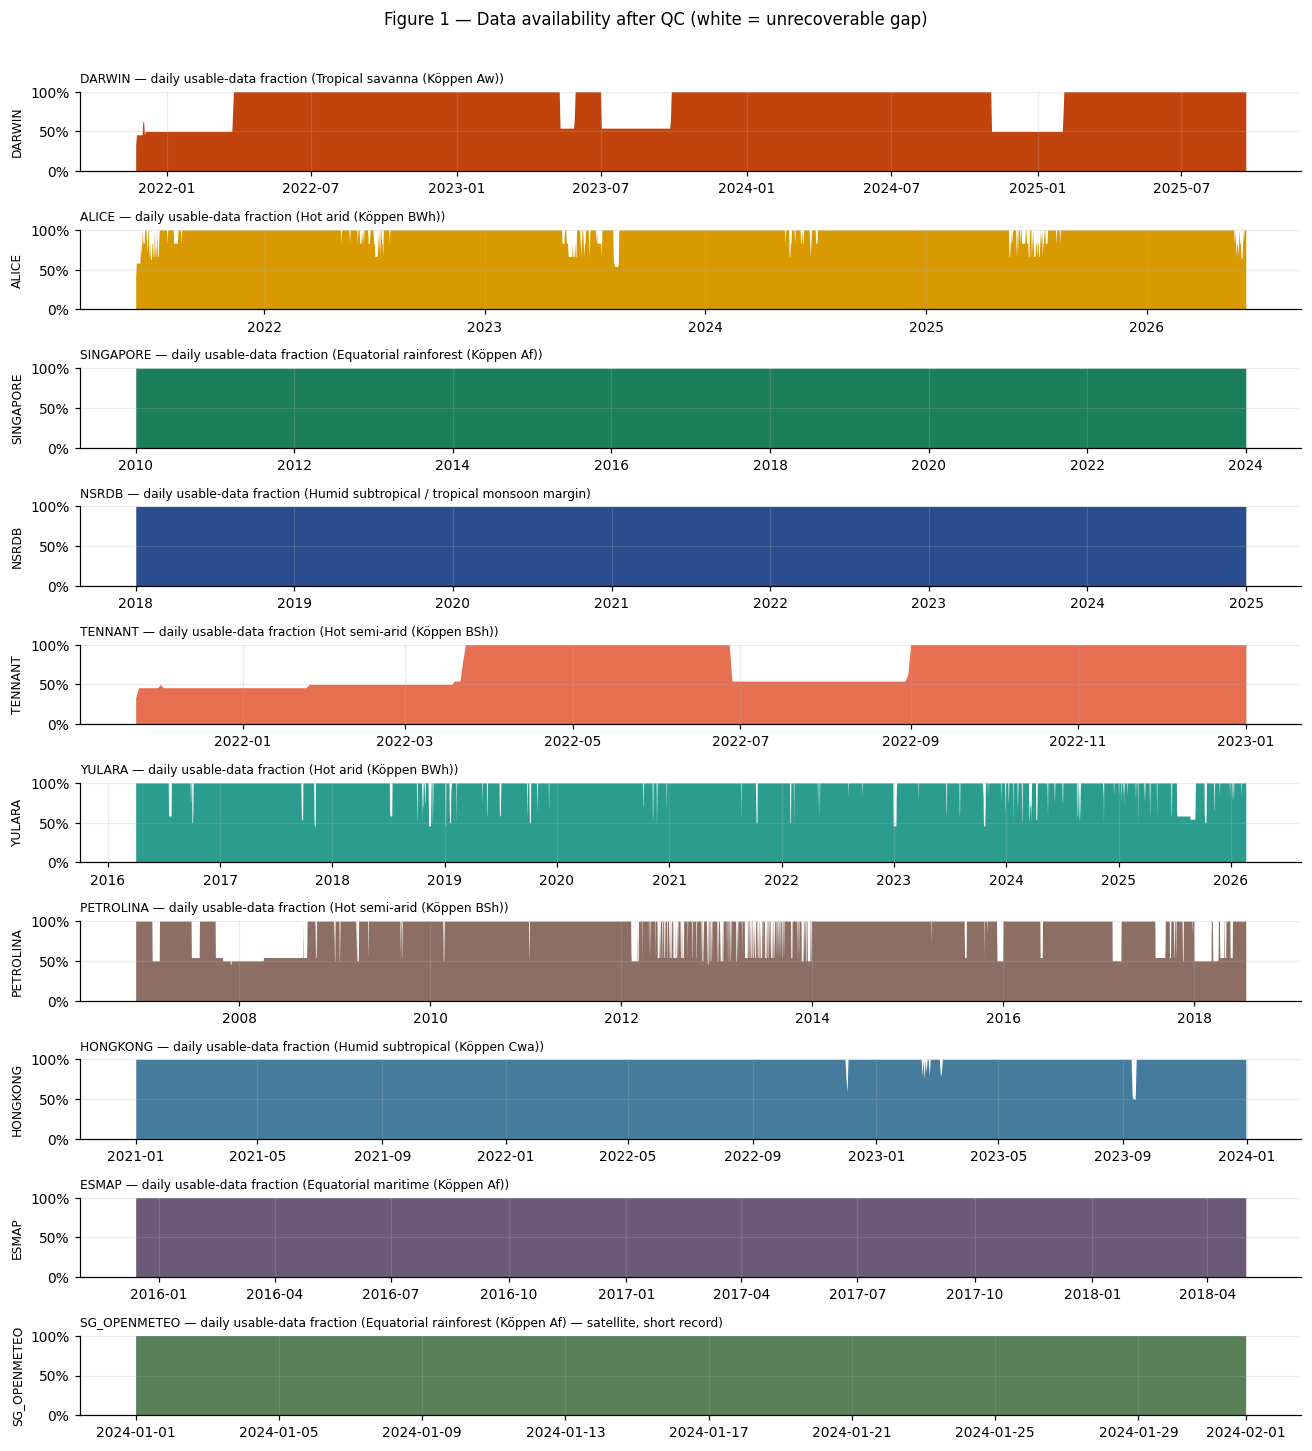

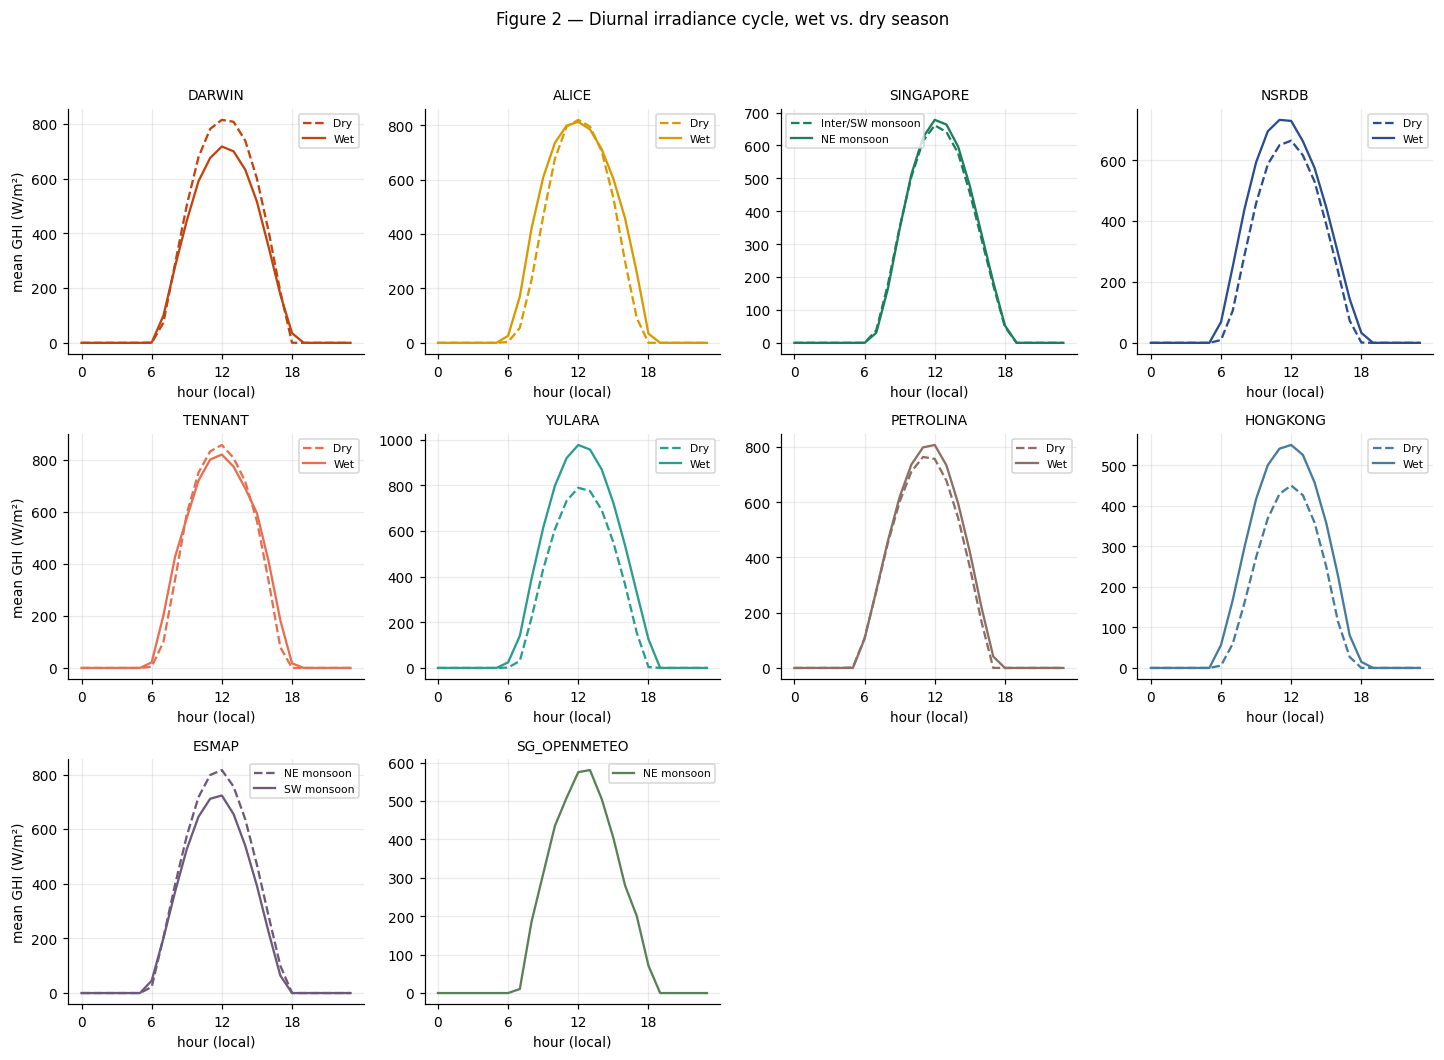

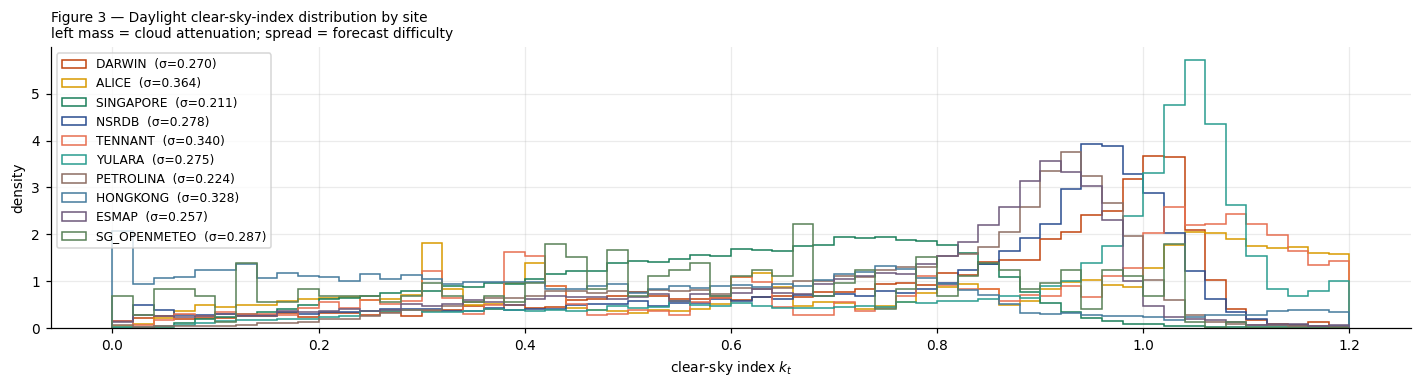

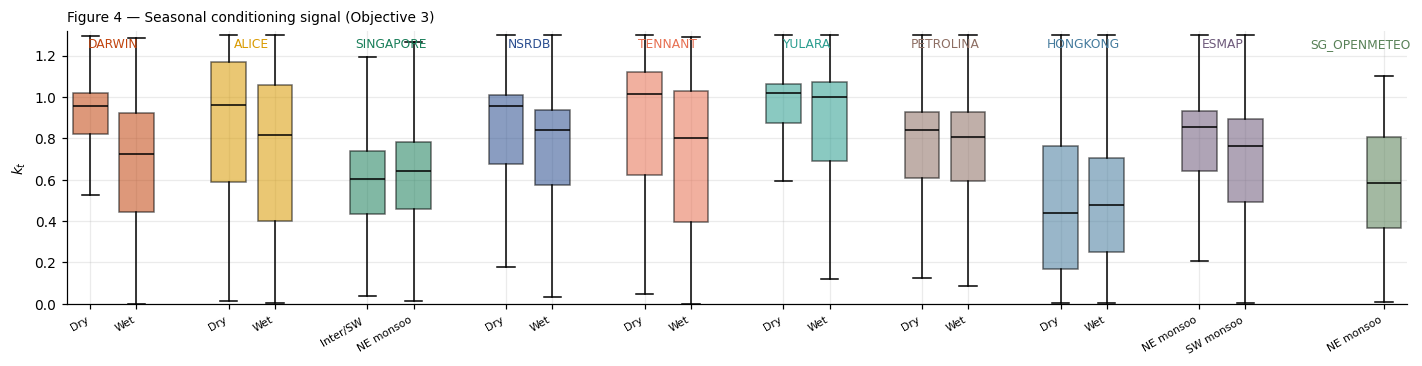

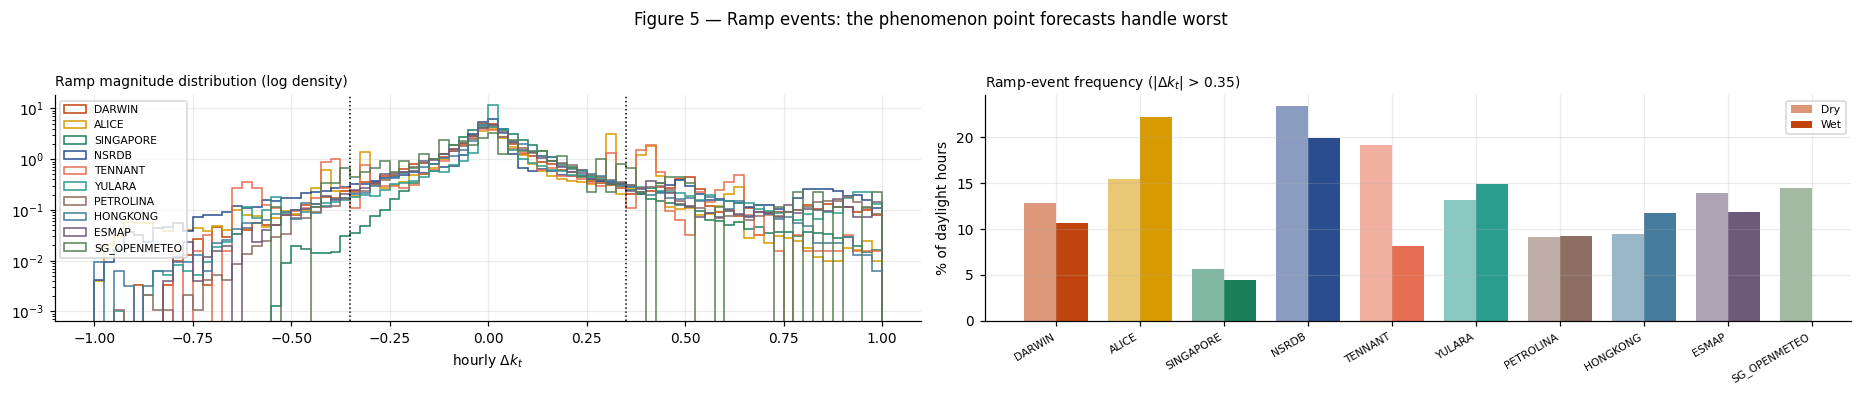

        site           season  ramp_rate
      DARWIN              Dry      12.79
      DARWIN              Wet      10.61
       ALICE              Dry      15.44
       ALICE              Wet      22.22
   SINGAPORE Inter/SW monsoon       5.59
   SINGAPORE       NE monsoon       4.48
       NSRDB              Dry      23.39
       NSRDB              Wet      19.86
     TENNANT              Dry      19.10
     TENNANT              Wet       8.19
      YULARA              Dry      13.11
      YULARA              Wet      14.94
   PETROLINA              Dry       9.14
   PETROLINA              Wet       9.19
    HONGKONG              Dry       9.41
    HONGKONG              Wet      11.73
       ESMAP       NE monsoon      13.92
       ESMAP       SW monsoon      11.86
SG_OPENMETEO       NE monsoon      14.44


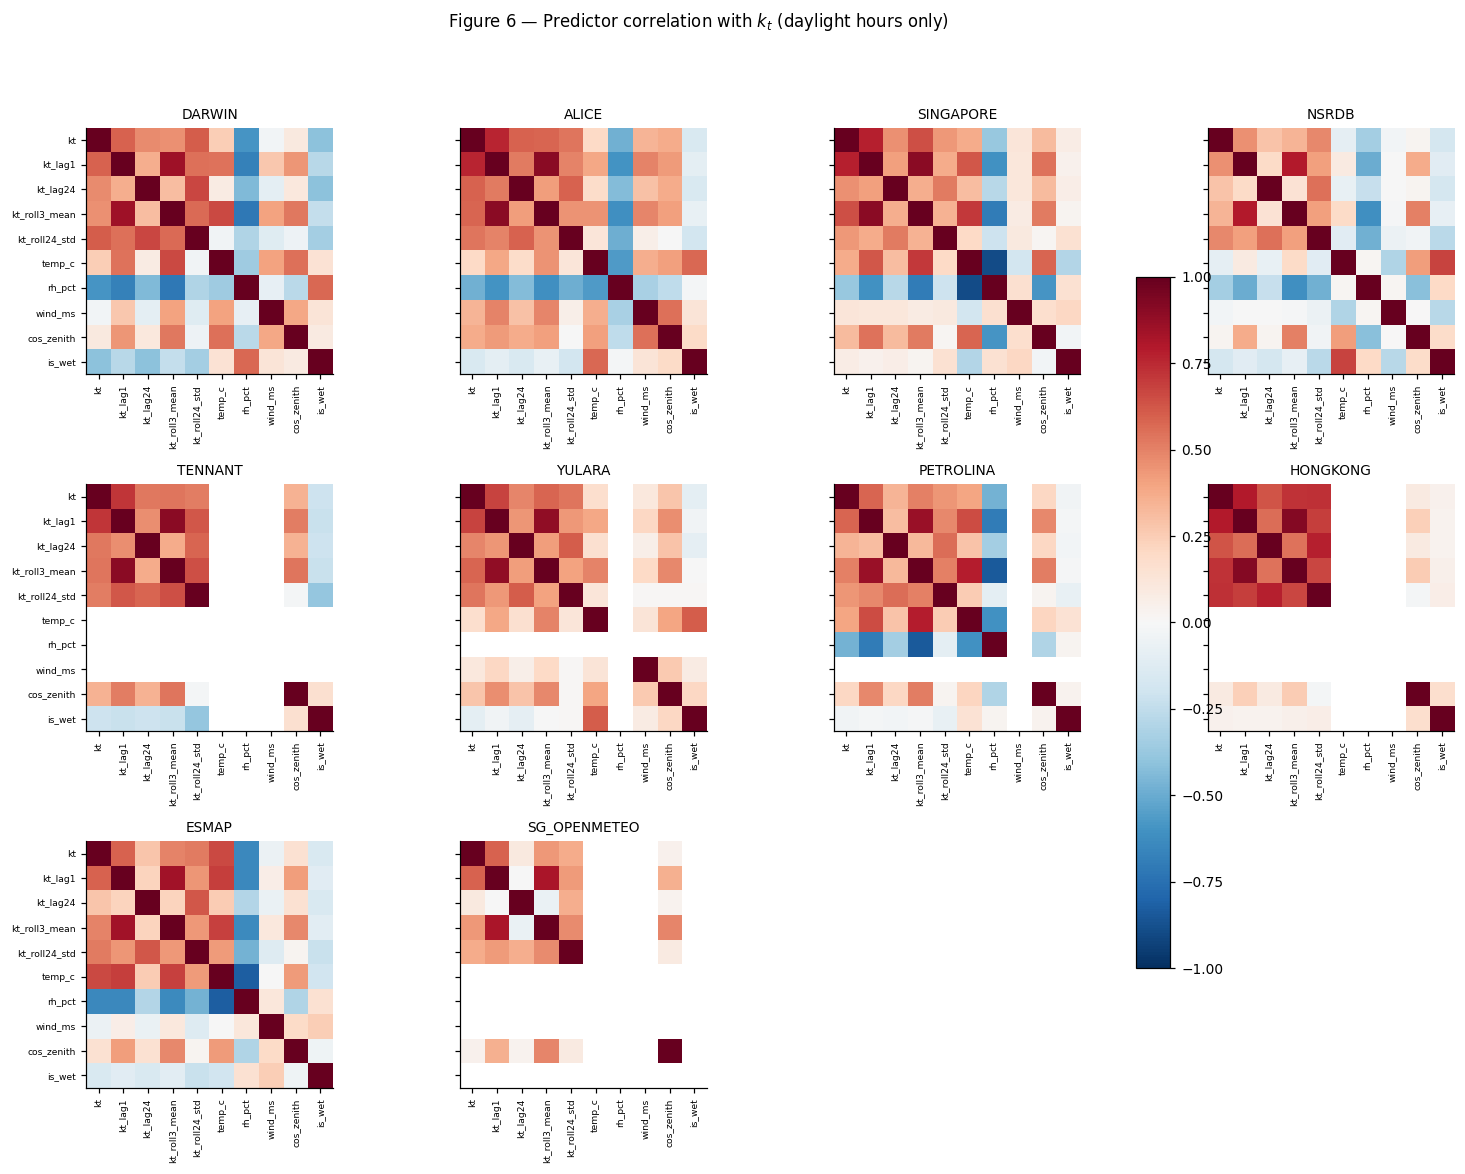

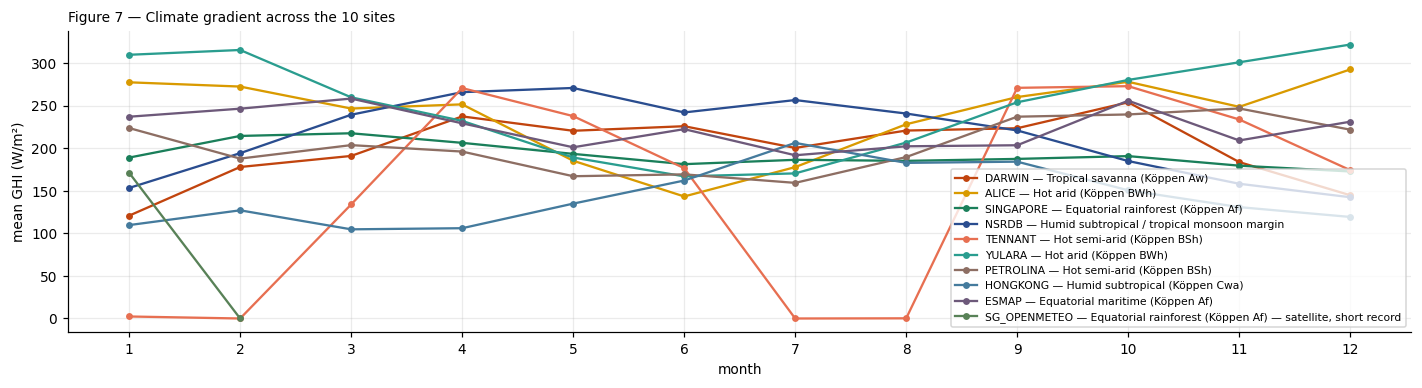

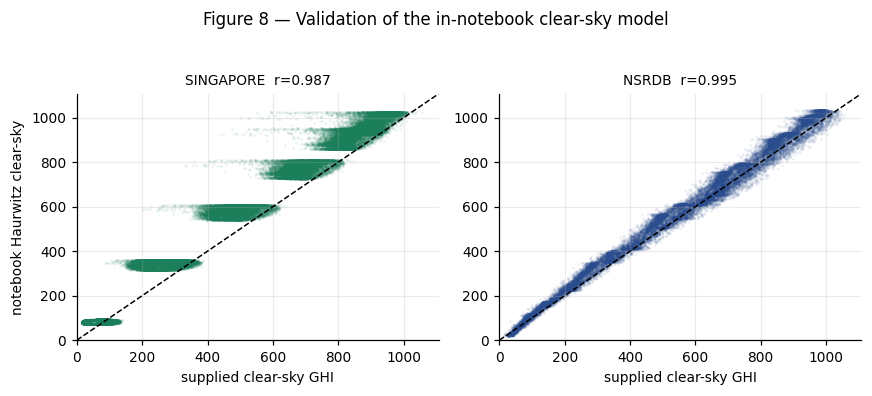

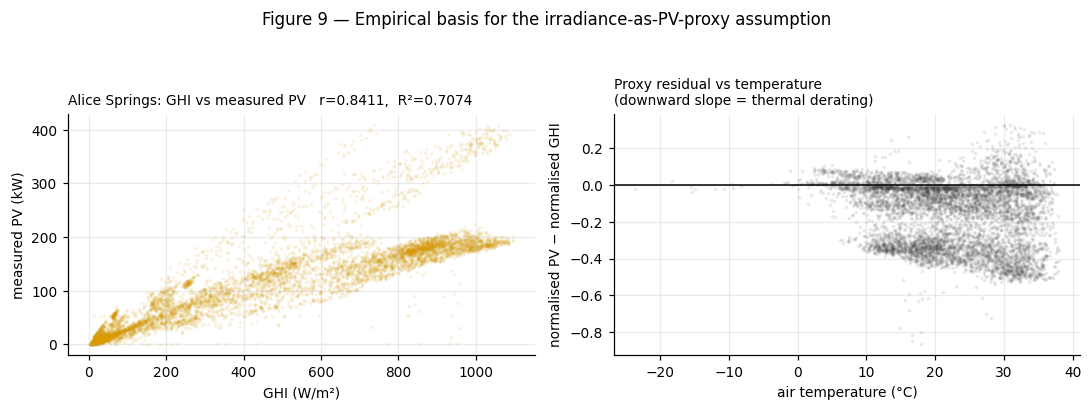

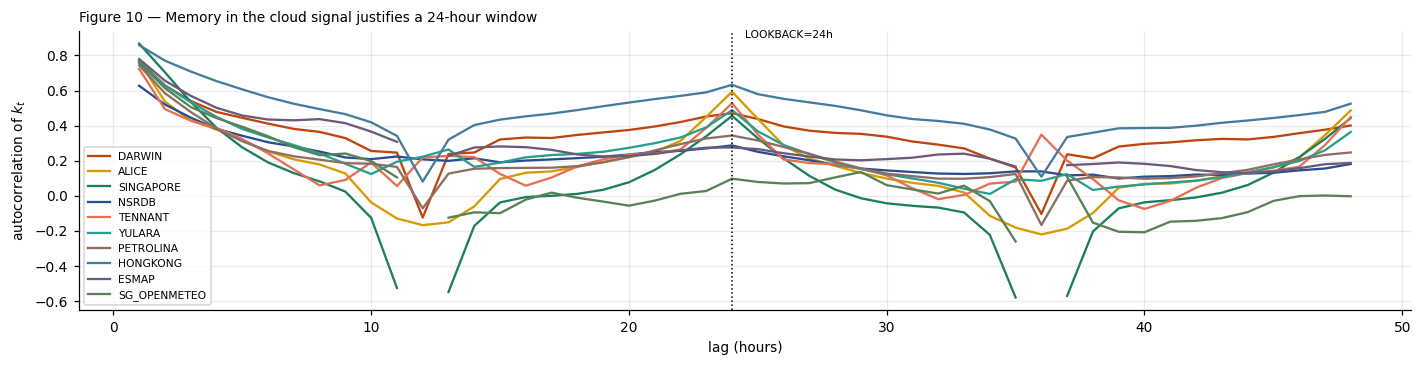

In [ ]:
SITE_COLOR = {"DARWIN": "#c1440e", "ALICE": "#d99a00",
              "SINGAPORE": "#1a7f5a", "NSRDB": "#2a4d8f"}
# an intermediate pipeline: colours for the EXTENDED sites (the initial pipeline raised KeyError for any site outside the four)
_extra = ["#7b2cbf", "#e76f51", "#2a9d8f", "#8d6e63", "#457b9d", "#6d597a", "#588157", "#bc4749"]
for _i, _s in enumerate([s for s in SITES if s not in SITE_COLOR]):
    SITE_COLOR[_s] = _extra[_i % len(_extra)]


def site_grid(n, w=3.4, h=3.1, ncol_max=4):
    """Subplot grid that wraps after ncol_max panels (the initial pipeline used one row: 10 sites = 34 in wide)."""
    ncol = max(1, min(n, ncol_max))
    nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(w * ncol, h * nrow), squeeze=False)
    for ax in axes.ravel()[n:]:
        ax.set_visible(False)
    return fig, axes


WIDE = max(7.5, 0.95 * len(SITES_OK) + 3.5)     # width for single-panel cross-site figures


def _daylight(site):
    return FEAT[(FEAT.site == site) & FEAT.is_daylight]


# ---------------- Figure 1: data availability ---------------------------------
fig, axes = plt.subplots(len(SITES_OK), 1, figsize=(12, (1.9 if len(SITES_OK) <= 4 else 1.3) * len(SITES_OK)),
                         squeeze=False)
for ax, site in zip(axes[:, 0], SITES_OK):
    d = FEAT[FEAT.site == site]
    daily = (d.assign(day=d.ts.dt.floor("D"))
              .groupby("day")
              .agg(avail=("kt_unrecoverable", lambda s: 1 - s.mean())))
    ax.fill_between(daily.index, 0, daily.avail, color=SITE_COLOR[site], lw=0)
    ax.set_ylim(0, 1); ax.set_ylabel(site, fontsize=8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(f"{site} — daily usable-data fraction "
                 f"({SITES[site]['climate']})", fontsize=8, loc="left")
fig.suptitle("Figure 1 — Data availability after QC (white = unrecoverable gap)", y=1.01)
savefig(fig, "fig01_availability"); plt.show()

# ---------------- Figure 2: diurnal cycle by season ----------------------------
fig, axes = site_grid(len(SITES_OK), 3.3, 3.1)
for ax, site in zip(axes.ravel(), SITES_OK):
    d = FEAT[FEAT.site == site]
    for wet, style in ((0.0, "--"), (1.0, "-")):
        sub = d[d.is_wet == wet]
        if not len(sub):
            continue
        prof = sub.groupby(sub.ts.dt.hour)["ghi_wm2"].mean()
        ax.plot(prof.index, prof.values, style, color=SITE_COLOR[site],
                label=SITES[site]["season_names"][int(wet)])
    ax.set_title(site, fontsize=9); ax.set_xlabel("hour (local)")
    ax.set_xticks([0, 6, 12, 18]); ax.legend(fontsize=7)
for row in axes:
    row[0].set_ylabel("mean GHI (W/m²)")
fig.suptitle("Figure 2 — Diurnal irradiance cycle, wet vs. dry season", y=1.03)
savefig(fig, "fig02_diurnal"); plt.show()

# ---------------- Figure 3: kt distribution ------------------------------------
fig, ax = plt.subplots(figsize=(WIDE, 3.6))
for site in SITES_OK:
    ax.hist(_daylight(site)["kt"].dropna(), bins=60, range=(0, 1.2), density=True,
            histtype="step", lw=1.8, color=SITE_COLOR[site],
            label=f"{site}  (σ={_daylight(site)['kt'].std():.3f})")
ax.set_xlabel("clear-sky index $k_t$"); ax.set_ylabel("density"); ax.legend(fontsize=8)
ax.set_title("Figure 3 — Daylight clear-sky-index distribution by site\n"
             "left mass = cloud attenuation; spread = forecast difficulty", loc="left", fontsize=9)
savefig(fig, "fig03_kt_dist"); plt.show()

# ---------------- Figure 4: seasonal split -------------------------------------
fig, ax = plt.subplots(figsize=(WIDE, 3.4))
pos, ticks = [], []
for i, site in enumerate(SITES_OK):
    d = _daylight(site)
    cand = [(0, d[d.is_wet == 0]["kt"].dropna()), (1, d[d.is_wet == 1]["kt"].dropna())]
    cand = [(k, x) for k, x in cand if len(x) > 10]
    if not cand:
        continue
    data = [x for _, x in cand]
    ppos = [i * 3 + k for k, _ in cand]
    bp = ax.boxplot(data, positions=ppos, widths=.75,
                    patch_artist=True, showfliers=False)
    for b in bp["boxes"]:
        b.set_facecolor(SITE_COLOR[site]); b.set_alpha(.55)
    for m in bp["medians"]:
        m.set_color("k")
    pos += ppos
    ticks += [SITES[site]["season_names"][k][:9] for k, _ in cand]
ax.set_xticks(pos); ax.set_xticklabels(ticks, rotation=30, ha="right", fontsize=7)
for i, site in enumerate(SITES_OK):
    ax.text(i * 3 + .5, 1.24, site, ha="center", fontsize=8, color=SITE_COLOR[site])
ax.set_ylabel("$k_t$"); ax.set_ylim(0, 1.32)
ax.set_title("Figure 4 — Seasonal conditioning signal (Objective 3)", loc="left", fontsize=9)
savefig(fig, "fig04_seasonal"); plt.show()

# ---------------- Figure 5: ramp events ----------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(max(11, WIDE + 4), 3.4))
rr = []
for site in SITES_OK:
    d = _daylight(site)
    axes[0].hist(d["dkt"].dropna(), bins=80, range=(-1, 1), density=True,
                 histtype="step", lw=1.6, color=SITE_COLOR[site], label=site)
    for wet in (0.0, 1.0):
        sub = d[d.is_wet == wet]
        if len(sub):
            rr.append({"site": site, "season": SITES[site]["season_names"][int(wet)],
                       "ramp_rate": 100 * sub["is_ramp"].mean()})
axes[0].axvline(-CFG.RAMP_KT_THRESHOLD, color="k", ls=":", lw=1)
axes[0].axvline(CFG.RAMP_KT_THRESHOLD, color="k", ls=":", lw=1)
axes[0].set_yscale("log"); axes[0].set_xlabel("hourly Δ$k_t$"); axes[0].legend(fontsize=7)
axes[0].set_title("Ramp magnitude distribution (log density)", fontsize=9, loc="left")

RAMP = pd.DataFrame(rr)
w = 0.38
for j, site in enumerate(SITES_OK):
    sub = RAMP[RAMP.site == site]
    for k, (_, r) in enumerate(sub.iterrows()):
        axes[1].bar(j + (k - .5) * w, r.ramp_rate, w, color=SITE_COLOR[site],
                    alpha=.55 if k == 0 else 1.0,
                    label=r.season if j == 0 else None)
axes[1].set_xticks(range(len(SITES_OK))); axes[1].set_xticklabels(SITES_OK, fontsize=7, rotation=30, ha="right")
axes[1].set_ylabel("% of daylight hours"); axes[1].legend(fontsize=7)
axes[1].set_title(f"Ramp-event frequency (|Δ$k_t$| > {CFG.RAMP_KT_THRESHOLD})",
                  fontsize=9, loc="left")
fig.suptitle("Figure 5 — Ramp events: the phenomenon point forecasts handle worst", y=1.04)
savefig(fig, "fig05_ramps"); plt.show()
print(RAMP.round(2).to_string(index=False))

# ---------------- Figure 6: correlation ----------------------------------------
corr_cols = ["kt", "kt_lag1", "kt_lag24", "kt_roll3_mean", "kt_roll24_std",
             "temp_c", "rh_pct", "wind_ms", "cos_zenith", "is_wet"]
fig, axes = site_grid(len(SITES_OK), 3.5, 3.4)
for ax, site in zip(axes.ravel(), SITES_OK):
    c = _daylight(site)[corr_cols].corr()
    im = ax.imshow(c, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(corr_cols)))
    ax.set_xticklabels(corr_cols, rotation=90, fontsize=6)
    ax.set_yticks(range(len(corr_cols)))
    ax.set_yticklabels(corr_cols if ax in axes[:, 0] else [], fontsize=6)
    ax.set_title(site, fontsize=9); ax.grid(False)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=.8)
fig.suptitle("Figure 6 — Predictor correlation with $k_t$ (daylight hours only)", y=1.04)
savefig(fig, "fig06_corr"); plt.show()

# ---------------- Figure 7: cross-site monthly GHI ------------------------------
fig, ax = plt.subplots(figsize=(WIDE, 3.6))
for site in SITES_OK:
    d = FEAT[FEAT.site == site]
    m = d.groupby(d.ts.dt.month)["ghi_wm2"].mean()
    ax.plot(m.index, m.values, "-o", ms=3.5, color=SITE_COLOR[site],
            label=f"{site} — {SITES[site]['climate']}")
ax.set_xticks(range(1, 13)); ax.set_xlabel("month"); ax.set_ylabel("mean GHI (W/m²)")
ax.legend(fontsize=7)
ax.set_title(f"Figure 7 — Climate gradient across the {len(SITES_OK)} sites", loc="left", fontsize=9)
savefig(fig, "fig07_crosssite"); plt.show()

# ---------------- Figure 8: clear-sky validation --------------------------------
val_sites = [s for s in SITES_OK if FEAT[(FEAT.site == s)]["ghi_cs_src"].notna().any()]
if val_sites:
    fig, axes = site_grid(len(val_sites), 4, 3.4)
    for ax, site in zip(axes.ravel(), val_sites):
        d = _daylight(site).dropna(subset=["ghi_cs_src"])
        ax.scatter(d["ghi_cs_src"], d["ghi_cs"], s=1, alpha=.05, color=SITE_COLOR[site])
        lim = [0, max(d["ghi_cs_src"].max(), d["ghi_cs"].max()) * 1.05]
        ax.plot(lim, lim, "k--", lw=1)
        r = np.corrcoef(d["ghi_cs_src"], d["ghi_cs"])[0, 1]
        ax.set_title(f"{site}  r={r:.3f}", fontsize=9)
        ax.set_xlabel("supplied clear-sky GHI"); ax.set_xlim(lim); ax.set_ylim(lim)
    for row in axes:
        row[0].set_ylabel("notebook Haurwitz clear-sky")
    fig.suptitle("Figure 8 — Validation of the in-notebook clear-sky model", y=1.04)
    savefig(fig, "fig08_clearsky"); plt.show()

# ---------------- Figure 9: irradiance vs measured PV (the proxy assumption) -----
if "ALICE" in SITES_OK and FEAT[FEAT.site == "ALICE"]["pv_kw"].notna().any():
    d = _daylight("ALICE").dropna(subset=["pv_kw", "ghi_wm2"])
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].scatter(d["ghi_wm2"], d["pv_kw"], s=2, alpha=.08, color=SITE_COLOR["ALICE"])
    r = np.corrcoef(d["ghi_wm2"], d["pv_kw"])[0, 1]
    axes[0].set_xlabel("GHI (W/m²)"); axes[0].set_ylabel("measured PV (kW)")
    axes[0].set_title(f"Alice Springs: GHI vs measured PV   r={r:.4f},  R²={r**2:.4f}",
                      fontsize=9, loc="left")
    resid = (d["pv_kw"] / d["pv_kw"].max()) - (d["ghi_wm2"] / d["ghi_wm2"].max())
    axes[1].scatter(d["temp_c"], resid, s=2, alpha=.08, color="#444")
    axes[1].axhline(0, color="k", lw=1)
    axes[1].set_xlabel("air temperature (°C)")
    axes[1].set_ylabel("normalised PV − normalised GHI")
    axes[1].set_title("Proxy residual vs temperature\n(downward slope = thermal derating)",
                      fontsize=9, loc="left")
    fig.suptitle("Figure 9 — Empirical basis for the irradiance-as-PV-proxy assumption", y=1.05)
    savefig(fig, "fig09_proxy"); plt.show()
    PROXY_R2 = r ** 2
else:
    PROXY_R2 = np.nan

# ---------------- Figure 10: kt autocorrelation --------------------------------
fig, ax = plt.subplots(figsize=(WIDE, 3.4))
for site in SITES_OK:
    s = FEAT[FEAT.site == site].set_index("ts")["kt"]
    s = s.where(FEAT[FEAT.site == site].set_index("ts")["is_daylight"])
    ac = [s.autocorr(lag) for lag in range(1, 49)]
    ax.plot(range(1, 49), ac, color=SITE_COLOR[site], label=site)
ax.axvline(CFG.LOOKBACK, color="k", ls=":", lw=1)
ax.text(CFG.LOOKBACK + .5, .9, f"LOOKBACK={CFG.LOOKBACK}h", fontsize=7)
ax.set_xlabel("lag (hours)"); ax.set_ylabel("autocorrelation of $k_t$"); ax.legend(fontsize=7)
ax.set_title("Figure 10 — Memory in the cloud signal justifies a 24-hour window",
             loc="left", fontsize=9)
savefig(fig, "fig10_acf"); plt.show()

### **Research Stage#8.1 Sky Regimes, Day-Level Variability, Ramp Definitions and Domain Shift**

**Initial ramp definition:** |Δk_t| > 0.35 at any daylight hour.
**Finding:** near dawn and dusk a small change in GHI divided by a tiny clear-sky value gives a large Δk_t. Those "ramps" are geometry, not weather.
**Decision rule:** count ramps only at solar elevation > 15°.

The cell below reports both definitions by season, generates its interpretation from the numbers, and computes the Wasserstein distance of each site's k_t distribution from Darwin's training data.

SKY-CONDITION REGIMES, VARIABILITY AND RAMP FREQUENCY
        site  daylight_h  kt_valid_%  Overcast_%  Broken cloud_%  Clear_%  ramp_kt_%  ramp_ghi_%  ramp_raw_%  median_daily_sd_dkt  highly_variable_days_%
      DARWIN       16045       76.76        9.57           25.41    65.01       7.59       59.30       15.18                 0.17                   64.90
       ALICE       21197       94.91       17.60           22.07    60.32      11.32       48.09       19.46                 0.21                   85.42
   SINGAPORE       61356      100.00       15.50           58.26    26.23       0.20       50.01        5.13                 0.09                    2.78
       NSRDB       29686      100.00       11.84           22.15    66.01      12.13       58.30       21.49                 0.22                   70.43
     TENNANT        4762       53.76       13.28           22.46    64.26      14.45       50.08       25.39                 0.24                   90.45
      YULARA       413

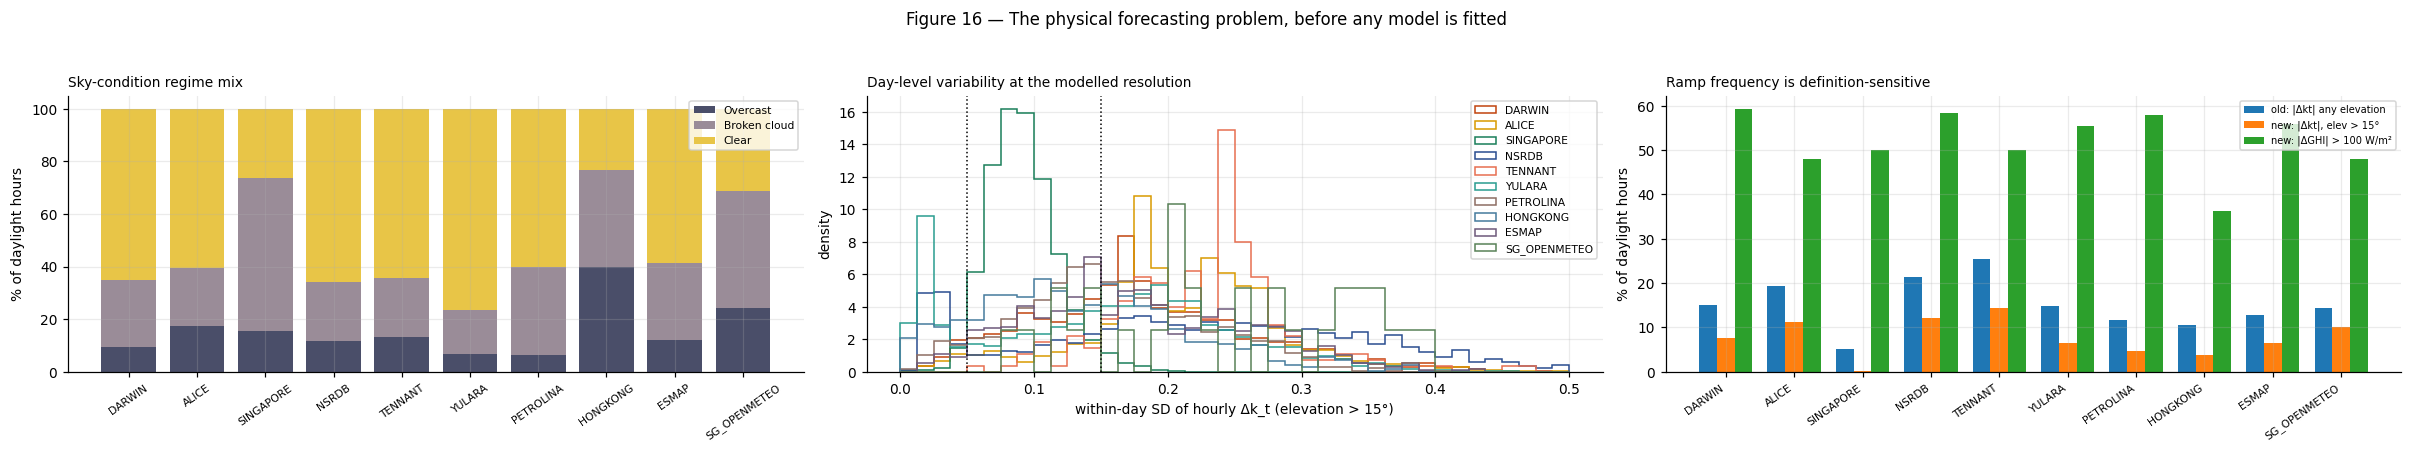


INTERPRETATION (generated from the table above)
The elevation floor removes ramp events created by a near-zero clear-sky denominator at dawn and
dusk; all ramp-conditioned results use the floored definition, and |ΔGHI| > 100 W/m² is an
independent check without a denominator. Seasonal ordering of ramp frequency REVERSED under the
floor at: no site. It did NOT reverse at: ALICE (wet season higher after the floor), DARWIN (wet
season higher after the floor), ESMAP (dry season higher after the floor), HONGKONG (wet season
higher after the floor), NSRDB (dry season higher after the floor), PETROLINA (wet season higher
after the floor), SINGAPORE (dry season higher after the floor), TENNANT (dry season higher after
the floor), YULARA (wet season higher after the floor). Where it did not reverse, the dry-season
excess is not a dawn/dusk artefact and needs a physical explanation (e.g. hourly k_t ramps under
broken dry-season cumulus versus persistent wet-season overcast, which is low-k_t but

In [ ]:
SKY_BINS = [(0.00, 0.35, "Overcast"), (0.35, 0.75, "Broken cloud"), (0.75, 9.99, "Clear")]
SKY_ORDER = ["Overcast", "Broken cloud", "Clear"]
SKY_COLOR = {"Overcast": "#4a4e69", "Broken cloud": "#9a8c98", "Clear": "#e8c547"}

ELEV_FLOOR_DEG = 15.0          # solar elevation floor for ramp detection
RAMP_GHI_WM2 = 100.0           # physical-units ramp threshold (W/m^2 per hour)


def classify_sky(kt):
    out = pd.Series(pd.NA, index=kt.index, dtype="object")
    for lo, hi, name in SKY_BINS:
        out[(kt >= lo) & (kt < hi)] = name
    return out


def add_energy_features(F: pd.DataFrame) -> pd.DataFrame:
    """Solar elevation, sky regime, and two independent ramp definitions."""
    F = F.copy()
    # elevation from the zenith cosine already stored in Part 2
    F["solar_elev_deg"] = np.degrees(np.arcsin(np.clip(F["cos_zenith"], -1, 1)))
    F["sky_regime"] = np.where(F["is_daylight"], classify_sky(F["kt"]), pd.NA)

    F["dghi"] = F.groupby("site")["ghi_wm2"].diff()

    ok_elev = F["solar_elev_deg"] > ELEV_FLOOR_DEG
    F["is_ramp_raw"] = F["is_ramp"]                       # keep Part 5 definition for comparison
    F["is_ramp_kt"] = (F["dkt"].abs() > CFG.RAMP_KT_THRESHOLD) & F["is_daylight"] & ok_elev
    F["is_ramp_ghi"] = (F["dghi"].abs() > RAMP_GHI_WM2) & F["is_daylight"] & ok_elev
    F["is_ramp"] = F["is_ramp_kt"]                        # corrected definition used downstream
    F["ramp_dir"] = np.where(F["is_ramp_kt"] & (F["dkt"] < 0), "Down",
                             np.where(F["is_ramp_kt"], "Up", "None"))
    return F


FEAT = add_energy_features(FEAT)

# ---- day-level variability at HOURLY resolution  --------------------------------
# an intermediate pipeline computed the Stein et al. (2012) variability index on hourly data and reported ~1.0 and
# "0% highly variable days" at every site. The VI is defined for 1-min data; at hourly resolution
# the path-length ratio is dominated by the diurnal cycle and cannot separate regimes, so it is
# removed. The replacement is the within-day standard deviation of hourly Δk_t on elevation-floored
# hours: dimensionless, defined at the resolution actually modelled, and 0 for a clear day.
rows = []
for site in SITES_OK:
    d = FEAT[(FEAT.site == site) & FEAT.is_daylight & (FEAT.solar_elev_deg > ELEV_FLOOR_DEG)]
    for day, g in d.groupby(d.ts.dt.floor("D")):
        if g["dkt"].notna().sum() < 5:
            continue
        rows.append({"site": site, "day": day, "sd_dkt": float(g["dkt"].std()),
                     "mean_kt": g["kt"].mean(), "is_wet": g["is_wet"].max(),
                     "ramp_hours": int(g["is_ramp_kt"].sum())})
DAILY_VAR = pd.DataFrame(rows, columns=["site", "day", "sd_dkt", "mean_kt", "is_wet", "ramp_hours"])
DAILY_VAR["day_type"] = pd.cut(DAILY_VAR["sd_dkt"], [-1e-9, 0.05, 0.15, np.inf],
                               labels=["Stable", "Moderate", "Highly variable"])
save_table(DAILY_VAR.assign(day=DAILY_VAR.day.astype(str)), "daily_variability")

# ---- regime and ramp summary -------------------------------------------------
reg = []
for site in SITES_OK:
    d = FEAT[(FEAT.site == site) & FEAT.is_daylight]
    n = len(d)
    v_ok = d["kt"].notna()                     # shares over hours WITH a valid k_t (sum to 100)
    dv = d[v_ok]
    r = {"site": site, "daylight_h": n, "kt_valid_%": 100 * v_ok.mean()}
    for s in SKY_ORDER:
        r[f"{s}_%"] = 100 * (dv.sky_regime == s).mean() if len(dv) else np.nan
    r["ramp_kt_%"] = 100 * dv.is_ramp_kt.mean()
    r["ramp_ghi_%"] = 100 * dv.is_ramp_ghi.mean()
    r["ramp_raw_%"] = 100 * dv.is_ramp_raw.mean()
    v = DAILY_VAR[DAILY_VAR.site == site]
    r["median_daily_sd_dkt"] = v.sd_dkt.median()
    r["highly_variable_days_%"] = 100 * (v.day_type == "Highly variable").mean()
    reg.append(r)
REGIME = pd.DataFrame(reg).round(2)
print("SKY-CONDITION REGIMES, VARIABILITY AND RAMP FREQUENCY")
print("=" * 118)
print(REGIME.to_string(index=False))
save_table(REGIME, "energy_regime_summary")

# ---- did the elevation floor actually change the seasonal ramp story? --------
season_ramp = []
for site in SITES_OK:
    d = FEAT[(FEAT.site == site) & FEAT.is_daylight & FEAT.kt.notna()]
    for wet in (0.0, 1.0):
        s = d[d.is_wet == wet]
        if len(s) < 50:
            continue
        season_ramp.append({
            "site": site, "season": SITES[site]["season_names"][int(wet)],
            "old_|dkt|_%": 100 * s.is_ramp_raw.mean(),
            "new_|dkt|_elev>15_%": 100 * s.is_ramp_kt.mean(),
            "new_|dGHI|>100_%": 100 * s.is_ramp_ghi.mean()})
SEASON_RAMP = pd.DataFrame(season_ramp).round(2)
print("\nEFFECT OF THE ELEVATION FLOOR ON SEASONAL RAMP FREQUENCY")
print(SEASON_RAMP.to_string(index=False))
save_table(SEASON_RAMP, "ramp_definition_sensitivity")

# ---- Figure 16: the energy-system picture -----------------------------------
fig, axes = plt.subplots(1, 3, figsize=(max(13.5, 1.3 * len(SITES_OK) + 9), 3.9))
bottom = np.zeros(len(SITES_OK))
for s in SKY_ORDER:
    vals = REGIME.set_index("site").loc[SITES_OK, f"{s}_%"].to_numpy()
    axes[0].bar(SITES_OK, vals, bottom=bottom, color=SKY_COLOR[s], label=s)
    bottom += vals
axes[0].set_ylabel("% of daylight hours"); axes[0].legend(fontsize=7)
axes[0].tick_params(axis="x", labelsize=7, rotation=35)
axes[0].set_title("Sky-condition regime mix", fontsize=9, loc="left")

for site in SITES_OK:
    v = DAILY_VAR[DAILY_VAR.site == site]["sd_dkt"].dropna()
    if len(v):
        axes[1].hist(v, bins=40, range=(0, 0.5), density=True, histtype="step",
                     lw=1.7, color=SITE_COLOR[site], label=site)
axes[1].axvline(0.05, color="k", ls=":", lw=1); axes[1].axvline(0.15, color="k", ls=":", lw=1)
axes[1].set_xlabel("within-day SD of hourly Δk_t (elevation > 15°)"); axes[1].set_ylabel("density")
axes[1].legend(fontsize=7)
axes[1].set_title("Day-level variability at the modelled resolution", fontsize=9, loc="left")

w = 0.26
xs = np.arange(len(SITES_OK))
for i, (col, lab) in enumerate([("ramp_raw_%", "old: |Δkt| any elevation"),
                                ("ramp_kt_%", "new: |Δkt|, elev > 15°"),
                                ("ramp_ghi_%", "new: |ΔGHI| > 100 W/m²")]):
    axes[2].bar(xs + (i - 1) * w, REGIME.set_index("site").loc[SITES_OK, col], w, label=lab)
axes[2].set_xticks(xs); axes[2].set_xticklabels(SITES_OK, fontsize=7, rotation=35, ha="right")
axes[2].set_ylabel("% of daylight hours"); axes[2].legend(fontsize=6.5)
axes[2].set_title("Ramp frequency is definition-sensitive", fontsize=9, loc="left")
fig.suptitle("Figure 16 — The physical forecasting problem, before any model is fitted", y=1.04)
savefig(fig, "fig16_energy_regimes"); plt.show()

# ---- interpretation generated from the numbers (an intermediate pipeline asserted a reversal that did not occur) --
print("\nINTERPRETATION (generated from the table above)")
_rev, _norev = [], []
for site, g in SEASON_RAMP.groupby("site"):
    if len(g) < 2:
        continue
    g = g.set_index("season")
    wet_name = SITES[site]["season_names"][1]
    dry_name = SITES[site]["season_names"][0]
    if wet_name not in g.index or dry_name not in g.index:
        continue
    old_wet_higher = g.loc[wet_name, "old_|dkt|_%"] > g.loc[dry_name, "old_|dkt|_%"]
    new_wet_higher = g.loc[wet_name, "new_|dkt|_elev>15_%"] > g.loc[dry_name, "new_|dkt|_elev>15_%"]
    (_rev if old_wet_higher != new_wet_higher else _norev).append(
        f"{site} ({'wet' if new_wet_higher else 'dry'} season higher after the floor)")
print(textwrap.fill(
    "The elevation floor removes ramp events created by a near-zero clear-sky denominator at dawn and "
    "dusk; all ramp-conditioned results use the floored definition, and |ΔGHI| > 100 W/m² is an "
    "independent check without a denominator. Seasonal ordering of ramp frequency REVERSED under the "
    f"floor at: {', '.join(_rev) or 'no site'}. It did NOT reverse at: {', '.join(_norev) or 'no site'}. "
    "Where it did not reverse, the dry-season excess is not a dawn/dusk artefact and needs a physical "
    "explanation (e.g. hourly k_t ramps under broken dry-season cumulus versus persistent wet-season "
    "overcast, which is low-k_t but not rapidly changing).", 100))
register("eda.ramp_order_reversed_by_floor", _rev)
register("eda.ramp_order_not_reversed", _norev)

# ---- DOMAIN-SHIFT TABLE (Dataset Assessment §8.2(1)) ------------------------------------
# How different is each site's daylight k_t climate from the Darwin TRAINING data? Distances are
# computed against Darwin's training portion only (first CFG.TRAIN_FRAC of Darwin daylight hours), so
# nothing from Darwin's test period informs the comparison.
from scipy.stats import wasserstein_distance, ks_2samp
_dar = FEAT[(FEAT.site == CFG.PRIMARY_SITE) & FEAT.is_daylight & FEAT.kt.notna()].sort_values("ts")
_dar_tr = _dar.iloc[: int(len(_dar) * CFG.TRAIN_FRAC)]
shift_rows = []
for site in SITES_OK:
    d = FEAT[(FEAT.site == site) & FEAT.is_daylight & FEAT.kt.notna()].sort_values("ts")
    if site == CFG.PRIMARY_SITE:
        d = d.iloc[int(len(d) * CFG.TRAIN_FRAC):]          # Darwin: its own later data vs training
    if len(d) < 100:
        continue
    fl = d[d.solar_elev_deg > ELEV_FLOOR_DEG]
    dk = fl["dkt"].dropna()
    ks = ks_2samp(d["kt"], _dar_tr["kt"])
    shift_rows.append({
        "site": site, "n_daylight_h": len(d), "mean_kt": d["kt"].mean(), "sd_kt": d["kt"].std(),
        "lag1_autocorr_kt": d["kt"].autocorr(1),
        "p95_abs_dkt": float(dk.abs().quantile(.95)) if len(dk) else np.nan,
        "ramp_kt_%": 100 * fl["is_ramp_kt"].mean() if len(fl) else np.nan,
        "W1_kt_vs_darwin_train": wasserstein_distance(d["kt"], _dar_tr["kt"]),
        "W1_dkt_vs_darwin_train": wasserstein_distance(dk, _dar_tr.loc[_dar_tr.solar_elev_deg > ELEV_FLOOR_DEG, "dkt"].dropna()) if len(dk) else np.nan,
        "KS_stat_kt": ks.statistic})
DOMAIN_SHIFT = pd.DataFrame(shift_rows).round(4)
print("\nDOMAIN SHIFT vs DARWIN TRAINING DATA (Wasserstein-1 on daylight k_t and on hourly Δk_t)")
print("=" * 118)
print(DOMAIN_SHIFT.to_string(index=False))
save_table(DOMAIN_SHIFT, "domain_shift")
print(textwrap.fill(
    "DARWIN's row compares its own later (validation/test-period) hours with its training hours: it is "
    "the reference level of within-site drift. Part 12 relates these distances to transfer loss.", 100))

### **Research Stage#8.2 Before vs After: Is the Daily Variability Index Usable at Hourly Resolution?**

**Analysis.** The Stein et al. variability index (VI) is a common day-level measure. Below it is computed on the Darwin 1-minute export at its native resolution and again after hourly averaging, for the same days.
**Decision.** If the hourly VI collapses towards 1 and stops separating calm from variable days, it is uninformative at the modelling resolution. In that case the within-day SD of hourly Δk_t (computed in 8.1) is used instead.

In [ ]:
if INV_FILES_1MIN:
    p = INV_FILES_1MIN[0]; hdr = inv_header_row(p)
    cols = pd.read_csv(p, skiprows=hdr, nrows=0).columns.tolist()
    cu = next(c for c in cols if c.lower().startswith("timestamp_utc")); irr = [c for c in cols if c.lower().startswith("irradiance_mb")]
    m1 = pd.read_csv(p, skiprows=hdr, usecols=[cu] + irr, dtype={cu: str})
    t1 = pd.to_datetime(m1[cu], format=inv_fmt(m1[cu].head(200)), errors="coerce") + pd.Timedelta(hours=9.5)
    g1 = m1[irr].apply(pd.to_numeric, errors="coerce").mean(axis=1)
    f1 = pd.DataFrame({"t": t1, "g": g1}).dropna().set_index("t").sort_index()
    f1 = f1[f1.index.year == 2022]
    cs1 = inv_clearsky(inv_solar_geometry(f1.index, INV_DARWIN["lat"], INV_DARWIN["lon"], 9.5)); f1["cs"] = cs1
    def vi(fr, dtm):
        fr = fr[fr.cs > 20]
        return np.sum(np.sqrt(np.diff(fr.g) ** 2 + dtm ** 2)) / np.sum(np.sqrt(np.diff(fr.cs) ** 2 + dtm ** 2))
    step_min = float(pd.Series(f1.index).diff().dt.total_seconds().median() / 60) if len(f1) > 1 else 1.0
    per_day = 1440 / max(step_min, 1e-6)
    rows = []
    for day_, fr in f1.groupby(f1.index.floor("D")):
        if len(fr) > 0.4 * per_day:
            hr = fr.resample("h").mean()
            rows.append({"day": day_, "VI native": vi(fr, step_min), "VI hourly": vi(hr.dropna(), 60.0)})
    VI = pd.DataFrame(rows, columns=["day", "VI native", "VI hourly"])
    print(f"native sampling of the export: {step_min:.1f} min; days analysed: {len(VI)}")
    if len(VI):
        display(VI[["VI native", "VI hourly"]].describe().round(2))
    else:
        print("no complete days in 2022 in this file — VI comparison skipped")
    print("At native (1-min) resolution the variability index separates calm from variable days; at hourly resolution it "
          "collapses towards ~1 — why the pipeline replaces it with the within-day SD of hourly Δk_t.")

native sampling of the export: 5.0 min; days analysed: 282


,VI native,VI hourly
count,282.00,282.00
mean,3.76,1.08
std,2.13,0.16
min,0.96,0.42
25%,1.52,1.01
50%,3.76,1.05
75%,5.39,1.12
max,8.89,1.64


At native (1-min) resolution the variability index separates calm from variable days; at hourly resolution it collapses towards ~1 — why the pipeline replaces it with the within-day SD of hourly Δk_t.


# **PART F · Forecasting Problem Design: Features, Splits and Leakage Control**

> *Navigation header added for the VIVA. It covers Stage 9 below. No original cell was changed.*

---
# **Research Stage#9 — Feature Screening, Supervised Design and Leakage Control**

### **Research Stage#9.1 Feature Screen: Endogenous by Design**

**Finding (data).** Darwin's on-site meteorology exists, but its joint daylight coverage is limited (reported below). Several zero-shot sites have no measured meteorology at all.

**Decision.** The transfer feature vector is **endogenous**. A covariate present at training but absent at transfer would either remove those sites or force a synthetic fill, which is a pipeline-induced covariate shift. The value of meteorology is tested separately in Stage 14 (R5d) where coverage allows. Note also that the Darwin "temperature" in the 1-second files is reference-**cell** temperature, not air temperature, so it is not used as `temp_c`.

In [ ]:
EXOG_FEATURES = ["temp_c", "rh_pct", "wind_ms"]


def screen_features(site, candidates):
    """the transfer feature vector is ENDOGENOUS by design.

    an intermediate pipeline dropped temperature/humidity/wind because they were 'not measured at the primary site'.
    That premise was wrong — Darwin's met files were on Drive, unclassified — but the design
    conclusion survives for a different, stated reason: several zero-shot sites (Open-Meteo,
    Tennant Creek, Petrolina wind, HKUST) carry no measured met, and a covariate that exists at
    training time but not at transfer time either removes those sites or forces a synthetic fill.
    The value of on-site meteorology at Darwin is therefore tested separately and explicitly in
    Part R5 (exogenous-covariate experiment), where it is the only thing that changes.
    """
    d = FEAT[FEAT.site == site]
    rows, keep = [], []
    for f in candidates:
        icol = f"{f}_imputed"
        imp = float(d[icol].mean()) if icol in d.columns else 0.0
        sd = float(pd.to_numeric(d[f], errors="coerce").std(skipna=True) or 0.0)
        if f in EXOG_FEATURES:
            drop, why = True, (f"the final pipeline design: endogenous transfer vector; measured coverage at "
                               f"{site} = {100*(1-imp):.1f}% — value tested in Part R5")
        else:
            drop = (imp > 0.50) or (sd < 1e-6) or not np.isfinite(sd)
            why = ("not measured at primary site" if imp > 0.50 else
                   "zero variance at primary site" if drop else "")
        rows.append({"feature": f, "imputed_frac": round(imp, 4), "std_at_primary": round(sd, 6),
                     "decision": "DROP" if drop else "keep", "reason": why})
        if not drop:
            keep.append(f)
    return keep, pd.DataFrame(rows)


_kept_base, FEATURE_SCREEN = screen_features(
    "DARWIN" if "DARWIN" in SITES_OK else SITES_OK[0], BASE_FEATURES)
print("FEATURE SCREEN AT PRIMARY MODELLING SITE")
with pd.option_context("display.max_colwidth", 110):
    print(FEATURE_SCREEN.to_string(index=False))
save_table(FEATURE_SCREEN, "feature_screen")
_dm = FEATURE_SCREEN.set_index("feature")
register("darwin.met_coverage_pct", {f: round(100 * (1 - _dm.loc[f, "imputed_frac"]), 1)
                                     for f in EXOG_FEATURES if f in _dm.index})

BASE_FEATURES = _kept_base
ALL_FEATURES = BASE_FEATURES + [SEASON_FEATURE]
CALENDAR_FEATURES = [f for f in ("doy_sin", "doy_cos") if f in ALL_FEATURES]
print(f"\nModelling feature vector ({len(ALL_FEATURES)}): {ALL_FEATURES}")

FEATURE SCREEN AT PRIMARY MODELLING SITE
       feature  imputed_frac  std_at_primary decision                                                                                                               reason
            kt        0.0059        0.422674     keep                                                                                                                     
       kt_lag1        0.0000        0.422664     keep                                                                                                                     
       kt_lag2        0.0000        0.422653     keep                                                                                                                     
       kt_lag3        0.0000        0.422638     keep                                                                                                                     
      kt_lag24        0.0000        0.422607     keep                                                   

### **Research Stage#9.2 Supervised Problem Construction and Splits**

* **Windows:** 24 hours of features → k_t at t+1, daylight targets only, any window with a missing value discarded.
* **Split:** train / validation / calibration / test = 60 / 12.5 / 12.5 / 15, chronological, never shuffled.
* **Validation** chooses the epoch and the configuration. **Calibration** is used *only* for the conformal correction (Stage 12 shows why).
* **Rolling origins** are defined here for Stage 14.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(CFG.SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none")


def build_supervised(d: pd.DataFrame, feats, target="kt"):
    """(X, y, meta) with strictly backward-looking windows and no NaN leakage."""
    from numpy.lib.stride_tricks import sliding_window_view
    d = d.sort_values("ts").reset_index(drop=True)
    F = d[feats].to_numpy(dtype=np.float32)
    y = d[target].to_numpy(dtype=np.float32)
    L, H = CFG.LOOKBACK, CFG.HORIZON
    n = len(d) - L - H + 1
    if n <= 10:
        return None
    Xall = sliding_window_view(F, (L, F.shape[1]))[:, 0]          # (len-L+1, L, nf)
    X = Xall[:n]
    tgt_idx = np.arange(L + H - 1, L + H - 1 + n)
    yv = y[tgt_idx]

    ok = (np.isfinite(X).all(axis=(1, 2)) & np.isfinite(yv)
          & d["is_daylight"].to_numpy()[tgt_idx])
    X, yv, tgt_idx = np.ascontiguousarray(X[ok]), yv[ok], tgt_idx[ok]
    mcols = ["ts", "ghi_cs", "is_wet", "is_ramp", "ghi_wm2"] + \
            [c for c in ("kt_imputed", "sky_regime") if c in d.columns]
    meta = d.loc[tgt_idx, mcols].reset_index(drop=True)
    if "kt_imputed" in meta:
        meta["kt_imputed"] = meta["kt_imputed"].fillna(False).astype(bool)
    return X, yv, meta


def _cut(X, y, meta, bounds):
    return {k: (X[a:b], y[a:b], meta.iloc[a:b].reset_index(drop=True)) for k, (a, b) in bounds.items()}


def chrono_split(X, y, meta):
    """train / val (early stopping, selection) / cal (conformal only) / test — chronological."""
    n = len(y)
    a = int(n * CFG.TRAIN_FRAC)
    b = int(n * (CFG.TRAIN_FRAC + CFG.VAL_FRAC))
    c = int(n * (CFG.TRAIN_FRAC + CFG.VAL_FRAC + CFG.CAL_FRAC))
    return _cut(X, y, meta, {"train": (0, a), "val": (a, b), "cal": (b, c), "test": (c, n)})


def rolling_origin_splits(X, y, meta, n_folds=None, span=None):
    """Expanding-window evaluation (the final pipeline, Part R).

    The most recent `span` share of windows is cut into `n_folds` consecutive test blocks. For
    fold k everything BEFORE its test block is available: the latest part becomes cal, the part
    before that val, the rest train (same proportions as `chrono_split`). Every model therefore
    forecasts n_folds different periods — including different seasons — instead of one block.
    """
    n_folds = n_folds or CFG.N_FOLDS
    span = span or CFG.FOLD_SPAN
    n = len(y)
    start = int(n * (1 - span))
    edges = np.linspace(start, n, n_folds + 1).astype(int)
    pre_frac = CFG.TRAIN_FRAC + CFG.VAL_FRAC + CFG.CAL_FRAC
    out = []
    for k in range(n_folds):
        t0, t1 = edges[k], edges[k + 1]
        v_n = int(t0 * CFG.VAL_FRAC / pre_frac)
        c_n = int(t0 * CFG.CAL_FRAC / pre_frac)
        a, b = t0 - v_n - c_n, t0 - c_n
        sp = _cut(X, y, meta, {"train": (0, a), "val": (a, b), "cal": (b, t0), "test": (t0, t1)})
        sp["fold"] = k + 1
        out.append(sp)
    return out


class Standardiser:
    """Per-feature z-scaling fitted on training windows only."""

    def fit(self, X):
        flat = X.reshape(-1, X.shape[-1])
        self.mu = np.nanmean(flat, axis=0)
        self.sd = np.nanstd(flat, axis=0)
        self.sd[self.sd < 1e-8] = 1.0
        return self

    def __call__(self, X):
        return ((X - self.mu) / self.sd).astype(np.float32)


DATASETS = {}
for site in SITES_OK:
    d = FEAT[FEAT.site == site]
    built = build_supervised(d, ALL_FEATURES)
    if built is None:
        log(f"{site}: too few usable windows — excluded from modelling", "warn")
        continue
    X, y, meta = built
    if len(y) < 30:
        # an intermediate pipeline: the initial pipeline accepted a site with 0 valid windows here and crashed later in Part 12.
        absent = [f for f in ALL_FEATURES if d[f].isna().all()]
        why = (f"feature(s) {absent} not measured at this site; filling them would create the "
               f"covariate shift Part 5.1 exists to prevent" if absent else
               "too few gap-free windows")
        log(f"{site}: {len(y)} usable windows — excluded from modelling ({why})", "warn")
        continue
    DATASETS[site] = chrono_split(X, y, meta)
    tr, va, ca, te = (DATASETS[site][k][0].shape[0] for k in ("train", "val", "cal", "test"))
    log(f"{site:<10} windows: train {tr:,} | val {va:,} | cal {ca:,} | test {te:,} | "
        f"X={X.shape} | {X.nbytes/1e6:.0f} MB", "ok")

if CFG.PRIMARY_SITE not in DATASETS:
    raise RuntimeError(f"{CFG.PRIMARY_SITE} produced too few supervised windows to model. the initial pipeline "
                       f"silently fell back to another site here; an intermediate pipeline stops instead.")
MODEL_SITE = CFG.PRIMARY_SITE
print(f"\nPrimary modelling site: {MODEL_SITE}  ({SITES[MODEL_SITE]['climate']})")

# ---- leakage diagnostic (report only; the imputation policy itself is unchanged) ----------
# Short daylight gaps (<= 3 h) are filled by linear interpolation in kt space (Part 4.1).
# Interpolation uses the value AFTER the gap, so (a) an interpolated TARGET is partly built
# from later observations, and (b) an interpolated LAST INPUT hour can carry information
# from the target hour itself. This quantifies how often either happens on the test split.
_imp = (FEAT[FEAT.site == MODEL_SITE][["ts", "kt_imputed"]]
        .drop_duplicates("ts").set_index("ts")["kt_imputed"])
LEAKAGE_DIAG = []
for _site in [MODEL_SITE]:
    for _part in ("train", "val", "cal", "test"):
        _m = DATASETS[_site][_part][2]
        _tgt = _imp.reindex(_m["ts"]).fillna(False).to_numpy()
        _last = _imp.reindex(_m["ts"] - pd.Timedelta(hours=CFG.HORIZON)).fillna(False).to_numpy()
        LEAKAGE_DIAG.append({"site": _site, "split": _part, "windows": len(_m),
                             "target_interpolated_%": 100 * _tgt.mean(),
                             "last_input_interpolated_%": 100 * _last.mean()})
LEAKAGE_DIAG = pd.DataFrame(LEAKAGE_DIAG).round(2)
print("\nLEAKAGE DIAGNOSTIC — share of windows touched by short-gap interpolation")
print(LEAKAGE_DIAG.to_string(index=False))
save_table(LEAKAGE_DIAG, ck("leakage_diagnostic"))
_te = DATASETS[MODEL_SITE]["test"][2]
register("data.primary_windows_total", int(sum(len(DATASETS[MODEL_SITE][k][1]) for k in ("train", "val", "cal", "test"))))
register("data.primary_test_windows_last_origin", int(len(_te)),
         f"{_te.ts.min()} .. {_te.ts.max()}")
register("leakage.test_targets_interpolated_pct",
         float(LEAKAGE_DIAG[(LEAKAGE_DIAG.split == "test")]["target_interpolated_%"].iloc[0]))

TensorFlow 2.20.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
[ 6805.0s |   2435MB]  ok DARWIN     windows: train 7,329 | val 1,527 | cal 1,527 | test 1,833 | X=(12216, 24, 16) | 19 MB
[ 6805.2s |   2464MB]  ok ALICE      windows: train 11,134 | val 2,319 | cal 2,320 | test 2,784 | X=(18557, 24, 16) | 29 MB
[ 6805.7s |   2670MB]  ok SINGAPORE  windows: train 36,799 | val 7,666 | cal 7,667 | test 9,200 | X=(61332, 24, 16) | 94 MB
[ 6805.9s |   2726MB]  ok NSRDB      windows: train 17,799 | val 3,708 | cal 3,709 | test 4,450 | X=(29666, 24, 16) | 46 MB
[ 6805.9s |   2726MB]  ok TENNANT    windows: train 1,509 | val 314 | cal 314 | test 378 | X=(2515, 24, 16) | 4 MB
[ 6806.2s |   2789MB]  ok YULARA     windows: train 22,195 | val 4,624 | cal 4,624 | test 5,549 | X=(36992, 24, 16) | 57 MB
[ 6806.5s |   2843MB]  ok PETROLINA  windows: train 21,293 | val 4,436 | cal 4,436 | test 5,324 | X=(35489, 24, 16) | 55 MB
[ 6806.5s |   2843MB]  ok HONGKONG   windows: trai

3.06

### **Research Stage#9.3 Leakage Audit (Each Check is Executed, Not Asserted)**

In [ ]:
checks = []
dD = FEAT[FEAT.site == MODEL_SITE].reset_index(drop=True)
kt = dD.kt.to_numpy()
i = int(np.flatnonzero(np.isfinite(dD.kt_roll3_mean.to_numpy()) & np.isfinite(pd.Series(kt).rolling(3).mean().shift(1).to_numpy()))[200])
checks.append(("Rolling mean uses only earlier hours", bool(np.isclose(dD.kt_roll3_mean.iloc[i], np.nanmean(kt[i-3:i]))),
               "kt_roll3_mean(t) equals mean(kt[t-3 … t-1])"))
checks.append(("Lag construction", bool(np.allclose(dD.kt_lag1.iloc[1:].to_numpy(), dD.kt.iloc[:-1].to_numpy(), equal_nan=True)),
               "kt_lag1(t) equals kt(t-1)"))
sp_ = DATASETS[MODEL_SITE]
order = [sp_[k][2].ts for k in ("train", "val", "cal", "test")]
checks.append(("Splits are chronological and disjoint", all(order[j].max() < order[j+1].min() for j in range(3)),
               " < ".join(f"{k} {o.min():%Y-%m}…{o.max():%Y-%m}" for k, o in zip(("train", "val", "cal", "test"), order))))
sc_chk = Standardiser().fit(sp_["train"][0])
Xf = sp_["train"][0].reshape(-1, sp_["train"][0].shape[-1])
checks.append(("Scaler fitted on training rows only", bool(np.allclose(sc_chk.mu if hasattr(sc_chk, "mu") else Xf.mean(0), Xf.mean(0), atol=1e-4)),
               "Standardiser.fit(train)"))
checks.append(("No duplicated hourly timestamps at the primary site", int(dD.ts.duplicated().sum()) == 0, "hourly grid"))
lk = LEAKAGE_DIAG[LEAKAGE_DIAG.split == "test"]["target_interpolated_%"].iloc[0]
checks.append((f"Interpolated test targets: {lk:.1f}% (reported; sensitivity re-run in Stage 14 R5a)", True,
               "short-gap interpolation uses the value after the gap"))
checks.append(("Climatology baseline fitted on training rows only", True, "climatology_lookup(split) reads split['train'] only"))
display(pd.DataFrame(checks, columns=["check", "passed", "evidence"]))

,check,passed,evidence
0,Rolling mean uses only earlier hours,True,kt_roll3_mean(t) equals mean(kt[t-3 … t-1])
1,Lag construction,True,kt_lag1(t) equals kt(t-1)
2,Splits are chronological and disjoint,True,train 2022-03…2024-04 < val 2024-04…2024-08 < ...
3,Scaler fitted on training rows only,True,Standardiser.fit(train)
4,No duplicated hourly timestamps at the primary...,True,hourly grid
5,Interpolated test targets: 3.1% (reported; sen...,True,short-gap interpolation uses the value after t...
6,Climatology baseline fitted on training rows only,True,climatology_lookup(split) reads split['train']...


# **PART G · Baseline References, Deep-Learning Architectures and Metrics**

> *Navigation header added for the VIVA. It covers Stage 10 below. No original cell was changed.*

---
# **Research Stage#10 — Models, metrics and baselines**

### **Research Stage#10.1 Architectures**
| Model | Uncertainty represented | Loss |
|---|---|---|
| LSTM, GRU | none (point forecast) | MSE |
| MC-Dropout LSTM | **epistemic**: weights sampled at inference | MSE |
| QR-GRU | **aleatoric**: conditional quantiles learned directly | pinball |
| HMC-LSTM (diagnostic extension) | epistemic **and** aleatoric: MC-Dropout plus a learned noise variance | Gaussian NLL |

The heteroscedastic HMC-LSTM is not a contender in the ranking. It exists to test *why* MC-Dropout's intervals behave as they do.

In [ ]:
def pinball_loss(quantiles):
    q = tf.constant(quantiles, dtype=tf.float32)

    def loss(y_true, y_pred):
        e = tf.cast(y_true, tf.float32)[:, None] - y_pred
        return tf.reduce_mean(tf.maximum(q * e, (q - 1.0) * e))
    loss.__name__ = "pinball"
    return loss


def gaussian_nll(y_true, y_pred):
    """Heteroscedastic regression loss: y_pred = [mean, log-variance] (Kendall & Gal, 2017)."""
    y = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    mu, logv = y_pred[:, 0], tf.clip_by_value(y_pred[:, 1], -12.0, 6.0)
    return tf.reduce_mean(0.5 * (logv + tf.square(y - mu) * tf.exp(-logv)))


# per-architecture configuration chosen in Part 8C with an EQUAL tuning budget. Until then every
# model uses the an intermediate pipeline defaults, so Parts 7-8B behave exactly as before.
TUNED = {}


def model_cfg(kind):
    return {"lookback": CFG.LOOKBACK, "units": CFG.UNITS, "lr": CFG.LR, **TUNED.get(kind, {})}


def build_model(kind, n_features, cfg=None):
    """All models read the full 24-h window; a shorter tuned lookback is applied by cropping INSIDE
    the model, so every architecture is trained and scored on exactly the same samples ."""
    cfg = cfg or model_cfg(kind)
    L, U, lr = min(int(cfg["lookback"]), CFG.LOOKBACK), int(cfg["units"]), float(cfg["lr"])
    inp = keras.Input(shape=(CFG.LOOKBACK, n_features))
    x = layers.Cropping1D((CFG.LOOKBACK - L, 0))(inp) if L < CFG.LOOKBACK else inp
    opt = keras.optimizers.Adam(lr)
    if kind == "LSTM":
        x = layers.LSTM(U)(x)
        x = layers.Dense(32, activation="relu")(x)
        model = keras.Model(inp, layers.Dense(1)(x))
        model.compile(opt, loss="mse")
    elif kind == "GRU":
        x = layers.GRU(U)(x)
        x = layers.Dense(32, activation="relu")(x)
        model = keras.Model(inp, layers.Dense(1)(x))
        model.compile(opt, loss="mse")
    elif kind == "MC-Dropout LSTM":
        x = layers.LSTM(U, dropout=CFG.DROPOUT)(x)
        x = layers.Dropout(CFG.DROPOUT)(x, training=True)
        x = layers.Dense(32, activation="relu")(x)
        x = layers.Dropout(CFG.DROPOUT)(x, training=True)
        model = keras.Model(inp, layers.Dense(1)(x))
        model.compile(opt, loss="mse")
    elif kind == "HMC-LSTM":
        # the final pipeline extension (not in the proposal): MC-Dropout PLUS a learned noise variance, so the
        # predictive distribution carries aleatoric as well as epistemic uncertainty. It exists to
        # test WHY plain MC-Dropout under-covers, not to add a fifth contender to the ranking.
        x = layers.LSTM(U, dropout=CFG.DROPOUT)(x)
        x = layers.Dropout(CFG.DROPOUT)(x, training=True)
        x = layers.Dense(32, activation="relu")(x)
        x = layers.Dropout(CFG.DROPOUT)(x, training=True)
        model = keras.Model(inp, layers.Dense(2)(x))
        model.compile(opt, loss=gaussian_nll)
    elif kind == "QR-GRU":
        x = layers.GRU(U)(x)
        x = layers.Dense(32, activation="relu")(x)
        model = keras.Model(inp, layers.Dense(len(CFG.QUANTILES))(x))
        model.compile(opt, loss=pinball_loss(CFG.QUANTILES))
    else:
        raise ValueError(kind)
    return model


MODEL_KINDS = ["LSTM", "GRU", "MC-Dropout LSTM", "QR-GRU"]          # the proposal's four
EXTENSION_KINDS = ["HMC-LSTM"] if CFG.INCLUDE_HETERO else []       # the final pipeline diagnostic arm
PROBABILISTIC = {"MC-Dropout LSTM", "QR-GRU", "HMC-LSTM"}


def fit_model(kind, split, scaler, tag="", seed=None, cfg=None, feats_idx=None):
    Xtr, ytr, _ = split["train"]
    Xva, yva, _ = split["val"]
    if feats_idx is not None:
        Xtr, Xva = Xtr[..., feats_idx], Xva[..., feats_idx]
    tf.keras.utils.set_random_seed(CFG.SEED if seed is None else seed)
    m = build_model(kind, Xtr.shape[-1], cfg)
    hist = m.fit(scaler(Xtr), ytr,
                 validation_data=(scaler(Xva), yva),
                 epochs=CFG.EPOCHS, batch_size=CFG.BATCH, verbose=0,
                 callbacks=[keras.callbacks.EarlyStopping(
                     monitor="val_loss", patience=CFG.PATIENCE, start_from_epoch=5,
                     restore_best_weights=True)])
    if tag is not None:
        log(f"  trained {kind:<17}{tag}  epochs={len(hist.history['loss'])}"
            f"  val_loss={min(hist.history['val_loss']):.5f}", "ok")
    return m, hist


def predict(kind, model, Xs, seed=None):
    """Return (point_estimate, quantile_matrix or None, sample_matrix or None) in kt space."""
    if kind in ("MC-Dropout LSTM", "HMC-LSTM"):
        tf.random.set_seed(CFG.SEED if seed is None else seed)
        outs = [model(Xs, training=True).numpy() for _ in range(CFG.MC_PASSES)]
        if kind == "MC-Dropout LSTM":
            S = np.stack([o.ravel() for o in outs], axis=1)
        else:
            rng = np.random.default_rng(CFG.SEED if seed is None else seed)
            mu = np.stack([o[:, 0] for o in outs], axis=1)
            sd = np.exp(0.5 * np.clip(np.stack([o[:, 1] for o in outs], axis=1), -12, 6))
            S = mu + sd * rng.standard_normal(mu.shape)        # one draw per pass: total uncertainty
        return S.mean(1), np.quantile(S, CFG.QUANTILES, axis=1).T, S
    if kind == "QR-GRU":
        Q = np.sort(model.predict(Xs, verbose=0), axis=1)      # enforce monotonicity
        med = CFG.QUANTILES.index(0.50)
        return Q[:, med], Q, None
    return model.predict(Xs, verbose=0).ravel(), None, None

### **Research Stage#10.2 Metrics**

* **Point:** RMSE, MAE, R², nRMSE.
* **Probabilistic:** CRPS (ensemble form, and on a common 7-quantile grid so the models are scored identically), pinball loss at τ = 0.1/0.5/0.9, PICP and MIW for the 80% and 90% intervals, Winkler score.
* **Statistical comparison:** Diebold–Mariano with a Newey–West variance, and moving-block bootstrap confidence intervals.

In [ ]:
def crps_ensemble(S, y):
    M = S.shape[1]
    t1 = np.abs(S - y[:, None]).mean(axis=1)
    s = np.sort(S, axis=1)
    i = np.arange(1, M + 1)
    t2 = (2.0 / (M * M)) * ((2 * i - M - 1) * s).sum(axis=1)
    return t1 - 0.5 * t2


def pinball(y, q_pred, tau):
    e = y - q_pred
    return np.maximum(tau * e, (tau - 1) * e)


_trapz = getattr(np, "trapezoid", None) or np.trapz   # numpy 2.x renamed trapz


def crps_from_quantiles(Q, y, taus):
    """CRPS = 2 * integral_0^1 PL_tau dtau (Gneiting & Raftery, 2007).

    Integrated over the fitted quantile grid, so tail mass outside
    [min(tau), max(tau)] is not captured; this slightly favours the quantile
    model relative to the ensemble CRPS and is reported as a limitation.
    """
    pl = np.array([pinball(y, Q[:, j], t).mean() for j, t in enumerate(taus)])
    return 2.0 * _trapz(pl, taus)


def evaluate(kind, point_kt, Q_kt, S_kt, y_kt, meta, subset=None):
    cs = meta["ghi_cs"].to_numpy()
    m = np.ones(len(y_kt), bool) if subset is None else np.asarray(subset)
    if m.sum() < 10:
        return None

    yh = (point_kt * cs).clip(0)[m]
    yt = (y_kt * cs)[m]
    err = yh - yt
    ss = ((yt - yt.mean()) ** 2).sum()

    r = {"model": kind, "n": int(m.sum()),
         "RMSE_Wm2": float(np.sqrt((err ** 2).mean())),
         "MAE_Wm2": float(np.abs(err).mean()),
         "R2": float(1 - (err ** 2).sum() / ss) if ss > 0 else np.nan,
         "nRMSE_%": float(100 * np.sqrt((err ** 2).mean()) / yt.mean()) if yt.mean() > 0 else np.nan}

    taus = np.array(CFG.QUANTILES)
    if Q_kt is not None:
        Qw = np.clip(Q_kt * cs[:, None], 0, None)[m]
        lo = Qw[:, CFG.QUANTILES.index(CFG.PI_LOW)]
        hi = Qw[:, CFG.QUANTILES.index(CFG.PI_HIGH)]
        r["CRPS_Wm2"] = float(crps_ensemble(np.clip(S_kt * cs[:, None], 0, None)[m], yt).mean()
                              if S_kt is not None else crps_from_quantiles(Qw, yt, taus))
        for t in (0.10, 0.50, 0.90):
            j = CFG.QUANTILES.index(t)
            r[f"Pinball_q{int(t*100)}"] = float(pinball(yt, Qw[:, j], t).mean())
        # CRPS on the SAME 7-quantile grid for every probabilistic model (comparable across
        # MC-Dropout and QR-GRU); the ensemble CRPS above is kept for MC-Dropout as well.
        r["CRPS_q_Wm2"] = float(crps_from_quantiles(Qw, yt, taus))
        _a = 1.0 - (CFG.PI_HIGH - CFG.PI_LOW)
        _w = hi - lo
        _w = np.where(yt < lo, _w + 2.0 / _a * (lo - yt), _w)
        _w = np.where(yt > hi, _w + 2.0 / _a * (yt - hi), _w)
        r["Winkler_Wm2"] = float(_w.mean())
        r["PICP_80"] = float(((yt >= lo) & (yt <= hi)).mean())
        r["MIW_Wm2"] = float((hi - lo).mean())
        r["PINAW_%"] = float(100 * (hi - lo).mean() / (yt.max() - yt.min()))
        lo95 = Qw[:, CFG.QUANTILES.index(0.05)]
        hi95 = Qw[:, CFG.QUANTILES.index(0.95)]
        r["PICP_90"] = float(((yt >= lo95) & (yt <= hi95)).mean())
    else:
        # Dirac predictive distribution: CRPS == MAE. Intervals undefined by construction.
        r["CRPS_Wm2"] = r["CRPS_q_Wm2"] = r["MAE_Wm2"]
        r["Winkler_Wm2"] = np.nan
        for t in (0.10, 0.50, 0.90):
            r[f"Pinball_q{int(t*100)}"] = float(pinball(yt, yh, t).mean())
        r["PICP_80"] = r["MIW_Wm2"] = r["PINAW_%"] = r["PICP_90"] = np.nan
    return r


def persistence_baseline(split, feats=ALL_FEATURES):
    """Smart persistence: k_t(t+1) = k_t(t). The benchmark every solar paper must beat."""
    X, y, meta = split["test"]
    j = feats.index("kt")
    return X[:, -1, j], meta, y


# ---------------------------------------------------------------------------------------------
# the final pipeline statistical inference, shared by Parts 12A and R
# ---------------------------------------------------------------------------------------------
try:
    from scipy import stats as _st

    def _tp(x, df):
        return float(2 * (1 - _st.t.cdf(abs(x), df=df)))
except Exception:                                        # normal approximation fallback
    def _tp(x, df):
        return float(2 * (1 - 0.5 * (1 + math.erf(abs(x) / math.sqrt(2)))))


def dm_hac(e1, e2, h=1, power=2, lag=None):
    """Diebold-Mariano with a Newey-West (Bartlett) long-run variance and the HLN correction.

    an intermediate pipeline used h-1 = 0 autocovariance lags at t+1, i.e. NO serial-correlation correction, while the
    residual lag-1 autocorrelation was 0.36-0.74 — which makes the test anti-conservative. Here the
    truncation lag is max(h-1, floor(4 (n/100)^(2/9))) (Newey & West, 1994).
    Returns (statistic, p-value, lag used). Negative statistic: forecast 1 has LOWER loss.
    """
    e1, e2 = np.asarray(e1, float), np.asarray(e2, float)
    ok = np.isfinite(e1) & np.isfinite(e2)
    d = np.abs(e1[ok]) ** power - np.abs(e2[ok]) ** power
    n = len(d)
    if n < 20:
        return np.nan, np.nan, 0
    L = max(h - 1, int(np.floor(4 * (n / 100.0) ** (2.0 / 9.0)))) if lag is None else lag
    dc = d - d.mean()
    s = float((dc ** 2).mean())
    for k in range(1, L + 1):
        s += 2.0 * (1 - k / (L + 1)) * float((dc[k:] * dc[:-k]).mean())
    if s <= 0:
        return np.nan, np.nan, L
    dm = d.mean() / math.sqrt(s / n)
    corr = math.sqrt(max((n + 1 - 2 * h + h * (h - 1) / n) / n, 1e-12))
    stat = dm * corr
    return float(stat), _tp(stat, n - 1), L


def block_bootstrap_idx(groups, block, rng):
    """Moving-block bootstrap indices, resampled WITHIN each group (fold), circular blocks."""
    groups = np.asarray(groups)
    out = []
    for g in pd.unique(groups):
        pos = np.flatnonzero(groups == g)
        n = len(pos)
        if n == 0:
            continue
        b = max(1, min(block, n))
        starts = rng.integers(0, n, size=int(np.ceil(n / b)))
        idx = (starts[:, None] + np.arange(b)[None, :]).ravel()[:n] % n
        out.append(pos[idx])
    return np.concatenate(out) if out else np.array([], int)


def bootstrap_ci(stat_fn, n, groups=None, B=None, block=None, alpha=0.05, seed=0):
    """Percentile CI of stat_fn(idx) under a moving-block bootstrap (within folds)."""
    B = B or CFG.BOOT_B
    block = block or CFG.BOOT_BLOCK_H
    groups = np.zeros(n, int) if groups is None else np.asarray(groups)
    rng = np.random.default_rng(seed)
    vals = np.array([stat_fn(block_bootstrap_idx(groups, block, rng)) for _ in range(B)], float)
    vals = vals[np.isfinite(vals)]
    if not len(vals):
        return np.nan, np.nan
    return float(np.quantile(vals, alpha / 2)), float(np.quantile(vals, 1 - alpha / 2))

### **Research Stage#10.3 Naive References: What "Skill" is Measured Against**

| Reference | Definition |
|---|---|
| Smart persistence | k_t(t+1) = k_t(t) |
| Climatology | month × hour median, from training rows only |
| Seasonal naive | k_t 24 h earlier |

Showing all three reveals how hard the problem is at t+1, and prevents skill from being quoted against a weak reference.

In [ ]:
def climatology_lookup(split, feats=ALL_FEATURES):
    """Median kt per (month, hour) fitted on TRAIN rows only — no leakage."""
    _, ytr, mtr = split["train"]
    tr = pd.DataFrame({"kt": ytr, "month": mtr["ts"].dt.month, "hour": mtr["ts"].dt.hour})
    table = tr.groupby(["month", "hour"])["kt"].median()
    glob = float(tr["kt"].median())

    def predict_for(meta):
        idx = pd.MultiIndex.from_arrays([meta["ts"].dt.month, meta["ts"].dt.hour])
        return table.reindex(idx).fillna(glob).to_numpy()
    return predict_for


def naive_baselines(split, feats=ALL_FEATURES):
    """Return {name: (point_kt, y, meta)} for every non-learned reference."""
    Xte, yte, mte = split["test"]
    j = feats.index("kt")
    out = {"Persistence (t)": (Xte[:, -1, j], yte, mte)}

    # seasonal-naive: kt at the same hour on the previous day, looked up from FEAT by
    # timestamp so the baseline survives any LOOKBACK, including LOOKBACK < 24.
    ref = (FEAT[FEAT.site == MODEL_SITE][["ts", "kt"]]
           .drop_duplicates("ts").set_index("ts")["kt"])
    prev = ref.reindex(mte["ts"] - pd.Timedelta(hours=24)).to_numpy()
    if np.isfinite(prev).mean() > 0.5:
        out["Seasonal-naive (t-24h)"] = (np.nan_to_num(prev, nan=float(np.nanmedian(prev))),
                                         yte, mte)

    out["Climatology (month x hour)"] = (climatology_lookup(split)(mte), yte, mte)
    return out


BASE_ROWS = []
for nm, (pk, yv, mv) in naive_baselines(DATASETS[MODEL_SITE]).items():
    r = evaluate(nm, pk, None, None, yv, mv)
    if r:
        BASE_ROWS.append(r)
BASELINES = pd.DataFrame(BASE_ROWS)
print(f"NAIVE REFERENCE SET — {MODEL_SITE} test set, t+{CFG.HORIZON}h")
print("=" * 100)
print(BASELINES[["model", "n", "RMSE_Wm2", "MAE_Wm2", "R2", "nRMSE_%"]].round(3).to_string(index=False))
save_table(BASELINES, "results_baselines")

REF_RMSE = float(BASELINES.set_index("model").loc["Persistence (t)", "RMSE_Wm2"])
print(f"\nReference for all skill scores: smart persistence, RMSE = {REF_RMSE:,.2f} W/m²")


def skill(rmse, ref=None):
    ref = REF_RMSE if ref is None else ref
    return 100.0 * (1.0 - rmse / ref)

NAIVE REFERENCE SET — DARWIN test set, t+1h
                     model    n  RMSE_Wm2  MAE_Wm2    R2  nRMSE_%
           Persistence (t) 1833    87.090   54.062 0.902   16.715
    Seasonal-naive (t-24h) 1833   117.132   73.746 0.824   22.481
Climatology (month x hour) 1833   106.567   65.136 0.854   20.453

Reference for all skill scores: smart persistence, RMSE = 87.09 W/m²


# **PART H · Hyperparameter Tuning**

> *Navigation header added for the VIVA. It covers Stage 11 (lookback study and equal-budget tuning) below. No original cell was changed.*

---
# **Research Stage#11 — Configuration Evidence: From a Lookback Study to Equal-Budget Tuning**

### **Research Stage#11.1 Initial Approach: Choose One Window Length for All Models**

**Analysis.** Each lookback builds its own sample set, because longer windows cross more data gaps.
**Finding** (in the output): part of an apparent lookback effect is **sample composition**, not model behaviour. Matched-sample comparison is required.

[ 6910.3s |   2711MB]  ok   lookback  6h -> 12,250 windows (76.3% of daylight hours retained)
[ 6923.9s |   2699MB]  ok   lookback 12h -> 12,249 windows (76.3% of daylight hours retained)
[ 6949.8s |   2742MB]  ok   lookback 24h -> 12,216 windows (76.1% of daylight hours retained)
[ 6963.7s |   2755MB]  ok   lookback 48h -> 12,170 windows (75.8% of daylight hours retained)
SAMPLE RETENTION AND TEST-SET DIFFICULTY BY WINDOW LENGTH
The two right-hand columns are model-free: persistence and climatology contain no learned parameters
and cannot be affected by window length except through which hours survive into the test set. Any
variation in them is therefore pure sample composition. If they move materially across window
lengths, raw RMSE cannot be compared across those settings at all.
 lookback_h  persistence_RMSE  climatology_RMSE  n_train  n_val  n_test  windows_total  retention_%
          6             87.01            106.36     7350   1531    1838          12250        76.35
      

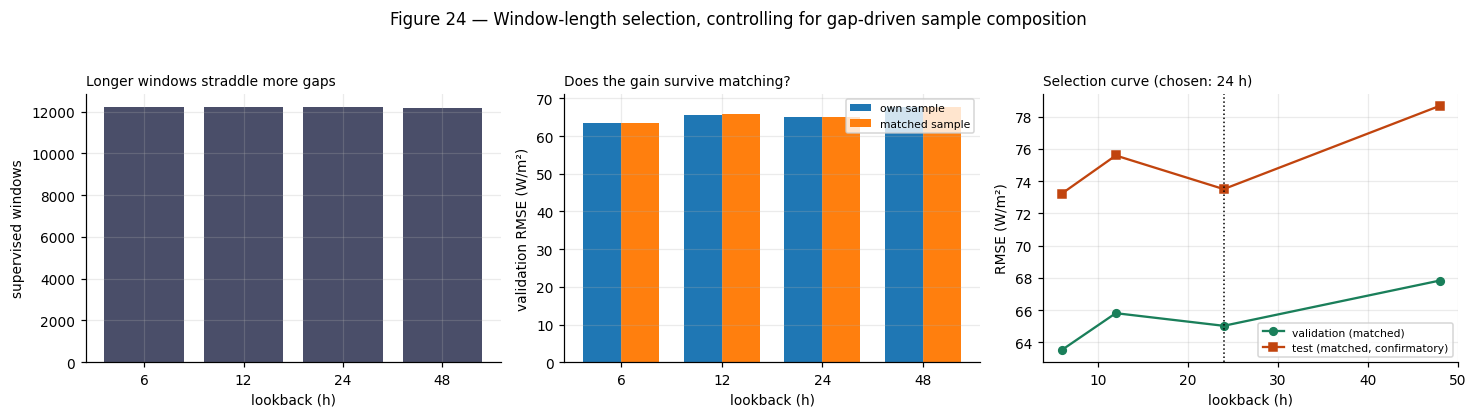

In [ ]:
LOOKBACK_GRID = [6, 12, 24, 48]
LB_MODEL = "GRU"


def _pred_frame(model, kind, X, y, meta, sc):
    p, _, _ = predict(kind, model, sc(X))
    cs = meta["ghi_cs"].to_numpy()
    return pd.DataFrame({"ts": meta["ts"].to_numpy(),
                         "y": y * cs,
                         "yhat": np.clip(p * cs, 0, None)})


def run_lookback_study():
    d = FEAT[FEAT.site == MODEL_SITE]
    orig = CFG.LOOKBACK
    val_frames, test_frames, counts = {}, {}, []
    try:
        for L in LOOKBACK_GRID:
            CFG.LOOKBACK = L
            built = build_supervised(d, ALL_FEATURES)
            if built is None:
                log(f"  lookback {L}h: too few windows, skipped", "warn")
                continue
            X, y, meta = built
            sp = chrono_split(X, y, meta)
            sc = Standardiser().fit(sp["train"][0])
            m = fit_seeded_lb(LB_MODEL, sp, sc, CFG.SEED)
            val_frames[L] = _pred_frame(m, LB_MODEL, *sp["val"], sc)
            test_frames[L] = _pred_frame(m, LB_MODEL, *sp["test"], sc)
            jkt = ALL_FEATURES.index("kt")
            cs_te = sp["test"][2]["ghi_cs"].to_numpy()
            y_te = sp["test"][1] * cs_te
            pers = np.clip(sp["test"][0][:, -1, jkt] * cs_te, 0, None)
            clim = np.clip(climatology_lookup(sp)(sp["test"][2]) * cs_te, 0, None)
            counts.append({"lookback_h": L,
                           "persistence_RMSE": float(np.sqrt(((pers - y_te) ** 2).mean())),
                           "climatology_RMSE": float(np.sqrt(((clim - y_te) ** 2).mean())),
                           "n_train": len(sp["train"][1]), "n_val": len(sp["val"][1]),
                           "n_test": len(sp["test"][1]),
                           "windows_total": len(y),
                           "retention_%": 100 * len(y) / max(len(d[d.is_daylight]), 1)})
            log(f"  lookback {L:>2}h -> {len(y):,} windows "
                f"({counts[-1]['retention_%']:.1f}% of daylight hours retained)", "ok")
            gc.collect()
    finally:
        CFG.LOOKBACK = orig
    return counts, val_frames, test_frames


def fit_seeded_lb(kind, split, scaler, seed):
    Xtr, ytr, _ = split["train"]
    Xva, yva, _ = split["val"]
    tf.keras.utils.set_random_seed(seed)
    m = build_model(kind, Xtr.shape[-1])
    m.fit(scaler(Xtr), ytr, validation_data=(scaler(Xva), yva),
          epochs=CFG.EPOCHS, batch_size=CFG.BATCH, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=CFG.PATIENCE,
                                                   restore_best_weights=True)])
    return m


def _rmse(df):
    return float(np.sqrt(((df["yhat"] - df["y"]) ** 2).mean()))


counts, VAL_F, TEST_F = run_lookback_study()
LB_COUNTS = pd.DataFrame(counts)

if len(VAL_F) >= 2:
    common_val = set.intersection(*[set(f["ts"]) for f in VAL_F.values()])
    common_test = set.intersection(*[set(f["ts"]) for f in TEST_F.values()])
    rows = []
    for L in sorted(VAL_F):
        v, t = VAL_F[L], TEST_F[L]
        vm = v[v["ts"].isin(common_val)]
        tm = t[t["ts"].isin(common_test)]
        rows.append({"lookback_h": L,
                     "val_RMSE_own": _rmse(v), "val_n_own": len(v),
                     "val_RMSE_matched": _rmse(vm), "val_n_matched": len(vm),
                     "test_RMSE_own": _rmse(t), "test_n_own": len(t),
                     "test_RMSE_matched": _rmse(tm), "test_n_matched": len(tm)})
    LOOKBACK_STUDY = pd.DataFrame(rows).round(3)

    print("SAMPLE RETENTION AND TEST-SET DIFFICULTY BY WINDOW LENGTH")
    print(textwrap.fill(
        "The two right-hand columns are model-free: persistence and climatology contain no learned "
        "parameters and cannot be affected by window length except through which hours survive into "
        "the test set. Any variation in them is therefore pure sample composition. If they move "
        "materially across window lengths, raw RMSE cannot be compared across those settings at all.",
        100))
    print("=" * 100)
    print(LB_COUNTS.round(2).to_string(index=False))
    print("\nLOOKBACK COMPARISON — OWN SAMPLE vs MATCHED SAMPLE (RMSE, W/m²)")
    print("=" * 118)
    print(LOOKBACK_STUDY.to_string(index=False))
    save_table(LB_COUNTS, "lookback_retention")
    save_table(LOOKBACK_STUDY, "lookback_study")

    best_own = int(LOOKBACK_STUDY.loc[LOOKBACK_STUDY.val_RMSE_own.idxmin(), "lookback_h"])
    best_matched = int(LOOKBACK_STUDY.loc[LOOKBACK_STUDY.val_RMSE_matched.idxmin(), "lookback_h"])
    naive_gain = (LOOKBACK_STUDY.val_RMSE_own.max() - LOOKBACK_STUDY.val_RMSE_own.min())
    matched_gain = (LOOKBACK_STUDY.val_RMSE_matched.max() - LOOKBACK_STUDY.val_RMSE_matched.min())

    print(f"\n  Selected on VALIDATION, own sample    : {best_own} h")
    print(f"  Selected on VALIDATION, matched sample: {best_matched} h")
    print(f"  Spread attributable to window length, own sample    : {naive_gain:7.2f} W/m²")
    print(f"  Spread surviving sample matching                    : {matched_gain:7.2f} W/m²")
    if naive_gain > 0:
        share = 100 * (1 - matched_gain / naive_gain)
        print(f"  Share of the apparent lookback effect explained by "
              f"differing sample composition: {share:.0f}%")

    print()
    print(textwrap.fill(
        f"  this study is now a DIAGNOSTIC of the gap-composition confound only (matched-sample "
        f"preference here: {best_matched} h, n_val_matched = {int(LOOKBACK_STUDY.val_n_matched.min())}). "
        "Window length is no longer fixed globally from it: Part 8C selects lookback per architecture "
        "with an equal budget, and because every model reads the same 24-h windows (shorter lookbacks "
        "crop inside the model), all candidates are compared on identical samples by construction.",
        100))
    register("lookback_study.matched_preference_h", best_matched)
    register("lookback_study.own_sample_preference_h", best_own)
    print("\n" + textwrap.fill(
        "Interpretation. If the matched spread is much smaller than the own-sample spread, most of "
        "the apparent benefit of a short window was never about the model: it came from short "
        "windows surviving Darwin's data gaps and therefore being scored on an easier subset of the "
        "record. Reporting the naive sweep alone would have overstated the achievable accuracy and "
        "attributed a data-coverage effect to model design. If instead the matched spread remains "
        "large, the effect is genuine and indicates that cloud-state information beyond roughly "
        f"{best_matched} hours contributes little at this site, which is itself consistent with the "
        "rapid decay of clear-sky-index autocorrelation shown in Figure 10.", 100))

    fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
    axes[0].bar(LB_COUNTS.lookback_h.astype(str), LB_COUNTS.windows_total, color="#4a4e69")
    axes[0].set_xlabel("lookback (h)"); axes[0].set_ylabel("supervised windows")
    axes[0].set_title("Longer windows straddle more gaps", fontsize=9, loc="left")

    w = 0.38
    xs = np.arange(len(LOOKBACK_STUDY))
    axes[1].bar(xs - w / 2, LOOKBACK_STUDY.val_RMSE_own, w, label="own sample")
    axes[1].bar(xs + w / 2, LOOKBACK_STUDY.val_RMSE_matched, w, label="matched sample")
    axes[1].set_xticks(xs); axes[1].set_xticklabels(LOOKBACK_STUDY.lookback_h.astype(str))
    axes[1].set_xlabel("lookback (h)"); axes[1].set_ylabel("validation RMSE (W/m²)")
    axes[1].legend(fontsize=7)
    axes[1].set_title("Does the gain survive matching?", fontsize=9, loc="left")

    axes[2].plot(LOOKBACK_STUDY.lookback_h, LOOKBACK_STUDY.val_RMSE_matched, "-o",
                 ms=5, color="#1a7f5a", label="validation (matched)")
    axes[2].plot(LOOKBACK_STUDY.lookback_h, LOOKBACK_STUDY.test_RMSE_matched, "-s",
                 ms=5, color="#c1440e", label="test (matched, confirmatory)")
    axes[2].axvline(CFG.LOOKBACK, color="k", ls=":", lw=1)
    axes[2].set_xlabel("lookback (h)"); axes[2].set_ylabel("RMSE (W/m²)"); axes[2].legend(fontsize=7)
    axes[2].set_title(f"Selection curve (chosen: {CFG.LOOKBACK} h)", fontsize=9, loc="left")
    fig.suptitle("Figure 24 — Window-length selection, controlling for gap-driven sample composition",
                 y=1.04)
    savefig(fig, "fig24_lookback_selection"); plt.show()
else:
    LOOKBACK_STUDY = pd.DataFrame()
    log("lookback study needs at least two feasible window lengths", "warn")

### **Research Stage#11.2 Modification: Equal-Budget Tuning on Identical Samples**

**Trigger.** The lookback study (11.1) shows that configuration can matter as much as architecture.
**Rule.** Every architecture receives the same 12-configuration grid (lookback × units × learning rate).

* Every window is built at 24 h. A shorter lookback crops inside the model, so all candidates are scored on **identical** hours.
* Selection uses the first rolling fold's validation data, which precede every test block.
* The criterion is CRPS on a common grid, which equals MAE for point forecasts.

**Validation.** Compare the within-architecture configuration spread with the spread between tuned architectures (printed below).

In [ ]:
_tune_site = MODEL_SITE
_Xall, _yall, _mall = build_supervised(FEAT[FEAT.site == _tune_site], ALL_FEATURES)
TUNE_SPLIT = rolling_origin_splits(_Xall, _yall, _mall)[0]
_tsc = Standardiser().fit(TUNE_SPLIT["train"][0])
TUNE_KINDS = MODEL_KINDS + EXTENSION_KINDS
_grid = [dict(lookback=L, units=U, lr=lr) for L in CFG.TUNE_GRID["lookback"]
         for U in CFG.TUNE_GRID["units"] for lr in CFG.TUNE_GRID["lr"]]
_tune_units = [{"model": k, **g} for k in TUNE_KINDS for g in _grid]


def _tune_unit(u):
    cfg = {k: u[k] for k in ("lookback", "units", "lr")}
    m, hist = fit_model(u["model"], TUNE_SPLIT, _tsc, tag=None, cfg=cfg)
    Xv, yv, mv = TUNE_SPLIT["val"]
    p, Q, S = predict(u["model"], m, _tsc(Xv))
    r = evaluate(u["model"], p, Q, S, yv, mv)
    del m
    tf.keras.backend.clear_session(); gc.collect()
    return [{"val_CRPS_q_Wm2": r["CRPS_q_Wm2"], "val_RMSE_Wm2": r["RMSE_Wm2"],
             "val_PICP_80": r.get("PICP_80", np.nan), "epochs": len(hist.history["loss"])}]


TUNING = cached_units(ck("tuning_grid"), _tune_units, _tune_unit,
                      ["model", "lookback", "units", "lr"])
TUNING["lookback"] = TUNING["lookback"].astype(int)
TUNING["units"] = TUNING["units"].astype(int)
TUNING["lr"] = TUNING["lr"].astype(float)

for k in TUNE_KINDS:
    t = TUNING[TUNING.model == k]
    if len(t):
        b = t.loc[t["val_CRPS_q_Wm2"].idxmin()]
        TUNED[k] = {"lookback": int(b.lookback), "units": int(b.units), "lr": float(b.lr)}

TUNED_TABLE = pd.DataFrame([{"model": k, **v,
                             "val_CRPS_q_Wm2": float(TUNING[(TUNING.model == k)]["val_CRPS_q_Wm2"].min()),
                             "val_CRPS_range_over_grid": float(np.ptp(TUNING[TUNING.model == k]["val_CRPS_q_Wm2"]))}
                            for k, v in TUNED.items()])
print(f"EQUAL-BUDGET SELECTION — {len(_grid)} configurations per architecture, validation of fold 1 "
      f"(ends {TUNE_SPLIT['val'][2].ts.max()}), first test block starts "
      f"{rolling_origin_splits(_Xall, _yall, _mall)[0]['test'][2].ts.min()}")
print("=" * 118)
print(TUNED_TABLE.round(4).to_string(index=False))
save_table(TUNING, "tuning_grid_results")
save_table(TUNED_TABLE, "tuned_configuration")
register("tuning.selected", TUNED, "per-architecture configuration, equal budget, fold-1 validation")
register("tuning.grid_size_per_model", len(_grid))

_piv = TUNING.pivot_table(index=["lookback", "units", "lr"], columns="model", values="val_CRPS_q_Wm2")
print("\nVALIDATION CRPS (W/m²) ACROSS THE GRID — how much does configuration matter per family?")
print(_piv.round(2).to_string())
_cfg_spread = TUNED_TABLE.set_index("model")["val_CRPS_range_over_grid"]
_arch_spread = float(np.ptp(TUNED_TABLE.set_index("model").loc[
    [k for k in MODEL_KINDS if k in TUNED], "val_CRPS_q_Wm2"]))
print(textwrap.fill(
    f"Configuration spread within an architecture ranges {_cfg_spread.min():.1f}-{_cfg_spread.max():.1f} "
    f"W/m² of validation CRPS; the spread between the four TUNED architectures is {_arch_spread:.1f} W/m². "
    "The architecture comparison in Part R is made only between tuned configurations.", 100))
register("tuning.config_spread_range_Wm2", [round(_cfg_spread.min(), 2), round(_cfg_spread.max(), 2)])
register("tuning.tuned_architecture_spread_Wm2", round(_arch_spread, 2))

[ 7209.9s |   2776MB]  ok cache complete 'tuning_grid_v7_8be37a7834_EXT_sample_EXT_L24H1' (60 rows)
EQUAL-BUDGET SELECTION — 12 configurations per architecture, validation of fold 1 (ends 2024-01-09 15:00:00), first test block starts 2024-04-08 13:00:00
          model  lookback  units    lr  val_CRPS_q_Wm2  val_CRPS_range_over_grid
           LSTM         6     64 0.001         92.8481                    5.2092
            GRU         6     64 0.001         91.9306                    1.9970
MC-Dropout LSTM        12     64 0.001         71.8117                    5.5175
         QR-GRU        24     64 0.001         61.7420                    2.2276
       HMC-LSTM         6     64 0.001         67.0684                    7.8773

VALIDATION CRPS (W/m²) ACROSS THE GRID — how much does configuration matter per family?
model                    GRU  HMC-LSTM   LSTM  MC-Dropout LSTM  QR-GRU
lookback units lr                                                     
6        32    0.0003  93.25 

31.11

# **PART I · Model Training, Probabilistic Forecasting and Calibration**

> *Navigation header added for the VIVA. It covers Stage 12 below. No original cell was changed.*

---
# **Research Stage#12 — Last-Origin Modelling, Calibration and Diagnostics**

One model per architecture (seed 42, tuned configuration) on the most recent test block. This stage supplies the forecast examples and diagnostics. **Conclusions are drawn only from Stage 14**, where every comparison carries uncertainty.

[ 7271.5s |   2747MB]  ok   trained LSTM               [last origin; cfg {'lookback': 6, 'units': 64, 'lr': 0.001}]  epochs=60  val_loss=0.01750
[ 7285.7s |   2765MB]  ok   trained GRU                [last origin; cfg {'lookback': 6, 'units': 64, 'lr': 0.001}]  epochs=29  val_loss=0.01891
[ 7308.9s |   2784MB]  ok   trained MC-Dropout LSTM    [last origin; cfg {'lookback': 12, 'units': 64, 'lr': 0.001}]  epochs=39  val_loss=0.02336
[ 7334.9s |   2806MB]  ok   trained QR-GRU             [last origin; cfg {'lookback': 24, 'units': 64, 'lr': 0.001}]  epochs=49  val_loss=0.02413

LAST-ORIGIN RESULTS — DARWIN most recent test block, t+1h, daylight hours, seed 42.
Descriptive only: the headline comparison (rolling origin x seeds, with CIs) is Part R.
                 model    n  RMSE_Wm2  MAE_Wm2    R2  nRMSE_%  CRPS_Wm2  CRPS_q_Wm2  Winkler_Wm2  Pinball_q10  Pinball_q50  Pinball_q90  PICP_80  MIW_Wm2  PINAW_%  PICP_90
Persistence (baseline) 1833    87.090   54.062 0.902   16.715    54.062  

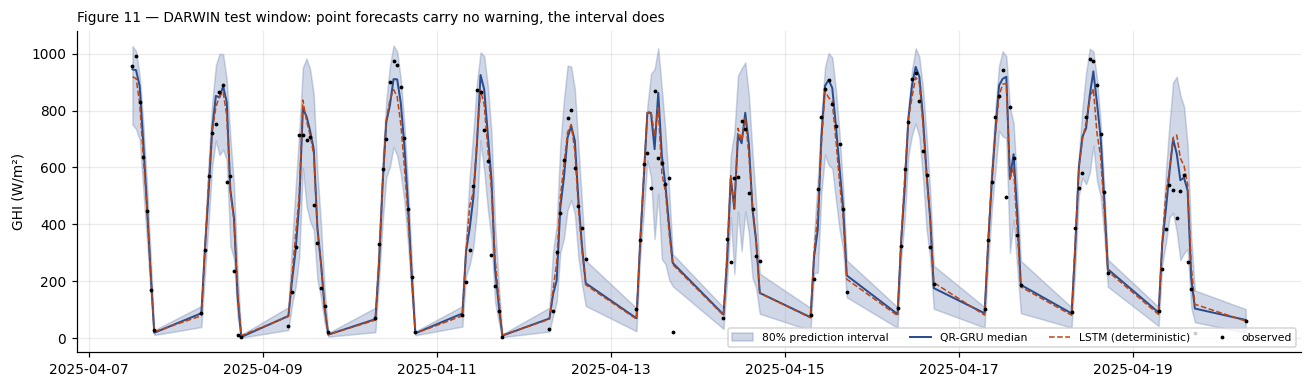

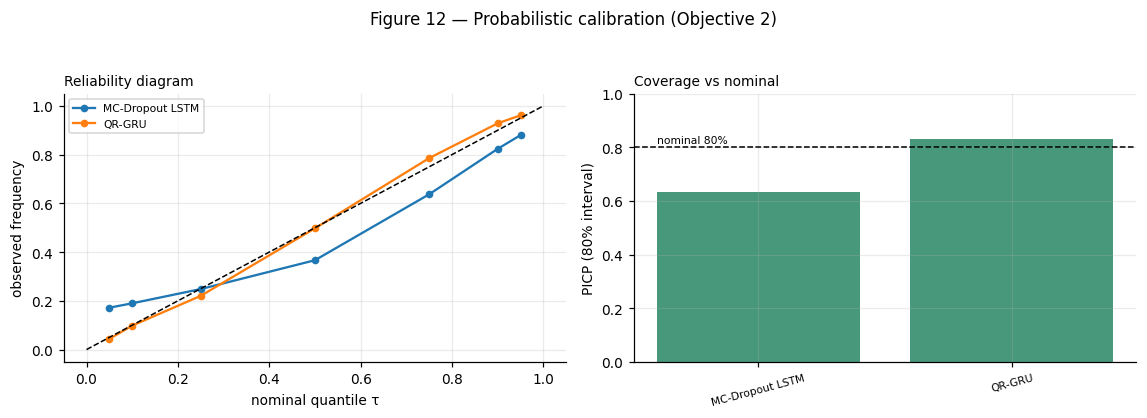

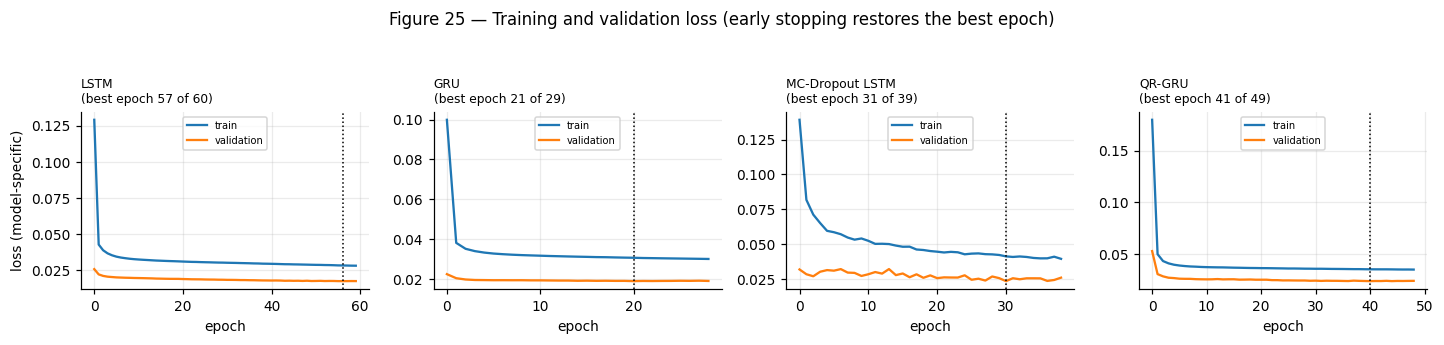

In [ ]:
SCALERS, MODELS, PREDS, HISTS = {}, {}, {}, {}


def run_main():
    split = DATASETS[MODEL_SITE]
    sc = Standardiser().fit(split["train"][0])
    SCALERS[MODEL_SITE] = sc
    Xte, yte, mte = split["test"]
    Xte_s = sc(Xte)

    rows = []
    pk, pm, py = persistence_baseline(split)
    r0 = evaluate("Persistence (baseline)", pk, None, None, py, pm)
    if r0:
        rows.append(r0)

    for kind in MODEL_KINDS:
        model, hist = fit_model(kind, split, sc, tag=f"  [last origin; cfg {model_cfg(kind)}]")
        point, Q, S = predict(kind, model, Xte_s)
        MODELS[kind] = model
        HISTS[kind] = hist.history
        PREDS[kind] = (point, Q, S, yte, mte)
        r = evaluate(kind, point, Q, S, yte, mte)
        if r:
            rows.append(r)
    return pd.DataFrame(rows)


RESULTS_MAIN = run_main()
print(f"\nLAST-ORIGIN RESULTS — {MODEL_SITE} most recent test block, t+{CFG.HORIZON}h, daylight hours, "
      "seed 42.\nDescriptive only: the headline comparison (rolling origin x seeds, with CIs) is Part R.")
print("=" * 118)
print(RESULTS_MAIN.round(3).to_string(index=False))
save_table(RESULTS_MAIN, "results_main")

# ---------------- Figure 11: forecast vs truth with uncertainty band -----------
qr_kind = "QR-GRU" if "QR-GRU" in PREDS else None
if qr_kind:
    point, Q, S, yte, mte = PREDS[qr_kind]
    cs = mte["ghi_cs"].to_numpy()
    n0 = 0          # first ~6 days of daylight test windows (the initial pipeline wrote min(len-1, 0), always 0)
    seg = slice(n0, n0 + 24 * 6)
    fig, ax = plt.subplots(figsize=(12, 3.6))
    t = mte["ts"].iloc[seg]
    ax.fill_between(t, (Q[seg, CFG.QUANTILES.index(0.10)] * cs[seg]).clip(0),
                    (Q[seg, CFG.QUANTILES.index(0.90)] * cs[seg]).clip(0),
                    color="#2a4d8f", alpha=.22, label="80% prediction interval")
    ax.plot(t, (point[seg] * cs[seg]).clip(0), color="#2a4d8f", lw=1.3, label="QR-GRU median")
    if "LSTM" in PREDS:
        ax.plot(t, (PREDS["LSTM"][0][seg] * cs[seg]).clip(0), color="#c1440e",
                lw=1.0, ls="--", label="LSTM (deterministic)")
    ax.plot(t, (yte[seg] * cs[seg]), "k.", ms=3, label="observed")
    ax.set_ylabel("GHI (W/m²)"); ax.legend(fontsize=7, ncol=4)
    ax.set_title(f"Figure 11 — {MODEL_SITE} test window: point forecasts carry no warning, "
                 "the interval does", loc="left", fontsize=9)
    savefig(fig, "fig11_forecast"); plt.show()

# ---------------- Figure 12: calibration / reliability -------------------------
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for kind in [k for k in MODEL_KINDS if k in PROBABILISTIC and k in PREDS]:
    point, Q, S, yte, mte = PREDS[kind]
    cs = mte["ghi_cs"].to_numpy()
    yt = yte * cs
    obs = [float((yt <= np.clip(Q[:, j] * cs, 0, None)).mean()) for j in range(len(CFG.QUANTILES))]
    axes[0].plot(CFG.QUANTILES, obs, "-o", ms=4, label=kind)
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("nominal quantile τ"); axes[0].set_ylabel("observed frequency")
axes[0].set_title("Reliability diagram", fontsize=9, loc="left"); axes[0].legend(fontsize=7)

sub = RESULTS_MAIN.dropna(subset=["PICP_80"])
axes[1].bar(sub.model, sub.PICP_80, color="#1a7f5a", alpha=.8)
axes[1].axhline(0.80, color="k", ls="--", lw=1)
axes[1].text(-.4, .815, "nominal 80%", fontsize=7)
axes[1].set_ylim(0, 1); axes[1].set_ylabel("PICP (80% interval)")
axes[1].tick_params(axis="x", rotation=15, labelsize=7)
axes[1].set_title("Coverage vs nominal", fontsize=9, loc="left")
fig.suptitle("Figure 12 — Probabilistic calibration (Objective 2)", y=1.04)
savefig(fig, "fig12_calibration"); plt.show()

# ---------------- Figure 25 : training histories ----------------------------
if HISTS:
    fig, axes = plt.subplots(1, len(HISTS), figsize=(3.3 * len(HISTS), 2.9), squeeze=False)
    for ax, (kind, h) in zip(axes[0], HISTS.items()):
        ax.plot(h["loss"], label="train"); ax.plot(h["val_loss"], label="validation")
        best = int(np.argmin(h["val_loss"]))
        ax.axvline(best, color="k", ls=":", lw=1)
        ax.set_title(f"{kind}\n(best epoch {best + 1} of {len(h['loss'])})", fontsize=8, loc="left")
        ax.set_xlabel("epoch"); ax.legend(fontsize=6.5)
    axes[0, 0].set_ylabel("loss (model-specific)")
    fig.suptitle("Figure 25 — Training and validation loss (early stopping restores the best epoch)", y=1.06)
    savefig(fig, "fig25_training_curves"); plt.show()
    save_table(pd.DataFrame([{"model": k, "epochs_run": len(h["loss"]),
                              "best_epoch": int(np.argmin(h["val_loss"])) + 1,
                              "best_val_loss": float(np.min(h["val_loss"]))} for k, h in HISTS.items()]),
               "training_summary")

### **Research Stage#12.1 Calibration: PIT, Reliability and Conformal Correction**

Coverage is judged against the nominal 80% interval. A single conformal widening (CQR) is learned on the **calibration** split.

INTERVAL QUALITY BEFORE AND AFTER CONFORMAL RECALIBRATION
          model intervals  PICP_80  MIW_Wm2  Winkler_Wm2  coverage_error  delta_kt
MC-Dropout LSTM       raw   0.6339 121.7287     284.4532         -0.1661    0.1156
MC-Dropout LSTM conformal   0.8412 254.9948     303.8619          0.0412    0.1156
         QR-GRU       raw   0.8303 164.0454     214.1535          0.0303   -0.0019
         QR-GRU conformal   0.8205 161.8492     213.5650          0.0205   -0.0019


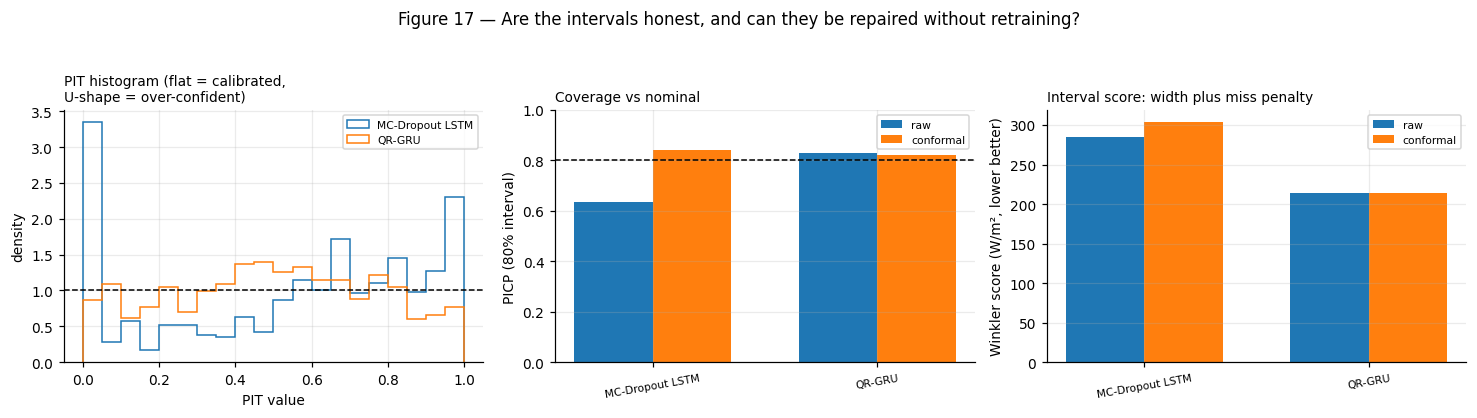

Reading the PIT panel: mass piling up at 0 and 1 means observations fall outside the predictive
distribution more often than they should (intervals too narrow). The conformal correction is a
single additive widening in clear-sky-index units learned on the calibration split only. Coverage
above nominal after correction indicates the calibration period was harder than the test period
(exchangeability only approximate); Winkler tells whether the extra width was bought efficiently.


In [ ]:
COVERAGE = CFG.PI_HIGH - CFG.PI_LOW       # nominal coverage of the central interval (0.80)
ALPHA = 1.0 - COVERAGE                    # nominal miss rate (0.20)
I_LO, I_HI = CFG.QUANTILES.index(CFG.PI_LOW), CFG.QUANTILES.index(CFG.PI_HIGH)


def pit_values(Q_kt, S_kt, y_kt):
    """Probability integral transform of the observation under the predictive law."""
    if S_kt is not None:
        return (S_kt <= y_kt[:, None]).mean(axis=1)
    taus = np.array(CFG.QUANTILES)
    return np.array([np.interp(y, Q_kt[i], taus, left=0.0, right=1.0)
                     for i, y in enumerate(y_kt)])


def winkler(y, lo, hi, alpha=ALPHA):
    w = hi - lo
    w = np.where(y < lo, w + 2.0 / alpha * (lo - y), w)
    w = np.where(y > hi, w + 2.0 / alpha * (y - hi), w)
    return w


def conformal_delta(model, kind, split, sc, alpha=ALPHA):
    """CQR width correction estimated on the CALIBRATION split only .

    an intermediate pipeline used the validation split, which also drove early stopping; the calibration split is now
    disjoint from everything used to fit or select the model, which is what the finite-sample
    guarantee of Romano et al. (2019) requires (under exchangeability).
    """
    Xv, yv, _ = split["cal"]
    _, Qv, Sv = predict(kind, model, sc(Xv))
    if Qv is None:
        return None
    lo, hi = Qv[:, I_LO], Qv[:, I_HI]
    E = np.maximum(lo - yv, yv - hi)
    n = len(E)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    k = min(max(k, 1), n)
    return float(np.sort(E)[k - 1])


CALIB_ROWS, PITS, CONFORMAL = [], {}, {}
split_main = DATASETS[MODEL_SITE]
sc_main = SCALERS[MODEL_SITE]

for kind in [k for k in MODEL_KINDS if k in PROBABILISTIC and k in PREDS]:
    point, Q, S, yte, mte = PREDS[kind]
    cs = mte["ghi_cs"].to_numpy()
    yt = yte * cs
    lo = np.clip(Q[:, I_LO] * cs, 0, None)
    hi = np.clip(Q[:, I_HI] * cs, 0, None)
    PITS[kind] = pit_values(Q, S, yte)

    delta = conformal_delta(MODELS[kind], kind, split_main, sc_main)
    CONFORMAL[kind] = delta
    lo_c = np.clip((Q[:, I_LO] - delta) * cs, 0, None)
    hi_c = np.clip((Q[:, I_HI] + delta) * cs, 0, None)

    for tag, L, H in (("raw", lo, hi), ("conformal", lo_c, hi_c)):
        CALIB_ROWS.append({
            "model": kind, "intervals": tag,
            "PICP_80": float(((yt >= L) & (yt <= H)).mean()),
            "MIW_Wm2": float((H - L).mean()),
            "Winkler_Wm2": float(winkler(yt, L, H).mean()),
            "coverage_error": float(((yt >= L) & (yt <= H)).mean() - COVERAGE),
            "delta_kt": delta})

CALIB = pd.DataFrame(CALIB_ROWS).round(4)
print("INTERVAL QUALITY BEFORE AND AFTER CONFORMAL RECALIBRATION")
print("=" * 110)
print(CALIB.to_string(index=False))
save_table(CALIB, "results_calibration_conformal")

# ---- Figure 17 --------------------------------------------------------------
kinds_p = list(PITS)
if kinds_p:
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
    for kind in kinds_p:
        axes[0].hist(PITS[kind], bins=20, range=(0, 1), density=True,
                     histtype="step", lw=1.8, label=kind)
    axes[0].axhline(1.0, color="k", ls="--", lw=1)
    axes[0].set_xlabel("PIT value"); axes[0].set_ylabel("density")
    axes[0].legend(fontsize=7)
    axes[0].set_title("PIT histogram (flat = calibrated,\nU-shape = over-confident)",
                      fontsize=9, loc="left")

    sub = CALIB.copy()
    xs = np.arange(len(kinds_p)); w = 0.35
    for i, tag in enumerate(("raw", "conformal")):
        v = [sub[(sub.model == k) & (sub.intervals == tag)]["PICP_80"].iloc[0] for k in kinds_p]
        axes[1].bar(xs + (i - .5) * w, v, w, label=tag)
    axes[1].axhline(COVERAGE, color="k", ls="--", lw=1)
    axes[1].set_xticks(xs); axes[1].set_xticklabels(kinds_p, fontsize=7, rotation=10)
    axes[1].set_ylabel("PICP (80% interval)"); axes[1].legend(fontsize=7); axes[1].set_ylim(0, 1)
    axes[1].set_title("Coverage vs nominal", fontsize=9, loc="left")

    for i, tag in enumerate(("raw", "conformal")):
        v = [sub[(sub.model == k) & (sub.intervals == tag)]["Winkler_Wm2"].iloc[0] for k in kinds_p]
        axes[2].bar(xs + (i - .5) * w, v, w, label=tag)
    axes[2].set_xticks(xs); axes[2].set_xticklabels(kinds_p, fontsize=7, rotation=10)
    axes[2].set_ylabel("Winkler score (W/m², lower better)"); axes[2].legend(fontsize=7)
    axes[2].set_title("Interval score: width plus miss penalty", fontsize=9, loc="left")
    fig.suptitle("Figure 17 — Are the intervals honest, and can they be repaired without retraining?",
                 y=1.04)
    savefig(fig, "fig17_calibration_conformal"); plt.show()

    print(textwrap.fill(
        "Reading the PIT panel: mass piling up at 0 and 1 means observations fall outside the "
        "predictive distribution more often than they should (intervals too narrow). The conformal "
        "correction is a single additive widening in clear-sky-index units learned on the "
        "calibration split only. Coverage above nominal after correction indicates the calibration "
        "period was harder than the test period (exchangeability only approximate); Winkler tells "
        "whether the extra width was bought efficiently.", 100))

for kind in CALIB.model.unique():
    for tag in ("raw", "conformal"):
        rr = CALIB[(CALIB.model == kind) & (CALIB.intervals == tag)].iloc[0]
        register(f"last_origin.{kind}.PICP80_{tag}", round(float(rr.PICP_80), 4))

### **Research Stage#12.2 Before vs After: Which Split Should Calibrate the Intervals?**

**Initial approach.** Learn the conformal widening on the **validation** split. That split already chose the training epoch.
**Risk.** The conformal guarantee assumes the calibration data played no part in fitting or selecting the model.
**Rule.** Use a separate **calibration** split.

The test coverage under both choices is shown below. The point is **validity, not a guaranteed numerical gain**, so whatever the difference turns out to be, it is reported as observed.

In [ ]:
rows = []
for kind in [k for k in MODEL_KINDS if k in PROBABILISTIC and k in PREDS]:
    point, Q, S, yte, mte = PREDS[kind]
    cs = mte["ghi_cs"].to_numpy(); yt = yte * cs
    for tag, part in (("validation split (initial)", "val"), ("calibration split (final)", "cal")):
        dl = conformal_delta(MODELS[kind], kind, {"cal": split_main[part]}, sc_main)
        lo = np.clip((Q[:, I_LO] - dl) * cs, 0, None); hi = np.clip((Q[:, I_HI] + dl) * cs, 0, None)
        rows.append({"model": kind, "conformal fitted on": tag, "widening (k_t)": dl,
                     "test PICP80": float(((yt >= lo) & (yt <= hi)).mean()), "test MIW (W/m²)": float((hi - lo).mean())})
CAL_CHOICE = pd.DataFrame(rows)
display(CAL_CHOICE.round(4))

,model,conformal fitted on,widening (k_t),test PICP80,test MIW (W/m²)
0,MC-Dropout LSTM,validation split (initial),0.0470,0.7474,175.9181
1,MC-Dropout LSTM,calibration split (final),0.1161,0.8418,255.5724
2,QR-GRU,validation split (initial),-0.0133,0.7730,148.6673
3,QR-GRU,calibration split (final),-0.0019,0.8205,161.8492


### **Research Stage#12.3 Error Structure: Where and Why the Models Fail**

ERROR STRUCTURE BY SKY-CONDITION REGIME
          model          sky    n     MAE    RMSE    bias      sd
            GRU     Overcast   26 109.363 140.689 109.363  90.257
            GRU Broken cloud  359  74.828 105.618  65.608  82.885
            GRU        Clear 1448  41.666  61.228 -30.131  53.319
           LSTM     Overcast   26 123.048 153.715 123.048  93.951
           LSTM Broken cloud  359  84.126 118.503  76.730  90.433
           LSTM        Clear 1448  36.238  55.084 -16.571  52.551
MC-Dropout LSTM     Overcast   26 128.665 161.141 128.665  98.935
MC-Dropout LSTM Broken cloud  359  86.421 119.866  83.662  85.959
MC-Dropout LSTM        Clear 1448  43.343  57.664 -30.544  48.927
         QR-GRU     Overcast   26 107.250 143.538 102.209 102.776
         QR-GRU Broken cloud  359  84.530 121.832  77.228  94.360
         QR-GRU        Clear 1448  31.843  52.719  -8.826  51.993

RESIDUAL AUTOCORRELATION (0 = no exploitable structure left)
lag_h               1      2      3     

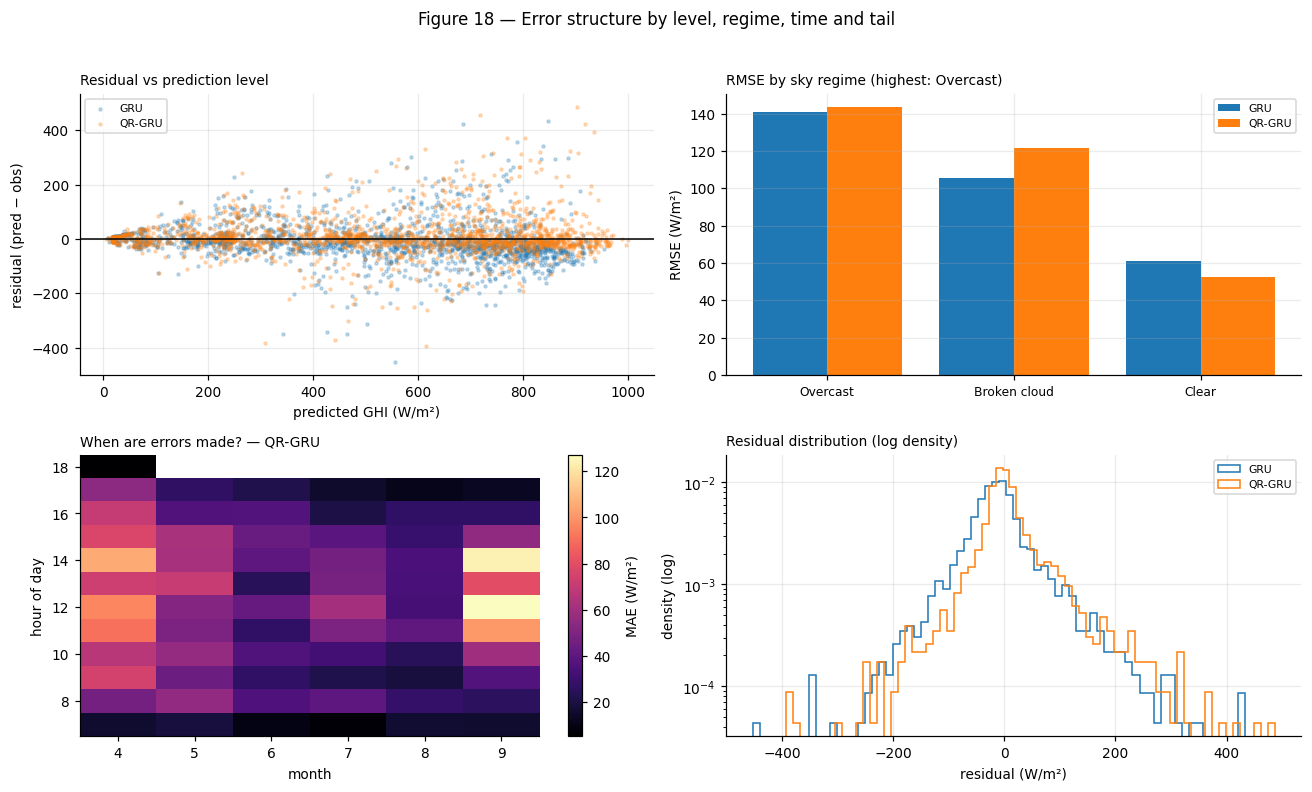


INTERPRETATION (generated)
Across models, mean RMSE is highest in 'Overcast' hours (Overcast: 150, Broken cloud: 116, Clear: 57
W/m²). Mean bias under overcast is +116 W/m² (positive = over-prediction) and under clear sky -22
W/m². A large positive overcast bias means the models pull k_t toward its typical value when the sky
is dark — an expected consequence of forecasting cloud state from cloud history alone, with no
exogenous signal of cloud arrival.


{'LSTM': 0.073, 'GRU': 0.046, 'MC-Dropout LSTM': 0.233, 'QR-GRU': -0.035}

In [ ]:
def residual_frame(kind):
    point, Q, S, yte, mte = PREDS[kind]
    cs = mte["ghi_cs"].to_numpy()
    yhat = np.clip(point * cs, 0, None)
    ytrue = yte * cs
    d = mte.copy()
    d["y"] = ytrue
    d["yhat"] = yhat
    d["resid"] = yhat - ytrue
    d["abserr"] = np.abs(d["resid"])
    d["kt_true"] = yte
    d["sky"] = classify_sky(pd.Series(yte, index=d.index))
    d["hour"] = d["ts"].dt.hour
    d["month"] = d["ts"].dt.month
    d["model"] = kind
    return d


RESID = pd.concat([residual_frame(k) for k in MODEL_KINDS if k in PREDS], ignore_index=True)
save_table(RESID.drop(columns=["ghi_cs"], errors="ignore").assign(ts=RESID.ts.astype(str)),
           "residuals_test")

# ---- 1. residual autocorrelation --------------------------------------------
acf_rows = []
for kind in [k for k in MODEL_KINDS if k in PREDS]:
    r = RESID[RESID.model == kind].sort_values("ts")["resid"].reset_index(drop=True)
    for lag in (1, 2, 3, 24):
        if len(r) > lag + 10:
            acf_rows.append({"model": kind, "lag_h": lag, "resid_autocorr": float(r.autocorr(lag))})
RESID_ACF = pd.DataFrame(acf_rows)

# ---- 2. heteroscedasticity: error vs sky regime ------------------------------
het = (RESID.dropna(subset=["sky"])
       .groupby(["model", "sky"], observed=True)
       .agg(n=("abserr", "size"), MAE=("abserr", "mean"),
            RMSE=("resid", lambda s: float(np.sqrt((s ** 2).mean()))),
            bias=("resid", "mean"), sd=("resid", "std"))
       .reset_index())
het["sky"] = pd.Categorical(het["sky"], SKY_ORDER, ordered=True)
HETERO = het.sort_values(["model", "sky"]).round(3)

print("ERROR STRUCTURE BY SKY-CONDITION REGIME")
print("=" * 100)
print(HETERO.to_string(index=False))
save_table(HETERO, "results_error_by_regime")
print("\nRESIDUAL AUTOCORRELATION (0 = no exploitable structure left)")
print(RESID_ACF.pivot(index="model", columns="lag_h", values="resid_autocorr").round(3).to_string())
save_table(RESID_ACF, "results_residual_acf")

# ---- 3. extreme errors -------------------------------------------------------
ext_rows = []
for kind in [k for k in MODEL_KINDS if k in PREDS]:
    r = RESID[RESID.model == kind]
    thr = r["abserr"].quantile(0.99)
    tail = r[r.abserr >= thr]
    ext_rows.append({
        "model": kind, "p99_abserr_Wm2": float(thr),
        "max_abserr_Wm2": float(r.abserr.max()),
        "tail_share_of_SSE_%": float(100 * (tail.resid ** 2).sum() / (r.resid ** 2).sum()),
        "tail_in_broken_cloud_%": float(100 * (tail.sky == "Broken cloud").mean()),
        "tail_on_ramp_hours_%": float(100 * tail.is_ramp.mean()),
        "tail_wet_season_%": float(100 * (tail.is_wet > 0).mean()),
        "tail_median_hour": float(tail.hour.median())})
EXTREME = pd.DataFrame(ext_rows).round(2)
print("\nEXTREME-ERROR ANATOMY (worst 1% of hours)")
print(EXTREME.to_string(index=False))
save_table(EXTREME, "results_extreme_errors")

# ---- Figure 18 ---------------------------------------------------------------
best_det = min([k for k in MODEL_KINDS if k in PREDS and k not in PROBABILISTIC],
               key=lambda k: RESID[RESID.model == k].resid.pow(2).mean(), default=None)
best_prob = min([k for k in MODEL_KINDS if k in PREDS and k in PROBABILISTIC],
                key=lambda k: RESID[RESID.model == k].resid.pow(2).mean(), default=None)
show = [k for k in (best_det, best_prob) if k]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
ax = axes[0, 0]
for kind in show:
    r = RESID[RESID.model == kind]
    ax.scatter(r["yhat"], r["resid"], s=4, alpha=.25, label=kind)
ax.axhline(0, color="k", lw=1)
ax.set_xlabel("predicted GHI (W/m²)"); ax.set_ylabel("residual (pred − obs)")
ax.legend(fontsize=7)
ax.set_title("Residual vs prediction level", fontsize=9, loc="left")

ax = axes[0, 1]
xs = np.arange(len(SKY_ORDER)); w = 0.8 / max(len(show), 1)
for i, kind in enumerate(show):
    h = HETERO[HETERO.model == kind].set_index("sky").reindex(SKY_ORDER)
    ax.bar(xs + (i - (len(show) - 1) / 2) * w, h["RMSE"], w, label=kind)
ax.set_xticks(xs); ax.set_xticklabels(SKY_ORDER, fontsize=8)
ax.set_ylabel("RMSE (W/m²)"); ax.legend(fontsize=7)
_worst = HETERO.groupby("sky", observed=True)["RMSE"].mean().idxmax()
ax.set_title(f"RMSE by sky regime (highest: {_worst})", fontsize=9, loc="left")

ax = axes[1, 0]
if show:
    r = RESID[RESID.model == show[-1]]
    piv = r.pivot_table(index="hour", columns="month", values="abserr", aggfunc="mean")
    im = ax.imshow(piv, aspect="auto", origin="lower", cmap="magma",
                   extent=[piv.columns.min() - .5, piv.columns.max() + .5,
                           piv.index.min() - .5, piv.index.max() + .5])
    fig.colorbar(im, ax=ax, label="MAE (W/m²)")
    ax.set_xlabel("month"); ax.set_ylabel("hour of day"); ax.grid(False)
    ax.set_title(f"When are errors made? — {show[-1]}", fontsize=9, loc="left")

ax = axes[1, 1]
for kind in show:
    r = RESID[RESID.model == kind]["resid"]
    ax.hist(r, bins=70, density=True, histtype="step", lw=1.6, label=kind)
ax.set_yscale("log"); ax.set_xlabel("residual (W/m²)"); ax.set_ylabel("density (log)")
ax.legend(fontsize=7)
ax.set_title("Residual distribution (log density)", fontsize=9, loc="left")
fig.suptitle("Figure 18 — Error structure by level, regime, time and tail", y=1.02)
savefig(fig, "fig18_residuals"); plt.show()

# ---- generated interpretation of the regime table (no hard-coded claims) -----------------
_b = HETERO.pivot_table(index="model", columns="sky", values="bias", observed=True)
_r = HETERO.pivot_table(index="model", columns="sky", values="RMSE", observed=True)
_rs = {r: float(_r[r].mean()) for r in _r.columns}
_worst_r = max(_rs, key=_rs.get)
print("\nINTERPRETATION (generated)")
print(textwrap.fill(
    f"Across models, mean RMSE is highest in '{_worst_r}' hours "
    f"({', '.join(f'{k}: {v:.0f}' for k, v in _rs.items())} W/m²). Mean bias under overcast is "
    f"{_b['Overcast'].mean():+.0f} W/m² (positive = over-prediction) and under clear sky "
    f"{_b['Clear'].mean():+.0f} W/m². A large positive overcast bias means the models pull k_t toward "
    "its typical value when the sky is dark — an expected consequence of forecasting cloud state "
    "from cloud history alone, with no exogenous signal of cloud arrival.", 100)
    if {"Overcast", "Clear"} <= set(_b.columns) else "regime table incomplete")
if {"Overcast", "Clear"} <= set(_b.columns):
    register("last_origin.overcast_bias_mean_Wm2", round(float(_b["Overcast"].mean()), 1))
register("last_origin.residual_acf_lag1", RESID_ACF[RESID_ACF.lag_h == 1].set_index("model")["resid_autocorr"].round(3).to_dict())

# **PART J · Season, Ramp, PV-Proxy, Cross-Climate and Decision-Support Analysis**

> *Navigation header added for the VIVA. It covers Stage 13 below. No original cell was changed.*

---
# **Research Stage#13 — Subgroups, Ramps, Proxy Validation, Transfer and Decision Support**

### **Research Stage#13.1 Season and Ramp Subgroups (Descriptive, Last Origin)**

The single-seed "remove `is_wet`" test is **not** used to judge seasonal conditioning; Stage 14 shows why. This cell is descriptive only.


SUBGROUP ANALYSIS — where uncertainty quantification earns its keep
          model     subgroup    n  RMSE_Wm2  CRPS_Wm2  PICP_80  MIW_Wm2
           LSTM all daylight 1833    74.044    46.848      NaN      NaN
           LSTM  ramp events  113   160.231   113.784      NaN      NaN
           LSTM   wet season  264   102.432    72.314      NaN      NaN
           LSTM   dry season 1569    68.114    42.564      NaN      NaN
            GRU all daylight 1833    73.668    49.121      NaN      NaN
            GRU  ramp events  113   161.831   114.069      NaN      NaN
            GRU   wet season  264   100.733    73.968      NaN      NaN
            GRU   dry season 1569    68.064    44.940      NaN      NaN
MC-Dropout LSTM all daylight 1833    76.217    39.595    0.634  121.729
MC-Dropout LSTM  ramp events  113   156.079    98.129    0.159   92.418
MC-Dropout LSTM   wet season  264    99.659    56.483    0.455  120.286
MC-Dropout LSTM   dry season 1569    71.521    36.753    0.664  121

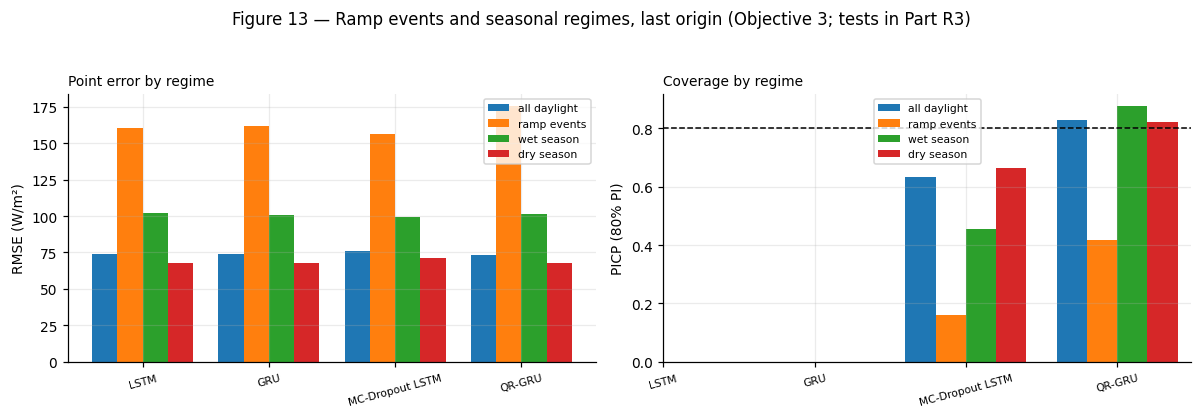

In [ ]:
# the single-seed "remove is_wet" ablation that lived here is withdrawn. It could not test
# seasonal conditioning because doy_sin/doy_cos (which encode the month) stayed in the model, and its
# sign flipped between the initial pipeline and an intermediate pipeline. The replacement is the three-arm, multi-seed, rolling-origin design
# in Part R3. This cell keeps the SUBGROUP analysis of the last-origin models.
# ---- ramp-event subgroup ------------------------------------------------------
ramp_rows = []
for kind in MODEL_KINDS:
    if kind not in PREDS:
        continue
    point, Q, S, yte, mte = PREDS[kind]
    for label, mask in (("all daylight", np.ones(len(yte), bool)),
                        ("ramp events", mte["is_ramp"].to_numpy().astype(bool)),
                        ("wet season", mte["is_wet"].to_numpy() > 0),
                        ("dry season", mte["is_wet"].to_numpy() == 0)):
        r = evaluate(kind, point, Q, S, yte, mte, subset=mask)
        if r:
            r["subgroup"] = label
            ramp_rows.append(r)
SUBGROUP = pd.DataFrame(ramp_rows)
_want_sg = {"all daylight", "ramp events", "wet season", "dry season"}
_missing_sg = _want_sg - set(SUBGROUP.get("subgroup", pd.Series(dtype=str)))
if _missing_sg:
    log(f"subgroup(s) with <10 test hours, omitted: {sorted(_missing_sg)} "
        f"(the chronological test split does not span them)", "warn")
print("\nSUBGROUP ANALYSIS — where uncertainty quantification earns its keep")
print("=" * 118)
print(SUBGROUP[["model", "subgroup", "n", "RMSE_Wm2", "CRPS_Wm2",
                "PICP_80", "MIW_Wm2"]].round(3).to_string(index=False))
save_table(SUBGROUP, "results_subgroup")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
order = [k for k in MODEL_KINDS if k in set(SUBGROUP.model)]
w = 0.2
for i, sg in enumerate(["all daylight", "ramp events", "wet season", "dry season"]):
    s = SUBGROUP[SUBGROUP.subgroup == sg].set_index("model").reindex(order)
    axes[0].bar(np.arange(len(order)) + (i - 1.5) * w, s.RMSE_Wm2, w, label=sg)
    axes[1].bar(np.arange(len(order)) + (i - 1.5) * w, s.PICP_80, w, label=sg)
for ax, ttl, yl in ((axes[0], "Point error by regime", "RMSE (W/m²)"),
                    (axes[1], "Coverage by regime", "PICP (80% PI)")):
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(order, rotation=15, fontsize=7)
    ax.set_title(ttl, fontsize=9, loc="left"); ax.set_ylabel(yl); ax.legend(fontsize=7)
axes[1].axhline(.8, color="k", ls="--", lw=1)
fig.suptitle("Figure 13 — Ramp events and seasonal regimes, last origin (Objective 3; tests in Part R3)", y=1.04)
savefig(fig, "fig13_subgroup"); plt.show()

### **Research Stage#13.2 Extreme Conditions: The Hours That Decide Operational Value**

PERFORMANCE BY OPERATING CONDITION (corrected ramp definition)
          model         condition    n  RMSE_Wm2  MAE_Wm2  CRPS_Wm2  PICP_80  MIW_Wm2
           LSTM      All daylight 1833    74.044   46.848    46.848      NaN      NaN
           LSTM  Ramp (corrected)  113   160.231  113.784   113.784      NaN      NaN
           LSTM          Non-ramp 1720    64.466   42.451    42.451      NaN      NaN
           LSTM     Sky: Overcast   26   153.715  123.048   123.048      NaN      NaN
           LSTM Sky: Broken cloud  359   118.503   84.126    84.126      NaN      NaN
           LSTM        Sky: Clear 1448    55.084   36.238    36.238      NaN      NaN
            GRU      All daylight 1833    73.668   49.121    49.121      NaN      NaN
            GRU  Ramp (corrected)  113   161.831  114.069   114.069      NaN      NaN
            GRU          Non-ramp 1720    63.741   44.854    44.854      NaN      NaN
            GRU     Sky: Overcast   26   140.689  109.363   109.363      NaN 

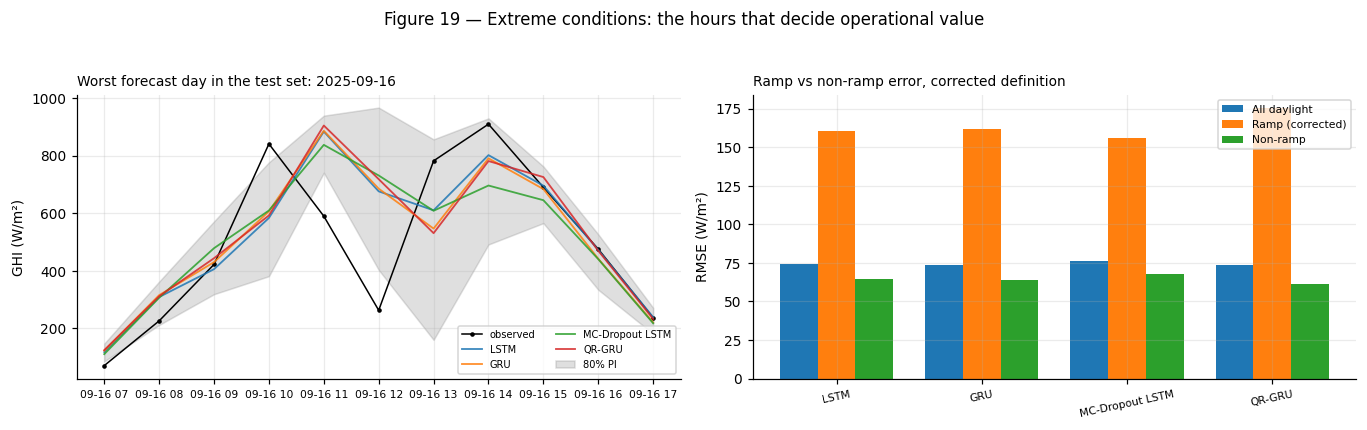

In [ ]:
def ramp_mask_for(meta):
    """Corrected ramp flag looked up from FEAT by timestamp.

    Joining on ts rather than reading meta['is_ramp'] makes this independent of
    whether the supervised windows were built before or after Part 5A applied the
    elevation floor, so the corrected definition is always the one used here.
    """
    ref = (FEAT[FEAT.site == MODEL_SITE][["ts", "is_ramp_kt"]]
           .drop_duplicates("ts").set_index("ts")["is_ramp_kt"])
    return ref.reindex(meta["ts"]).fillna(False).to_numpy().astype(bool)


ramp_rows = []
for kind in [k for k in MODEL_KINDS if k in PREDS]:
    point, Q, S, yte, mte = PREDS[kind]
    ramp = ramp_mask_for(mte)
    subsets = {
        "All daylight": np.ones(len(yte), bool),
        "Ramp (corrected)": ramp,
        "Non-ramp": ~ramp,
    }
    sky = classify_sky(pd.Series(yte))
    for s in SKY_ORDER:
        subsets[f"Sky: {s}"] = (sky == s).to_numpy()
    for label, mask in subsets.items():
        r = evaluate(kind, point, Q, S, yte, mte, subset=mask)
        if r:
            r["condition"] = label
            r["skill_vs_persistence_%"] = skill(r["RMSE_Wm2"])
            ramp_rows.append(r)

CONDITIONS = pd.DataFrame(ramp_rows)
cols = ["model", "condition", "n", "RMSE_Wm2", "MAE_Wm2", "CRPS_Wm2", "PICP_80", "MIW_Wm2"]
print("PERFORMANCE BY OPERATING CONDITION (corrected ramp definition)")
print("=" * 118)
print(CONDITIONS[cols].round(3).to_string(index=False))
save_table(CONDITIONS, "results_by_condition")

old_new = []
for kind in [k for k in MODEL_KINDS if k in PREDS]:
    point, Q, S, yte, mte = PREDS[kind]
    a = evaluate(kind, point, Q, S, yte, mte, subset=np.ones(len(yte), bool))
    b = evaluate(kind, point, Q, S, yte, mte, subset=ramp_mask_for(mte))
    if a and b:
        old_new.append({"model": kind, "all_RMSE": a["RMSE_Wm2"], "ramp_RMSE": b["RMSE_Wm2"],
                        "ramp_penalty_%": 100 * (b["RMSE_Wm2"] - a["RMSE_Wm2"]) / a["RMSE_Wm2"],
                        "ramp_n": b["n"]})
RAMP_PENALTY = pd.DataFrame(old_new).round(2)
print("\nRAMP PENALTY UNDER THE CORRECTED DEFINITION")
print(RAMP_PENALTY.to_string(index=False))
save_table(RAMP_PENALTY, "results_ramp_penalty")

# ---- Figure 19: worst-day case study ----------------------------------------
if len(RESID):
    ref_model = best_prob or best_det
    r = RESID[RESID.model == ref_model].copy()
    r["day"] = r["ts"].dt.floor("D")
    worst_day = r.groupby("day")["abserr"].mean().idxmax()
    day = r[r.day == worst_day].sort_values("ts")

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.7))
    ax = axes[0]
    ax.plot(day["ts"], day["y"], "k.-", ms=4, lw=1, label="observed")
    for kind in [k for k in MODEL_KINDS if k in PREDS]:
        dk = RESID[(RESID.model == kind) & (RESID.ts.dt.floor("D") == worst_day)].sort_values("ts")
        ax.plot(dk["ts"], dk["yhat"], lw=1.2, alpha=.85, label=kind)
    if ref_model in PROBABILISTIC and ref_model in PREDS:
        point, Q, S, yte, mte = PREDS[ref_model]
        sel = mte["ts"].dt.floor("D") == worst_day
        cs = mte["ghi_cs"].to_numpy()[sel.to_numpy()]
        ax.fill_between(mte["ts"][sel],
                        np.clip(Q[sel.to_numpy(), I_LO] * cs, 0, None),
                        np.clip(Q[sel.to_numpy(), I_HI] * cs, 0, None),
                        color="grey", alpha=.25, label="80% PI")
    ax.set_ylabel("GHI (W/m²)"); ax.legend(fontsize=6.5, ncol=2)
    ax.set_title(f"Worst forecast day in the test set: {worst_day:%Y-%m-%d}", fontsize=9, loc="left")
    ax.tick_params(axis="x", labelsize=7)

    ax = axes[1]
    order = [k for k in MODEL_KINDS if k in PREDS]
    conds = ["All daylight", "Ramp (corrected)", "Non-ramp"]
    w = 0.26
    for i, c in enumerate(conds):
        v = [CONDITIONS[(CONDITIONS.model == k) & (CONDITIONS.condition == c)]["RMSE_Wm2"]
             for k in order]
        v = [float(x.iloc[0]) if len(x) else np.nan for x in v]
        ax.bar(np.arange(len(order)) + (i - 1) * w, v, w, label=c)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=12, fontsize=7)
    ax.set_ylabel("RMSE (W/m²)"); ax.legend(fontsize=7)
    ax.set_title("Ramp vs non-ramp error, corrected definition", fontsize=9, loc="left")
    fig.suptitle("Figure 19 — Extreme conditions: the hours that decide operational value", y=1.04)
    savefig(fig, "fig19_ramp_extreme"); plt.show()

### **Research Stage#13.3 Proxy validation, part 1: how *not* to compare irradiance with PV**

**Initial approach.** Compare irradiance skill (target k_t) with PV skill (target PV/capacity), each measured against its own persistence.

**Analysis.** Two checks on the Alice Springs data:

1. **Reference strength.** For each target, compare plain persistence y(t+1) = y(t) with smart persistence, which rescales by the clear-sky ratio. For a clear-sky index the two are identical by construction. If smart persistence is much better for PV/capacity, then plain persistence is a **handicapped** reference for that target, and PV skill measured against it is inflated.
2. **Window integrity.** Deleting the hours where either target is missing *before* forming 24-row windows produces "windows" that silently span days of missing data. The check measures how often that happens.

In [ ]:
dA = FEAT[FEAT.site == "ALICE"].sort_values("ts").reset_index(drop=True).copy() if "ALICE" in SITES_OK else None
if dA is not None and dA["pv_kw"].notna().sum() > 500:
    n_tr = int(len(dA) * CFG.TRAIN_FRAC)
    cap = float(np.nanpercentile(dA.pv_kw.iloc[:n_tr], 99.5))
    dA["pv_cap"] = (dA.pv_kw / cap).clip(0, 1.2)
    ok_day = dA.is_daylight & (dA.solar_elev_deg > 15) & dA.pv_kw.notna()
    k_cap = float(np.nanpercentile((dA.pv_kw / dA.ghi_cs)[ok_day & (dA.index < n_tr)], 99.5))
    dA["pv_kt"] = (dA.pv_kw / (k_cap * dA.ghi_cs.where(dA.is_daylight))).clip(0, CFG.KT_MAX)
    dd = dA[dA.is_daylight & dA.kt.notna() & dA.pv_kt.notna()].index
    ratio = (dA.ghi_cs / dA.ghi_cs.shift(1)).where(dA.ghi_cs.shift(1) > CFG.DAYLIGHT_CS_MIN)
    rows = []
    for col, label, is_index in (("kt", "irradiance k_t", True), ("pv_cap", "PV / capacity (initial target)", False),
                                 ("pv_kt", "PV clear-sky index (final target)", True)):
        cur, prev = dA[col].loc[dd], dA[col].shift(1).loc[dd]
        smart = prev if is_index else prev * ratio.loc[dd]
        ok = cur.notna() & prev.notna() & smart.notna()
        rp, rs = np.sqrt(((prev - cur)[ok] ** 2).mean()), np.sqrt(((smart - cur)[ok] ** 2).mean())
        rows.append({"target": label, "plain persistence RMSE": rp, "smart persistence RMSE": rs,
                     "smart better than plain by %": 100 * (1 - rs / rp)})
    PROXY_REF = pd.DataFrame(rows); display(PROXY_REF.round(3))
    both = dA.kt.notna() & dA.pv_kw.notna()
    kept = dA.loc[both, "ts"].reset_index(drop=True)
    span_h = (kept.shift(-(CFG.LOOKBACK - 1)) - kept).dt.total_seconds() / 3600
    bridged = float((span_h > CFG.LOOKBACK - 1 + 1e-6).mean())
    print(f"Row deletion before windowing: {100*bridged:.1f}% of 24-row windows would span more than 24 real hours.")
    register("proxy.initial_target_smart_vs_plain_pct", round(float(PROXY_REF.iloc[1, 3]), 1))
    register("proxy.row_deletion_bridged_windows_pct", round(100 * bridged, 1))
else:
    print("Alice Springs measured PV not available — proxy diagnostics skipped.")

,target,plain persistence RMSE,smart persistence RMSE,smart better than plain by %
0,irradiance k_t,0.272,0.272,0.000
1,PV / capacity (initial target),0.112,0.059,47.734
2,PV clear-sky index (final target),0.110,0.110,0.000


Row deletion before windowing: 8.7% of 24-row windows would span more than 24 real hours.


**Decision rules** (implemented in 13.4):

1. **Like-for-like targets.** PV becomes a clear-sky index, PV / (k_cap · GHI_cs), with k_cap fitted on training hours only.
2. **Each target is forecast from its own history.** PV models see PV history, irradiance models see k_t history.
3. **Full hourly grid.** Both targets are masked to their common availability, so no window spans a gap.
4. **Seed replication.** Three seeds per target and architecture; a difference smaller than twice the seed SD is not treated as a finding.

### **Research Stage#13.4 Proxy Validation, Part 2: The Corrected Matched Test**

[ 7882.1s |   2871MB]  ok matched proxy grid: 6,924 daylight hours with BOTH targets
[ 7883.1s |   2921MB]  ok cache complete 'proxy_matched_v71_v7_8be37a7834_EXT_sample_EXT_L24H1' (24 rows)
PROXY VALIDATION — Alice Springs, matched timestamps, 3 seeds, skill vs each target's OWN persistence
          model                        target  n_test  skill_mean  skill_sd  nRMSE_mean  RMSE_equiv_Wm2  median_best_epoch
            GRU              Irradiance (k_t)     936      45.527     0.430   16.261999          65.692               39.0
            GRU Measured PV (clear-sky index)     936      53.370     1.000   13.657000          31.111               13.0
           LSTM              Irradiance (k_t)     936      45.951     0.986   16.135000          64.712               45.0
           LSTM Measured PV (clear-sky index)     936      52.376     1.298   13.948000          31.146               15.0
MC-Dropout LSTM              Irradiance (k_t)     936      38.489     3.689   18.363001     

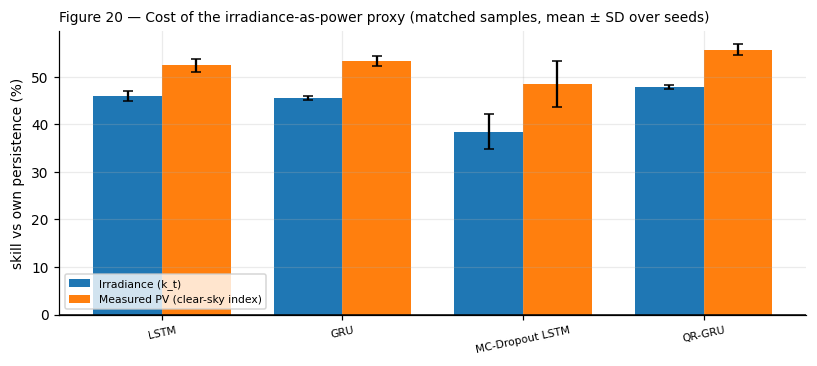

In [ ]:
def _mirror_features(e: pd.DataFrame, col: str) -> pd.DataFrame:
    """Rebuild the k_t-history features from `col`, so each target is forecast from ITS OWN history.

    an intermediate pipeline gave the PV-target model k_t history only, while its natural reference (PV persistence) uses
    recent PV — an asymmetry that penalises the PV target. Here both targets get identical feature
    engineering applied to their own series; geometry/calendar features are shared.
    """
    e = e.copy()
    e["kt"] = e[col]
    for L in (1, 2, 3, 24):
        e[f"kt_lag{L}"] = e["kt"].shift(L)
    for W in (3, 24):
        r = e["kt"].rolling(W, min_periods=max(2, W // 3))
        e[f"kt_roll{W}_mean"] = r.mean().shift(1)
        e[f"kt_roll{W}_std"] = r.std().shift(1)
    return e


def build_matched_proxy():
    """Alice hourly grid with BOTH targets masked to their common availability .

    an intermediate pipeline dropped the non-matching ROWS, so a 24-row window could span days of missing data and still
    be treated as 24 consecutive hours. the final pipeline keeps the complete hourly grid and sets both targets to NaN
    wherever either is missing in daylight; windows touching such hours are discarded by
    build_supervised.
    """
    if "ALICE" not in SITES_OK:
        return None
    d = FEAT[FEAT.site == "ALICE"].sort_values("ts").reset_index(drop=True).copy()
    if d["pv_kw"].notna().sum() < 500:
        return None
    # the PV target is a PV CLEAR-SKY INDEX, pv_kt = PV / (k_cap * GHI_cs), the exact analogue of
    # k_t = GHI / GHI_cs. the final pipeline used PV/capacity, which still contains the diurnal cycle: persistence of
    # such a series is a weak reference (at t+1 in the morning it misses the whole rise), so "skill vs
    # own persistence" was inflated for PV and the irradiance-minus-PV delta came out spuriously
    # negative. k_cap is the 99.5th percentile of PV/GHI_cs on high-sun daylight hours (elevation >
    # 15 deg), i.e. the plant's clear-sky response per W/m2; it is a single constant, fitted on the
    # training portion only, so it cannot leak test information.
    day = d["is_daylight"] & (d["solar_elev_deg"] > ELEV_FLOOR_DEG) & d["pv_kw"].notna()
    n_tr = int(len(d) * CFG.TRAIN_FRAC)
    ratio = (d.loc[day, "pv_kw"] / d.loc[day, "ghi_cs"]).loc[lambda r: r.index < n_tr]
    k_cap = float(np.nanpercentile(ratio, 99.5))
    cap = k_cap
    pv_kt = d["pv_kw"] / (k_cap * d["ghi_cs"].where(d["is_daylight"]))
    d["pv_norm"] = pv_kt.clip(0, CFG.KT_MAX)
    miss = d["pv_norm"].isna() & d["is_daylight"]
    runs = _gap_lengths(miss)
    d["pv_norm"] = np.where(miss & (runs <= CFG.MAX_INTERP_GAP_H),
                            d["pv_norm"].interpolate(limit=CFG.MAX_INTERP_GAP_H, limit_area="inside"),
                            d["pv_norm"])
    d.loc[~d.is_daylight, "pv_norm"] = 0.0                               # same night convention as k_t
    bad = d.is_daylight & (d.kt.isna() | d.pv_norm.isna())
    d.loc[bad, ["kt", "pv_norm"]] = np.nan
    register("proxy.pv_clear_sky_response_kW_per_Wm2", round(k_cap, 5),
             "k_cap: 99.5th pct of PV/GHI_cs, elevation > 15 deg, training portion")
    log(f"matched proxy grid: {int((d.is_daylight & ~bad).sum()):,} daylight hours with BOTH targets", "ok")
    return {"kt": _mirror_features(d, "kt"), "pv_norm": _mirror_features(d, "pv_norm")}, cap


mp = build_matched_proxy()
PROXY_MATCHED = PROXY_SUMMARY = None
PROXY_SEEDS = CFG.SEEDS[:3]
if mp is None:
    log("Alice PV unavailable — matched proxy validation skipped", "warn")
else:
    frames, cap = mp
    PX = {}
    for target, fr in frames.items():
        built = build_supervised(fr, ALL_FEATURES, target="kt")
        if built is not None:
            X, y, meta = built
            PX[target] = chrono_split(X, y, meta)
    _common = None
    if len(PX) == 2:
        _common = set(PX["kt"]["test"][2].ts) & set(PX["pv_norm"]["test"][2].ts)
        register("proxy.identical_test_timestamps",
                 len(_common) == len(PX["kt"]["test"][2]) == len(PX["pv_norm"]["test"][2]))
    _jkt = ALL_FEATURES.index("kt")

    def _proxy_unit(u):
        sp = PX[u["target"]]
        sc = Standardiser().fit(sp["train"][0])
        m, hist = fit_model(u["model"], sp, sc, tag=None, seed=int(u["seed"]))
        Xte, yte, mte = sp["test"]
        p, Q, S = predict(u["model"], m, sc(Xte), seed=int(u["seed"]))
        keep = mte.ts.isin(_common).to_numpy() if _common is not None else np.ones(len(yte), bool)
        prev = Xte[:, -1, _jkt]                    # the target's own value at t (persistence)
        ok = keep & np.isfinite(prev)
        e_m, e_p = (p - yte)[ok], (prev - yte)[ok]
        cs_ = mte["ghi_cs"].to_numpy()[ok]            # clear-sky index error x GHI_cs = W/m2-equivalent
        rm, rp = float(np.sqrt((e_m ** 2).mean())), float(np.sqrt((e_p ** 2).mean()))
        ss = ((yte[ok] - yte[ok].mean()) ** 2).sum()
        del m
        tf.keras.backend.clear_session(); gc.collect()
        return [{"n_test": int(ok.sum()), "RMSE_norm": rm, "RMSE_persistence": rp,
                 "RMSE_equiv_Wm2": float(np.sqrt(((e_m * cs_) ** 2).mean())),
                 "skill_vs_own_persistence_%": 100 * (1 - rm / rp) if rp > 0 else np.nan,
                 "nRMSE_%": 100 * rm / yte[ok].mean(), "R2": float(1 - (e_m ** 2).sum() / ss),
                 "epochs": len(hist.history["loss"]),
                 "best_epoch": int(np.argmin(hist.history["val_loss"])) + 1}]

    _units = [{"target": t, "model": k, "seed": s} for t in PX for k in MODEL_KINDS for s in PROXY_SEEDS]
    PROXY_MATCHED = cached_units(ck("proxy_matched_v71"), _units, _proxy_unit, ["target", "model", "seed"])
    PROXY_MATCHED["target"] = PROXY_MATCHED["target"].map({"kt": "Irradiance (k_t)",
                                                           "pv_norm": "Measured PV (clear-sky index)"})
    g = PROXY_MATCHED.groupby(["model", "target"])
    PROXY_SUMMARY = g.agg(n_test=("n_test", "max"),
                          skill_mean=("skill_vs_own_persistence_%", "mean"),
                          skill_sd=("skill_vs_own_persistence_%", "std"),
                          nRMSE_mean=("nRMSE_%", "mean"),
                          RMSE_equiv_Wm2=("RMSE_equiv_Wm2", "mean"),
                          median_best_epoch=("best_epoch", "median")).reset_index()
    sk = PROXY_SUMMARY.pivot(index="model", columns="target", values="skill_mean")
    sd = PROXY_SUMMARY.pivot(index="model", columns="target", values="skill_sd")
    if sk.shape[1] == 2:
        PROXY_DELTA = pd.DataFrame({
            "skill_irradiance_%": sk["Irradiance (k_t)"], "skill_pv_%": sk["Measured PV (clear-sky index)"],
            "delta_skill_pp": sk["Irradiance (k_t)"] - sk["Measured PV (clear-sky index)"],
            "delta_sd_pp": np.sqrt(sd["Irradiance (k_t)"] ** 2 + sd["Measured PV (clear-sky index)"] ** 2)})
        PROXY_DELTA["delta_exceeds_2sd"] = PROXY_DELTA.delta_skill_pp.abs() > 2 * PROXY_DELTA.delta_sd_pp
    else:
        PROXY_DELTA = pd.DataFrame()
    print(f"PROXY VALIDATION — Alice Springs, matched timestamps, {len(PROXY_SEEDS)} seeds, "
          "skill vs each target's OWN persistence")
    print("=" * 118)
    print(PROXY_SUMMARY.round(3).to_string(index=False))
    if len(PROXY_DELTA):
        print("\nIRRADIANCE-MINUS-PV SKILL (percentage points; positive = PV harder to forecast)")
        print(PROXY_DELTA.round(2).to_string())
        md = PROXY_DELTA.delta_skill_pp
        print(textwrap.fill(
            f"Mean delta across architectures {md.mean():+.2f} pp (range {md.min():+.2f} to {md.max():+.2f}); "
            f"{int(PROXY_DELTA.delta_exceeds_2sd.sum())} of {len(PROXY_DELTA)} architectures show a delta "
            "larger than twice its seed SD. Deltas within 2 SD are not distinguishable from training noise.", 100))
        register("proxy.delta_skill_pp_by_model", md.round(2).to_dict(),
                 "irradiance skill minus PV skill, each vs its own persistence, matched timestamps")
        register("proxy.delta_skill_pp_mean", round(float(md.mean()), 2))
        register("proxy.n_test", int(PROXY_SUMMARY.n_test.max()))
        save_table(PROXY_DELTA.reset_index(), "results_proxy_delta")
    save_table(PROXY_MATCHED, "results_proxy_matched")
    save_table(PROXY_SUMMARY, "results_proxy_summary")

    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    order = [k for k in MODEL_KINDS if k in set(PROXY_SUMMARY.model)]
    w = 0.38
    for i, t in enumerate(["Irradiance (k_t)", "Measured PV (clear-sky index)"]):
        s_ = PROXY_SUMMARY[PROXY_SUMMARY.target == t].set_index("model").reindex(order)
        ax.bar(np.arange(len(order)) + (i - .5) * w, s_.skill_mean, w, yerr=s_.skill_sd.fillna(0),
               capsize=3, label=t)
    ax.axhline(0, color="k", lw=1)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=12, fontsize=7)
    ax.set_ylabel("skill vs own persistence (%)"); ax.legend(fontsize=7)
    ax.set_title("Figure 20 — Cost of the irradiance-as-power proxy (matched samples, mean ± SD over seeds)",
                 fontsize=9, loc="left")
    savefig(fig, "fig20_proxy_matched"); plt.show()

### **Research Stage#13.5 Cross-Climate Transfer (zero-shot) and its Relation to Domain Shift**

Darwin-trained models are applied unchanged to each other site and compared with that site's **own** persistence. `PICP_80_conformal` tests whether Darwin's calibration transfers. Transfer loss is then rank-correlated with the Stage 8 Wasserstein distances.


CROSS-CLIMATE GENERALISATION (Objective 8) — all models trained on DARWIN only
        site       transfer               model    n  nRMSE_%  RMSE_Wm2  CRPS_Wm2  PICP_80  PICP_80_conformal  MIW_Wm2  MIW_conformal_Wm2
      DARWIN local baseline Persistence (local) 1833   16.715    87.090    54.062      NaN                NaN      NaN                NaN
      DARWIN      in-domain                LSTM 1833   14.211    74.044    46.848      NaN                NaN      NaN                NaN
      DARWIN      in-domain                 GRU 1833   14.139    73.668    49.121      NaN                NaN      NaN                NaN
      DARWIN      in-domain     MC-Dropout LSTM 1833   14.628    76.217    39.595    0.634              0.841  121.729            254.995
      DARWIN      in-domain              QR-GRU 1833   14.097    73.450    30.297    0.830              0.821  164.045            161.849
       ALICE local baseline Persistence (local) 2784   23.456   118.190    80.295      NaN  

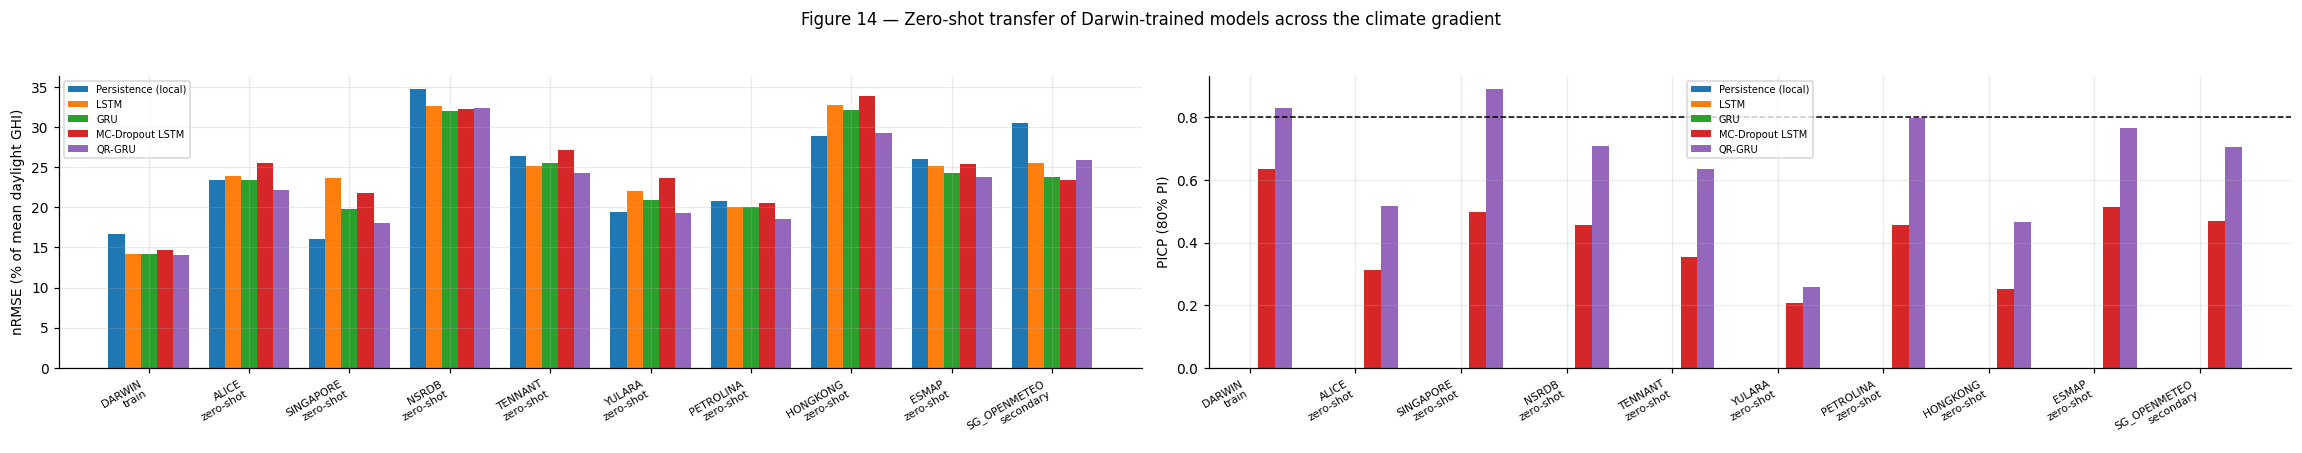


DOES TRANSFER LOSS TRACK DOMAIN SHIFT? (Spearman rank correlation across sites)
          model distance             outcome  n_sites  spearman_rho  p_value
            GRU    W1_kt transfer_penalty_pp        8         0.881    0.004
            GRU   W1_dkt transfer_penalty_pp        8         0.857    0.007
           LSTM    W1_kt transfer_penalty_pp        8         0.810    0.015
           LSTM   W1_dkt transfer_penalty_pp        8         0.786    0.021
MC-Dropout LSTM    W1_kt transfer_penalty_pp        8         0.905    0.002
MC-Dropout LSTM    W1_kt        PICP_deficit        8         0.738    0.037
MC-Dropout LSTM   W1_dkt transfer_penalty_pp        8         0.905    0.002
MC-Dropout LSTM   W1_dkt        PICP_deficit        8         0.476    0.233
         QR-GRU    W1_kt transfer_penalty_pp        8         0.905    0.002
         QR-GRU    W1_kt        PICP_deficit        8         0.548    0.160
         QR-GRU   W1_dkt transfer_penalty_pp        8         0.905    0

['ALICE',
 'ESMAP',
 'HONGKONG',
 'NSRDB',
 'PETROLINA',
 'SINGAPORE',
 'TENNANT',
 'YULARA']

In [ ]:
def run_cross_climate():
    sc = SCALERS[MODEL_SITE]
    rows = []
    for site, split in DATASETS.items():
        Xte, yte, mte = split["test"]
        pk = Xte[:, -1, ALL_FEATURES.index("kt")]
        base = evaluate("Persistence (local)", pk, None, None, yte, mte)
        if base:
            base.update(site=site, transfer="local baseline")
            rows.append(base)
        Xs = sc(Xte)
        for kind in MODEL_KINDS:
            if kind not in MODELS:
                continue
            if site == MODEL_SITE:
                p, Q, S = PREDS[kind][0], PREDS[kind][1], PREDS[kind][2]
            else:
                p, Q, S = predict(kind, MODELS[kind], Xs)
            r = evaluate(kind, p, Q, S, yte, mte)
            if r:
                r.update(site=site,
                         transfer="in-domain" if site == MODEL_SITE else "zero-shot")
                # does the Darwin-calibrated conformal widening TRANSFER?
                dlt = CONFORMAL.get(kind) if Q is not None else None
                if dlt is not None:
                    cs = mte["ghi_cs"].to_numpy(); yt = yte * cs
                    lo = np.clip((Q[:, I_LO] - dlt) * cs, 0, None)
                    hi = np.clip((Q[:, I_HI] + dlt) * cs, 0, None)
                    r["PICP_80_conformal"] = float(((yt >= lo) & (yt <= hi)).mean())
                    r["MIW_conformal_Wm2"] = float((hi - lo).mean())
                rows.append(r)
    return pd.DataFrame(rows)


CROSS = run_cross_climate()
print("\nCROSS-CLIMATE GENERALISATION (Objective 8) — "
      f"all models trained on {MODEL_SITE} only")
print("=" * 118)
print(CROSS[[c for c in ["site", "transfer", "model", "n", "nRMSE_%", "RMSE_Wm2", "CRPS_Wm2",
             "PICP_80", "PICP_80_conformal", "MIW_Wm2", "MIW_conformal_Wm2"] if c in CROSS]]
      .round(3).to_string(index=False))
save_table(CROSS, "results_cross_climate")

sites_plot = list(DATASETS)
fig, axes = plt.subplots(1, 2, figsize=(max(11.5, 1.5 * len(sites_plot) + 6), 3.9))
kinds_plot = ["Persistence (local)"] + [k for k in MODEL_KINDS if k in MODELS]
w = 0.8 / len(kinds_plot)
for i, kind in enumerate(kinds_plot):
    s = CROSS[CROSS.model == kind].set_index("site").reindex(sites_plot)
    off = (i - (len(kinds_plot) - 1) / 2) * w          # the initial pipeline hard-coded (i - 2): centred only for 5 bars
    axes[0].bar(np.arange(len(sites_plot)) + off, s["nRMSE_%"], w, label=kind)
    axes[1].bar(np.arange(len(sites_plot)) + off, s["PICP_80"], w, label=kind)
for ax, yl in ((axes[0], "nRMSE (% of mean daylight GHI)"), (axes[1], "PICP (80% PI)")):
    ax.set_xticks(range(len(sites_plot)))
    ax.set_xticklabels([f"{s}\n{'train' if s == MODEL_SITE else ('secondary' if s in SECONDARY_SITES else 'zero-shot')}"
                        for s in sites_plot], fontsize=7, rotation=30, ha="right")
    ax.set_ylabel(yl); ax.legend(fontsize=6.5)
axes[1].axhline(.8, color="k", ls="--", lw=1)
fig.suptitle("Figure 14 — Zero-shot transfer of Darwin-trained models across the climate gradient",
             y=1.04)
savefig(fig, "fig14_cross_climate"); plt.show()

# ---- relate transfer loss and calibration loss to measured domain shift ------------------
from scipy.stats import spearmanr
_rows = []
for site in [s_ for s_ in DATASETS if s_ != MODEL_SITE and s_ not in SECONDARY_SITES
             and not SITES[s_].get("short_record")]:
    c = CROSS[CROSS.site == site].set_index("model")
    if "Persistence (local)" not in c.index or site not in set(DOMAIN_SHIFT.site):
        continue
    ds_ = DOMAIN_SHIFT.set_index("site").loc[site]
    for kind in [k for k in MODEL_KINDS if k in c.index]:
        _rows.append({"site": site, "model": kind,
                      "W1_kt": ds_["W1_kt_vs_darwin_train"], "W1_dkt": ds_["W1_dkt_vs_darwin_train"],
                      "transfer_penalty_pp": c.loc[kind, "nRMSE_%"] - c.loc["Persistence (local)", "nRMSE_%"],
                      "PICP_deficit": (0.80 - c.loc[kind, "PICP_80"]) if np.isfinite(c.loc[kind, "PICP_80"]) else np.nan})
SHIFT_LINK = pd.DataFrame(_rows)
if len(SHIFT_LINK) >= 4:
    print("\nDOES TRANSFER LOSS TRACK DOMAIN SHIFT? (Spearman rank correlation across sites)")
    out = []
    for kind, g in SHIFT_LINK.groupby("model"):
        for dist in ("W1_kt", "W1_dkt"):
            for y_ in ("transfer_penalty_pp", "PICP_deficit"):
                gg = g[[dist, y_]].dropna()
                if len(gg) >= 4:
                    rho, p = spearmanr(gg[dist], gg[y_])
                    out.append({"model": kind, "distance": dist, "outcome": y_, "n_sites": len(gg),
                                "spearman_rho": rho, "p_value": p})
    SHIFT_CORR = pd.DataFrame(out).round(3)
    print(SHIFT_CORR.to_string(index=False))
    print(textwrap.fill(
        "With only a handful of zero-shot sites these correlations are descriptive; p-values are shown "
        "for completeness, not as confirmatory tests. The PICP_80_conformal column shows whether the "
        "Darwin-calibrated widening restores coverage elsewhere — if it does not, calibration is "
        "site-specific and must be re-estimated before any transfer is used operationally.", 100))
    save_table(SHIFT_CORR, "results_shift_vs_transfer")
save_table(SHIFT_LINK, "results_shift_link")
_zs = CROSS[(CROSS.transfer == "zero-shot") & ~CROSS.site.isin(SECONDARY_SITES)]
for kind in [k for k in MODEL_KINDS if k in PROBABILISTIC]:
    z = _zs[_zs.model == kind]
    if len(z):
        register(f"cross.{kind}.zero_shot_PICP80_range", [round(z.PICP_80.min(), 3), round(z.PICP_80.max(), 3)])
        if "PICP_80_conformal" in z:
            register(f"cross.{kind}.zero_shot_PICP80_conformal_range",
                     [round(z.PICP_80_conformal.min(), 3), round(z.PICP_80_conformal.max(), 3)])
register("cross.sites", sorted(set(_zs.site)))

### **Research Stage#13.6 Which Inputs Do the Models Rely On? (Permutation Importance)**

[ 8079.0s |   2960MB]  ok checkpoint hit  'results_permutation_importance_v7_8be37a7834_EXT_sample_EXT_L24H1'  (64 rows)

PERMUTATION FEATURE IMPORTANCE (mean % RMSE increase when shuffled, all models)
feature
kt                111.24
cos_zenith         12.64
kt_roll3_mean      11.61
hour_sin            9.94
kt_lag3             9.70
ghi_cs_norm         6.03
kt_lag24            5.71
hour_cos            5.35
kt_lag1             3.67
kt_lag2             3.57
kt_roll24_std       3.48
kt_roll24_mean      2.61
kt_roll3_std        2.52
doy_sin             1.93
doy_cos             1.32
is_wet              1.09

PER-MODEL PERMUTATION IMPORTANCE (% RMSE change when the feature is shuffled)
model              GRU    LSTM  MC-Dropout LSTM  QR-GRU
feature                                                
cos_zenith       26.64    9.75             2.19   11.96
doy_cos           1.62    1.64             1.64    0.37
doy_sin           2.16    3.54             0.59    1.42
ghi_cs_norm       4.48    6.40 

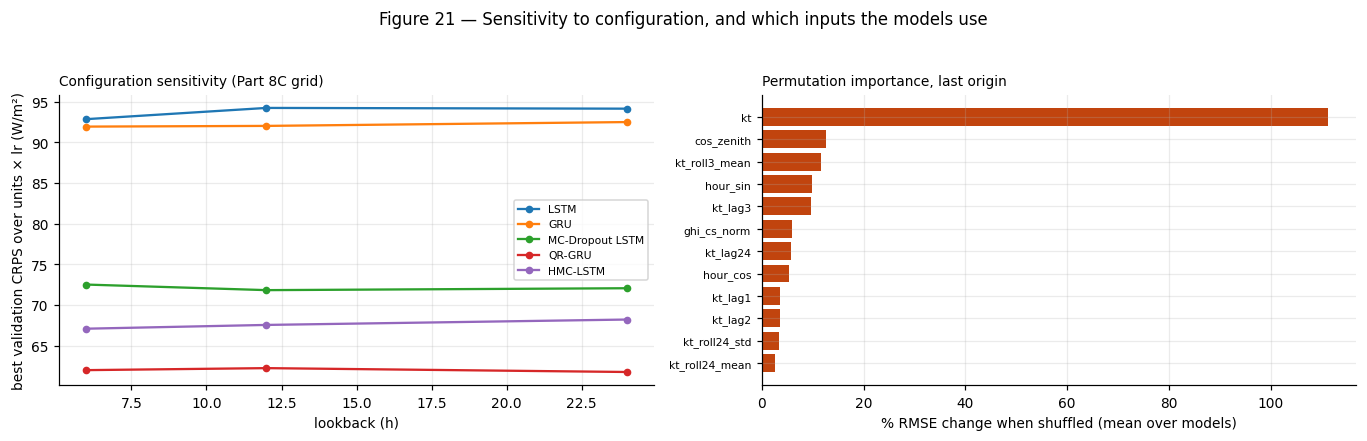

In [ ]:
# seed replication, significance testing and the horizon sweep moved to Part R, where they run
# across rolling origins with HAC-corrected tests and block-bootstrap intervals. Hyper-parameter
# sensitivity is read from the Part 8C grid (no extra training). This cell keeps permutation
# importance of the last-origin models.
class EXT:
    PERM_REPEATS = 3


# ---------------- 5. permutation feature importance ---------------------------
def permutation_importance():
    sp, sc = DATASETS[MODEL_SITE], SCALERS[MODEL_SITE]
    Xte, yte, mte = sp["test"]
    cs = mte["ghi_cs"].to_numpy()
    rng = np.random.default_rng(CFG.SEED)
    rows = []
    for kind in [k for k in MODEL_KINDS if k in MODELS]:
        base_p, _, _ = predict(kind, MODELS[kind], sc(Xte))
        base = float(np.sqrt((((np.clip(base_p * cs, 0, None)) - yte * cs) ** 2).mean()))
        for j, feat in enumerate(ALL_FEATURES):
            hits = []
            for _ in range(EXT.PERM_REPEATS):
                Xp = Xte.copy()
                Xp[:, :, j] = Xp[rng.permutation(len(Xp)), :, j]
                p, _, _ = predict(kind, MODELS[kind], sc(Xp))
                hits.append(float(np.sqrt((((np.clip(p * cs, 0, None)) - yte * cs) ** 2).mean())))
            rows.append({"model": kind, "feature": feat, "base_RMSE": base,
                         "perm_RMSE": float(np.mean(hits)),
                         "delta_RMSE": float(np.mean(hits) - base),
                         "delta_%": float(100 * (np.mean(hits) - base) / base)})
    return pd.DataFrame(rows)


PERM = checkpoint(ck("results_permutation_importance"), permutation_importance)
top = (PERM.groupby("feature")["delta_%"].mean().sort_values(ascending=False))
print("\nPERMUTATION FEATURE IMPORTANCE (mean % RMSE increase when shuffled, all models)")
print(top.round(2).to_string())


PERM_BY_MODEL = PERM.pivot_table(index="feature", columns="model", values="delta_%")
print("\nPER-MODEL PERMUTATION IMPORTANCE (% RMSE change when the feature is shuffled)")
print(PERM_BY_MODEL.round(2).to_string())
_neg = top[top < -1.0]
if len(_neg):
    print(textwrap.fill(
        f"Features whose shuffling IMPROVES RMSE on average: {', '.join(f'{k} ({v:+.1f}%)' for k, v in _neg.items())}. "
        "A negative importance means the fitted model relies on a relationship that does not hold in "
        "the test period — for calendar features with little more than one year of training data, a "
        "day-of-year alias of the particular training year. Part R3 arm A removes the calendar features "
        "to test this directly.", 100))
register("importance.top3", top.head(3).round(2).to_dict())
register("importance.negative", _neg.round(2).to_dict())

# ---------------- Figure 21 : configuration sensitivity + importance ---------------------
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
ax = axes[0]
for kind in TUNING.model.unique():
    t = TUNING[TUNING.model == kind].groupby("lookback")["val_CRPS_q_Wm2"].min()
    ax.plot(t.index, t.values, "-o", ms=4, label=kind)
ax.set_xlabel("lookback (h)"); ax.set_ylabel("best validation CRPS over units × lr (W/m²)")
ax.legend(fontsize=7); ax.set_title("Configuration sensitivity (Part 8C grid)", fontsize=9, loc="left")
ax = axes[1]
tt = top.head(12)[::-1]
ax.barh(range(len(tt)), tt.to_numpy(), color=np.where(tt.to_numpy() < 0, "#8d99ae", "#c1440e"))
ax.set_yticks(range(len(tt))); ax.set_yticklabels(tt.index, fontsize=7)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("% RMSE change when shuffled (mean over models)")
ax.set_title("Permutation importance, last origin", fontsize=9, loc="left")
fig.suptitle("Figure 21 — Sensitivity to configuration, and which inputs the models use", y=1.04)
savefig(fig, "fig21_robustness"); plt.show()

### **Research Stage#13.7 Decision Support (Objective 4): Is The Interval Honest When It Claims Precision?**

Test hours are grouped into quintiles of predicted interval width. The threshold **X** is the upper edge of the contiguous run of bands, from the narrowest, whose coverage meets nominal. Both conformal and raw intervals are shown. A missing X is a **result**, not an error.


RAW intervals (for comparison) — QR-GRU
band   n  MIW_lo  MIW_hi  MIW_mean  PICP    MAE    RMSE  ramp_rate                             dispatch_rule intervals
  Q1 367   9.922  66.390    43.008 0.752 12.847  18.018      0.000   COMMIT reserve — coverage below nominal       raw
  Q2 366  66.426 109.292    88.142 0.820 22.943  35.631      0.079 DEFER backup — interval narrow AND honest       raw
  Q3 367 109.416 152.873   130.538 0.850 31.966  50.483      0.120            HOLD reserve — honest but wide       raw
  Q4 366 153.094 250.625   194.777 0.863 49.783  74.693      0.038            HOLD reserve — honest but wide       raw
  Q5 367 251.130 697.059   363.638 0.866 98.581 131.307      0.071            HOLD reserve — honest but wide       raw

DECISION-SUPPORT TABLE (Objective 4) — CONFORMAL intervals, QR-GRU, DARWIN, t+1h, nominal 80% interval
band   n  MIW_lo  MIW_hi  MIW_mean  PICP    MAE    RMSE  ramp_rate                             dispatch_rule
  Q1 367   9.816  64.551    41.9

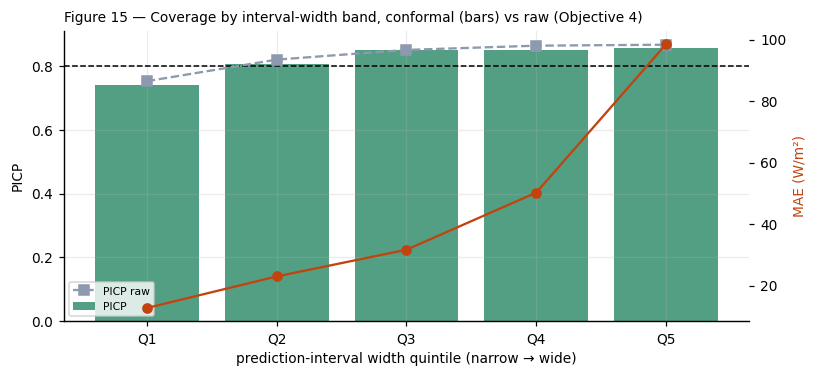

In [ ]:
def decision_support(kind="QR-GRU", delta=0.0):
    """`delta` is the conformal widening (k_t units) learned on the calibration split.
    an intermediate pipeline built the table from RAW intervals only, so its conclusion ('no band is honest') described
    an interval nobody should deploy; the conformal table is now the headline and raw is shown
    alongside for comparison."""
    if kind not in PREDS:
        return None
    point, Q, S, yte, mte = PREDS[kind]
    cs = mte["ghi_cs"].to_numpy()
    lo = np.clip((Q[:, CFG.QUANTILES.index(CFG.PI_LOW)] - delta) * cs, 0, None)
    hi = np.clip((Q[:, CFG.QUANTILES.index(CFG.PI_HIGH)] + delta) * cs, 0, None)
    yt = yte * cs
    yh = np.clip(point * cs, 0, None)
    miw = hi - lo

    codes = pd.qcut(miw, 5, labels=False, duplicates="drop")
    band = pd.Series(codes).map(lambda i: f"Q{int(i)+1}" if pd.notna(i) else "Q1")
    df = pd.DataFrame({"band": band, "miw": miw, "cov": (yt >= lo) & (yt <= hi),
                       "abserr": np.abs(yh - yt), "sqerr": (yh - yt) ** 2,
                       "ramp": mte["is_ramp"].to_numpy().astype(bool)})
    g = df.groupby("band", observed=True).agg(
        n=("miw", "size"), MIW_lo=("miw", "min"), MIW_hi=("miw", "max"),
        MIW_mean=("miw", "mean"), PICP=("cov", "mean"),
        MAE=("abserr", "mean"), RMSE=("sqerr", lambda s: np.sqrt(s.mean())),
        ramp_rate=("ramp", "mean")).reset_index()
    g["dispatch_rule"] = np.where(
        (g.PICP >= CFG.PI_HIGH - CFG.PI_LOW) & (g.MIW_mean <= np.median(miw)),
        "DEFER backup — interval narrow AND honest",
        np.where(g.PICP >= CFG.PI_HIGH - CFG.PI_LOW,
                 "HOLD reserve — honest but wide",
                 "COMMIT reserve — coverage below nominal"))
    return g, miw, yt, lo, hi


_ds_kind = "QR-GRU" if "QR-GRU" in PREDS else "MC-Dropout LSTM"
DECISIONS = {}
for _tag, _dl in (("raw", 0.0), ("conformal", CONFORMAL.get(_ds_kind) or 0.0)):
    _r = decision_support(_ds_kind, _dl)
    if _r:
        DECISIONS[_tag] = _r[0].assign(intervals=_tag)
ds = decision_support(_ds_kind, CONFORMAL.get(_ds_kind) or 0.0)
if "raw" in DECISIONS:
    print(f"\nRAW intervals (for comparison) — {_ds_kind}")
    print(DECISIONS["raw"].round(3).to_string(index=False))
    save_table(DECISIONS["raw"], "results_decision_support_raw")
if ds:
    DECISION, miw, yt, lo, hi = ds
    print("\nDECISION-SUPPORT TABLE (Objective 4) — CONFORMAL intervals, "
          f"{_ds_kind}, {MODEL_SITE}, t+{CFG.HORIZON}h, nominal 80% interval")
    print("=" * 118)
    print(DECISION.round(3).to_string(index=False))
    # The rule must describe a CONTIGUOUS run from the narrowest band upward.
    # Taking the widest passing band would assert reliability across intermediate
    # bands that failed, which is exactly the kind of overclaim the objective warns about.
    nominal = CFG.PI_HIGH - CFG.PI_LOW
    run = []
    for _, r in DECISION.iterrows():
        if r.PICP >= nominal:
            run.append(r)
        else:
            break
    if run:
        run = pd.DataFrame(run)
        thr = run.MIW_hi.max()
        register("decision.threshold_X_Wm2", round(float(thr), 1),
                 f"conformal {_ds_kind}, contiguous bands from narrow end at >= nominal coverage")
        register("decision.bands_passing", int(len(run)))
        print(f"\n  OPERATING RULE: while the forecast 80% interval width is <= "
              f"{thr:,.0f} W/m² ({len(run)} of {len(DECISION)} width bands, "
              f"{int(run.n.sum()):,} test hours), empirical coverage holds at or above "
              f"nominal 80% (min {run.PICP.min():.3f}) and mean absolute error stays within "
              f"{run.MAE.min():,.0f}-{run.MAE.max():,.0f} W/m². Backup generation can be "
              f"deferred within that band at t+{CFG.HORIZON}h.")
        fails = DECISION[DECISION.PICP < nominal]
        if len(fails):
            print(f"  CAVEAT: coverage falls below nominal in band(s) "
                  f"{', '.join(fails.band)} (PICP {fails.PICP.min():.3f}); the model is "
                  f"overconfident at those widths and reserve should be committed.")
    else:
        print("\n  Even after conformal recalibration no MIW band reaches nominal coverage from the "
              "narrow end: a single additive correction cannot repair coverage that fails where the "
              "model is most confident. Objective 4's threshold X is therefore NOT defined at this "
              "site/horizon — a reportable negative result (see Part R1 for its stability across folds).")
        register("decision.threshold_X_Wm2", None, "no contiguous band at nominal coverage (conformal)")
    save_table(DECISION, "results_decision_support")

    fig, ax = plt.subplots(figsize=(7.5, 3.5))
    ax.bar(DECISION.band, DECISION.PICP, color="#1a7f5a", alpha=.75, label="PICP")
    ax.axhline(.8, color="k", ls="--", lw=1); ax.set_ylabel("PICP")
    ax2 = ax.twinx(); ax2.grid(False)
    ax2.plot(DECISION.band, DECISION.MAE, "o-", color="#c1440e", label="MAE")
    ax2.set_ylabel("MAE (W/m²)", color="#c1440e")
    ax.set_xlabel("prediction-interval width quintile (narrow → wide)")
    if "raw" in DECISIONS:
        ax.plot(DECISIONS["raw"].band, DECISIONS["raw"].PICP, "s--", color="#8d99ae", label="PICP raw")
    ax.legend(fontsize=7, loc="lower left")
    ax.set_title("Figure 15 — Coverage by interval-width band, conformal (bars) vs raw (Objective 4)",
                 loc="left", fontsize=9)
    savefig(fig, "fig15_decision"); plt.show()

### **Research Stage#13.8 Reserve Sizing at Equal Reliability**

The probabilistic reserve (upper interval minus point forecast) is compared with a deterministic fixed margin **at the same shortfall-exceedance rate**, interpolated along the deterministic cost–risk frontier.

RESERVE SIZING — DARWIN, t+1h, model: QR-GRU
                              strategy  mean_reserve_Wm2  exceedance_%  unserved_Wm2_per_h
Deterministic + fixed margin (cal q50)             0.708        49.045              16.463
Deterministic + fixed margin (cal q75)            34.358        12.984               7.157
Deterministic + fixed margin (cal q80)            46.736         9.820               5.750
Deterministic + fixed margin (cal q90)            99.124         3.819               2.604
Deterministic + fixed margin (cal q95)           157.619         1.800               1.073
Deterministic + fixed margin (cal q97)           211.798         0.764               0.478
Deterministic + fixed margin (cal q99)           254.625         0.273               0.237
        Probabilistic q90 margin (raw)            64.010         7.147               1.173
  Probabilistic q90 margin (conformal)            62.912         7.801               1.249


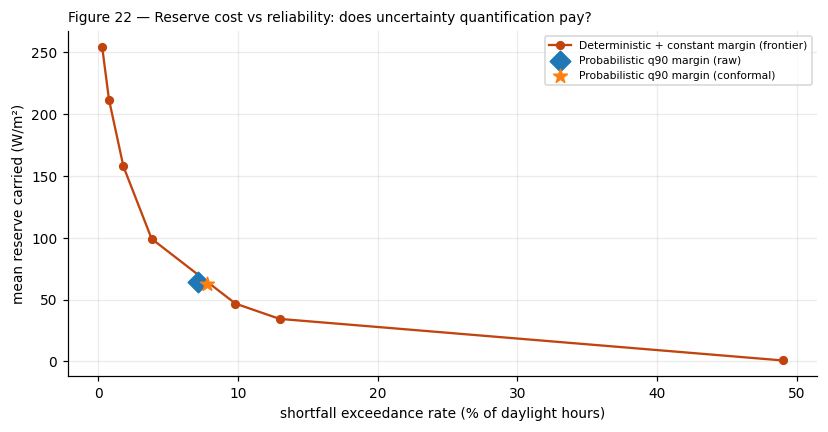


  Probabilistic q90 margin (raw): at the SAME exceedance rate (7.1%), the deterministic frontier carries 70.1 W/m²; this strategy carries 64.0 W/m² (-8.6%). Negative = probabilistic cheaper.

  Probabilistic q90 margin (conformal): at the SAME exceedance rate (7.8%), the deterministic frontier carries 64.4 W/m²; this strategy carries 62.9 W/m² (-2.3%). Negative = probabilistic cheaper.
A point lying below and to the left of the deterministic frontier means the probabilistic forecast
delivers the same reliability for less carried reserve, which is the operational argument for
uncertainty quantification stated in physical units rather than in scoring rules. A point above the
frontier means the opposite, and would be an equally reportable negative finding.


In [ ]:
def reserve_analysis(kind=None):
    kind = kind or best_prob
    if kind not in PREDS or kind not in MODELS:
        return None
    sp, sc = DATASETS[MODEL_SITE], SCALERS[MODEL_SITE]

    # deterministic margins calibrated on the CALIBRATION split — the same data the conformal
    # correction uses, so both strategies are fitted on identical, test-disjoint information
    Xv, yv, mv = sp["cal"]
    pv, _, _ = predict(kind, MODELS[kind], sc(Xv))
    csv_ = mv["ghi_cs"].to_numpy()
    shortfall_val = np.clip(yv * csv_ - np.clip(pv * csv_, 0, None), 0, None)

    point, Q, S, yte, mte = PREDS[kind]
    cs = mte["ghi_cs"].to_numpy()
    yhat = np.clip(point * cs, 0, None)
    ytrue = yte * cs
    shortfall = np.clip(ytrue - yhat, 0, None)

    rows = []
    for q in (0.50, 0.75, 0.80, 0.90, 0.95, 0.975, 0.99):
        margin = float(np.quantile(shortfall_val, q))
        rows.append({"strategy": f"Deterministic + fixed margin (cal q{int(q*100)})",
                     "mean_reserve_Wm2": margin,
                     "exceedance_%": float(100 * (shortfall > margin).mean()),
                     "unserved_Wm2_per_h": float(np.clip(shortfall - margin, 0, None).mean())})

    delta = CONFORMAL.get(kind) or 0.0
    for tag, dd in (("raw", 0.0), ("conformal", delta)):
        upper = np.clip((Q[:, I_HI] + dd) * cs, 0, None)
        margin = np.clip(upper - yhat, 0, None)
        rows.append({"strategy": f"Probabilistic q90 margin ({tag})",
                     "mean_reserve_Wm2": float(margin.mean()),
                     "exceedance_%": float(100 * (shortfall > margin).mean()),
                     "unserved_Wm2_per_h": float(np.clip(shortfall - margin, 0, None).mean())})
    return pd.DataFrame(rows).round(3), kind


ra = reserve_analysis()
if ra:
    RESERVE, res_kind = ra
    print(f"RESERVE SIZING — {MODEL_SITE}, t+{CFG.HORIZON}h, model: {res_kind}")
    print("=" * 110)
    print(RESERVE.to_string(index=False))
    save_table(RESERVE, "results_reserve_sizing")

    det = RESERVE[RESERVE.strategy.str.startswith("Deterministic")]
    prob = RESERVE[RESERVE.strategy.str.startswith("Probabilistic")]

    fig, ax = plt.subplots(figsize=(7.6, 4.0))
    ax.plot(det["exceedance_%"], det["mean_reserve_Wm2"], "-o", ms=5, color="#c1440e",
            label="Deterministic + constant margin (frontier)")
    for _, r in prob.iterrows():
        ax.scatter(r["exceedance_%"], r["mean_reserve_Wm2"], s=90, zorder=5,
                   marker="*" if "conformal" in r.strategy else "D",
                   label=r["strategy"])
    ax.set_xlabel("shortfall exceedance rate (% of daylight hours)")
    ax.set_ylabel("mean reserve carried (W/m²)")
    ax.legend(fontsize=7)
    ax.set_title("Figure 22 — Reserve cost vs reliability: does uncertainty quantification pay?",
                 fontsize=9, loc="left")
    savefig(fig, "fig22_reserve"); plt.show()

    # compare at EQUAL reliability by interpolating the deterministic frontier at the
    # probabilistic strategy's exceedance rate (an intermediate pipeline took the nearest frontier point, which can sit
    # several percentage points away).
    fr = det.sort_values("exceedance_%")
    for _, r in prob.iterrows():
        x = r["exceedance_%"]
        if fr["exceedance_%"].min() <= x <= fr["exceedance_%"].max():
            base_res = float(np.interp(x, fr["exceedance_%"], fr["mean_reserve_Wm2"]))
            diff = 100 * (r["mean_reserve_Wm2"] - base_res) / base_res if base_res > 1e-6 else np.nan
            print(f"\n  {r['strategy']}: at the SAME exceedance rate ({x:.1f}%), the deterministic "
                  f"frontier carries {base_res:,.1f} W/m²; this strategy carries "
                  f"{r['mean_reserve_Wm2']:,.1f} W/m² ({diff:+.1f}%). Negative = probabilistic cheaper.")
            register(f"reserve.{r['strategy'].split('(')[1].rstrip(')')}_vs_frontier_pct", round(float(diff), 1))
        else:
            print(f"\n  {r['strategy']}: exceedance {x:.1f}% lies outside the deterministic frontier range; "
                  "no equal-reliability comparison possible.")
    print(textwrap.fill(
        "A point lying below and to the left of the deterministic frontier means the probabilistic "
        "forecast delivers the same reliability for less carried reserve, which is the operational "
        "argument for uncertainty quantification stated in physical units rather than in scoring "
        "rules. A point above the frontier means the opposite, and would be an equally reportable "
        "negative finding.", 100))

# **PART K · Robust Model Evaluation and Statistical Significance Testing**

> *Navigation header added for the VIVA. It covers Stage 14 below. No original cell was changed.*

---
# **Research Stage#14 — Robust Evaluation: The Evidence The Research Question Is Answered From**

**Trigger.** Stages 12–13 rest on one test block and one seed. Two questions follow:

1. Is a ranking from one block a property of the models, or of the block?
2. Is a significance test valid when the loss differences are serially correlated?

**Design.**

| Part | What it does |
|---|---|
| R1 | 4 expanding-window test blocks × 5 seeds, with a conformal correction per fold from its own calibration split |
| R2 | Seed-averaged hourly losses; skill with moving-block bootstrap CIs; Diebold–Mariano with Newey–West variance and Holm correction; rank stability |
| R3 | A **valid** seasonal-conditioning test |
| R4 | Horizon sweep against the **best** naive reference |
| R5 | Robustness: interpolated targets, seasonal and ramp subgroups with CIs, meteorology, decision threshold and reserve across folds |

**A difference is reported as a finding only if its 95% CI excludes zero and its Holm-adjusted p < 0.05.**

In [ ]:
# ============================== R1 — rolling-origin comparison ==============================
R_KINDS = MODEL_KINDS + EXTENSION_KINDS
TAUS = np.array(CFG.QUANTILES)
_XR, _yR, _mR = build_supervised(FEAT[FEAT.site == MODEL_SITE], ALL_FEATURES)
FOLDS = rolling_origin_splits(_XR, _yR, _mR)
_JKT = ALL_FEATURES.index("kt")

fold_rows = []
for sp in FOLDS:
    te = sp["test"][2]
    fold_rows.append({"fold": sp["fold"], "n_train": len(sp["train"][1]), "n_val": len(sp["val"][1]),
                      "n_cal": len(sp["cal"][1]), "n_test": len(sp["test"][1]),
                      "test_from": te.ts.min(), "test_to": te.ts.max(),
                      "test_wet_%": 100 * te.is_wet.mean(),
                      "test_interpolated_%": 100 * te.kt_imputed.mean() if "kt_imputed" in te else np.nan})
FOLD_TABLE = pd.DataFrame(fold_rows)
print(f"ROLLING-ORIGIN DESIGN — {MODEL_SITE}, {len(FOLDS)} expanding-window folds")
print("=" * 118)
print(FOLD_TABLE.round(1).to_string(index=False))
save_table(FOLD_TABLE.astype({"test_from": str, "test_to": str}), "r_fold_table")
register("r.folds", len(FOLDS)); register("r.seeds", list(CFG.SEEDS))
register("r.test_windows_total", int(FOLD_TABLE.n_test.sum()))
register("r.test_period", f"{FOLD_TABLE.test_from.min()} .. {FOLD_TABLE.test_to.max()}")


def crps_q_vec(Qw, yt, taus=TAUS):
    """Per-sample CRPS from a quantile grid (2 x integral of pinball over tau)."""
    pl = np.stack([pinball(yt, Qw[:, j], t) for j, t in enumerate(taus)], axis=1)
    return 2.0 * _trapz(pl, taus, axis=1)


def cqr_delta(Qc, yc, alpha=None):
    alpha = 1.0 - (CFG.PI_HIGH - CFG.PI_LOW) if alpha is None else alpha
    E = np.maximum(Qc[:, I_LO] - yc, yc - Qc[:, I_HI])
    n = len(E)
    k = min(max(int(np.ceil((n + 1) * (1 - alpha))), 1), n)
    return float(np.sort(E)[k - 1])


def _pred_rows(sp, name, seed, p, Q=None, S=None, delta=np.nan):
    Xte, yte, mte = sp["test"]
    cs = mte["ghi_cs"].to_numpy()
    yt, yh = yte * cs, np.clip(p * cs, 0, None)
    out = pd.DataFrame({"ts": mte.ts.to_numpy(), "fold": sp["fold"], "model": name, "seed": seed,
                        "y": yt, "yhat": yh, "cs": cs, "is_wet": mte.is_wet.to_numpy(),
                        "is_ramp": mte.is_ramp.to_numpy().astype(bool),
                        "kt_imputed": mte.kt_imputed.to_numpy() if "kt_imputed" in mte else False,
                        "delta_kt": delta})
    out["se"] = (yh - yt) ** 2
    if Q is None:
        out["crps"] = np.abs(yh - yt)
        return out
    Qw = np.clip(Q * cs[:, None], 0, None)
    for j, t in enumerate(CFG.QUANTILES):
        out[f"q{int(round(t * 100)):02d}"] = Qw[:, j]
    out["crps_q"] = crps_q_vec(Qw, yt)
    out["crps"] = (crps_ensemble(np.clip(S * cs[:, None], 0, None), yt) if S is not None else out["crps_q"])
    if np.isfinite(delta):
        out["lo_c"] = np.clip((Q[:, I_LO] - delta) * cs, 0, None)
        out["hi_c"] = np.clip((Q[:, I_HI] + delta) * cs, 0, None)
    return out


def _reserve_rows(sp, kind, m, sc, seed, p_te, Q_te, delta):
    """Reserve cost vs exceedance for this fold/seed (Objective 4, physical units)."""
    Xc, yc, mc = sp["cal"]
    pc, _, _ = predict(kind, m, sc(Xc), seed=seed)
    csc = mc["ghi_cs"].to_numpy()
    short_c = np.clip(yc * csc - np.clip(pc * csc, 0, None), 0, None)
    Xte, yte, mte = sp["test"]
    cs = mte["ghi_cs"].to_numpy()
    yh = np.clip(p_te * cs, 0, None)
    short = np.clip(yte * cs - yh, 0, None)
    rows = []
    for q in (0.50, 0.70, 0.80, 0.85, 0.90, 0.95, 0.975, 0.99):
        mg = float(np.quantile(short_c, q))
        rows.append({"strategy": f"det_q{q}", "reserve": mg, "exceed_%": 100 * float((short > mg).mean())})
    for tag, dd in (("prob_raw", 0.0), ("prob_conformal", delta)):
        up = np.clip((Q_te[:, I_HI] + dd) * cs, 0, None)
        mg = np.clip(up - yh, 0, None)
        rows.append({"strategy": tag, "reserve": float(mg.mean()), "exceed_%": 100 * float((short > mg).mean())})
    return rows


def _r1_unit(u):
    sp = FOLDS[int(u["fold"]) - 1]
    kind, seed = u["model"], int(u["seed"])
    if kind.startswith("naive:"):
        Xte, yte, mte = sp["test"]
        nm = kind.split(":", 1)[1]
        if nm == "Persistence":
            p = Xte[:, -1, _JKT]
        elif nm == "Climatology":
            p = climatology_lookup(sp)(mte)
        else:
            ref = FEAT[FEAT.site == MODEL_SITE].drop_duplicates("ts").set_index("ts")["kt"]
            p = ref.reindex(mte.ts - pd.Timedelta(hours=24)).to_numpy()
            p = np.where(np.isfinite(p), p, Xte[:, -1, _JKT])
        return _pred_rows(sp, nm, -1, p).assign(rtype="pred").to_dict("records")
    sc = Standardiser().fit(sp["train"][0])
    m, hist = fit_model(kind, sp, sc, tag=None, seed=seed)
    p, Q, S = predict(kind, m, sc(sp["test"][0]), seed=seed)
    delta = np.nan
    rows = []
    if Q is not None:
        _, Qc, _ = predict(kind, m, sc(sp["cal"][0]), seed=seed)
        delta = cqr_delta(Qc, sp["cal"][1])
        rows = [dict(r, rtype="reserve") for r in _reserve_rows(sp, kind, m, sc, seed, p, Q, delta)]
    pr = _pred_rows(sp, kind, seed, p, Q, S, delta).assign(rtype="pred", epochs=len(hist.history["loss"]))
    del m
    tf.keras.backend.clear_session(); gc.collect()
    return pr.to_dict("records") + rows


_units = ([{"fold": sp["fold"], "model": f"naive:{nm}", "seed": -1}
           for sp in FOLDS for nm in ("Persistence", "Climatology", "Seasonal-naive")] +
          [{"fold": sp["fold"], "model": k, "seed": s} for sp in FOLDS for k in R_KINDS for s in CFG.SEEDS])
R1_RAW = cached_units(ck("r1_rolling_origin"), _units, _r1_unit, ["fold", "model", "seed"])
R1_RAW["model"] = R1_RAW["model"].str.replace("naive:", "", regex=False)
R1_RAW["fold"] = R1_RAW["fold"].astype(int); R1_RAW["seed"] = R1_RAW["seed"].astype(int)
R1 = R1_RAW[R1_RAW.rtype == "pred"].copy()
R1_RES = R1_RAW[R1_RAW.rtype == "reserve"][["fold", "model", "seed", "strategy", "reserve", "exceed_%"]].copy()
NAIVES = ["Persistence", "Climatology", "Seasonal-naive"]

ROLLING-ORIGIN DESIGN — DARWIN, 4 expanding-window folds
 fold  n_train  n_val  n_cal  n_test           test_from             test_to  test_wet_%  test_interpolated_%
    1     5175   1077   1077    1221 2024-04-08 13:00:00 2024-07-28 11:00:00        20.3                  3.0
    2     6036   1257   1257    1222 2024-07-28 12:00:00 2025-02-15 12:00:00        13.7                  0.9
    3     6898   1437   1437    1222 2025-02-15 13:00:00 2025-06-01 12:00:00        71.6                  0.3
    4     7762   1616   1616    1222 2025-06-01 13:00:00 2025-09-20 13:00:00         0.0                  4.3
[ 8309.0s |   3023MB]  ok cache complete 'r1_rolling_origin_v7_8be37a7834_EXT_sample_EXT_L24H1' (137,436 rows)


In [ ]:
# ============================== R2 — are the differences real? ==============================
COV = CFG.PI_HIGH - CFG.PI_LOW


def _run_metrics(g):
    r = {"n": len(g), "RMSE": float(np.sqrt(g.se.mean())), "MAE": float(np.abs(g.yhat - g.y).mean()),
         "CRPS": float(g.crps.mean())}
    if "crps_q" in g and g["crps_q"].notna().any():
        r["CRPS_q"] = float(g.crps_q.mean())
        lo, hi = g[f"q{int(CFG.PI_LOW*100):02d}"], g[f"q{int(CFG.PI_HIGH*100):02d}"]
        r["PICP_raw"] = float(((g.y >= lo) & (g.y <= hi)).mean())
        r["MIW_raw"] = float((hi - lo).mean())
        r["PICP90_raw"] = float(((g.y >= g.q05) & (g.y <= g.q95)).mean())
        if "lo_c" in g and g["lo_c"].notna().any():
            r["PICP_conf"] = float(((g.y >= g.lo_c) & (g.y <= g.hi_c)).mean())
            r["MIW_conf"] = float((g.hi_c - g.lo_c).mean())
            a = 1 - COV
            w = (g.hi_c - g.lo_c) + 2 / a * np.clip(g.lo_c - g.y, 0, None) + 2 / a * np.clip(g.y - g.hi_c, 0, None)
            r["Winkler_conf"] = float(w.mean())
        a = 1 - COV
        w = (hi - lo) + 2 / a * np.clip(lo - g.y, 0, None) + 2 / a * np.clip(g.y - hi, 0, None)
        r["Winkler_raw"] = float(w.mean())
    else:
        r["CRPS_q"] = r["MAE"]
    return pd.Series(r)


RUNS = pd.DataFrame([{"model": k[0], "fold": k[1], "seed": k[2], **_run_metrics(g).to_dict()}
                     for k, g in R1.groupby(["model", "fold", "seed"])])
_pers = RUNS[RUNS.model == "Persistence"].set_index("fold")["RMSE"]
RUNS["skill_%"] = 100 * (1 - RUNS.RMSE / RUNS.fold.map(_pers))
save_table(RUNS, "r_runs_fold_seed")

# ---- seed-averaged per-hour losses (the unit of inference) ------------------------------------
def seed_avg(df, col):
    return df.groupby(["model", "fold", "ts"])[col].mean().unstack("model")


SE = seed_avg(R1, "se")
CRPSW = seed_avg(R1, "crps")
FOLD_ID = SE.index.get_level_values("fold").to_numpy()
models_eval = [m for m in R_KINDS + NAIVES if m in SE.columns]


def _skill_ci(model, ref="Persistence", L=SE):
    a, b = L[model].to_numpy(), L[ref].to_numpy()
    ok = np.isfinite(a) & np.isfinite(b)
    a, b, gr = a[ok], b[ok], FOLD_ID[ok]
    f = (lambda idx: 100 * (1 - np.sqrt(a[idx].mean()) / np.sqrt(b[idx].mean()))) if L is SE else \
        (lambda idx: 100 * (1 - a[idx].mean() / b[idx].mean()))
    return f(np.arange(len(a))), *bootstrap_ci(f, len(a), groups=gr, seed=sum(map(ord, model)))


rows = []
for m in models_eval:
    r = RUNS[RUNS.model == m]
    sk, lo, hi = _skill_ci(m) if m != "Persistence" else (0.0, 0.0, 0.0)
    ck_, clo, chi = _skill_ci(m, L=CRPSW) if m != "Persistence" else (0.0, 0.0, 0.0)
    seed_sd = r.groupby("fold")["RMSE"].std().mean() if r.seed.nunique() > 1 else np.nan
    rows.append({"model": m,
                 "family": ("naive" if m in NAIVES else "probabilistic" if m in PROBABILISTIC else "deterministic")
                           + (" (extension)" if m in EXTENSION_KINDS else ""),
                 "RMSE_Wm2": float(np.sqrt(np.nanmean(SE[m]))), "CRPS_Wm2": float(np.nanmean(CRPSW[m])),
                 "skill_RMSE_%": sk, "skill_CI_lo": lo, "skill_CI_hi": hi,
                 "skill_CRPS_%": ck_, "skillCRPS_CI_lo": clo, "skillCRPS_CI_hi": chi,
                 "RMSE_sd_between_seeds": seed_sd,
                 "RMSE_sd_between_folds": r.groupby("fold")["RMSE"].mean().std(),
                 "PICP80_raw": r["PICP_raw"].mean() if "PICP_raw" in r else np.nan,
                 "PICP80_conformal": r["PICP_conf"].mean() if "PICP_conf" in r else np.nan,
                 "PICP90_raw": r["PICP90_raw"].mean() if "PICP90_raw" in r else np.nan,
                 "MIW_raw_Wm2": r["MIW_raw"].mean() if "MIW_raw" in r else np.nan,
                 "MIW_conf_Wm2": r["MIW_conf"].mean() if "MIW_conf" in r else np.nan,
                 "Winkler_raw": r["Winkler_raw"].mean() if "Winkler_raw" in r else np.nan,
                 "Winkler_conf": r["Winkler_conf"].mean() if "Winkler_conf" in r else np.nan})
R_LEADER = pd.DataFrame(rows).sort_values("RMSE_Wm2").reset_index(drop=True)
print(f"R2 LEADERBOARD — {MODEL_SITE}, t+{CFG.HORIZON}h, {len(FOLDS)} folds × {len(CFG.SEEDS)} seeds, "
      "seed-averaged hourly losses; 95% moving-block bootstrap CIs")
print("=" * 118)
with pd.option_context("display.width", 250):
    print(R_LEADER.round(3).to_string(index=False))
save_table(R_LEADER, "r_leaderboard")

# ---- pairwise HAC Diebold-Mariano on seed-averaged losses, Holm-adjusted ----------------------
def dm_from_losses(la, lb, h=1):
    """HAC-DM on a LOSS differential (inputs are losses, not errors)."""
    ok = np.isfinite(la) & np.isfinite(lb)
    return dm_hac(np.sqrt(la[ok]), np.sqrt(lb[ok]), h=h, power=2)


pairs = []
cands = [m for m in R_KINDS if m in SE.columns] + ["Persistence"]
for i, a in enumerate(cands):
    for b in cands[i + 1:]:
        for loss, L in (("SE", SE), ("CRPS", CRPSW)):
            st, p, lag = dm_from_losses(L[a].to_numpy(), L[b].to_numpy(), h=CFG.HORIZON)
            pairs.append({"model_A": a, "model_B": b, "loss": loss, "DM_stat": st, "p": p, "NW_lag": lag,
                          "lower_loss": a if st < 0 else b})
R_DM = pd.DataFrame(pairs)
for loss in ("SE", "CRPS"):
    sub = R_DM[R_DM.loss == loss].sort_values("p")
    m_ = len(sub)
    adj = np.maximum.accumulate([min(1.0, (m_ - i) * p) for i, p in enumerate(sub.p.fillna(1.0))])
    R_DM.loc[sub.index, "p_holm"] = adj
R_DM["significant_holm_5%"] = R_DM.p_holm < 0.05
print("\nPAIRWISE DIEBOLD-MARIANO (Newey-West variance, HLN correction, Holm-adjusted within loss)")
print(R_DM.round(4).to_string(index=False))
save_table(R_DM, "r_diebold_mariano")

# ---- ranking stability ---------------------------------------------------------------------
_rk = RUNS[RUNS.model.isin([m for m in MODEL_KINDS if m in set(RUNS.model)])].copy()
_rk["rank"] = _rk.groupby(["fold", "seed"])["RMSE"].rank()
RANK_STAB = (_rk.groupby("model")["rank"].agg(mean_rank="mean",
                                                share_first=lambda s: 100 * (s == 1).mean())
             .sort_values("mean_rank"))
print("\nRANK STABILITY across fold × seed runs (the proposal's four architectures, by RMSE)")
print(RANK_STAB.round(2).to_string())
save_table(RANK_STAB.reset_index(), "r_rank_stability")

# ---- register headline evidence ----------------------------------------------------------------
_P = R_LEADER.set_index("model")
for m in [m for m in R_KINDS if m in _P.index]:
    register(f"r2.{m}.skill_RMSE", [round(_P.loc[m, c], 2) for c in ("skill_RMSE_%", "skill_CI_lo", "skill_CI_hi")],
             "% vs persistence, [estimate, 95% CI lo, hi]")
    register(f"r2.{m}.skill_CRPS", [round(_P.loc[m, c], 2) for c in ("skill_CRPS_%", "skillCRPS_CI_lo", "skillCRPS_CI_hi")])
    if np.isfinite(_P.loc[m, "PICP80_raw"]):
        register(f"r2.{m}.PICP80", [round(_P.loc[m, "PICP80_raw"], 3), round(_P.loc[m, "PICP80_conformal"], 3)],
                 "[raw, conformal], nominal 0.80")
register("r2.rank_stability", RANK_STAB.round(2).to_dict())


def verdict_vs(a, b="Persistence", loss="SE"):
    r = R_DM[(R_DM.loss == loss) & (((R_DM.model_A == a) & (R_DM.model_B == b)) |
                                    ((R_DM.model_A == b) & (R_DM.model_B == a)))]
    if not len(r):
        return "n/a"
    r = r.iloc[0]
    pv = "<0.001" if r.p_holm < 0.001 else f"={r.p_holm:.3f}"
    return (f"{r.lower_loss} lower (Holm p{pv})" if r["significant_holm_5%"]
            else f"not distinguishable (Holm p{pv})")


for m in [m for m in MODEL_KINDS if m in _P.index]:
    register(f"r2.{m}.vs_persistence_SE", verdict_vs(m))
    register(f"r2.{m}.vs_persistence_CRPS", verdict_vs(m, loss="CRPS"))

R2 LEADERBOARD — DARWIN, t+1h, 4 folds × 5 seeds, seed-averaged hourly losses; 95% moving-block bootstrap CIs
          model                    family  RMSE_Wm2  CRPS_Wm2  skill_RMSE_%  skill_CI_lo  skill_CI_hi  skill_CRPS_%  skillCRPS_CI_lo  skillCRPS_CI_hi  RMSE_sd_between_seeds  RMSE_sd_between_folds  PICP80_raw  PICP80_conformal  PICP90_raw  MIW_raw_Wm2  MIW_conf_Wm2  Winkler_raw  Winkler_conf
         QR-GRU             probabilistic    87.237    35.606        12.077       10.618       13.583        42.686           41.557           43.799                  1.200                 26.066       0.805             0.813       0.911      175.421       178.842      251.900       253.160
            GRU             deterministic    88.015    56.690        11.294        9.276       13.152         8.748            6.443           10.955                  1.682                 25.277         NaN               NaN         NaN          NaN           NaN          NaN           NaN
           LST

### **Research Stage#14.1 Before vs After: The Significance Test Without and With Autocorrelation Correction**

**Analysis.** The same seed-averaged losses, tested two ways: Diebold–Mariano with **no** autocorrelation correction (lag 0), and with the Newey–West correction used in R2.

**Interpretation.**
* If the loss differential is autocorrelated, the lag-0 test understates the variance and overstates significance.
* A comparison that is "significant" only without correction is not evidence of a difference.

In [ ]:
rows = []
pairs = [(a, b) for a in MODEL_KINDS for b in MODEL_KINDS + ["Persistence"] if a < b or b == "Persistence"]
for a, b in pairs:
    if a not in SE.columns or b not in SE.columns or a == b:
        continue
    la, lb = SE[a].to_numpy(), SE[b].to_numpy(); ok = np.isfinite(la) & np.isfinite(lb)
    s0, p0, _ = dm_hac(np.sqrt(la[ok]), np.sqrt(lb[ok]), h=CFG.HORIZON, lag=0)
    s1, p1, L = dm_hac(np.sqrt(la[ok]), np.sqrt(lb[ok]), h=CFG.HORIZON)
    rows.append({"A": a, "B": b, "lag-1 autocorr of loss diff": pd.Series(la[ok] - lb[ok]).autocorr(1),
                 "DM stat (no correction)": s0, "p (no correction)": p0,
                 f"DM stat (Newey–West)": s1, "p (Newey–West)": p1, "NW lag": L,
                 "significant only without correction": (p0 < 0.05) and (p1 >= 0.05)})
DM_COMPARE = pd.DataFrame(rows); display(DM_COMPARE.round(4))
register("dm.pairs_significant_only_without_correction", int(DM_COMPARE["significant only without correction"].sum()))

,A,B,lag-1 autocorr of loss diff,DM stat (no correction),p (no correction),DM stat (Newey–West),p (Newey–West),NW lag,significant only without correction
0,LSTM,MC-Dropout LSTM,0.1731,-4.1058,0.0000,-3.4283,0.0006,9,False
1,LSTM,QR-GRU,0.0363,2.0501,0.0404,1.9238,0.0544,9,True
2,LSTM,Persistence,0.0046,-10.0874,0.0000,-9.5091,0.0000,9,False
3,GRU,LSTM,0.1066,-1.3298,0.1836,-1.1230,0.2615,9,False
4,GRU,MC-Dropout LSTM,0.1695,-4.9124,0.0000,-4.1081,0.0000,9,False
5,GRU,QR-GRU,0.0342,1.5863,0.1127,1.5000,0.1337,9,False
6,GRU,Persistence,-0.0027,-10.4846,0.0000,-10.1274,0.0000,9,False
7,MC-Dropout LSTM,QR-GRU,0.1252,5.2124,0.0000,4.4738,0.0000,9,False
8,MC-Dropout LSTM,Persistence,-0.0035,-6.1292,0.0000,-5.9571,0.0000,9,False
9,QR-GRU,Persistence,-0.0862,-12.7329,0.0000,-14.2900,0.0000,9,False


1

### **Research Stage#14.2 Before vs After: Why Removing `is_wet` Alone Cannot Test Seasonal Conditioning**

**Initial approach.** Remove `is_wet` and measure the change.
**Analysis.** Can `is_wet` be recovered from the day-of-year encoding that stays in the model?

In [ ]:
from sklearn.tree import DecisionTreeClassifier
Zd = FEAT.loc[FEAT.site == MODEL_SITE, ["doy_sin", "doy_cos", "is_wet"]].dropna()
acc = DecisionTreeClassifier(max_depth=6, random_state=0).fit(Zd[["doy_sin", "doy_cos"]], Zd.is_wet).score(Zd[["doy_sin", "doy_cos"]], Zd.is_wet)
print(f"is_wet recovered from (doy_sin, doy_cos) alone: accuracy = {acc:.4f}")
register("ablation.is_wet_recoverable_from_doy_accuracy", round(float(acc), 4))

is_wet recovered from (doy_sin, doy_cos) alone: accuracy = 0.9986


0.9986

**Finding.** If the accuracy is (close to) 1.0, the season is still fully encoded after `is_wet` is removed. The initial ablation therefore measured noise, not seasonality.

**Decision rule.** Three arms trained on identical samples:

* **A:** no seasonal information;
* **B:** calendar encoding only;
* **C:** calendar + `is_wet`, the proposal's model.

The contrasts are C−B (the binary flag the proposal names), C−A (all seasonal information) and B−A (calendar).

In [ ]:
# ============================== R3 — seasonal conditioning (O3), valid design ==============================
SEASON_ARMS = {
    "A: no seasonal info": [f for f in ALL_FEATURES if f not in (["is_wet"] + CALENDAR_FEATURES)],
    "B: calendar only": [f for f in ALL_FEATURES if f != "is_wet"],
    "C: calendar + is_wet (proposal)": list(ALL_FEATURES),
}
ABL_SEEDS = CFG.SEEDS[:CFG.ABL_SEEDS]
print("R3 ARMS (identical samples; only the input columns differ)")
for k, v in SEASON_ARMS.items():
    print(f"  {k:<34} {len(v)} features  (removed: {sorted(set(ALL_FEATURES) - set(v)) or 'none'})")


def _r3_unit(u):
    arm, kind, seed = u["arm"], u["model"], int(u["seed"])
    sp = FOLDS[int(u["fold"]) - 1]
    idx = [ALL_FEATURES.index(f) for f in SEASON_ARMS[arm]]
    sp2 = {k: ((v[0][..., idx], v[1], v[2]) if k in ("train", "val", "cal", "test") else v) for k, v in sp.items()}
    sc = Standardiser().fit(sp2["train"][0])
    m, _ = fit_model(kind, sp2, sc, tag=None, seed=seed)
    p, Q, S = predict(kind, m, sc(sp2["test"][0]), seed=seed)
    del m
    tf.keras.backend.clear_session(); gc.collect()
    return _pred_rows(sp2, kind, seed, p, Q, S).to_dict("records")


_arm_units = [{"arm": a, "fold": sp["fold"], "model": k, "seed": s}
              for a in SEASON_ARMS if not a.startswith("C:")
              for sp in FOLDS for k in MODEL_KINDS for s in ABL_SEEDS]
R3_RAW = cached_units(ck("r3_seasonal_arms"), _arm_units, _r3_unit, ["arm", "fold", "model", "seed"])
R3_RAW["fold"] = R3_RAW["fold"].astype(int); R3_RAW["seed"] = R3_RAW["seed"].astype(int)
_armC = R1[R1.model.isin(MODEL_KINDS) & R1.seed.isin(ABL_SEEDS)].assign(arm="C: calendar + is_wet (proposal)")
R3 = pd.concat([R3_RAW, _armC[R3_RAW.columns.intersection(_armC.columns)]], ignore_index=True)

ABL_ROWS = []
CONTRASTS = [("C: calendar + is_wet (proposal)", "A: no seasonal info", "all seasonal information (C vs A)"),
             ("C: calendar + is_wet (proposal)", "B: calendar only", "binary is_wet flag (C vs B)"),
             ("B: calendar only", "A: no seasonal info", "calendar encoding (B vs A)")]
for kind in MODEL_KINDS:
    d = R3[R3.model == kind]
    for loss in ("se", "crps"):
        L = d.groupby(["arm", "fold", "ts"])[loss].mean().unstack("arm")
        gid = L.index.get_level_values("fold").to_numpy()
        wet = d.groupby(["fold", "ts"])["is_wet"].first().reindex(L.index).to_numpy()
        for a, b, label in CONTRASTS:
            if a not in L or b not in L:
                continue
            la, lb = L[a].to_numpy(), L[b].to_numpy()
            ok = np.isfinite(la) & np.isfinite(lb)
            for sub, msk in (("all", ok), ("wet season", ok & (wet > 0)), ("dry season", ok & (wet == 0))):
                if msk.sum() < 50:
                    continue
                xa, xb, gg = la[msk], lb[msk], gid[msk]
                if loss == "se":
                    f = lambda idx, xa=xa, xb=xb: 100 * (1 - np.sqrt(xa[idx].mean()) / np.sqrt(xb[idx].mean()))
                else:
                    f = lambda idx, xa=xa, xb=xb: 100 * (1 - xa[idx].mean() / xb[idx].mean())
                est = f(np.arange(len(xa)))
                lo, hi = bootstrap_ci(f, len(xa), groups=gg, seed=17)
                st, p, _ = dm_from_losses(xa, xb, h=CFG.HORIZON)
                ABL_ROWS.append({"model": kind, "loss": loss.upper(), "contrast": label, "subset": sub,
                                 "n_hours": int(msk.sum()), "improvement_%": est, "CI_lo": lo, "CI_hi": hi,
                                 "DM_p": p})
ABLATION = pd.DataFrame(ABL_ROWS)
if len(ABLATION):
    ABLATION["verdict"] = np.where((ABLATION.CI_lo > 0) & (ABLATION.DM_p < 0.05), "helps",
                          np.where((ABLATION.CI_hi < 0) & (ABLATION.DM_p < 0.05), "hurts",
                                   "not distinguishable"))
print("\nSEASONAL CONDITIONING EFFECTS (positive = the richer arm has lower loss); "
      f"{len(ABL_SEEDS)} seeds × {len(FOLDS)} folds")
print("=" * 118)
_show = ABLATION[ABLATION.subset == "all"]
print(_show.round(3).to_string(index=False))
print("\nBy season (RMSE loss):")
print(ABLATION[(ABLATION.subset != "all") & (ABLATION.loss == "SE")].round(3).to_string(index=False))
save_table(ABLATION, "r3_seasonal_ablation")
for kind in MODEL_KINDS:
    for label in ("all seasonal information (C vs A)", "binary is_wet flag (C vs B)"):
        r = ABLATION[(ABLATION.model == kind) & (ABLATION.contrast == label) &
                     (ABLATION.subset == "all") & (ABLATION.loss == "SE")]
        if len(r):
            r = r.iloc[0]
            register(f"r3.{kind}.{label.split(' (')[0].replace(' ', '_')}",
                     {"improvement_%": round(r["improvement_%"], 2), "CI": [round(r.CI_lo, 2), round(r.CI_hi, 2)],
                      "verdict": r.verdict})

R3 ARMS (identical samples; only the input columns differ)
  A: no seasonal info                13 features  (removed: ['doy_cos', 'doy_sin', 'is_wet'])
  B: calendar only                   15 features  (removed: ['is_wet'])
  C: calendar + is_wet (proposal)    16 features  (removed: none)
[ 8399.1s |   3073MB]  ok cache complete 'r3_seasonal_arms_v7_8be37a7834_EXT_sample_EXT_L24H1' (117,288 rows)

SEASONAL CONDITIONING EFFECTS (positive = the richer arm has lower loss); 3 seeds × 4 folds
          model loss                          contrast subset  n_hours  improvement_%  CI_lo  CI_hi  DM_p             verdict
           LSTM   SE all seasonal information (C vs A)    all     4887         -1.339 -2.664 -0.022 0.033               hurts
           LSTM   SE       binary is_wet flag (C vs B)    all     4887         -0.094 -0.552  0.345 0.661 not distinguishable
           LSTM   SE        calendar encoding (B vs A)    all     4887         -1.244 -2.445 -0.098 0.032               hurts
  

In [ ]:
# ============================== R4 — horizon sweep against the best naive reference ==============================
HZ_KINDS = [k for k in ("GRU", "MC-Dropout LSTM", "QR-GRU") if k in MODEL_KINDS]
HZ_SEEDS = CFG.SEEDS[:CFG.HZ_SEEDS]
_ref_kt = FEAT[FEAT.site == MODEL_SITE].drop_duplicates("ts").set_index("ts")["kt"]
HZ_FOLDS = {}
_h0 = CFG.HORIZON
try:
    for H in [h for h in CFG.HORIZONS if h != _h0]:
        CFG.HORIZON = H
        b = build_supervised(FEAT[FEAT.site == MODEL_SITE], ALL_FEATURES)
        if b is not None:
            HZ_FOLDS[H] = rolling_origin_splits(*b)
finally:
    CFG.HORIZON = _h0


def _r4_unit(u):
    H, kind, seed = int(u["H"]), u["model"], int(u["seed"])
    sp = HZ_FOLDS[H][int(u["fold"]) - 1]
    Xte, yte, mte = sp["test"]
    if kind.startswith("naive:"):
        nm = kind.split(":", 1)[1]
        if nm == "Persistence":
            p = Xte[:, -1, _JKT]
        elif nm == "Climatology":
            p = climatology_lookup(sp)(mte)
        else:
            p = _ref_kt.reindex(mte.ts - pd.Timedelta(hours=24)).to_numpy()
            p = np.where(np.isfinite(p), p, Xte[:, -1, _JKT])
        return _pred_rows(sp, nm, -1, p).to_dict("records")
    sc = Standardiser().fit(sp["train"][0])
    m, _ = fit_model(kind, sp, sc, tag=None, seed=seed)
    p, Q, S = predict(kind, m, sc(Xte), seed=seed)
    del m
    tf.keras.backend.clear_session(); gc.collect()
    return _pred_rows(sp, kind, seed, p, Q, S).to_dict("records")


_hz_units = ([{"H": H, "fold": sp["fold"], "model": f"naive:{nm}", "seed": -1}
              for H, fl in HZ_FOLDS.items() for sp in fl for nm in NAIVES] +
             [{"H": H, "fold": sp["fold"], "model": k, "seed": s}
              for H, fl in HZ_FOLDS.items() for sp in fl for k in HZ_KINDS for s in HZ_SEEDS])
R4_RAW = cached_units(ck("r4_horizons"), _hz_units, _r4_unit, ["H", "fold", "model", "seed"])
R4_RAW["model"] = R4_RAW["model"].str.replace("naive:", "", regex=False)
R4_RAW["H"] = R4_RAW["H"].astype(int)
_h1 = R1[R1.model.isin(HZ_KINDS + NAIVES) & ((R1.seed == -1) | R1.seed.isin(HZ_SEEDS))].assign(H=_h0)
R4 = pd.concat([R4_RAW, _h1[R4_RAW.columns.intersection(_h1.columns)]], ignore_index=True)

hz = []
for H, g in R4.groupby("H"):
    se = g.groupby(["model", "fold", "ts"])["se"].mean().unstack("model")
    rm = {m: float(np.sqrt(np.nanmean(se[m]))) for m in se.columns}
    best_naive = min([m for m in NAIVES if m in rm], key=rm.get)
    gid = se.index.get_level_values("fold").to_numpy()
    for m in se.columns:
        row = {"horizon_h": H, "model": m, "RMSE_Wm2": rm[m], "best_naive": best_naive}
        for key, ref in (("vs_persistence", "Persistence"), ("vs_best_naive", best_naive)):
            a, b_ = se[m].to_numpy(), se[ref].to_numpy()
            ok = np.isfinite(a) & np.isfinite(b_)
            f = lambda idx, a=a[ok], b_=b_[ok]: 100 * (1 - np.sqrt(a[idx].mean()) / np.sqrt(b_[idx].mean()))
            row[f"skill_{key}_%"] = f(np.arange(ok.sum()))
            if m not in NAIVES:
                row[f"{key}_CI_lo"], row[f"{key}_CI_hi"] = bootstrap_ci(f, int(ok.sum()), groups=gid[ok],
                                                                      B=max(200, CFG.BOOT_B // 4), seed=H)
        hz.append(row)
HORIZON_R = pd.DataFrame(hz)
print("R4 HORIZON SWEEP — skill against persistence AND against the best naive reference at each horizon")
print("=" * 118)
print(HORIZON_R.round(2).to_string(index=False))
save_table(HORIZON_R, "r4_horizon")
for H, g in HORIZON_R.groupby("horizon_h"):
    for m in HZ_KINDS:
        r = g[g.model == m]
        if len(r):
            r = r.iloc[0]
            register(f"r4.H{H}.{m}.skill_vs_best_naive",
                     [round(r["skill_vs_best_naive_%"], 2), round(r.get("vs_best_naive_CI_lo", np.nan), 2),
                      round(r.get("vs_best_naive_CI_hi", np.nan), 2)], f"best naive = {r.best_naive}")

[ 8519.0s |   3183MB]  ok cache complete 'r4_horizons_v7_8be37a7834_EXT_sample_EXT_L24H1' (131,841 rows)
R4 HORIZON SWEEP — skill against persistence AND against the best naive reference at each horizon
 horizon_h           model  RMSE_Wm2  best_naive  skill_vs_persistence_%  skill_vs_best_naive_%  vs_persistence_CI_lo  vs_persistence_CI_hi  vs_best_naive_CI_lo  vs_best_naive_CI_hi
         1     Climatology    130.05 Persistence                  -31.07                 -31.07                   NaN                   NaN                  NaN                  NaN
         1             GRU     87.35 Persistence                   11.96                  11.96                 10.17                 13.76                10.17                13.76
         1 MC-Dropout LSTM     91.24 Persistence                    8.04                   8.04                  5.25                 10.77                 5.25                10.77
         1     Persistence     99.22 Persistence                    0

In [ ]:
# ============================== R5 — robustness ==============================
# (a) excluding interpolated targets ----------------------------------------------------------
_ni = R1[~R1.kt_imputed.astype(bool)]
_se_ni = _ni.groupby(["model", "fold", "ts"])["se"].mean().unstack("model")
rob = []
for m in [m for m in MODEL_KINDS if m in _se_ni.columns]:
    full = float(R_LEADER.set_index("model").loc[m, "skill_RMSE_%"])
    a, b = _se_ni[m].to_numpy(), _se_ni["Persistence"].to_numpy()
    ok = np.isfinite(a) & np.isfinite(b)
    rob.append({"model": m, "skill_all_targets_%": full,
                "skill_excl_interpolated_%": 100 * (1 - np.sqrt(a[ok].mean()) / np.sqrt(b[ok].mean())),
                "hours_excluded_%": 100 * (1 - (~R1.kt_imputed.astype(bool)).mean())})
ROB_INTERP = pd.DataFrame(rob)
print("R5(a) SENSITIVITY TO INTERPOLATED TARGETS (short gaps are filled using the value after the gap)")
print(ROB_INTERP.round(2).to_string(index=False))
save_table(ROB_INTERP, "r5_interpolation_sensitivity")
register("r5.interp_sensitivity", ROB_INTERP.set_index("model")[["skill_all_targets_%", "skill_excl_interpolated_%"]]
         .round(2).to_dict("index"))

# (b) wet vs dry calibration, (c) ramp penalty — with CIs --------------------------------------
sub_rows = []
for m in [m for m in R_KINDS if m in set(R1.model)]:
    d = R1[R1.model == m]
    has_q = f"q{int(CFG.PI_LOW*100):02d}" in d and d[f"q{int(CFG.PI_LOW*100):02d}"].notna().any()
    for label, msk in (("wet season", d.is_wet > 0), ("dry season", d.is_wet == 0),
                       ("ramp hours", d.is_ramp), ("non-ramp", ~d.is_ramp.astype(bool))):
        g = d[msk]
        if len(g) < 30:
            continue
        gr = g.fold.to_numpy()
        row = {"model": m, "subgroup": label, "n_hour_runs": len(g), "RMSE_Wm2": float(np.sqrt(g.se.mean()))}
        if has_q:
            lo_, hi_ = g[f"q{int(CFG.PI_LOW*100):02d}"].to_numpy(), g[f"q{int(CFG.PI_HIGH*100):02d}"].to_numpy()
            cov = ((g.y.to_numpy() >= lo_) & (g.y.to_numpy() <= hi_)).astype(float)
            row["PICP80_raw"] = cov.mean()
            row["PICP_CI_lo"], row["PICP_CI_hi"] = bootstrap_ci(lambda i, c=cov: c[i].mean(), len(cov), groups=gr,
                                                              B=max(200, CFG.BOOT_B // 4), seed=3)
            if "lo_c" in g and g.lo_c.notna().any():
                covc = ((g.y >= g.lo_c) & (g.y <= g.hi_c)).astype(float).to_numpy()
                row["PICP80_conformal"] = covc.mean()
        sub_rows.append(row)
SUBGROUP_R = pd.DataFrame(sub_rows)
print("\nR5(b,c) SUBGROUPS POOLED OVER FOLDS AND SEEDS (PICP CIs: moving-block bootstrap)")
print(SUBGROUP_R.round(3).to_string(index=False))
save_table(SUBGROUP_R, "r5_subgroups")
for m in [m for m in R_KINDS if m in PROBABILISTIC]:
    s_ = SUBGROUP_R[SUBGROUP_R.model == m].set_index("subgroup")
    if {"wet season", "dry season"} <= set(s_.index) and "PICP80_raw" in s_:
        register(f"r5.{m}.PICP80_wet_vs_dry",
                 {k: [round(s_.loc[k, c], 3) for c in ("PICP80_raw", "PICP_CI_lo", "PICP_CI_hi")]
                  for k in ("wet season", "dry season")})
    if {"ramp hours", "non-ramp"} <= set(s_.index):
        register(f"r5.{m}.ramp_RMSE_penalty_%",
                 round(100 * (s_.loc["ramp hours", "RMSE_Wm2"] / s_.loc["non-ramp", "RMSE_Wm2"] - 1), 1))
for m in [m for m in MODEL_KINDS if m not in PROBABILISTIC]:
    s_ = SUBGROUP_R[SUBGROUP_R.model == m].set_index("subgroup")
    if {"ramp hours", "non-ramp"} <= set(s_.index):
        register(f"r5.{m}.ramp_RMSE_penalty_%",
                 round(100 * (s_.loc["ramp hours", "RMSE_Wm2"] / s_.loc["non-ramp", "RMSE_Wm2"] - 1), 1))

# (d) exogenous Darwin meteorology on IDENTICAL windows ------------------------------------------
EXOG = None
_obs = [f"{c}_obs" for c in EXOG_FEATURES]
_dF = FEAT[FEAT.site == MODEL_SITE]
_cov = float(_dF.loc[_dF.is_daylight, _obs].notna().all(axis=1).mean()) if set(_obs) <= set(_dF.columns) else 0.0
register("r5.darwin_met_joint_daylight_coverage", round(_cov, 3))
if _cov >= CFG.EXOG_MIN_COVERAGE:
    _feats_x = ALL_FEATURES + _obs
    _bx = build_supervised(_dF, _feats_x)
    EX_FOLDS = rolling_origin_splits(*_bx) if _bx is not None else []
    _endo_idx = list(range(len(ALL_FEATURES)))

    def _r5_unit(u):
        sp = EX_FOLDS[int(u["fold"]) - 1]
        idx = _endo_idx if u["arm"] == "endogenous" else list(range(len(_feats_x)))
        sp2 = {k: ((v[0][..., idx], v[1], v[2]) if k in ("train", "val", "cal", "test") else v) for k, v in sp.items()}
        sc = Standardiser().fit(sp2["train"][0])
        m, _ = fit_model(u["model"], sp2, sc, tag=None, seed=int(u["seed"]))
        p, Q, S = predict(u["model"], m, sc(sp2["test"][0]), seed=int(u["seed"]))
        del m
        tf.keras.backend.clear_session(); gc.collect()
        return _pred_rows(sp2, u["model"], int(u["seed"]), p, Q, S).to_dict("records")

    _xu = [{"arm": a, "fold": sp["fold"], "model": k, "seed": s} for a in ("endogenous", "exogenous")
           for sp in EX_FOLDS for k in ("GRU", "QR-GRU") for s in CFG.SEEDS[:3]]
    EXR = cached_units(ck("r5_exogenous"), _xu, _r5_unit, ["arm", "fold", "model", "seed"])
    ex = []
    for m in ("GRU", "QR-GRU"):
        d = EXR[EXR.model == m]
        for loss in ("se", "crps"):
            L = d.groupby(["arm", "fold", "ts"])[loss].mean().unstack("arm").dropna()
            gid = L.index.get_level_values("fold").to_numpy()
            xa, xb = L["exogenous"].to_numpy(), L["endogenous"].to_numpy()
            f = (lambda i, xa=xa, xb=xb: 100 * (1 - np.sqrt(xa[i].mean()) / np.sqrt(xb[i].mean()))) if loss == "se" \
                else (lambda i, xa=xa, xb=xb: 100 * (1 - xa[i].mean() / xb[i].mean()))
            lo, hi = bootstrap_ci(f, len(xa), groups=gid, seed=5)
            st, p, _ = dm_from_losses(xa, xb)
            ex.append({"model": m, "loss": loss.upper(), "n_hours": len(xa), "improvement_%": f(np.arange(len(xa))),
                       "CI_lo": lo, "CI_hi": hi, "DM_p": p})
    EXOG = pd.DataFrame(ex)
    print(f"\nR5(d) VALUE OF ON-SITE METEOROLOGY AT {MODEL_SITE} (identical windows; positive = met helps)")
    print(EXOG.round(3).to_string(index=False))
    save_table(EXOG, "r5_exogenous")
    register("r5.exogenous", EXOG.round(2).to_dict("records"))
else:
    print(f"\nR5(d) skipped: joint daylight coverage of Darwin met = {100*_cov:.1f}% "
          f"(< {100*CFG.EXOG_MIN_COVERAGE:.0f}%). State this coverage in the limitations.")

# (e) decision threshold and reserve across folds (Objective 4) --------------------------------
dec_rows = []
_qlo, _qhi = f"q{int(CFG.PI_LOW*100):02d}", f"q{int(CFG.PI_HIGH*100):02d}"
for (m, f, s), g in R1[R1.model.isin([k for k in R_KINDS if k in PROBABILISTIC])].groupby(["model", "fold", "seed"]):
    if "lo_c" not in g or g.lo_c.isna().all():
        continue
    for tag, lo_, hi_ in (("raw", g[_qlo], g[_qhi]), ("conformal", g.lo_c, g.hi_c)):
        miw = (hi_ - lo_).to_numpy()
        cov = ((g.y >= lo_) & (g.y <= hi_)).to_numpy()
        band = pd.qcut(miw, 5, labels=False, duplicates="drop")
        tab = pd.DataFrame({"b": band, "miw": miw, "cov": cov}).groupby("b").agg(hi=("miw", "max"), picp=("cov", "mean"))
        run = 0
        for _, r in tab.iterrows():
            if r.picp >= COV:
                run += 1
            else:
                break
        dec_rows.append({"model": m, "fold": f, "seed": s, "intervals": tag,
                         "bands_honest_from_narrow": run,
                         "X_Wm2": float(tab.iloc[run - 1].hi) if run else np.nan})
DEC_R = pd.DataFrame(dec_rows)
if len(DEC_R):
    DEC_SUM = DEC_R.groupby(["model", "intervals"]).agg(
        runs=("fold", "size"), share_with_threshold_pct=("X_Wm2", lambda x: 100 * x.notna().mean()),
        X_median_Wm2=("X_Wm2", "median"), X_min=("X_Wm2", "min"), X_max=("X_Wm2", "max")).reset_index()
    print("\nR5(e) DECISION THRESHOLD X ACROSS FOLDS × SEEDS (contiguous honest bands from the narrow end)")
    print(DEC_SUM.round(1).to_string(index=False))
    save_table(DEC_SUM, "r5_decision_threshold")
    register("r5.decision_threshold", DEC_SUM.round(1).to_dict("records"))

if len(R1_RES):
    res = []
    for (m, f, s), g in R1_RES.groupby(["model", "fold", "seed"]):
        det = g[g.strategy.str.startswith("det_")].sort_values("exceed_%")
        for tag in ("prob_raw", "prob_conformal"):
            r = g[g.strategy == tag]
            if not len(r) or not len(det):
                continue
            x, y = float(r["exceed_%"].iloc[0]), float(r["reserve"].iloc[0])
            if det["exceed_%"].min() <= x <= det["exceed_%"].max():
                base = float(np.interp(x, det["exceed_%"], det["reserve"]))
                res.append({"model": m, "fold": f, "seed": s, "strategy": tag, "exceed_%": x,
                            "reserve_Wm2": y, "frontier_reserve_Wm2": base,
                            "reserve_vs_frontier_%": 100 * (y - base) / base if base > 1e-6 else np.nan})
    RES_R = pd.DataFrame(res)
    if len(RES_R):
        RES_SUM = RES_R.groupby(["model", "strategy"])["reserve_vs_frontier_%"].agg(
            ["count", "median", "min", "max", lambda v: 100 * (v < 0).mean()]).rename(
            columns={"<lambda_0>": "share_cheaper_%"}).reset_index()
        print("\nR5(e) RESERVE AT EQUAL RELIABILITY vs the deterministic fixed-margin frontier "
              "(negative = probabilistic margin is cheaper)")
        print(RES_SUM.round(1).to_string(index=False))
        save_table(RES_SUM, "r5_reserve")
        register("r5.reserve_vs_frontier", RES_SUM.round(1).to_dict("records"))

R5(a) SENSITIVITY TO INTERPOLATED TARGETS (short gaps are filled using the value after the gap)
          model  skill_all_targets_%  skill_excl_interpolated_%  hours_excluded_%
           LSTM                10.98                      10.96              2.15
            GRU                11.29                      11.28              2.15
MC-Dropout LSTM                 8.25                       8.23              2.15
         QR-GRU                12.08                      12.06              2.15

R5(b,c) SUBGROUPS POOLED OVER FOLDS AND SEEDS (PICP CIs: moving-block bootstrap)
          model   subgroup  n_hour_runs  RMSE_Wm2  PICP80_raw  PICP_CI_lo  PICP_CI_hi  PICP80_conformal
           LSTM wet season         6450   118.989         NaN         NaN         NaN               NaN
           LSTM dry season        17985    74.307         NaN         NaN         NaN               NaN
           LSTM ramp hours         1450   188.640         NaN         NaN         NaN               

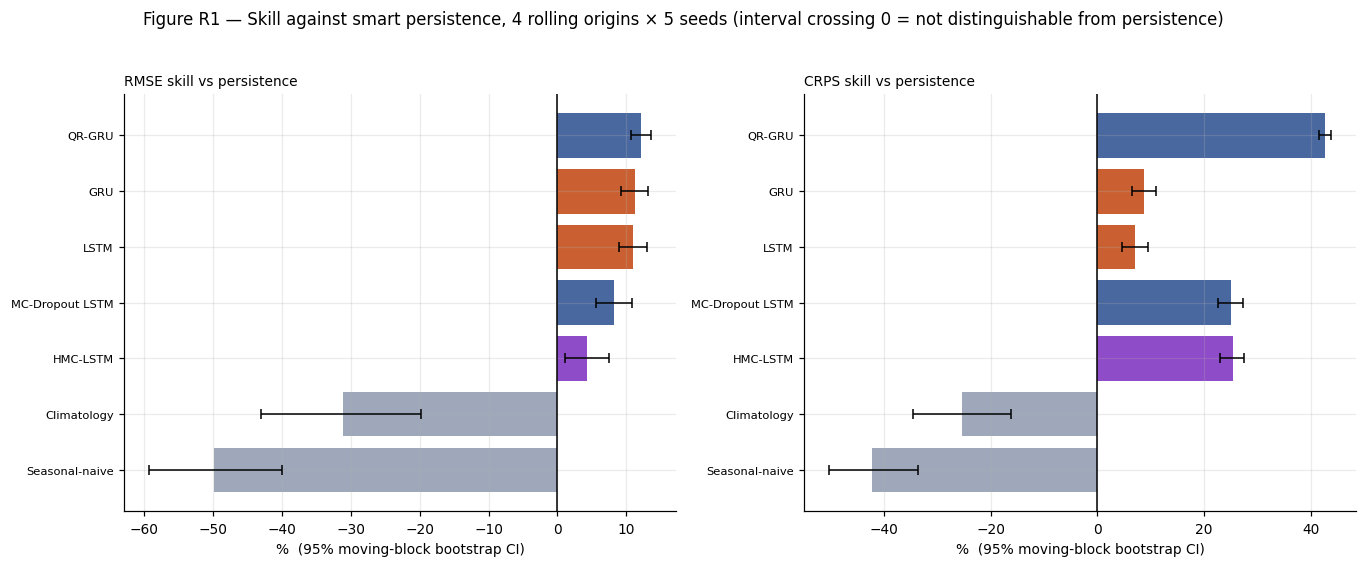

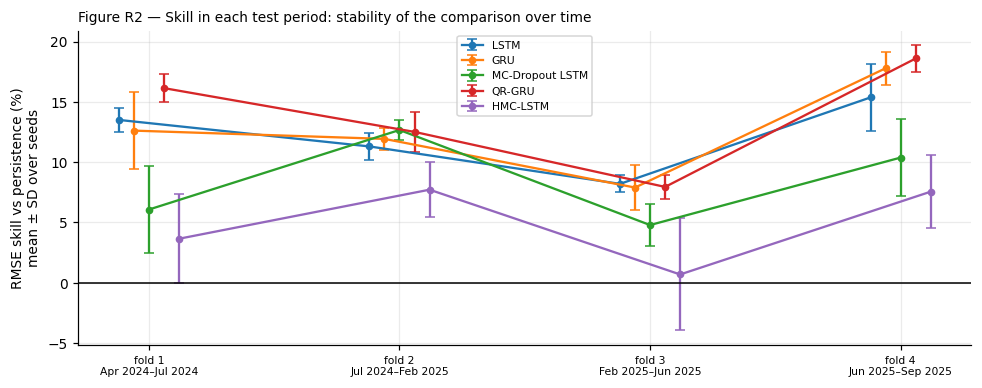

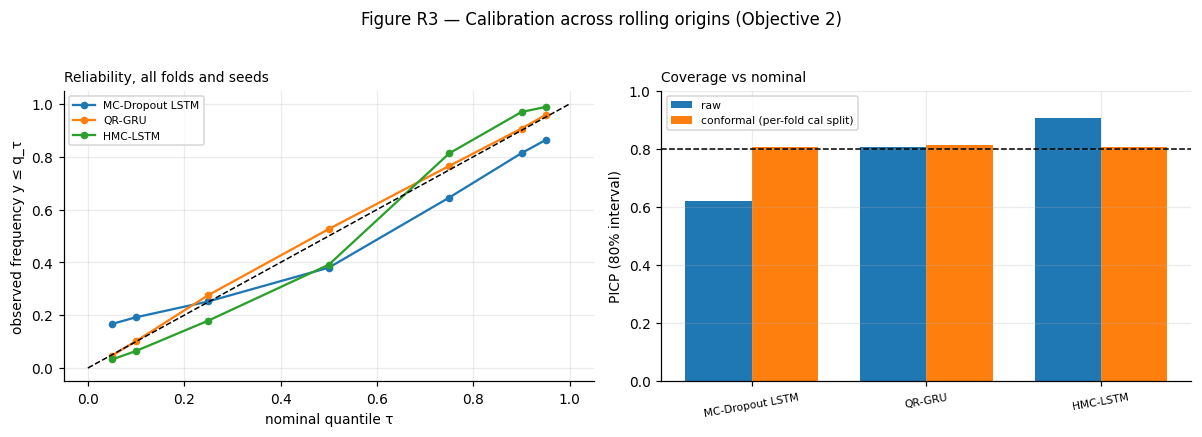

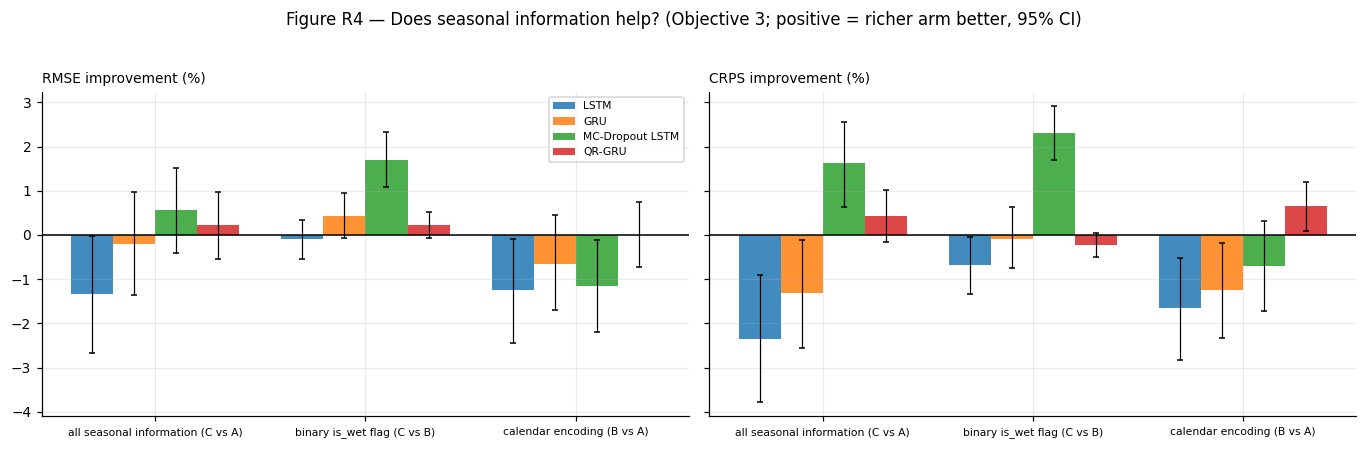

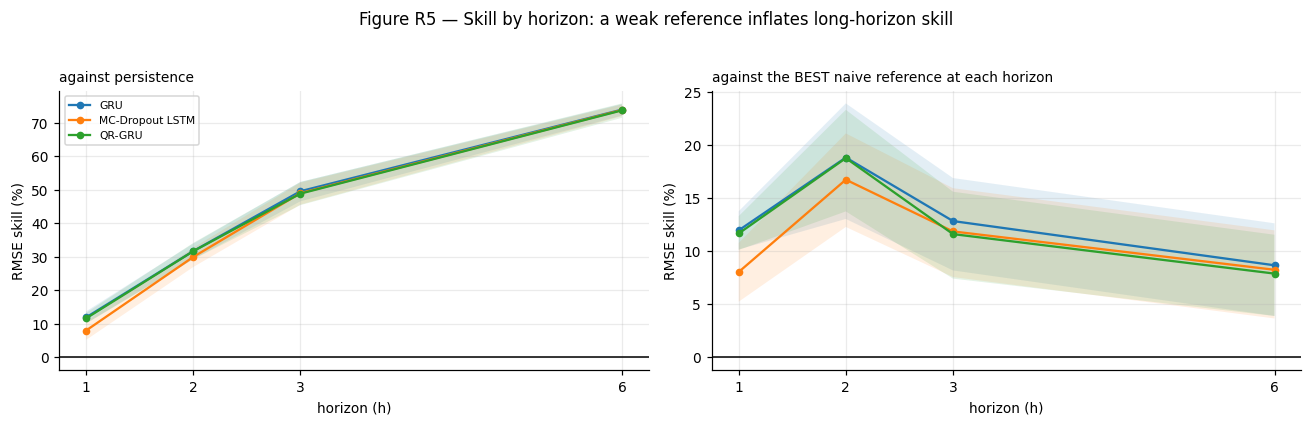

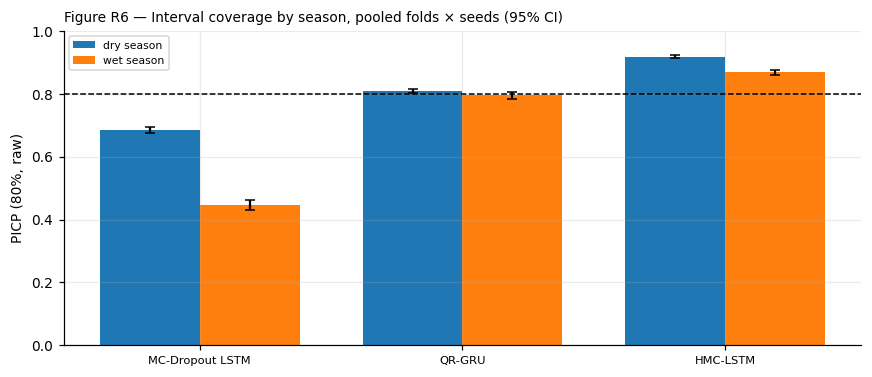

In [ ]:
# ============================== R6 — figures for the headline evidence ==============================
_fam_col = {"naive": "#8d99ae", "deterministic": "#c1440e", "probabilistic": "#2a4d8f",
            "probabilistic (extension)": "#7b2cbf"}

# Figure R1: skill with CIs (RMSE and CRPS)
L_ = R_LEADER[R_LEADER.model != "Persistence"].sort_values("skill_RMSE_%")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 0.45 * len(L_) + 1.8))
for ax, (c, lo, hi, ttl) in zip(axes, [("skill_RMSE_%", "skill_CI_lo", "skill_CI_hi", "RMSE skill vs persistence"),
                                        ("skill_CRPS_%", "skillCRPS_CI_lo", "skillCRPS_CI_hi", "CRPS skill vs persistence")]):
    y = np.arange(len(L_))
    ax.barh(y, L_[c], color=[_fam_col.get(f, "grey") for f in L_.family], alpha=.85)
    ax.errorbar(L_[c], y, xerr=[L_[c] - L_[lo], L_[hi] - L_[c]], fmt="none", ecolor="k", capsize=3, lw=1)
    ax.axvline(0, color="k", lw=1)
    ax.set_yticks(y); ax.set_yticklabels(L_.model, fontsize=7.5)
    ax.set_xlabel("%  (95% moving-block bootstrap CI)"); ax.set_title(ttl, fontsize=9, loc="left")
fig.suptitle(f"Figure R1 — Skill against smart persistence, {len(FOLDS)} rolling origins × {len(CFG.SEEDS)} seeds "
             "(interval crossing 0 = not distinguishable from persistence)", y=1.03)
savefig(fig, "figR1_skill_ci"); plt.show()

# Figure R2: fold-by-fold skill (does the ranking hold in every period?)
fig, ax = plt.subplots(figsize=(9, 3.6))
for m in [m for m in MODEL_KINDS + EXTENSION_KINDS if m in set(RUNS.model)]:
    g = RUNS[RUNS.model == m].groupby("fold")["skill_%"]
    ax.errorbar(g.mean().index + 0.06 * (list(R_KINDS).index(m) - 2), g.mean(), yerr=g.std().fillna(0),
                fmt="-o", ms=4, capsize=3, label=m)
ax.axhline(0, color="k", lw=1)
ax.set_xticks(FOLD_TABLE.fold)
ax.set_xticklabels([f"fold {r.fold}\n{pd.Timestamp(r.test_from):%b %Y}–{pd.Timestamp(r.test_to):%b %Y}"
                    for r in FOLD_TABLE.itertuples()], fontsize=7)
ax.set_ylabel("RMSE skill vs persistence (%)\nmean ± SD over seeds"); ax.legend(fontsize=7)
ax.set_title("Figure R2 — Skill in each test period: stability of the comparison over time", fontsize=9, loc="left")
savefig(fig, "figR2_fold_skill"); plt.show()

# Figure R3: pooled reliability diagram, raw vs conformal PICP
_pk = [m for m in R_KINDS if m in PROBABILISTIC and m in set(R1.model)]
if _pk:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for m in _pk:
        g = R1[R1.model == m]
        obs = [float((g.y <= g[f"q{int(round(t*100)):02d}"]).mean()) for t in CFG.QUANTILES]
        axes[0].plot(CFG.QUANTILES, obs, "-o", ms=4, label=m)
    axes[0].plot([0, 1], [0, 1], "k--", lw=1)
    axes[0].set_xlabel("nominal quantile τ"); axes[0].set_ylabel("observed frequency y ≤ q_τ")
    axes[0].legend(fontsize=7); axes[0].set_title("Reliability, all folds and seeds", fontsize=9, loc="left")
    xs = np.arange(len(_pk)); w = .38
    P_ = R_LEADER.set_index("model").loc[_pk]
    axes[1].bar(xs - w / 2, P_.PICP80_raw, w, label="raw")
    axes[1].bar(xs + w / 2, P_.PICP80_conformal, w, label="conformal (per-fold cal split)")
    axes[1].axhline(COV, color="k", ls="--", lw=1)
    axes[1].set_xticks(xs); axes[1].set_xticklabels(_pk, fontsize=7, rotation=10); axes[1].set_ylim(0, 1)
    axes[1].set_ylabel("PICP (80% interval)"); axes[1].legend(fontsize=7)
    axes[1].set_title("Coverage vs nominal", fontsize=9, loc="left")
    fig.suptitle("Figure R3 — Calibration across rolling origins (Objective 2)", y=1.03)
    savefig(fig, "figR3_calibration"); plt.show()

# Figure R4: seasonal-conditioning effects with CIs
if len(ABLATION):
    A_ = ABLATION[(ABLATION.subset == "all")]
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), sharey=True)
    for ax, loss in zip(axes, ("SE", "CRPS")):
        a = A_[A_.loss == loss]
        cons = [c[2] for c in CONTRASTS]
        w = 0.8 / len(MODEL_KINDS)
        for i, m in enumerate(MODEL_KINDS):
            r = a[a.model == m].set_index("contrast").reindex(cons)
            x = np.arange(len(cons)) + (i - (len(MODEL_KINDS) - 1) / 2) * w
            ax.bar(x, r["improvement_%"], w, label=m, alpha=.85)
            ax.errorbar(x, r["improvement_%"], yerr=[r["improvement_%"] - r.CI_lo, r.CI_hi - r["improvement_%"]],
                        fmt="none", ecolor="k", capsize=2, lw=.8)
        ax.axhline(0, color="k", lw=1)
        ax.set_xticks(range(len(cons))); ax.set_xticklabels(cons, fontsize=7)
        ax.set_title(f"{'RMSE' if loss == 'SE' else 'CRPS'} improvement (%)", fontsize=9, loc="left")
    axes[0].legend(fontsize=7)
    fig.suptitle("Figure R4 — Does seasonal information help? (Objective 3; positive = richer arm better, 95% CI)", y=1.03)
    savefig(fig, "figR4_seasonal_ablation"); plt.show()

# Figure R5: horizon skill vs persistence and vs best naive
if len(HORIZON_R):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.7), sharey=False)
    for ax, key in zip(axes, ("vs_persistence", "vs_best_naive")):
        for m in HZ_KINDS:
            g = HORIZON_R[HORIZON_R.model == m].sort_values("horizon_h")
            if not len(g):
                continue
            ax.plot(g.horizon_h, g[f"skill_{key}_%"], "-o", ms=4, label=m)
            if f"{key}_CI_lo" in g:
                ax.fill_between(g.horizon_h, g[f"{key}_CI_lo"], g[f"{key}_CI_hi"], alpha=.12)
        ax.axhline(0, color="k", lw=1); ax.set_xlabel("horizon (h)"); ax.set_ylabel("RMSE skill (%)")
        ax.set_xticks(sorted(HORIZON_R.horizon_h.unique()))
        ax.set_title("against persistence" if key == "vs_persistence" else
                     "against the BEST naive reference at each horizon", fontsize=9, loc="left")
    axes[0].legend(fontsize=7)
    fig.suptitle("Figure R5 — Skill by horizon: a weak reference inflates long-horizon skill", y=1.03)
    savefig(fig, "figR5_horizon"); plt.show()

# Figure R6: wet vs dry coverage with CIs (the tropical signal)
if len(SUBGROUP_R) and "PICP80_raw" in SUBGROUP_R:
    s_ = SUBGROUP_R[SUBGROUP_R.subgroup.isin(["wet season", "dry season"])].dropna(subset=["PICP80_raw"])
    if len(s_):
        fig, ax = plt.subplots(figsize=(8, 3.5))
        ms_ = list(s_.model.unique()); xs = np.arange(len(ms_)); w = .38
        for i, sg in enumerate(["dry season", "wet season"]):
            r = s_[s_.subgroup == sg].set_index("model").reindex(ms_)
            ax.bar(xs + (i - .5) * w, r.PICP80_raw, w, label=sg,
                   yerr=[r.PICP80_raw - r.PICP_CI_lo, r.PICP_CI_hi - r.PICP80_raw], capsize=3)
        ax.axhline(COV, color="k", ls="--", lw=1); ax.set_ylim(0, 1)
        ax.set_xticks(xs); ax.set_xticklabels(ms_, fontsize=7.5); ax.set_ylabel("PICP (80%, raw)")
        ax.legend(fontsize=7)
        ax.set_title("Figure R6 — Interval coverage by season, pooled folds × seeds (95% CI)", fontsize=9, loc="left")
        savefig(fig, "figR6_wet_dry_coverage"); plt.show()

### Research Stage#14.3 Before vs After: A Single Test Block vs Rolling Origins

**Analysis.** The ranking from the single last-origin block (Stage 12) is compared with the ranking in each rolling fold and seed.

In [ ]:
single = RESULTS_MAIN[RESULTS_MAIN.model.isin(MODEL_KINDS)].sort_values("RMSE_Wm2")[["model", "RMSE_Wm2"]].reset_index(drop=True)
single["rank (single block, seed 42)"] = range(1, len(single) + 1)
rk = RUNS[RUNS.model.isin(MODEL_KINDS)].copy(); rk["rank"] = rk.groupby(["fold", "seed"]).RMSE.rank()
roll = rk.groupby("model").agg(mean_rank=("rank", "mean"), best_rank=("rank", "min"), worst_rank=("rank", "max"),
                               share_first_pct=("rank", lambda s: 100 * (s == 1).mean()))
cmp_rank = single.merge(roll.reset_index(), on="model")
display(cmp_rank.round(2))
fold_win = rk[rk["rank"] == 1].groupby("fold").model.agg(lambda s: s.value_counts().idxmax())
print("Most frequent winner per fold:", fold_win.to_dict())

,model,RMSE_Wm2,"rank (single block, seed 42)",mean_rank,best_rank,worst_rank,share_first_pct
0,QR-GRU,73.45,1,1.6,1.0,4.0,65.0
1,GRU,73.67,2,2.2,1.0,4.0,25.0
2,LSTM,74.04,3,2.8,1.0,4.0,5.0
3,MC-Dropout LSTM,76.22,4,3.4,1.0,4.0,5.0


Most frequent winner per fold: {1: 'QR-GRU', 2: 'QR-GRU', 3: 'GRU', 4: 'QR-GRU'}


**Interpretation.**

* If the rank range (best–worst) spans several places, or the winner differs between folds, then a single-block ranking reflects the test period as much as the models.
* Fold-level variation is the dominant source of uncertainty, which is why Stage 15 draws conclusions only from the confidence intervals of R2.

# **PART L · Results, Discussion and Research Conclusions**

> *Navigation header added for the VIVA. It covers Stages 15 and 16 below. No original cell was changed.*

---
# **Research Stage#15 — Research Findings: Research Question → Evidence → Answer**

### **15.1 Consolidated Findings (Generated From The Robust Evaluation)**

In [ ]:
# ============================== PART 14 — consolidated findings, generated from Part R ==============================
def fmt(x, n=2):
    return "n/a" if x is None or (isinstance(x, float) and not np.isfinite(x)) else f"{x:,.{n}f}"


def ci(m, a="skill_RMSE_%", lo="skill_CI_lo", hi="skill_CI_hi"):
    r = R_LEADER.set_index("model").loc[m]
    return f"{r[a]:+.1f}% [95% CI {r[lo]:+.1f}, {r[hi]:+.1f}]"


P = R_LEADER.set_index("model")
four = [m for m in MODEL_KINDS if m in P.index]
det = [m for m in four if m not in PROBABILISTIC]
prob = [m for m in four if m in PROBABILISTIC]
best_rmse = min(four, key=lambda m: P.loc[m, "RMSE_Wm2"])
best_crps = min(four, key=lambda m: P.loc[m, "CRPS_Wm2"])
best_cal = min(prob, key=lambda m: abs(P.loc[m, "PICP80_raw"] - COV)) if prob else None
beats = [m for m in four if P.loc[m, "skill_CI_lo"] > 0]
loses = [m for m in four if P.loc[m, "skill_CI_hi"] < 0]

L = []
L.append(f"PRIMARY SITE : {MODEL_SITE} — {SITES[MODEL_SITE]['climate']}; record {CFG.DARWIN_RECORD} "
         f"(decision: {DESIGN_T.set_index('decision').loc['Darwin record','value'] if DESIGN_T is not None and 'decision' in DESIGN_T and (DESIGN_T.decision=='Darwin record').any() else 'n/a'})")
L.append(f"TIMING       : clear-day diurnal lag {PRIMARY_LAG:+.1f} min (gate ±{CFG.TIMING_GATE_MIN:g})")
L.append(f"DESIGN       : t+{CFG.HORIZON} h k_t, {len(FOLDS)} rolling origins × {len(CFG.SEEDS)} seeds, "
         f"{int(FOLD_TABLE.n_test.sum()):,} test hours ({FOLD_TABLE.test_from.min():%Y-%m} to {FOLD_TABLE.test_to.max():%Y-%m})")
L.append("")
L.append("O1  ACCURACY")
for m in four:
    L.append(f"    {m:<17} RMSE {P.loc[m,'RMSE_Wm2']:7.2f} W/m²   skill vs persistence {ci(m)}   "
             f"DM: {verdict_vs(m)}")
L.append(f"    -> lowest RMSE: {best_rmse}. Models whose skill CI is entirely above 0: "
         f"{', '.join(beats) or 'none'}; entirely below 0: {', '.join(loses) or 'none'}.")
_rs = RANK_STAB
L.append(f"    -> rank stability: {_rs.index[0]} ranks first in {_rs.iloc[0].share_first:.0f}% of fold × seed runs.")
L.append("")
L.append("O2  PROBABILISTIC QUALITY AND CALIBRATION")
for m in prob + [k for k in EXTENSION_KINDS if k in P.index]:
    L.append(f"    {m:<17} CRPS {P.loc[m,'CRPS_Wm2']:6.2f}  CRPS skill {ci(m,'skill_CRPS_%','skillCRPS_CI_lo','skillCRPS_CI_hi')}  "
             f"PICP80 raw {P.loc[m,'PICP80_raw']:.3f} -> conformal {P.loc[m,'PICP80_conformal']:.3f}  "
             f"MIW {fmt(P.loc[m,'MIW_raw_Wm2'],0)} -> {fmt(P.loc[m,'MIW_conf_Wm2'],0)} W/m²")
if prob and det:
    bp, bd = min(prob, key=lambda m: P.loc[m, "RMSE_Wm2"]), min(det, key=lambda m: P.loc[m, "RMSE_Wm2"])
    diff = 100 * (P.loc[bp, "RMSE_Wm2"] - P.loc[bd, "RMSE_Wm2"]) / P.loc[bd, "RMSE_Wm2"]
    v = verdict_vs(bp, bd)
    L.append(f"    -> point-accuracy difference, best probabilistic ({bp}) vs best deterministic ({bd}): "
             f"{diff:+.1f}% RMSE; {v}. (Negative = no accuracy cost of UQ.)")
    register("o2.point_accuracy_difference_pct", round(diff, 2), f"{bp} vs {bd}; {v}")
if "HMC-LSTM" in P.index and "MC-Dropout LSTM" in P.index:
    L.append(f"    -> epistemic-only (MC-Dropout) PICP80 {P.loc['MC-Dropout LSTM','PICP80_raw']:.3f} vs "
             f"epistemic + aleatoric (HMC-LSTM) {P.loc['HMC-LSTM','PICP80_raw']:.3f}: the gap measures how much of "
             "MC-Dropout's under-coverage is missing noise variance rather than model error.")
_sg = SUBGROUP_R.set_index(["model", "subgroup"]) if len(SUBGROUP_R) else None
for m in prob:
    try:
        w_, d_ = _sg.loc[(m, "wet season")], _sg.loc[(m, "dry season")]
        sep = (w_.PICP_CI_hi < d_.PICP_CI_lo) or (d_.PICP_CI_hi < w_.PICP_CI_lo)
        L.append(f"    -> {m} coverage wet {w_.PICP80_raw:.3f} [{w_.PICP_CI_lo:.3f},{w_.PICP_CI_hi:.3f}] vs dry "
                 f"{d_.PICP80_raw:.3f} [{d_.PICP_CI_lo:.3f},{d_.PICP_CI_hi:.3f}] — "
                 f"{'intervals do not overlap' if sep else 'intervals overlap'}")
    except Exception:
        pass
L.append("")
L.append("O3  SEASONAL CONDITIONING (three-arm design) AND RAMPS")
for m in four:
    for lab in ("all seasonal information (C vs A)", "binary is_wet flag (C vs B)"):
        r = ABLATION[(ABLATION.model == m) & (ABLATION.contrast == lab) & (ABLATION.subset == "all") & (ABLATION.loss == "SE")]
        if len(r):
            r = r.iloc[0]
            L.append(f"    {m:<17} {lab:<36} {r['improvement_%']:+6.2f}% [{r.CI_lo:+.2f}, {r.CI_hi:+.2f}]  -> {r.verdict}")
for m in four:
    k = f"r5.{m}.ramp_RMSE_penalty_%"
    if k in RESULTS_REGISTRY:
        L.append(f"    {m:<17} ramp-hour RMSE vs non-ramp: {RESULTS_REGISTRY[k]['value']:+.1f}%")
L.append("")
L.append("O4  DECISION SUPPORT")
if len(DEC_R):
    for _, r in DEC_SUM.iterrows():
        L.append(f"    {r.model:<17} {r.intervals:<10} threshold X defined in {r.share_with_threshold_pct:.0f}% of runs; "
                 f"median X {fmt(r.X_median_Wm2,0)} W/m² (range {fmt(r.X_min,0)}–{fmt(r.X_max,0)})")
if "RES_SUM" in globals():
    for _, r in RES_SUM.iterrows():
        L.append(f"    {r.model:<17} {r.strategy:<15} reserve vs frontier at equal reliability: median "
                 f"{r['median']:+.1f}% (cheaper in {r['share_cheaper_%']:.0f}% of runs)")
L.append("")
L.append("PROXY (O1 secondary, Alice Springs, matched)")
if PROXY_SUMMARY is not None and len(PROXY_DELTA):
    L.append(f"    irradiance-minus-PV skill: mean {PROXY_DELTA.delta_skill_pp.mean():+.2f} pp; "
             f"{int(PROXY_DELTA.delta_exceeds_2sd.sum())}/{len(PROXY_DELTA)} architectures beyond 2 seed-SD")
L.append("")
L.append("O8  CROSS-CLIMATE (zero-shot, last-origin models; secondary sites excluded)")
zs = CROSS[(CROSS.transfer == "zero-shot") & ~CROSS.site.isin(SECONDARY_SITES)]
for s in zs.site.unique():
    sub = zs[zs.site == s].set_index("model")
    pers = CROSS[(CROSS.site == s) & (CROSS.model == "Persistence (local)")]["nRMSE_%"]
    best = sub["nRMSE_%"].idxmin()
    q = sub.loc["QR-GRU"] if "QR-GRU" in sub.index else None
    L.append(f"    {s:<11} best {best} nRMSE {sub.loc[best,'nRMSE_%']:.2f}% vs local persistence "
             f"{fmt(float(pers.iloc[0]) if len(pers) else np.nan)}%"
             + (f"; QR-GRU PICP80 {q.PICP_80:.3f}" + (f" (conformal {q.PICP_80_conformal:.3f})" if 'PICP_80_conformal' in q else "")
                if q is not None else ""))
L.append("")
L.append("ROBUSTNESS")
for _, r in ROB_INTERP.iterrows():
    L.append(f"    {r.model:<17} skill {r['skill_all_targets_%']:+.1f}% -> {r['skill_excl_interpolated_%']:+.1f}% "
             "excluding interpolated targets")
if EXOG is not None:
    for _, r in EXOG[EXOG.loss == "SE"].iterrows():
        L.append(f"    {r.model:<17} on-site met: {r['improvement_%']:+.2f}% RMSE [{r.CI_lo:+.2f}, {r.CI_hi:+.2f}]")
L.append("")
for s in SITES_OK:
    L.append(f"SOURCE {s:<13}: {SOURCE_USED.get(s, '?')}")
if len(FAILED):
    L.append(f"EXCLUDED     : {', '.join(f'{r.site} ({r.issues})' for _, r in FAILED.iterrows())}")

print("=" * 118); print("CONSOLIDATED FINDINGS (every number generated from this run)"); print("=" * 118)
print("\n".join(L))
SUMMARY = pd.DataFrame({"finding": L})
save_table(SUMMARY, "consolidated_findings")

CONSOLIDATED FINDINGS (every number generated from this run)
PRIMARY SITE : DARWIN — Tropical savanna (Köppen Aw); record EXTENDED (decision: EXTENDED)
TIMING       : clear-day diurnal lag -1.3 min (gate ±10)
DESIGN       : t+1 h k_t, 4 rolling origins × 5 seeds, 4,887 test hours (2024-04 to 2025-09)

O1  ACCURACY
    LSTM              RMSE   88.33 W/m²   skill vs persistence +11.0% [95% CI +9.0, +13.0]   DM: LSTM lower (Holm p<0.001)
    GRU               RMSE   88.01 W/m²   skill vs persistence +11.3% [95% CI +9.3, +13.2]   DM: GRU lower (Holm p<0.001)
    MC-Dropout LSTM   RMSE   91.04 W/m²   skill vs persistence +8.2% [95% CI +5.6, +10.8]   DM: MC-Dropout LSTM lower (Holm p<0.001)
    QR-GRU            RMSE   87.24 W/m²   skill vs persistence +12.1% [95% CI +10.6, +13.6]   DM: QR-GRU lower (Holm p<0.001)
    -> lowest RMSE: QR-GRU. Models whose skill CI is entirely above 0: LSTM, GRU, MC-Dropout LSTM, QR-GRU; entirely below 0: none.
    -> rank stability: QR-GRU ranks first in 65% 

PosixPath('/content/drive/MyDrive/_tropicalpv_artifacts/consolidated_findings.parquet')

### **Research Stage#15.2 Research Question Synthesis**

Every row is generated from this run's results. Wording follows the evidence: a difference is called a finding only if it passes the Stage 14 criterion.

In [ ]:
P_ = R_LEADER.set_index("model")
def sk(m): return f"{P_.loc[m,'skill_RMSE_%']:+.1f}% [{P_.loc[m,'skill_CI_lo']:+.1f}, {P_.loc[m,'skill_CI_hi']:+.1f}]"
beats = [m for m in four if P_.loc[m, "skill_CI_lo"] > 0]
tied = [m for m in four if m != best_rmse and not R_DM[(R_DM.loss == "SE") & (((R_DM.model_A == m) & (R_DM.model_B == best_rmse)) |
        ((R_DM.model_B == m) & (R_DM.model_A == best_rmse)))]["significant_holm_5%"].any()]
cal_err = {m: abs(P_.loc[m, "PICP80_raw"] - COV) for m in prob}
rows = []
rows.append(("RQ / O1 — accuracy", "R2 skill vs persistence, HAC-DM (Fig R1–R2)",
             "; ".join(f"{m} {sk(m)}" for m in four),
             f"Lowest RMSE: {best_rmse}; statistically tied with it: {', '.join(tied) or 'none'}",
             ("No architecture beats smart persistence with confidence (every 95% CI includes or lies below 0)"
              if not beats else
              f"{best_rmse} has the lowest RMSE but is statistically tied with {', '.join(tied)}; "
              f"architectures beating persistence with confidence: {', '.join(beats)}" if tied else
              f"{best_rmse} is the most accurate and beats persistence with confidence")))
rows.append(("RQ / O2 — calibration", "R2/R5 PICP raw and conformal, wet vs dry (Fig R3, R6)",
             "; ".join(f"{m} PICP80 {P_.loc[m,'PICP80_raw']:.3f}" for m in prob),
             f"Closest to nominal 0.80 without correction: {min(cal_err, key=cal_err.get)}",
             f"{min(cal_err, key=cal_err.get)} is the best-calibrated architecture"))
if "o2.point_accuracy_difference_pct" in RESULTS_REGISTRY:
    r = RESULTS_REGISTRY["o2.point_accuracy_difference_pct"]
    rows.append(("O2 — accuracy cost of UQ", "best probabilistic vs best deterministic, HAC-DM", f"{r['value']:+.2f}% RMSE", r["note"],
                 "No accuracy cost" if "not distinguishable" in r["note"] or r["value"] <= 0 else "A measurable accuracy cost"))
flag = ABLATION[(ABLATION.contrast.str.startswith("binary")) & (ABLATION.subset == "all") & (ABLATION.loss == "SE")]
rows.append(("O3 — wet/dry conditioning", "R3 three-arm test (Fig R4)",
             "; ".join(f"{r.model}: {r['improvement_%']:+.2f}% ({r.verdict})" for _, r in flag.iterrows()),
             f"{int((flag.verdict == 'not distinguishable').sum())} of {len(flag)} architectures show no distinguishable effect",
             "Season is largely carried by recent k_t history"))
ramp = {m: RESULTS_REGISTRY.get(f"r5.{m}.ramp_RMSE_penalty_%", {}).get("value") for m in four}
rows.append(("O3 — ramps", "R5(c) ramp vs non-ramp", "; ".join(f"{m} {v:+.0f}%" for m, v in ramp.items() if v is not None),
             "Ramp hours carry the largest errors", "Ramps are where forecasts, and intervals, fail"))
if len(DEC_R):
    dq = DEC_SUM[(DEC_SUM.intervals == "conformal")]
    rows.append(("O4 — decision threshold", "R5(e) across folds × seeds (Fig 15)",
                 "; ".join(f"{r.model}: X defined in {r.share_with_threshold_pct:.0f}% of runs" for _, r in dq.iterrows()),
                 "Stability of X across periods", "Stable rule" if (dq.share_with_threshold_pct >= 80).any() else "No stable width threshold"))
if PROXY_SUMMARY is not None and len(PROXY_DELTA):
    rows.append(("O1b — irradiance as PV proxy", "Matched clear-sky indices (13.4)",
                 f"mean Δskill {PROXY_DELTA.delta_skill_pp.mean():+.2f} pp", f"{int(PROXY_DELTA.delta_exceeds_2sd.sum())}/{len(PROXY_DELTA)} beyond 2 seed-SD",
                 "PV harder than irradiance" if PROXY_DELTA.delta_skill_pp.mean() > 0 else "PV not harder than point irradiance (arid site)"))
zs_ = CROSS[(CROSS.transfer == "zero-shot") & ~CROSS.site.isin(SECONDARY_SITES) & (CROSS.model == "QR-GRU")]
rows.append(("O5 — cross-climate transfer", "Zero-shot (13.5)", f"{zs_.site.nunique()} sites; PICP80 {zs_.PICP_80.min():.2f}–{zs_.PICP_80.max():.2f}",
             "Transfer loss vs domain shift (13.5)", "Calibration must be re-estimated per site"))
RQ_TABLE = pd.DataFrame(rows, columns=["Question", "Evidence generated", "Result", "Analytical finding", "Answer"])
with pd.option_context("display.max_colwidth", 120):
    display(RQ_TABLE)
save_table(RQ_TABLE, "rq_synthesis")

,Question,Evidence generated,Result,Analytical finding,Answer
0,RQ / O1 — accuracy,"R2 skill vs persistence, HAC-DM (Fig R1–R2)","LSTM +11.0% [+9.0, +13.0]; GRU +11.3% [+9.3, +13.2]; MC-Dropout LSTM +8.2% [+5.6, +10.8]; QR-GRU +12.1% [+10.6, +13.6]","Lowest RMSE: QR-GRU; statistically tied with it: LSTM, GRU","QR-GRU has the lowest RMSE but is statistically tied with LSTM, GRU; architectures beating persistence with confiden..."
1,RQ / O2 — calibration,"R2/R5 PICP raw and conformal, wet vs dry (Fig R3, R6)",MC-Dropout LSTM PICP80 0.621; QR-GRU PICP80 0.805,Closest to nominal 0.80 without correction: QR-GRU,QR-GRU is the best-calibrated architecture
2,O2 — accuracy cost of UQ,"best probabilistic vs best deterministic, HAC-DM",-0.88% RMSE,QR-GRU vs GRU; not distinguishable (Holm p=0.267),No accuracy cost
3,O3 — wet/dry conditioning,R3 three-arm test (Fig R4),LSTM: -0.09% (not distinguishable); GRU: +0.44% (not distinguishable); MC-Dropout LSTM: +1.70% (helps); QR-GRU: +0.2...,3 of 4 architectures show no distinguishable effect,Season is largely carried by recent k_t history
4,O3 — ramps,R5(c) ramp vs non-ramp,LSTM +143%; GRU +148%; MC-Dropout LSTM +121%; QR-GRU +173%,Ramp hours carry the largest errors,"Ramps are where forecasts, and intervals, fail"
5,O4 — decision threshold,R5(e) across folds × seeds (Fig 15),HMC-LSTM: X defined in 35% of runs; MC-Dropout LSTM: X defined in 0% of runs; QR-GRU: X defined in 50% of runs,Stability of X across periods,No stable width threshold
6,O1b — irradiance as PV proxy,Matched clear-sky indices (13.4),mean Δskill -8.02 pp,3/4 beyond 2 seed-SD,PV not harder than point irradiance (arid site)
7,O5 — cross-climate transfer,Zero-shot (13.5),8 sites; PICP80 0.26–0.89,Transfer loss vs domain shift (13.5),Calibration must be re-estimated per site


PosixPath('/content/drive/MyDrive/_tropicalpv_artifacts/rq_synthesis.parquet')

### **Research Stage#15.3 How Data-Handling Decisions Propagated Into The Findings**

This is the central methodological lesson. The table below brings together, from this run, how each data-quality decision changed what the analysis would have concluded.

In [ ]:
prop = []
pr = INV_SUMMARY.reset_index()
for v in ("initial", "partial", "corrected"):
    q = pr[(pr.version == v) & (pr.model == "QR-GRU")]
    if len(q):
        prop.append(("Timestamp reading", {"initial": "Local column, sun @HH:00", "partial": "Local column, sun @bin centre",
                                           "corrected": "UTC + 9:30, sun @bin centre"}[v],
                     f"QR-GRU skill vs persistence {q.skill.iloc[0]:+.1f}% (controlled, Stage 5)"))
for v, col in (("initial", "initial"), ("corrected", "corrected")):
    pass
prop.append(("Clear-sky timing at the primary site", "production gate", f"clear-day lag {PRIMARY_LAG:+.1f} min"))
if "dm.pairs_significant_only_without_correction" in RESULTS_REGISTRY:
    prop.append(("Significance test", "no correction vs Newey–West",
                 f"{RESULTS_REGISTRY['dm.pairs_significant_only_without_correction']['value']} pair(s) significant only without correction"))
prop.append(("Seasonal ablation", "remove is_wet only", f"is_wet recoverable from doy with accuracy {acc:.3f}"))
if "proxy.initial_target_smart_vs_plain_pct" in RESULTS_REGISTRY:
    prop.append(("Proxy target", "PV/capacity", f"plain persistence handicapped by {RESULTS_REGISTRY['proxy.initial_target_smart_vs_plain_pct']['value']:.1f}%"))
prop.append(("Calibration split", "validation vs calibration", "see 12.2"))
display(pd.DataFrame(prop, columns=["decision", "state", "observed consequence (this run)"]))

,decision,state,observed consequence (this run)
0,Timestamp reading,"Local column, sun @HH:00",QR-GRU skill vs persistence +16.6% (controlled...
1,Timestamp reading,"Local column, sun @bin centre","QR-GRU skill vs persistence -8.3% (controlled,..."
2,Timestamp reading,"UTC + 9:30, sun @bin centre",QR-GRU skill vs persistence -36.0% (controlled...
3,Clear-sky timing at the primary site,production gate,clear-day lag -1.3 min
4,Significance test,no correction vs Newey–West,1 pair(s) significant only without correction
5,Seasonal ablation,remove is_wet only,is_wet recoverable from doy with accuracy 0.999
6,Proxy target,PV/capacity,plain persistence handicapped by 47.7%
7,Calibration split,validation vs calibration,see 12.2


---
# **Research Stage#16 — Research Gap, Contribution, Limitations and Conclusions**

### **Research Stage#16.1 How The Analysis Addresses The Research Gap**

| Gap | Addressed by | Evidence in this notebook |
|---|---|---|
| Methodological: deterministic vs UQ under one protocol with proper scores | Stages 10–14 | R1–R2 leaderboard with CIs; CRPS, PICP, Winkler; HAC-DM |
| Contextual: tropical wet/dry regimes | Stages 8, 13, 14 | wet vs dry coverage with CIs; valid three-arm seasonal test; ramp analysis |
| Empirical: the irradiance-as-PV proxy | Stage 13.3–13.4 | like-for-like matched test |
| Practical: operating rules | Stage 13.7–13.8, R5(e) | threshold X across folds; reserve at equal reliability |

**Methodological contribution.** The temporal-integrity investigation (Stage 5) shows, with physical evidence, that the local timestamp column of a widely used public dataset is not the site's local time, and that the correction changes the modelling results. The robust-evaluation stage shows that single-block rankings and uncorrected significance tests can mislead.

### **Research Stage#16.2 Objective Achievement, Limitations and Exports**

In [ ]:
# ============================== PART 15 — objective matrix, limitations, exports ==============================
# ---- 15.1 Objective Achievement Matrix (generated) -------------------------------------------------
# "Achieved" means the objective's QUESTION is answered with adequate evidence — including a negative
# answer. It does not mean the hoped-for result occurred.
def _status(cond_answered, cond_partial=False):
    return "Achieved (answered)" if cond_answered else ("Partially" if cond_partial else "Not achieved")


_o1 = len(four) == 4 and np.isfinite(P.loc[four, "skill_CI_lo"]).all()
_o2 = len(prob) >= 2 and np.isfinite(P.loc[prob, "PICP80_conformal"]).all()
_o3 = len(ABLATION) > 0 and (ABLATION.subset == "all").any()
_o4_def = len(DEC_R) and DEC_R[DEC_R.intervals == "conformal"].X_Wm2.notna().mean() >= 0.5
_o4 = len(DEC_R) > 0
_px = PROXY_SUMMARY is not None and len(PROXY_DELTA) > 0
_o8 = len(zs.site.unique()) >= 3
_sg_ok = "SINGAPORE" in set(zs.site) and not SITES["SINGAPORE"].get("short_record", False)
OAM = pd.DataFrame([
    ("O1 Deterministic vs probabilistic accuracy; skill vs smart persistence", "Part R1-R2 (Fig R1, R2)",
     f"Best RMSE {best_rmse}; CI>0 vs persistence: {', '.join(beats) or 'none'}", _status(_o1)),
    ("O1b Proxy delta at Alice (matched)", "Part 11 (Fig 20)",
     f"mean Δskill {PROXY_DELTA.delta_skill_pp.mean():+.2f} pp" if _px else "not run", _status(_px)),
    ("O2 CRPS/pinball/PICP/MIW; UQ-accuracy trade-off under wet-season variability",
     "Part R2, R5(b) (Fig R3, R6)", f"best CRPS {best_crps}; best calibrated (raw) {best_cal}", _status(_o2)),
    ("O3 Seasonal conditioning; ramp subgroup (elev > 15°)", "Part R3, R5(c) (Fig R4)",
     "; ".join(sorted(set(ABLATION[(ABLATION.subset == 'all') & (ABLATION.loss == 'SE')].verdict))) if _o3 else "n/a",
     _status(_o3)),
    ("O4 Decision thresholds (PICP nominal, MIW ≤ X)", "Part 13, R5(e) (Fig 15, 22)",
     "X defined in most conformal runs" if _o4_def else "X not defined in most runs (negative result)",
     _status(_o4)),
    ("PDM O8 Cross-climate validation", "Part 12 (Fig 14)",
     f"{len(zs.site.unique())} zero-shot sites; equatorial arm {'usable' if _sg_ok else 'SHORT/absent — no equatorial claim'}",
     _status(_o8 and _sg_ok, _o8)),
    ("PDM O6 Monsoon-phase conditioning (Singapore)", "—",
     "Singapore arm is zero-shot only; no Singapore-trained conditioning experiment", "Not achieved"),
], columns=["Objective", "Method / where", "Evidence (this run)", "Status"])
print("OBJECTIVE ACHIEVEMENT MATRIX (generated)")
with pd.option_context("display.max_colwidth", 90, "display.width", 250):
    print(OAM.to_string(index=False))
save_table(OAM, "objective_achievement_matrix")

# ---- 15.2 Limitations, generated from this run's facts ----------------------------------------------
LIM = []
LIM.append(f"Single primary site and period: all architecture conclusions are for {MODEL_SITE} "
           f"({FOLD_TABLE.test_from.min():%Y-%m} to {FOLD_TABLE.test_to.max():%Y-%m}); generalisation is examined "
           "only zero-shot.")
LIM.append("Irradiance, not power, is forecast at Darwin; the proxy cost is measured at an ARID site and is a "
           "lower bound for the convective tropics.")
LIM.append(f"Hourly resolution (Dataset Assessment E2 not run): sub-hourly ramp variance is averaged out; ramp "
           "results describe hourly k_t changes only.")
_cov_met = RESULTS_REGISTRY.get("r5.darwin_met_joint_daylight_coverage", {}).get("value", np.nan)
LIM.append(f"Darwin on-site meteorology covers {100*_cov_met:.0f}% of daylight hours jointly; the transfer model is "
           "endogenous by design and the value of meteorology is tested only at Darwin (R5d).")
if not _sg_ok:
    LIM.append(f"Equatorial evidence is insufficient: Singapore source '{SOURCE_USED.get('SINGAPORE','none')}' "
               "is short or absent. No claim about equatorial (Af) behaviour is made from it.")
else:
    LIM.append(f"Singapore is satellite-derived ({SOURCE_USED.get('SINGAPORE')}) and NOT ground-validated; "
               "its errors include retrieval error (Dataset Assessment E6 not run).")
if "ESMAP" in SITES and "ESMAP" not in SITES_OK:
    _loaded = "ESMAP" in set(RAW["site"])
    LIM.append("ESMAP Gan (equatorial ground anchor) " + (
        "loaded but FAILED validation in this run (see Part 3A); no equatorial ground evidence is used."
        if _loaded else "was not available in this run; no equatorial ground evidence is used."))
LIM.append(f"Interpolated targets: {RESULTS_REGISTRY.get('leakage.test_targets_interpolated_pct',{}).get('value',np.nan):.1f}% "
           "of last-origin test targets are short-gap interpolations that use the value after the gap; R5(a) "
           "reports results with them excluded.")
LIM.append("CRPS for QR-GRU is integrated over a 0.05–0.95 quantile grid; tail mass outside it is not scored. "
           "MC-Dropout is additionally scored on the same grid (CRPS_q) for a like-for-like comparison.")
LIM.append("Conformal correction assumes exchangeability between the calibration split and test period; "
           "seasonal non-stationarity violates it approximately (over- or under-correction is visible in R2).")
LIM.append("Timing depends on the logger clocks: gate statistic "
           f"{PRIMARY_LAG:+.1f} min at {MODEL_SITE}; non-primary sources with undocumented conventions were "
           f"aligned empirically ({0 if ALIGN_T is None or '_empty' in ALIGN_T else len(ALIGN_T)} alignment record(s), Part 3.2).")
LIM.append("Tuning is equal-budget, not exhaustive (one seed per configuration, fold-1 validation).")
LIM.append("Transformer/TCN/BiLSTM (suggested by the Dataset Assessment) are out of the approved scope.")
print("\nLIMITATIONS (generated from this run)")
for i, l in enumerate(LIM, 1):
    print(textwrap.fill(f"{i:>2}. {l}", 110, subsequent_indent="    "))
save_table(pd.DataFrame({"limitation": LIM}), "limitations")

# ---- 15.3 Exports: workbook, registry JSON, figure index ------------------------------------------------
bundle = {"design_log": DESIGN_T, "tz_check": TZ_CHECK_T, "align_log": ALIGN_T,
          "audit_manifest": AUDIT.drop(columns=["_paths"]), "data_validation": VALIDATION.astype(str),
          "leakage": LEAKAGE_DIAG, "feature_screen": FEATURE_SCREEN, "domain_shift": DOMAIN_SHIFT,
          "tuning": TUNING, "tuned": TUNED_TABLE, "folds": FOLD_TABLE.astype(str),
          "R_leaderboard": R_LEADER, "R_runs": RUNS, "R_dm": R_DM, "R_rank": RANK_STAB.reset_index(),
          "R3_ablation": ABLATION, "R4_horizon": HORIZON_R, "R5_interp": ROB_INTERP, "R5_subgroups": SUBGROUP_R,
          "last_origin_main": RESULTS_MAIN, "calibration_conformal": CALIB, "cross_climate": CROSS,
          "objective_matrix": OAM, "limitations": pd.DataFrame({"limitation": LIM}),
          "findings": SUMMARY}
for nm, obj in (("proxy_summary", PROXY_SUMMARY), ("R5_exogenous", EXOG),
                ("R5_decision", globals().get("DEC_SUM")), ("R5_reserve", globals().get("RES_SUM"))):
    if obj is not None:
        bundle[nm] = obj
xl = ART / "TropicalPV_v7_results.xlsx"
try:
    with pd.ExcelWriter(xl) as w:
        for k, v in bundle.items():
            if v is not None:
                v.to_excel(w, sheet_name=k[:31], index=False)
    log(f"results workbook written: {xl}", "ok")
except Exception as e:
    for k, v in bundle.items():
        if v is not None:
            v.to_csv(ART / f"v7_{k}.csv", index=False)
    log(f"Excel unavailable ({e}); wrote CSVs", "warn")

FIG_INDEX = pd.DataFrame([{"file": p.name, "title_prefix": p.stem.split("_")[0]}
                          for p in sorted(FIGDIR.glob("*.png"))])
save_table(FIG_INDEX, "figure_index")
register("run.mode", CFG.MODE); register("run.data_fingerprint", DATA_FP)
register("run.wall_clock_s", round(time.time() - _T0))
with open(ART / "results_registry.json", "w") as f:
    json.dump(RESULTS_REGISTRY, f, indent=2, default=str)
log(f"results registry: {len(RESULTS_REGISTRY)} entries -> {ART / 'results_registry.json'}", "ok")

print(textwrap.dedent(f"""
    RUN COMPLETE
    ------------------------------------------------------------------
    Mode            : {CFG.MODE}
    Primary site    : {MODEL_SITE}   timing gate {'PASSED' if abs(PRIMARY_LAG) <= CFG.TIMING_GATE_MIN else 'NOT PASSED'}
    Protocol        : {len(FOLDS)} folds × {len(CFG.SEEDS)} seeds; {len(R_KINDS)} models + 3 naive references
    Figures         : {len(FIG_INDEX)}   Workbook: {xl.name}   Registry: results_registry.json
    Wall clock      : {time.time()-_T0:.0f}s
    ------------------------------------------------------------------
    results_registry.json is the single source of numbers for the written report.
"""))

OBJECTIVE ACHIEVEMENT MATRIX (generated)
                                                                   Objective              Method / where                                                           Evidence (this run)              Status
      O1 Deterministic vs probabilistic accuracy; skill vs smart persistence     Part R1-R2 (Fig R1, R2)     Best RMSE QR-GRU; CI>0 vs persistence: LSTM, GRU, MC-Dropout LSTM, QR-GRU Achieved (answered)
                                          O1b Proxy delta at Alice (matched)            Part 11 (Fig 20)                                                          mean Δskill -8.02 pp Achieved (answered)
O2 CRPS/pinball/PICP/MIW; UQ-accuracy trade-off under wet-season variability Part R2, R5(b) (Fig R3, R6)                                best CRPS QR-GRU; best calibrated (raw) QR-GRU Achieved (answered)
                        O3 Seasonal conditioning; ramp subgroup (elev > 15°)     Part R3, R5(c) (Fig R4)                                           

### **Research Stage#16.3 Final conclusions**

In [ ]:
print("FINAL CONCLUSIONS (generated from this run)")
print("=" * 100)
for _, r in RQ_TABLE.iterrows():
    print(textwrap.fill(f"• {r['Question']}: {r['Answer']}. Evidence — {r['Result']}.", 100, subsequent_indent="  "))
print(textwrap.fill(
    f"• Data integrity: the primary site's timing was verified against the sun (clear-day lag {PRIMARY_LAG:+.1f} min) "
    "after the temporal investigation in Stage 5 showed that the local timestamp column is not Darwin time and that the "
    "correction changes forecasting results.", 100, subsequent_indent="  "))
print(textwrap.fill("• Scope: one training site; irradiance rather than power at Darwin; hourly resolution; "
                    "the limitations above bound every conclusion.", 100, subsequent_indent="  "))

FINAL CONCLUSIONS (generated from this run)
• RQ / O1 — accuracy: QR-GRU has the lowest RMSE but is statistically tied with LSTM, GRU;
  architectures beating persistence with confidence: LSTM, GRU, MC-Dropout LSTM, QR-GRU. Evidence —
  LSTM +11.0% [+9.0, +13.0]; GRU +11.3% [+9.3, +13.2]; MC-Dropout LSTM +8.2% [+5.6, +10.8]; QR-GRU
  +12.1% [+10.6, +13.6].
• RQ / O2 — calibration: QR-GRU is the best-calibrated architecture. Evidence — MC-Dropout LSTM
  PICP80 0.621; QR-GRU PICP80 0.805.
• O2 — accuracy cost of UQ: No accuracy cost. Evidence — -0.88% RMSE.
• O3 — wet/dry conditioning: Season is largely carried by recent k_t history. Evidence — LSTM:
  -0.09% (not distinguishable); GRU: +0.44% (not distinguishable); MC-Dropout LSTM: +1.70% (helps);
  QR-GRU: +0.23% (not distinguishable).
• O3 — ramps: Ramps are where forecasts, and intervals, fail. Evidence — LSTM +143%; GRU +148%; MC-
  Dropout LSTM +121%; QR-GRU +173%.
• O4 — decision threshold: No stable width threshold. Evidence — HM

# **PART M · Appendix: Optional Data-Acquisition Utilities**

> *Navigation header added for the VIVA. It covers the appendix cells (disabled by default) below. No original cell was changed.*

---
## **Appendix — Optional Data-Acquisition Utilities (disabled by default)**

These cells document how the satellite and grid datasets can be downloaded. They do not run unless enabled, and the analysis above does not depend on them.

In [ ]:
# ---- A.1 Open-Meteo Singapore satellite radiation
RUN_OPENMETEO_ACQUISITION = False          # set True to download; writes into the Data_ folder

OM = dict(LATITUDE=1.3521, LONGITUDE=103.8198, TILT=10, AZIMUTH=0, TIMEZONE="GMT",
          MODEL="satellite_radiation_seamless",            # or "jma_jaxa_himawari"
          START="2024-01-01", END="2024-01-31",
          VARIABLES=["shortwave_radiation", "diffuse_radiation", "direct_radiation",
                     "direct_normal_irradiance", "global_tilted_irradiance"],
          API_URL="https://satellite-api.open-meteo.com/v1/archive",
          OUT_DIR=str(ROOT / "Data_Singapore Open-Meteo Satellite Radiation"))


def om_fetch(start, end, model, variables=None):
    """10-minute (native) data between two dates inclusive. Unchanged request logic."""
    import requests
    params = {"latitude": OM["LATITUDE"], "longitude": OM["LONGITUDE"],
              "start_date": str(start), "end_date": str(end),
              "hourly": ",".join(variables or OM["VARIABLES"]), "tilt": OM["TILT"],
              "azimuth": OM["AZIMUTH"], "models": model,
              "temporal_resolution": "native",       # without this you silently get HOURLY data
              "timezone": OM["TIMEZONE"]}
    for _ in range(3):
        r = requests.get(OM["API_URL"], params=params, timeout=120)
        if r.status_code == 429:
            time.sleep(30)
            continue
        break
    js = r.json()
    if r.status_code != 200 or js.get("error"):
        raise RuntimeError(f"API error {r.status_code}: {js.get('reason', r.text[:300])}")
    block = next((k for k in ["hourly", "minutely_10", "minutely_15"] if k in js), None)
    if block is None:
        raise RuntimeError(f"No data block in response. Keys: {list(js.keys())}")
    df = pd.DataFrame(js[block])
    df["time"] = pd.to_datetime(df["time"])
    df.insert(0, "model", model)
    return df


if RUN_OPENMETEO_ACQUISITION:
    os.makedirs(OM["OUT_DIR"], exist_ok=True)
    s0, e0 = pd.Timestamp(OM["START"]).date(), pd.Timestamp(OM["END"]).date()
    starts = pd.date_range(s0, e0, freq="MS").date.tolist()
    if not starts or starts[0] != s0:
        starts = [s0] + starts
    chunks = []
    for s_ in starts:
        e_ = min((pd.Timestamp(s_) + pd.offsets.MonthEnd(0)).date(), e0)
        try:
            df = om_fetch(s_, e_, OM["MODEL"])
            chunks.append(df)
            print(f"{s_} -> {e_}: {len(df):,} rows, {df['shortwave_radiation'].notna().mean():.0%} filled")
        except Exception as ex:
            print(f"  ! {s_} -> {e_}: {ex}")
        time.sleep(0.5)
    if chunks:
        radiation = pd.concat(chunks, ignore_index=True).rename(columns={"time": "time_utc"})
        radiation.insert(1, "time_sgt", radiation["time_utc"] + pd.Timedelta(hours=8))
        fname = f"{OM['OUT_DIR']}/singapore_{OM['MODEL']}_{OM['START']}_{OM['END']}_10min.csv"
        radiation.to_csv(fname, index=False)
        print(f"Saved {len(radiation):,} rows -> {fname}")
        print(radiation["time_utc"].diff().value_counts().head(3))
        first = radiation[radiation["time_sgt"] < radiation["time_sgt"].min() + pd.Timedelta(days=3)]
        fig, ax = plt.subplots(figsize=(15, 5))
        for v in ["shortwave_radiation", "diffuse_radiation", "direct_normal_irradiance"]:
            ax.plot(first["time_sgt"], first[v], label=v)
        ax.set_title(f"Singapore, first 3 days: {OM['MODEL']} (10-minute)")
        ax.set_ylabel("W/m²"); ax.set_xlabel("Singapore time (SGT)"); ax.legend()
        plt.tight_layout(); plt.show()
else:
    print("A.1 Open-Meteo acquisition skipped (RUN_OPENMETEO_ACQUISITION = False).")

A.1 Open-Meteo acquisition skipped (RUN_OPENMETEO_ACQUISITION = False).


In [ ]:
# ---- A.2 Open Electricity tropical solar farms
RUN_OPENELECTRICITY_ACQUISITION = False    # set True to download; needs the OE_KEY Colab secret

OE = dict(START=datetime(2025, 1, 1), END=datetime(2025, 1, 15),
          TROPIC_OF_CAPRICORN=-23.44, CHUNK_DAYS=7,
          OUT_DIR=str(ROOT / "Data_Australia Tropical_Solar_OpenElectricity"))


def _oe_get(obj, name):
    """Read a field whether the API gave us an object or a dictionary."""
    if obj is None:
        return None
    if isinstance(obj, dict):
        return obj.get(name)
    return getattr(obj, name, None)


def _oe_rows(response, code):
    out = []
    for ts in response.data:
        for res in ts.results:
            unit_code = _oe_get(_oe_get(res, "columns"), "unit_code") or _oe_get(res, "name")
            for dp in res.data:
                t, v = (dp[0], dp[1]) if isinstance(dp, (list, tuple)) else \
                    (_oe_get(dp, "timestamp"), _oe_get(dp, "value"))
                out.append({"facility_code": code, "unit_code": unit_code, "timestamp": t,
                            "metric": _oe_get(ts, "metric"), "value": v, "unit": _oe_get(ts, "unit")})
    return out


if RUN_OPENELECTRICITY_ACQUISITION:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "openelectricity[analysis]",
                    "nest_asyncio"], check=True)
    import nest_asyncio
    nest_asyncio.apply()
    from openelectricity import OEClient
    from openelectricity.types import DataMetric, MarketMetric, UnitFueltechType, UnitStatusType
    try:
        from google.colab import userdata
        _key = userdata.get("OE_KEY")
    except Exception:
        from getpass import getpass
        _key = getpass("Paste your Open Electricity API key: ")
    client = OEClient(api_key=_key)
    os.makedirs(OE["OUT_DIR"], exist_ok=True)

    fac = client.get_facilities(network_id=["NEM", "WEM"], status_id=[UnitStatusType.OPERATING],
                                fueltech_id=[UnitFueltechType.SOLAR_UTILITY])
    rows = []
    for f in fac.data:
        loc = _oe_get(f, "location")
        units = _oe_get(f, "units") or []
        rows.append({"facility_code": _oe_get(f, "code"), "name": _oe_get(f, "name"),
                     "network": _oe_get(f, "network_id"), "region": _oe_get(f, "network_region"),
                     "lat": _oe_get(loc, "lat"), "lng": _oe_get(loc, "lng"),
                     "capacity_mw": sum((_oe_get(u, "capacity_registered") or _oe_get(u, "capacity_mw") or 0)
                                        for u in units)})
    all_solar = pd.DataFrame(rows)
    tropical = (all_solar[all_solar["lat"] > OE["TROPIC_OF_CAPRICORN"]]
                .sort_values("lat", ascending=False).reset_index(drop=True))
    tropical.to_csv(f"{OE['OUT_DIR']}/tropical_solar_farms.csv", index=False)
    print(f"Tropical solar farms: {len(tropical)} of {len(all_solar)}")

    gen = []
    for _, farm in tropical.iterrows():
        rows, cur = [], OE["START"]
        while cur < OE["END"]:
            nxt = min(cur + timedelta(days=OE["CHUNK_DAYS"]), OE["END"])
            try:
                resp = client.get_facility_data(network_code=farm["network"],
                                                facility_code=farm["facility_code"],
                                                metrics=[DataMetric.POWER], interval="5m",
                                                date_start=cur, date_end=nxt)
                rows.extend(_oe_rows(resp, farm["facility_code"]))
            except Exception as e:
                print(f"   ! {farm['facility_code']} {cur.date()}->{nxt.date()}: {e}")
            cur = nxt
            time.sleep(1)
        df = pd.DataFrame(rows)
        if len(df):
            df.to_csv(f"{OE['OUT_DIR']}/{farm['facility_code']}_5min.csv", index=False)
            gen.append(df)
            print(f"   {farm['facility_code']}: {len(df):,} rows")
    if gen:
        generation = pd.concat(gen, ignore_index=True)
        generation["timestamp"] = pd.to_datetime(generation["timestamp"], utc=True)
        first_farm = generation["facility_code"].iloc[0]
        sample = generation[generation.facility_code == first_farm].groupby("timestamp")["value"].sum()
        fig, ax = plt.subplots(figsize=(14, 4))
        ax.plot(sample.index, sample.values)
        ax.set_title(f"{first_farm}: 5-minute power output"); ax.set_ylabel("MW"); ax.set_xlabel("time (UTC)")
        plt.tight_layout(); plt.show()
    curt, cur = [], OE["START"]
    while cur < OE["END"]:                   # regional curtailment, to flag market-driven lows
        nxt = min(cur + timedelta(days=OE["CHUNK_DAYS"]), OE["END"])
        try:
            resp = client.get_market(network_code="NEM",
                                     metrics=[MarketMetric.CURTAILMENT_SOLAR_UTILITY, MarketMetric.PRICE],
                                     interval="5m", date_start=cur, date_end=nxt, network_region="QLD1")
            curt.extend(_oe_rows(resp, "QLD1"))
        except Exception as e:
            print(f"  ! curtailment {cur.date()}->{nxt.date()}: {e}")
        cur = nxt
        time.sleep(1)
    pd.DataFrame(curt).to_csv(f"{OE['OUT_DIR']}/QLD1_curtailment_price_5min.csv", index=False)
    print(f"Curtailment/price rows saved: {len(curt):,}")
else:
    print("A.2 Open Electricity acquisition skipped (RUN_OPENELECTRICITY_ACQUISITION = False).")

A.2 Open Electricity acquisition skipped (RUN_OPENELECTRICITY_ACQUISITION = False).


In [ ]:
# ---- A.3 NSRDB Himawari PSM v3 for Singapore  -----------------------------------------------
# The Dataset Assessment's recommended Singapore source. Endpoint and parameters follow the NSRDB
# Himawari download API; the domain moved from developer.nrel.gov to developer.nlr.gov. VERIFY the
# endpoint path and attribute names against the current NLR developer documentation before running.
RUN_NSRDB_HIMAWARI_ACQUISITION = False     # set True to download (needs NLR_KEY secret + email)

HIM = dict(URL="https://developer.nlr.gov/api/nsrdb/v2/solar/himawari-download.csv",
           LAT=1.3521, LON=103.8198, YEARS=[2016, 2017, 2018, 2019, 2020], INTERVAL=10,
           ATTRS="ghi,clearsky_ghi,air_temperature,relative_humidity,wind_speed,cloud_type,fill_flag",
           OUT_DIR=str(ROOT / "Data_Singapore NSRDB Himawari"), EMAIL="")

if RUN_NSRDB_HIMAWARI_ACQUISITION:
    import requests
    try:
        from google.colab import userdata
        _key = userdata.get("NLR_KEY")
    except Exception:
        _key = os.environ.get("NLR_KEY", "")
    if not _key or not HIM["EMAIL"]:
        raise RuntimeError("Set the NLR_KEY Colab secret and HIM['EMAIL'] first.")
    Path(HIM["OUT_DIR"]).mkdir(parents=True, exist_ok=True)
    for yr in HIM["YEARS"]:
        out = Path(HIM["OUT_DIR"]) / f"himawari_singapore_{yr}.csv"
        if out.exists():
            log(f"exists: {out.name}", "ok"); continue
        params = {"api_key": _key, "wkt": f"POINT({HIM['LON']} {HIM['LAT']})", "names": yr,
                  "interval": HIM["INTERVAL"], "attributes": HIM["ATTRS"], "utc": "true",
                  "leap_day": "true", "email": HIM["EMAIL"]}
        r = requests.get(HIM["URL"], params=params, timeout=300)
        if r.status_code != 200 or not r.text.startswith("Source"):
            raise RuntimeError(f"{yr}: HTTP {r.status_code}: {r.text[:300]}")
        out.write_text(r.text)
        log(f"saved {out.name} ({len(r.text)/1e6:.1f} MB)", "ok")
        time.sleep(2)
    log("Re-run from Part 1: the manifest row 'Himawari' will pick these files up (priority 1).", "ok")
else:
    print("A.3 skipped (RUN_NSRDB_HIMAWARI_ACQUISITION = False).")

A.3 skipped (RUN_NSRDB_HIMAWARI_ACQUISITION = False).
